In [1]:
2+2

4

# Demanda quirúrgica y costos por GRD — Reporte final

**Estado:** versión final. La población derechohabiente (sección 13.4) se calcula con los **microdatos ponderados de la ENIGH 2024**. Las secciones 18 a 23 atienden los comentarios de Héctor y desarrollan las simulaciones de la sección 10 del documento.

## Objetivo

Caracterizar la demanda de procedimientos quirúrgicos de la base *Núcleo 13* y asociarla a los costos institucionales por Grupo Relacionado por el Diagnóstico (GRD), para cuatro intervenciones seleccionadas: **cirugía de catarata, colecistectomía laparoscópica, prostatectomía radical y fractura de cadera** (sustitución total, sustitución parcial y fijación).

## Flujo general

1. **Carga** de las tablas de demanda y de costos desde PostgreSQL.
2. **Depuración y variables:** acotación temporal (2024–2026), diagnóstico y procedimiento agrupados, sexo, grupo de edad y mes.
3. **Exploración de costos** por GRD, centro de costo y factor de producción.
4. **Tabla puente CME:** identificación de cada procedimiento con un escenario clínico y un GRD, a partir de CIE-10 (diagnóstico) y CIE-9 (procedimiento).
5. **Complicaciones (CC/CCM)** para refinar el GRD asignado.
6. **Integración demanda × costos** y visualizaciones de costos.
7. **Caracterización de la demanda** mediante diagramas de Sankey.
8. **Experimento de clasificación** con un agrupador MS-DRG (`drgpy`) y **ruta alternativa** por archivos administrativos.

## Contenido

| # | Sección |
|---|---------|
| 1 | Carga de datos |
| 2 | Características de la base de demanda |
| 3 | Construcción de variables |
| 4 | Exploración de costos |
| 5 | Exploración por palabras clave |
| 6 | Tabla puente CME (versión A: diagnóstico principal + secundarios) |
| 7 | Complicaciones (CC/CCM) |
| 8 | Costos por GRD |
| 9 | Caracterización de la demanda |
| 10 | Insumos para la redacción |
| 11 | Experimento: clasificador MS-DRG |
| 12 | Ruta por archivos administrativos (versión B) |
| 13 | Proyección de costos por GRD |
| 14 | Escenarios paramétricos |
| 15 | Pirámides poblacionales y casos quirúrgicos |
| 16 | Costo quirúrgico proyectado vs. ingresos y presupuesto |
| 17 | Sensibilidad al denominador poblacional (población cotizante del SEM) |
| 18 | Comentarios y propuestas de Héctor (sección 10 del documento) |
| 19 | Afiliación voluntaria a cuota fija por grupo de edad (tipo SSFAM) |
| 20 | Afiliación subsidiada de hogares sin seguridad social (sección 10a) |
| 21 | Seguro solidario con 2 % de la masa salarial (sección 10b) |
| 22 | Escenarios de población y brecha del SEM con gasto ligado a la demanda |
| 23 | Resumen para decisión |

## Requisitos para ejecutar

- **Variables de entorno** (archivo `.env`): `PGUSER`, `PGPASWORD`, `PGHOST`, `PGPORT`, `PGDATABASE`, con acceso al esquema `db_nucleo_13`. Los nombres deben coincidir exactamente con los que se leen en la sección 1.
- **Módulo local** `utils` en la misma carpeta (el cuaderno usa `np` y `plt` sin importarlos explícitamente, por lo que se asume que provienen de `from utils import *`).
- **Archivos de Excel** en la carpeta de trabajo: `Resumen_Atenciones Qx_DES_18Ago2026.xlsx` (hoja `Datos_Completos`) y `CIE 9MC en CME.xlsx` (hoja `Hoja1`).
- **Microdatos de la ENIGH 2024** (INEGI, nueva serie) en `datos/`, junto con las otras bases: `poblacion.csv` (personas) e `ingresos.csv` (ingresos por persona y clave).
- **Paquetes:** `pandas`, `sqlalchemy`, `psycopg`, `python-dotenv`, `plotly`, `drgpy`.

## Notas de ejecución

El cuaderno se construyó de forma iterativa; conviene tener presente lo siguiente al ejecutarlo:

- **Orden.** Se ejecuta de arriba hacia abajo. Algunas celdas de exploración de la sección 7 consultan `costos_wide`, que se construye hasta la sección 8.
- **Dos versiones de la tabla puente.** Las secciones 6 y 12 construyen `df_cme` con el mismo formato de salida pero con reglas distintas (detalladas en cada sección). Al ejecutar en orden lineal, `df_cme` y `df_final` quedan definidos por la **última versión ejecutada** (sección 12).
- **Variable `engine`.** Se usa primero para la conexión a PostgreSQL (sección 1) y se reasigna en la sección 11 al motor `DRGEngine`. Para volver a leer desde la base después de la sección 11 hay que reejecutar la celda de conexión.
- **Celdas vacías.** Las celdas de código sin contenido son residuos de edición y no afectan el resultado.

In [2]:
%load_ext autoreload
%autoreload 2

# 1. Carga de datos

## 1.1 Conexión a PostgreSQL

Se cargan las credenciales desde el archivo `.env` y se construye el motor de conexión (`SQLAlchemy` + `psycopg`) a la base institucional. Ninguna credencial queda escrita en el cuaderno.

In [3]:
#Paqueterias para el motor de importación
import os
import sys
from dotenv import load_dotenv
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
import pandas as pd


load_dotenv()


True

In [4]:
#Motor de carga
url= URL.create(
    "postgresql+psycopg",
    username=os.getenv("PGUSER"),
    password=os.getenv("PGPASWORD"),
    host=os.getenv("PGHOST"),
    port=int(os.getenv("PGPORT")),
    database= os.getenv("PGDATABASE")
    )
engine= create_engine(url)

## 1.2 Tablas fuente

Se leen tres tablas del esquema `db_nucleo_13`:

| Objeto | Tabla | Contenido |
|---|---|---|
| `df` | `h_nucleo_13_v6` | **Demanda:** un registro por procedimiento quirúrgico solicitado (fechas, diagnósticos CIE-10, procedimientos CIE-9, especialidad, edad, sexo, tipo de ingreso). |
| `df_cme_cata_cole_pro` | `cme_grd_cata_cole_pro` | **Costos** por GRD y centro de costo para catarata, colecistectomía y prostatectomía. |
| `df_cme_cde` | `grd_cme_cde` | **Costos** de ortopedia (fractura de cadera) por escenario y factor de producción, en valores de 2024. |

In [5]:
# df= pd.read_sql(
#     """
#     SELECT *
#     FROM db_nucleo_13.h_nucleo_13_v6
#     LIMIT 1000

#     """,
#     engine,
# )

In [6]:
# Solo se descargan las columnas utilizadas posteriormente en el reporte.
df = pd.read_sql(
    """
    SELECT
        cve_ingreso,
        fec_solicitud,
        fec_programacion_original,
        fec_realizacion,
        des_especialidad,
        ind_sexo,
        num_edad,
        cve_proc_prin_intervencion,
        des_proc_prin_intervencion,
        cve_cie_10_principal,
        des_cie_principal,
        cve_cie_10_secundario,
        des_cie_secundario,
        des_complicacion_1,
        des_complicacion_2
    FROM db_nucleo_13.h_nucleo_13_v6
    WHERE fec_solicitud IS NOT NULL
      AND fec_solicitud >= '2024-01-01'
      AND fec_solicitud < '2027-01-01'
    """,
    engine,
)

In [7]:
df_cme_cata_cole_pro= pd.read_sql(
    """
    SELECT *
    FROM db_nucleo_13.cme_grd_cata_cole_pro
    """,
    engine,
)

In [8]:
df_cme_cde= pd.read_sql(
    """
    SELECT *
    FROM db_nucleo_13.grd_cme_cde
    """,
    engine,
)

Se importan las funciones auxiliares del módulo local `utils` y se guarda `df_original`, una copia intacta de la demanda a la que se puede volver sin releer la base de datos.

In [9]:
from utils import *
#Copia por si me equivoco
df_original=df.copy()

### Carpeta de gráficas

Cada gráfica se guarda en `CARPETA_GRAFICAS` con `guardar_grafica("nombre")` (PNG, 200 dpi) justo antes de `plt.show()`. Los diagramas de Sankey (plotly) se guardan como HTML con `guardar_plotly(fig, "nombre")`. Los nombres empiezan con el número de sección para que se ordenen igual que el cuaderno. Para no guardar nada, se cambia `GUARDAR_GRAFICAS = False`.

In [10]:
# ---------------- Carpeta para guardar las gráficas ----------------
# El cuaderno vive en la carpeta del reporte; las gráficas se guardan en CARPETA_GRAFICAS dentro de ella.
import os
import unicodedata
import matplotlib.pyplot as plt

GUARDAR_GRAFICAS = True                  # False = solo se muestran, no se guardan
CARPETA_GRAFICAS = "graficas/reporte"
os.makedirs(CARPETA_GRAFICAS, exist_ok=True)


def nombre_archivo(texto):
    # Convierte un texto en nombre de archivo: sin acentos, en minúsculas y con "_" en lugar de espacios
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode()
    limpio = ""
    for letra in texto.lower():
        if letra.isalnum():
            limpio = limpio + letra
        else:
            limpio = limpio + "_"
    while "__" in limpio:
        limpio = limpio.replace("__", "_")
    return limpio.strip("_")[:60]


def guardar_grafica(nombre):
    # Guarda la gráfica de matplotlib que se está dibujando (se llama justo antes de plt.show())
    if GUARDAR_GRAFICAS:
        ruta = os.path.join(CARPETA_GRAFICAS, nombre + ".png")
        plt.savefig(ruta, dpi=200, bbox_inches="tight")
        print("Gráfica guardada:", ruta)


def guardar_plotly(figura, nombre):
    # Guarda una figura de plotly (por ejemplo, los Sankey) como HTML interactivo
    if GUARDAR_GRAFICAS:
        ruta = os.path.join(CARPETA_GRAFICAS, nombre + ".html")
        figura.write_html(ruta)
        print("Gráfica guardada:", ruta)


print("Las gráficas se guardan en:", os.path.abspath(CARPETA_GRAFICAS))

Las gráficas se guardan en: c:\Users\juanp\OneDrive\Documentos\MXP\ITED\IMSS\ArchivosJP\graficas\reporte


# 2. Características de la base de demanda

## 2.1 Universo y fechas

Se identifican las columnas de fecha y se dimensiona el universo original.

In [11]:
#Fechas
df.filter(regex="^fec").columns

Index(['fec_solicitud', 'fec_programacion_original', 'fec_realizacion'], dtype='str')

In [12]:
print(f"Hay un total de {len(df_original):,} registros")

Hay un total de 3,202,543 registros


## 2.2 Acotación temporal

Se restablece `df` desde la copia original (lo que permite reejecutar esta sección sin recargar datos), se deriva el año de la fecha de solicitud y se cuantifican los registros sin fecha (en total y por tipo de ingreso). Después el análisis se acota a las solicitudes de **2024, 2025 y 2026**.

In [13]:
df=df_original.copy()


In [14]:
df["anio"]=df["fec_solicitud"].dt.year

# La Q de nulos no es menor y se debe reportar

In [15]:

nulos=int(df["anio"].isna().sum())
print(f"hay un total de {nulos:,} nulos")

na_anio=df.groupby("cve_ingreso")["anio"].apply(lambda x:x.isna().sum())
print(na_anio)


hay un total de 0 nulos
cve_ingreso
Hospital       0
Ninguno        0
Otra unidad    0
Programado     0
Quirófano      0
Tococirugía    0
Urgencias      0
Urgente        0
Name: anio, dtype: int64


In [16]:
#Acotar tiempo por el momento
df=df.loc[df["fec_solicitud"].dt.year.isin([2024,2025,2026])].copy()


Se reporta el tamaño de la base acotada, cuántos registros se descartan y su origen (fecha de solicitud nula o año 2023), y la distribución de registros por año.

In [17]:
#Registros
#df["fec_solicitud"].agg(["min","max"])

n_registros=len(df)
print(f"Hay un total de {n_registros:,} registros")
print(f"Con el acote de tiempo se píerden {(n_registros- len(df_original))*-1:,} registros, de los cuales {nulos:,} son nulos y {(n_registros- len(df_original))*-1-nulos:,} son de 2023")
registros_anio= (df["anio"]
                 .value_counts()
                 .sort_index()
                 .rename_axis("anio")
                 .reset_index(name="n_registros"))
print("Registro por Año:")
display(registros_anio)
registros_anio["n_registros"].sum()


Hay un total de 3,202,543 registros
Con el acote de tiempo se píerden 0 registros, de los cuales 0 son nulos y 0 son de 2023
Registro por Año:


,anio,n_registros
0,2024,938910
1,2025,1116915
2,2026,1146718


np.int64(3202543)

Se mide la proporción de valores nulos en las tres fechas clave del proceso: programación original, solicitud y realización.

In [18]:
print(f" en programación original hay {df["fec_programacion_original"].isna().mean().round(4)*100:,}%   de nulos")
print(f" en  solicitud hay {df["fec_solicitud"].isna().mean().round(4)*100:,}%   de nulos")
print(f" en realizacion original hay {df["fec_realizacion"].isna().mean().round(4)*100:,}%   de nulos")


 en programación original hay 0.0%   de nulos
 en  solicitud hay 0.0%   de nulos
 en realizacion original hay 0.0%   de nulos


# 3. Construcción de variables

Se fijan los nombres de las columnas que identifican el procedimiento principal (clave y descripción) y los diagnósticos CIE-10 principal y secundario, para reutilizarlos en las secciones siguientes.

> La clave `cve_proc_prin_intervencion` es distinta de la del procedimiento *solicitado*.

In [19]:

px = "cve_proc_prin_intervencion" # diferente a solicitud
px_des="des_proc_prin_intervencion"

dx_principal = "cve_cie_10_principal"

dx_secundario = "cve_cie_10_secundario"



## 3.1 Diagnósticos y procedimientos más frecuentes

Dentro de cada especialidad se conservan los **5 diagnósticos principales** y los **5 procedimientos** más frecuentes; el resto se agrupa bajo la etiqueta *Otros procedimientos*. Se generan así las variables `cie10` y `procedimiento`, junto con `cve_procedimiento`.

In [20]:
n=5
top_10=(
    df[df["des_cie_principal"].notnull()].groupby("des_especialidad")["des_cie_principal"]
        .value_counts()
        .groupby(level=0)
        .head(n)
        .reset_index()[["des_especialidad","des_cie_principal"]])


df=df.merge(
    top_10.assign(es_top10_cie10=True),
    on=["des_especialidad","des_cie_principal"],
    how="left"
)
df["cie10"]= df[dx_principal].where(
    df["es_top10_cie10"].eq(True), "Otros procedimientos"
)

top_10=(
    df.groupby("des_especialidad")[px_des]
        .value_counts()
        .groupby(level=0)
        .head(n)
        .reset_index()[["des_especialidad",px_des]])


df=df.merge(
    top_10.assign(es_top10=True),
    on=["des_especialidad",px_des],
    how="left"
)
df["procedimiento"]= df[px_des].where(
    df["es_top10"].eq(True), "Otros procedimientos"
)

df["cve_procedimiento"]= df[px_des]





Verificación: número de especialidades con procedimientos en el ranking.

In [21]:
top_10["des_especialidad"].value_counts()

des_especialidad
Anestesiología                                 5
Angiología y Cirugía Vascular                  5
Biología de la Reproducción Humana             5
Cardiología                                    5
Cardiología Pediátrica                         5
                                              ..
Urología Ginecológica                          5
Salud Reproductiva                             3
Trasplante de células madre Hematopoyéticas    3
Clínica de Mama                                2
Cirugía Bariátrica                             1
Name: count, Length: 71, dtype: int64

## 3.2 Sexo, grupo de edad y periodo

- `sexo`: recodifica `F`/`M` a *Mujer*/*Hombre*.
- `grupo_edad`: cohortes de **`n` = 10 años** (0–9, 10–19, …) hasta la edad máxima observada.
- `mes_solicitud` y `mes_realizacion`: periodo mensual de cada fecha.

In [22]:

#Sexo

df["sexo"]=df["ind_sexo"].map({
    "F": "Mujer",
    "M": "Hombre"}
)


# Grupo edad

n=10 #Tamaño de la cohorte

edad_max=int(df["num_edad"].max())
edad_max

bins=np.arange(0, edad_max+n+1,n)
labels= [
    f"{inicio}-{inicio+n-1}"
    for inicio in bins[:-1]
]

df["grupo_edad"]=pd.cut(
    df["num_edad"],
    bins=bins,
    labels=labels,
    right=False,
    include_lowest=True
)
df["fec_solicitud"]=pd.to_datetime(df["fec_solicitud"], errors="coerce")
df["mes_solicitud"]=(
    df["fec_solicitud"].dt.to_period("M")
)

df["mes_realizacion"]=(
    df["fec_realizacion"].dt.to_period("M")
)


# 4. Exploración de costos

Antes de unir los costos con la demanda se revisa la estructura de cada tabla de costos: columnas, valores únicos y distribución del gasto.

## 4.1 Catarata, colecistectomía y prostatectomía

Vista previa de la tabla de costos.

In [23]:
df_cme_cata_cole_pro.head()

,grd_cve,cdm,descripcion_cdm,descripcion_grd,tipo_grd,insumo_cve,insumo_nombre,insumo_unidad,insumo_cantidad,centro_cve,periodo,costo_unitario,costo_total
0,411,CDM-07,Enfermedades y trastornos del sistema hepatobi...,Colecistectomía con exploración de vías biliar...,GRD Quirúrgico,06006609060401,"JABONES. LIQUIDO DESINFECTANTE, PARA MANOS Y P...",MILILITRO,400.0,Hospitalización,2025,0.053615,21.446080
1,411,CDM-07,Enfermedades y trastornos del sistema hepatobi...,Colecistectomía con exploración de vías biliar...,GRD Quirúrgico,01000036080001,"CLORURO DE SODIO. SOLUCION INYECTABLE AL 0.9%,...",ENVASE,10.0,Hospitalización,2025,7.030000,70.300000
2,411,CDM-07,Enfermedades y trastornos del sistema hepatobi...,Colecistectomía con exploración de vías biliar...,GRD Quirúrgico,06006600620201,JABONES PARA USO PREQUIRURGICO. LIQUIDO Y NEUT...,MILILITRO,400.0,Hospitalización,2025,0.022597,9.038961
3,411,CDM-07,Enfermedades y trastornos del sistema hepatobi...,Colecistectomía con exploración de vías biliar...,GRD Quirúrgico,01000036750101,AGUA INYECTABLE. SOLUCION INYECTABLE. CADA FRA...,ENVASE,10.0,Hospitalización,2025,11.550000,115.500000
4,411,CDM-07,Enfermedades y trastornos del sistema hepatobi...,Colecistectomía con exploración de vías biliar...,GRD Quirúrgico,06068100671101,"PA¥ALES PREDOBLADOS, DESECHABLES, PARA ADULTOS.",PIEZA,36.0,Hospitalización,2025,8.096800,291.484800


Para cada columna se listan sus valores únicos cuando son pocos (15 o menos) y solo el conteo cuando son muchos. Sirve para reconocer qué columnas son categorías (GRD, centro de costo) y cuáles son identificadores.

In [24]:
for col in df_cme_cata_cole_pro.columns:
    if df_cme_cata_cole_pro[col].nunique()<=15:
        print(f"Valores únicos para columna {col} ({df_cme_cata_cole_pro[col].nunique()} únicos)")

        print(df_cme_cata_cole_pro[col].unique())

        print(f"{"#"*50}")
    else: 
        print(f"Valores únicos para columna {col} ({df_cme_cata_cole_pro[col].nunique()} únicos) son muchos para imprimir")
        print(f"{"#"*50}")
            

Valores únicos para columna grd_cve (15 únicos)
<StringArray>
['411', '415', '412', '713', '413', '414', '416', '418', '665', '666', '667',
 '714', '117', '417', '419']
Length: 15, dtype: str
##################################################
Valores únicos para columna cdm (4 únicos)
<StringArray>
['CDM-07', 'CDM-12', 'CDM-11', 'CDM-02']
Length: 4, dtype: str
##################################################
Valores únicos para columna descripcion_cdm (4 únicos)
<StringArray>
['Enfermedades y trastornos del sistema hepatobiliar y páncreas',
   'Enfermedades y trastornos del aparato reproductor masculino',
         'Enfermedades y trastornos del riñón y tracto urinario',
                             'Enfermedades y trastornos del ojo']
Length: 4, dtype: str
##################################################
Valores únicos para columna descripcion_grd (15 únicos)
<StringArray>
[                 'Colecistectomía con exploración de vías biliares  con CCM',
  'Colecistectomía no laparoscó

Frecuencia de cada descripción de GRD.

In [25]:
df_cme_cata_cole_pro["descripcion_grd"].value_counts()

descripcion_grd
Colecistectomía laparoscópica, sin exploración de vías biliares con CCM       500
Colecistectomía con exploración de vías biliares  con CCM                     300
Colecistectomía con exploración de vías biliares con CC                       223
Colecistectomía con exploración de vías biliares  sin CC/CCM                  208
Colecistectomía laparoscópica, sin exploración de vías biliares con CC        185
Colecistectomía no laparoscópica, sin exploración de vías biliares con CCM    182
Colecistectomía no laparoscópica, sin exploración de vías biliares con CC     175
Colecistectomía no laparoscópica, sin exploración vías biliares sin CC/CCM    167
Prostatectomía con CCM                                                        158
Colecistectomía laparoscópica, sin exploración de vías biliares sin CC/CCM    152
Prostatectomía transuretral, sin CC/CCM                                       119
Prostatectomía con CC                                                         118


**Gráfica:** costo total por GRD, apilado por centro de costo.

Gráfica guardada: graficas/reporte\04_1_costo_por_grd_centro_costo.png


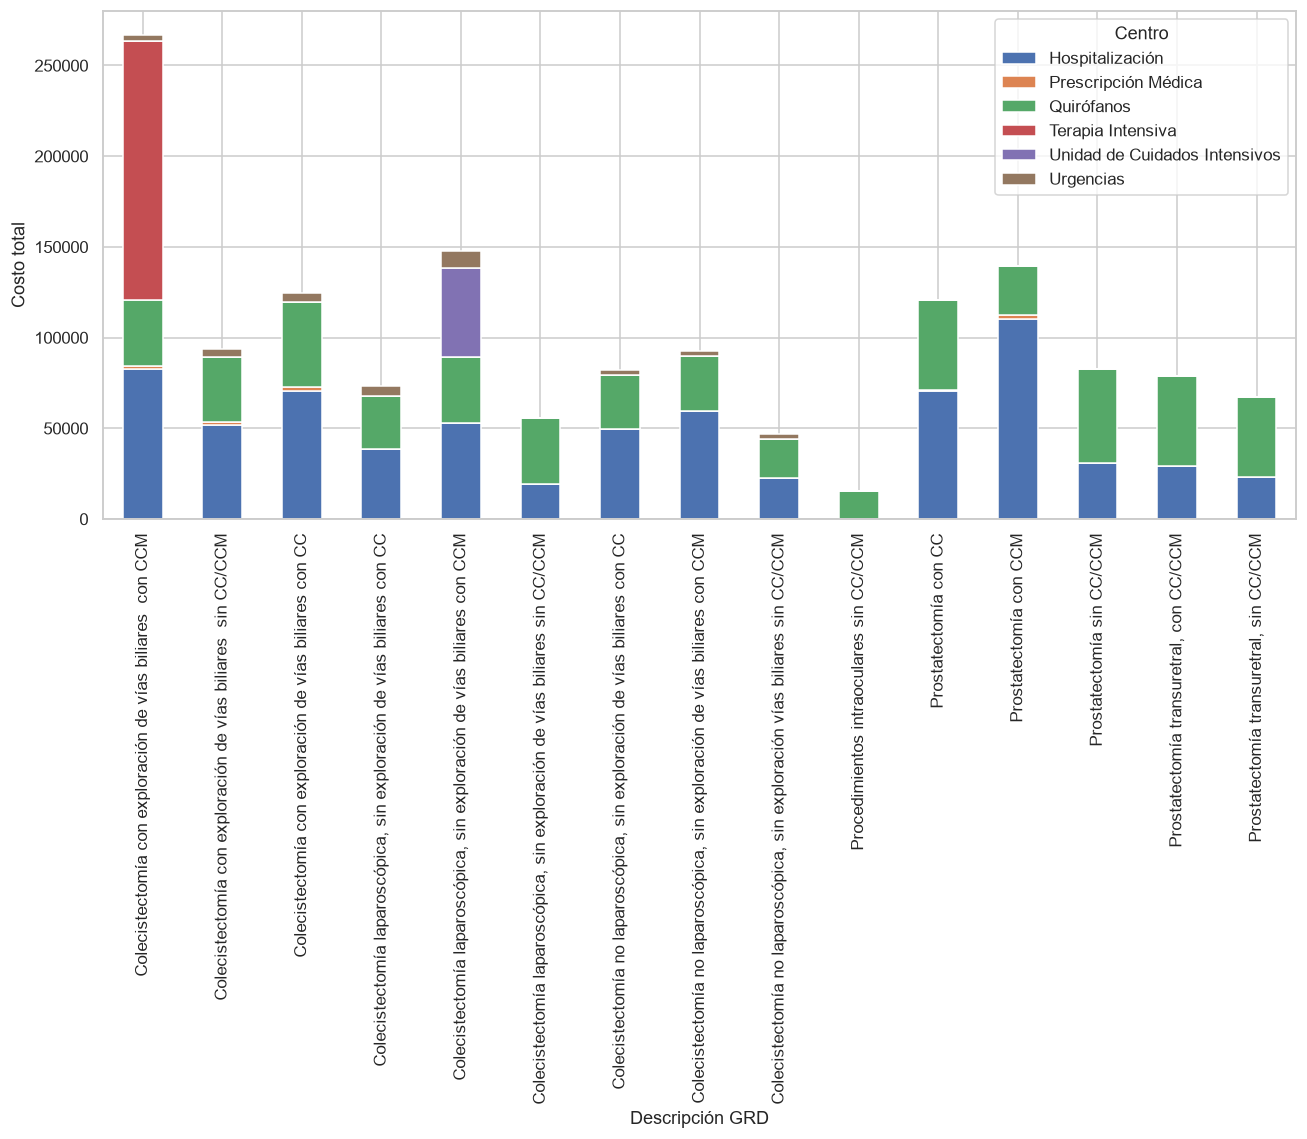

In [26]:
df_plot=(
    df_cme_cata_cole_pro.groupby(["descripcion_grd", "centro_cve"])["costo_total"]
    .sum()
    .unstack(fill_value=0)
)
df_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(14,6)
)
plt.xlabel("Descripción GRD")
plt.ylabel("Costo total")
plt.legend(title="Centro")
plt.xticks(rotation=90)
guardar_grafica("04_1_costo_por_grd_centro_costo")
plt.show()

## 4.2 Ortopedia (fractura de cadera)

Vista previa de la tabla de costos de ortopedia.

In [27]:
df_cme_cde_control=df_cme_cde.copy() #por si me equivoco

In [28]:
df_cme_cde=df_cme_cde_control.copy()

In [29]:
df_cme_cde.head()

,escenario,cpsc,num_atencion,factor_produccion,clave,descripcion,unidad_medida,cantidad,costo_unitario_2024,costo_total_2024
0,1.1.5 Paciente con fractura de cadera y fijaci...,Urgencias,1,Capacidad instalada,0100100,Admisión/Urgencias Hospital,hora,12.0,187.73000,2252.760000
1,1.1.5 Paciente con fractura de cadera y fijaci...,Urgencias,1,Gases medicinales,OXM.HAD.001,Oxígeno medicinal hospitalario. Adulto. Consum...,hora,12.0,3.19117,7.658808
2,1.1.5 Paciente con fractura de cadera y fijaci...,Urgencias,1,Medicamentos,010.000.2154.00.00,Enoxaparina. Solución inyectable. Cada jeringa...,jeringa,1.0,75.81000,75.810000
3,1.1.5 Paciente con fractura de cadera y fijaci...,Urgencias,1,Medicamentos,010.000.3609.00.00,Cloruro de sodio. Solución inyectable al 0.9%....,envase,1.0,7.02000,7.020000
4,1.1.5 Paciente con fractura de cadera y fijaci...,Urgencias,1,Medicamentos,010.000.5721.01.00,Paracetamol. Solución inyectable. Cada frasco ...,frasco,1.0,19.83750,5.951250


Misma revisión de valores únicos que en la sección 4.1.

In [30]:
for col in df_cme_cde.columns:
    if df_cme_cde[col].nunique()<=15:
        print(f"Valores únicos para columna {col} ({df_cme_cde[col].nunique()} únicos)")

        print(df_cme_cde[col].unique())

        print(f"{"#"*50}")
    else: 
        print(f"Valores únicos para columna {col} ({df_cme_cde[col].nunique()} únicos) son muchos para imprimir")
        print(f"{"#"*50}")

Valores únicos para columna escenario (5 únicos)
<StringArray>
['1.1.5 Paciente con fractura de cadera y fijación abierta con clavo intramedular.',
        '1.1.3 Paciente con fractura de cadera y fijación con tornillos canulados.',
            '1.1.1 Paciente con fractura de cadera y sustitución total de cadera. ',
          '1.1.4 Paciente con fractura de cadera y fijación con tornillo dinámico.',
           '1.1.2 Paciente con fractura de cadera y sustitución parcial de cadera.']
Length: 5, dtype: str
##################################################
Valores únicos para columna cpsc (4 únicos)
<StringArray>
['Urgencias ', 'Hospitalización ', 'Quirófano', 'Hospitalización']
Length: 4, dtype: str
##################################################
Valores únicos para columna num_atencion (5 únicos)
<StringArray>
['1', '2', '3', '4', '5']
Length: 5, dtype: str
##################################################
Valores únicos para columna factor_produccion (8 únicos)
<StringArray>
[    

Frecuencia de cada factor de producción (banco de sangre, consumibles, medicamentos, etc.).

In [31]:
df_cme_cde["factor_produccion"].value_counts()

factor_produccion
Medicamentos                    925
Consumibles médicos             800
Estudios de laboratorio          75
Gases medicinales                40
Capacidad instalada              35
Estudios de gabinete             20
Banco de sangre                  15
Servicios médicos indirectos      5
Name: count, dtype: int64

**Gráfica:** costo total 2024 por escenario, apilado por factor de producción.

Gráfica guardada: graficas/reporte\04_2_costo_ortopedia_por_factor.png


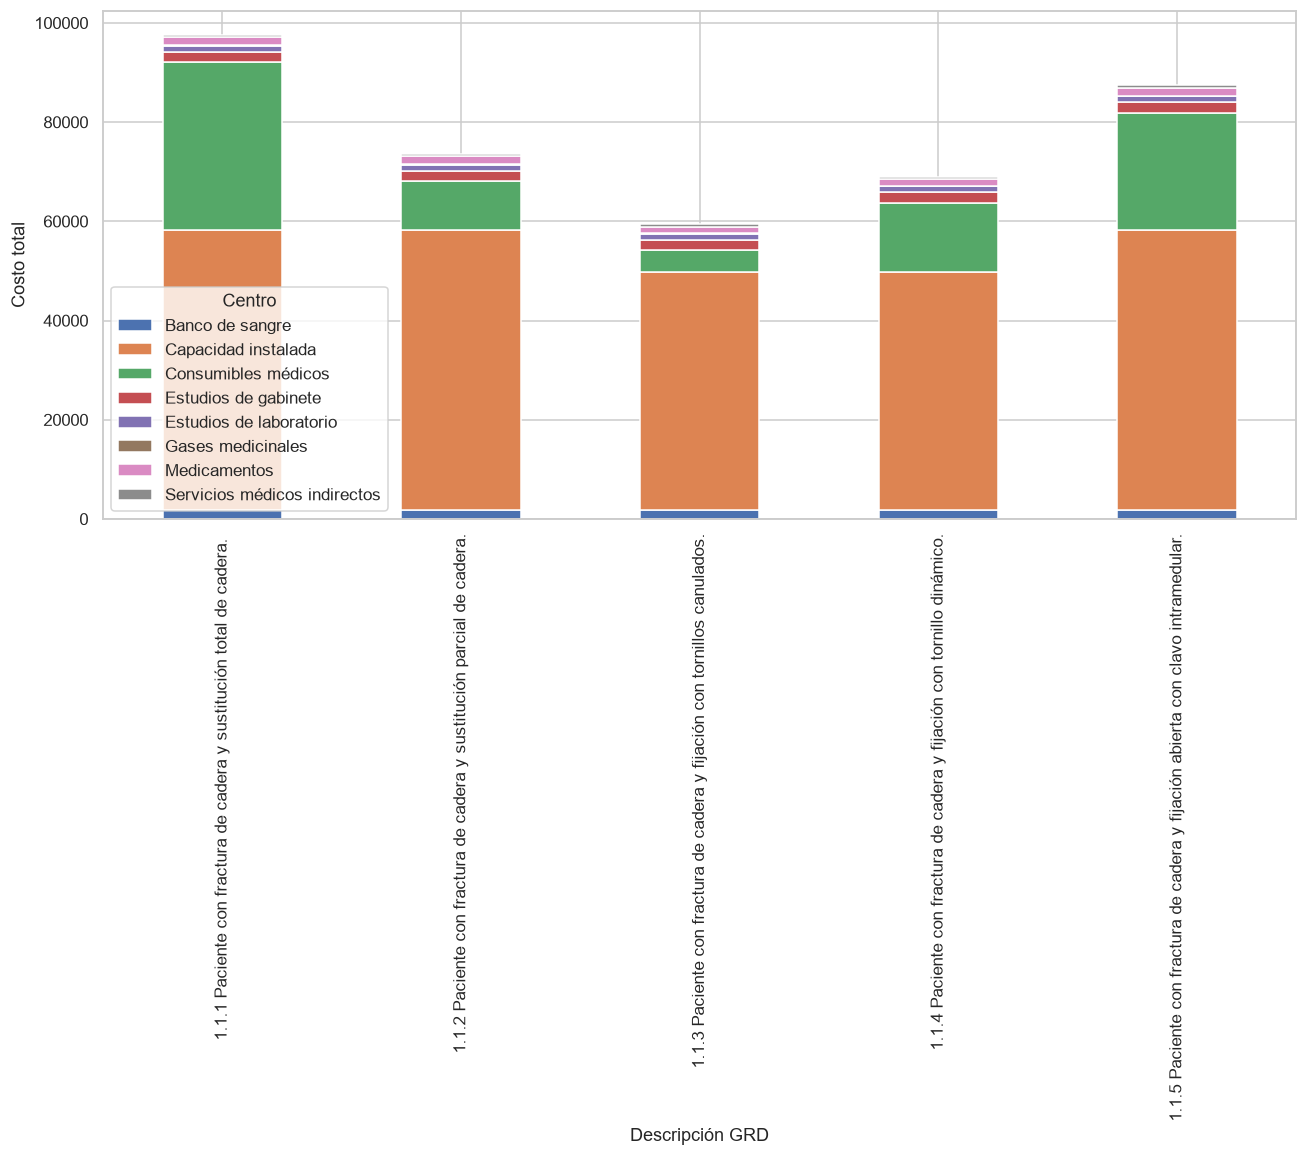

In [32]:
df_plot=(
    df_cme_cde.groupby(["escenario", "factor_produccion"])["costo_total_2024"]
    .sum()
    .unstack(fill_value=0)
)
df_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(14,6)
)
plt.xlabel("Descripción GRD")
plt.ylabel("Costo total")
plt.legend(title="Centro")
plt.xticks(rotation=90)
guardar_grafica("04_2_costo_ortopedia_por_factor")
plt.show()

**Mapeo escenario → código.** Cada escenario de fractura de cadera de la tabla de costos se asocia a un código de GRD (`codigo_esc`) para poder unirlo después con la demanda.

In [33]:
# Mapeo para merge
# Cada escenario de costos se asocia al código de la tabla puente (sección 6):
#   482_1 = Sustitución total de cadera     (CIE-9 8151)
#   482_2 = Sustitución parcial de cadera   (CIE-9 8152)
#   482_3 = Fijación de fractura de cadera  (CIE-9 7915, 7935)
# Los tres escenarios de fijación (1.1.3, 1.1.4 y 1.1.5) comparten 482_3: en 8.3 se usa su PROMEDIO.
mapeo={'1.1.1 Paciente con fractura de cadera y sustitución total de cadera. ': "482_1",
       '1.1.2 Paciente con fractura de cadera y sustitución parcial de cadera.': "482_2",
       '1.1.3 Paciente con fractura de cadera y fijación con tornillos canulados.': "482_3",
       '1.1.4 Paciente con fractura de cadera y fijación con tornillo dinámico.': "482_3",
       '1.1.5 Paciente con fractura de cadera y fijación abierta con clavo intramedular.': "482_3",
}
# Se compara sin espacios al inicio/final para que un espacio extra en la base no deje el código vacío
mapeo_limpio = {texto.strip(): codigo for texto, codigo in mapeo.items()}
df_cme_cde["codigo_esc"]=df_cme_cde["escenario"].astype(str).str.strip().map(mapeo_limpio)

print("Renglones sin código:", int(df_cme_cde["codigo_esc"].isna().sum()))
df_cme_cde.groupby(["codigo_esc", "escenario"]).size().rename("renglones_raw")

Renglones sin código: 0


codigo_esc  escenario                                                                       
482_1       1.1.1 Paciente con fractura de cadera y sustitución total de cadera.                389
482_2       1.1.2 Paciente con fractura de cadera y sustitución parcial de cadera.              381
482_3       1.1.3 Paciente con fractura de cadera y fijación con tornillos canulados.           380
            1.1.4 Paciente con fractura de cadera y fijación con tornillo dinámico.             382
            1.1.5 Paciente con fractura de cadera y fijación abierta con clavo intramedular.    383
Name: renglones_raw, dtype: int64

### Promedio de fijación de fractura de cadera

Los escenarios **1.1.3** (tornillos canulados), **1.1.4** (tornillo dinámico) y **1.1.5** (clavo intramedular) son variantes de la misma intervención: la tabla puente no las distingue y las tres caen en `482_3`. Para que cada procedimiento de fijación tenga **un solo** costo, se usa su **costo promedio**.

**`df_cme_cde` no se modifica**: es la base *raw* (un renglón por insumo). Aquí solo se calcula el promedio y se guarda como un renglón con el formato de la base agrupada de 8.3 (`costos_promedio_fijacion_wide`). En 8.3 ese renglón se pega a `costos_wide_orto`.

1. **Costo por escenario y factor:** suma de insumos; un factor faltante cuenta como 0.
2. **Promedio simple** de los tres escenarios, factor por factor.

1.1.1 (`482_1`) y 1.1.2 (`482_2`) no se promedian. La celda revisa el mapeo y se detiene si algo no cuadra.

In [34]:
# ---------------- Parámetros ----------------
CLAVES_FIJACION = ("1.1.3", "1.1.4", "1.1.5")      # se promedian
CLAVES_INTACTAS = ("1.1.1", "1.1.2")               # NO se promedian
NOMBRE_PROMEDIO_FIJACION = "1.1.6 Promedio de fijación de fractura de cadera (1.1.3, 1.1.4 y 1.1.5)"
CODIGO_PROMEDIO_FIJACION = "482_3"
COLUMNA_COSTO = "costo_total_2024"

# Número del escenario (los primeros 5 caracteres, sin espacios al inicio)
numero_escenario = df_cme_cde["escenario"].astype(str).str.strip().str[:5]
es_fijacion_cde = numero_escenario.isin(CLAVES_FIJACION)

# ---------------- Revisión del mapeo ----------------
problemas = []
if df_cme_cde["codigo_esc"].isna().any():
    problemas.append("Hay escenarios sin código: " + str(df_cme_cde.loc[df_cme_cde["codigo_esc"].isna(), "escenario"].unique().tolist()))
if set(numero_escenario[es_fijacion_cde].unique()) != set(CLAVES_FIJACION):
    problemas.append(f"No se encontraron los 3 escenarios de fijación {CLAVES_FIJACION}.")
if set(numero_escenario[~es_fijacion_cde].unique()) != set(CLAVES_INTACTAS):
    problemas.append(f"Los escenarios que no se promedian no son exactamente {CLAVES_INTACTAS}.")
codigos_en_fijacion = df_cme_cde.loc[es_fijacion_cde, "codigo_esc"].unique().tolist()
if codigos_en_fijacion != [CODIGO_PROMEDIO_FIJACION]:
    problemas.append(f"Las fijaciones deben tener todas el código {CODIGO_PROMEDIO_FIJACION}; tienen {codigos_en_fijacion}.")
if (df_cme_cde.loc[~es_fijacion_cde, "codigo_esc"] == CODIGO_PROMEDIO_FIJACION).any():
    problemas.append(f"Un escenario que no es de fijación tiene el código {CODIGO_PROMEDIO_FIJACION}; se duplicaría en el merge de 8.3.")
escenarios_por_codigo = df_cme_cde.loc[~es_fijacion_cde].groupby("codigo_esc")["escenario"].nunique()
if (escenarios_por_codigo > 1).any():
    problemas.append("Estos códigos tienen más de un escenario y se duplicarían en el merge: " + str(escenarios_por_codigo[escenarios_por_codigo > 1].index.tolist()))
if problemas:
    raise ValueError("Revise el mapeo de la sección 4.2:\n- " + "\n- ".join(problemas))

# ---------------- Paso 1: costo por escenario y factor (suma de insumos) ----------------
costo_escenario_factor = (
    df_cme_cde.loc[es_fijacion_cde]
    .groupby(["escenario", "factor_produccion"])[COLUMNA_COSTO]
    .sum()
    .unstack("factor_produccion", fill_value=0)      # factor faltante = 0
)

# ---------------- Paso 2: promedio simple de los tres escenarios ----------------
costo_promedio_factor = costo_escenario_factor.mean(axis=0)

# ---------------- Renglón en formato de la base agrupada (costos_wide_orto) ----------------
costos_promedio_fijacion_wide = costo_promedio_factor.to_frame().T.reset_index(drop=True)
costos_promedio_fijacion_wide.insert(0, "escenario", NOMBRE_PROMEDIO_FIJACION)
costos_promedio_fijacion_wide.insert(0, "codigo_esc", CODIGO_PROMEDIO_FIJACION)
costos_promedio_fijacion_wide.columns.name = None

# ---------------- Tabla de revisión ----------------
revision_promedio = costo_escenario_factor.copy()
revision_promedio.loc["PROMEDIO"] = costo_promedio_factor
revision_promedio["Total"] = revision_promedio.sum(axis=1)
print("df_cme_cde no se modificó:", len(df_cme_cde), "renglones raw")
revision_promedio.round(1)

df_cme_cde no se modificó: 1915 renglones raw


factor_produccion,Banco de sangre,Capacidad instalada,Consumibles médicos,Estudios de gabinete,Estudios de laboratorio,Gases medicinales,Medicamentos,Servicios médicos indirectos,Total
escenario,,,,,,,,,
1.1.3 Paciente con fractura de cadera y fijación con tornillos canulados.,1811.4,47930.3,4400.5,2093.0,1206.0,120.0,1317.4,479.9,59358.5
1.1.4 Paciente con fractura de cadera y fijación con tornillo dinámico.,1811.4,47930.3,14016.3,2093.0,1206.0,120.0,1270.8,479.9,68927.7
1.1.5 Paciente con fractura de cadera y fijación abierta con clavo intramedular.,1811.4,56369.0,23694.1,2093.0,1206.0,124.5,1637.0,479.9,87414.8
PROMEDIO,1811.4,50743.2,14037.0,2093.0,1206.0,121.5,1408.4,479.9,71900.3


### Referencia: versión previa de la tabla puente

La siguiente celda conserva un fragmento de una versión anterior de la tabla puente (códigos de fractura de cadera `482_1`, `482_2` y `482_3`). Está escrita en Markdown, por lo que **no se ejecuta**; se mantiene únicamente como referencia. La versión vigente se construye en las secciones 6 y 12.

```text
# ------------------------------------------------------------
### 5.1 PROSTATECTOMÍA
# ------------------------------------------------------------

agregar_combinaciones(
    cie10_list=["C61X"],
    cie9_list=["605X"],
    escenario="Prostatectomia radical",
    grd_cme=None,
    bloque="CME con Prostatectomia"
)

# ------------------------------------------------------------
### 5.2 CIRUGÍA DE CATARATA
# ------------------------------------------------------------

agregar_combinaciones(
    cie10_list=[
        "H250",
        "H251",
        "H258",
        "H259"
    ],
    cie9_list=[
        "1341",
        "1343",
        "1371"
    ],
    escenario="Cirugia de catarata",
    grd_cme="117",
    bloque="CME con cirugia de catarata"
)


# ------------------------------------------------------------
### 5.3 COLECISTECTOMÍA
# ------------------------------------------------------------

agregar_combinaciones(
    cie10_list=["D376"],
    cie9_list=[
        "5123",
        "5022"
    ],
    escenario=(
        "Colecistectomia laparoscopica "
        "con hepatectomia parcial"
    ),
    grd_cme="419",
    bloque="CME con colecistectomia"
)

agregar_combinaciones(
    cie10_list=["K802"],
    cie9_list=["5123"],
    escenario="Colecistectomia laparoscopica",
    grd_cme="419",
    bloque="CME con colecistectomia"
)

# ------------------------------------------------------------
### 5.4 FRACTURA DE CADERA
# ------------------------------------------------------------

dx_cadera = [
    "S720",
    "S721",
    "S722"
]

agregar_combinaciones(
    cie10_list=dx_cadera,
    cie9_list=["8151"],
    escenario="Sustitucion total de cadera",
    grd_cme="482_1",
    bloque="CME fractura de cadera"
)

agregar_combinaciones(
    cie10_list=dx_cadera,
    cie9_list=["8152"],
    escenario="Sustitucion parcial de cadera",
    grd_cme="482_2",
    bloque="CME fractura de cadera"
)

agregar_combinaciones(
    cie10_list=dx_cadera,
    cie9_list=[
        "7915",
        "7935"
    ],
    escenario="Fijacion de fractura de cadera",
    grd_cme="482_3",
    bloque="CME fractura de cadera"
)



)
```

# 5. Exploración por palabras clave

Antes de definir la tabla puente se busca en la descripción del procedimiento principal (`des_proc_prin_intervencion`) qué registros corresponden a cada intervención, y con qué códigos CIE-9 y CIE-10 y en qué especialidades aparecen. Esto justifica los códigos elegidos en las secciones 6 y 12.

Revisión de la columna de descripción del procedimiento.

In [35]:
df["DX_PX"]=df["des_proc_prin_intervencion"]+"-"+df[dx_principal]
df["DX_desc"]=df[dx_principal]+"-"+df["des_cie_principal"]
df["des_proc_prin_intervencion"]


0          Facoemulsificacion y aspiracion de catarata
1                         Sustitucion total de rodilla
2          Facoemulsificacion y aspiracion de catarata
3          Facoemulsificacion y aspiracion de catarata
4          Facoemulsificacion y aspiracion de catarata
                              ...                     
3202538                  Inyeccion de sustituto vitreo
3202539    Facoemulsificacion y aspiracion de catarata
3202540    Facoemulsificacion y aspiracion de catarata
3202541    Facoemulsificacion y aspiracion de catarata
3202542    Facoemulsificacion y aspiracion de catarata
Name: des_proc_prin_intervencion, Length: 3202543, dtype: str

## 5.1 Prostatectomía: búsqueda inicial

Filtra los registros cuya descripción contiene «prostatectomia» e imprime su conteo y las descripciones distintas.

In [36]:
# Colecistectomía
df_col=df[
    df["des_proc_prin_intervencion"].str.contains("prostatectomia", case=False, na=False)
]
print(f" hay {len(df_col)}  registros para colecistectomía")

print(df_col["DX_PX"].value_counts())

print(f"{"#"*50}")
print(f"{"#"*50}")


 hay 15530  registros para colecistectomía
DX_PX
Otra prostatectomia transuretral-N40X                                               11004
Prostatectomia radical-C61X                                                          1514
Otra prostatectomia-N40X                                                              636
Prostatectomia transuretral (ultrasonido) guiado por laser inducido (tulip)-N40X      273
Otra prostatectomia transuretral-C61X                                                 270
                                                                                    ...  
Otra prostatectomia-N201                                                                1
Otra prostatectomia transuretral-K432                                                   1
Otra prostatectomia-N412                                                                1
Prostatectomia radical-C790                                                             1
Otra prostatectomia transuretral-K802              

Para cada descripción encontrada, lista la clave de procedimiento (`PX`) y los diagnósticos CIE-10 principales (`DX`) asociados.

In [37]:
# Busco cie10_list=["C61X"],
#    cie9_list=["605X"],
for proc in df_col["des_proc_prin_intervencion"].unique():
        print(f"Para {proc}")
        print("PX:",df_col[df_col["des_proc_prin_intervencion"]==proc][px].unique())
        display("DX:",df_col[df_col["des_proc_prin_intervencion"]==proc]["DX_desc"].unique())

Para Otra prostatectomia transuretral
PX: <StringArray>
['6029']
Length: 1, dtype: str


'DX:'

<StringArray>
[                                                         'N40X-Hiperplasia de la prostata',
                                                                'N210-Calculo en la vejiga',
                         'N139-Uropatia obstructiva y por reflujo, sin otra especificacion',
                             'N419-Enfermedad inflamatoria de la prostata, no especificada',
                                                          'R31X-Hematuria, no especificada',
                                                        'C61X-Tumor maligno de la prostata',
                               'Z125-Examen de pesquisa especial para tumor de la prostata',
                   'N510-Trastornos de prostata en enfermedades clasificadas en otra parte',
                                                   'N182-Enfermedad renal crónica, etapa 2',
                                                              'N412-Absceso de la prostata',
 ...
 'N511-Trastornos del testiculo y del epididimo en 

Para Prostatectomia radical
PX: <StringArray>
['605X']
Length: 1, dtype: str


'DX:'

<StringArray>
[            'D400-Tumor de comportamiento incierto o desconocido de la prostata',
                                              'C61X-Tumor maligno de la prostata',
                                                'N40X-Hiperplasia de la prostata',
                             'N428-Otros trastornos especificados de la prostata',
                       'C64X-Tumor maligno del riñon, excepto de la pelvis renal',
                                          'D075-Carcinoma in situ de la prostata',
                                       'Q531-Testiculo no descendido, unilateral',
                            'C672-Tumor maligno de la pared lateral de la vejiga',
                                                  'N323-Diverticulo de la vejiga',
         'Q643-Otras atresias y estenosis de la uretra y del cuello de la vejiga',
                     'Z125-Examen de pesquisa especial para tumor de la prostata',
                'C679-Tumor maligno de la vejiga urinaria, parte no espec

... (5 outputs left out)

<StringArray>
[                                       'N40X-Hiperplasia de la prostata',
                                                 'N410-Prostatitis aguda',
                                              'N210-Calculo en la vejiga',
                                      'C61X-Tumor maligno de la prostata',
                          'N202-Calculo del riñon con calculo del ureter',
 'Q643-Otras atresias y estenosis de la uretra y del cuello de la vejiga',
                                               'N411-Prostatitis cronica',
              'N220-Litiasis urinaria en esquistosomiasis [bilharziasis]',
                                                 'N200-Calculo del riñon',
                                      'D291-Tumor benigno de la prostata',
     'D400-Tumor de comportamiento incierto o desconocido de la prostata',
                         'N429-Trastorno de la prostata, no especificado',
                                 'C670-Tumor maligno del trigono vesical',
           

Para Prostatectomia perineal
PX: <StringArray>
['6062']
Length: 1, dtype: str


'DX:'

<StringArray>
[                                 'C61X-Tumor maligno de la prostata',
 'D400-Tumor de comportamiento incierto o desconocido de la prostata',
         'Z125-Examen de pesquisa especial para tumor de la prostata',
                           'C186-Tumor maligno del colon descendente',
                                    'N40X-Hiperplasia de la prostata']
Length: 5, dtype: str

## 5.2 Colecistectomía

Filtra los registros cuya descripción contiene «colecistectomia» y muestra su distribución por especialidad.

In [38]:
# Colecistectomía
df_col=df[
    df["des_proc_prin_intervencion"].str.contains("colecistectomia", case=False, na=False)
]
print(f" hay {len(df_col)}  registros para olecistectomía")

print(df_col["des_especialidad"].value_counts())

print(f"{"#"*50}")
print(f"{"#"*50}")


 hay 180736  registros para olecistectomía
des_especialidad
Cirugía General                           178500
Cirugía Pediátrica                          1212
Traumatología y ortopedia                    242
Cirugía oncológica                           229
Urología                                     117
Ginecología                                   96
Angiología y Cirugía Vascular                 66
Cirugía General Extensión Hospitalaria        45
Obstetricia                                   30
Proctología                                   21
Sarcomas                                      21
Oftalmología                                  20
Cirugía Plástica y Reconstructiva             18
Cardiología                                   16
Cirugía Cardiotorácica                        16
Otorrinolaringología                          11
Unidad de Trasplantes                         11
Neurocirugía                                   9
Cirugía Maxilo Facial                          9
Ginecolog

Lista las claves de procedimiento (`PX`) asociadas a cada descripción de colecistectomía.

In [39]:

for proc in df_col["des_proc_prin_intervencion"].unique():
        print(f"Para {proc}")
        print("PX:",df_col[df_col["des_proc_prin_intervencion"]==proc][px].unique())
        display("dX:",df_col[df_col["des_proc_prin_intervencion"]==proc]["DX_desc"].unique())

Para Colecistectomia laparoscopica
PX: <StringArray>
['5123']
Length: 1, dtype: str


'dX:'

<StringArray>
[        'K801-Calculo de la vesicula biliar con otra colecistitis',
                                        'K811-Colecistitis cronica',
        'K800-Calculo de la vesicula biliar con colecistitis aguda',
                                         'Q444-Quiste del coledoco',
                               'K850-Pancreatitis idiopatica aguda',
                                          'K808-Otras colelitiasis',
      'K828-Otras enfermedades especificadas de la vesicula biliar',
                                   'K851-Pancreatitis biliar aguda',
   'K805-Calculo de conducto biliar sin colangitis ni colecistitis',
                           'K820-Obstruccion de la vesicula biliar',
 ...
                                                  'K20X-Esofagitis',
                                        'N360-Fistula de la uretra',
 'K318-Otras enfermedades especificadas del estomago y del duodeno',
                         'C445-Tumor maligno de la piel del tronco',
               

Para Colecistectomia
PX: <StringArray>
['5122']
Length: 1, dtype: str


'dX:'

<StringArray>
[                                       'K811-Colecistitis cronica',
                                          'K810-Colecistitis aguda',
        'K800-Calculo de la vesicula biliar con colecistitis aguda',
                            'K821-Hidropesia de la vesicula biliar',
         'K801-Calculo de la vesicula biliar con otra colecistitis',
                                          'K808-Otras colelitiasis',
                               'K819-Colecistitis, no especificada',
                                                  'K830-Colangitis',
              'K802-Calculo de la vesicula biliar sin colecistitis',
           'K829-Enfermedad de la vesicula biliar, no especificada',
 ...
                        'C241-Tumor maligno de la ampolla de vater',
                                  'A483-Sindrome del choque toxico',
              'D126-Tumor benigno del colon, parte no especificada',
                               'K421-Hernia umbilical con gangrena',
               

... (2 outputs left out)

<StringArray>
[                                                                                                          'K820-Obstruccion de la vesicula biliar',
                                                                                                                          'K808-Otras colelitiasis',
                                                                                           'K829-Enfermedad de la vesicula biliar, no especificada',
                                                                                              'K802-Calculo de la vesicula biliar sin colecistitis',
                                                                                                                          'K810-Colecistitis aguda',
                                                                                                                        'K811-Colecistitis cronica',
                                                                                         'K8

Para Otra colecistectomia parcial
PX: <StringArray>
['5121']
Length: 1, dtype: str


'dX:'

<StringArray>
[                                                   'K801-Calculo de la vesicula biliar con otra colecistitis',
                                                   'K800-Calculo de la vesicula biliar con colecistitis aguda',
                                                                                     'K810-Colecistitis aguda',
                                                         'K802-Calculo de la vesicula biliar sin colecistitis',
                                                                                   'K811-Colecistitis cronica',
                                                                                     'K808-Otras colelitiasis',
                                                            'K804-Calculo de conducto biliar con colecistitis',
                                                                     'K316-Fistula del estomago y del duodeno',
                                                                                     'K750

## 5.3 Prostatectomía por especialidad

Distribución de los registros de prostatectomía por especialidad y, dentro de cada una, por descripción de procedimiento.

In [40]:
# Prostatectomía
df_pro=df[
    df["des_proc_prin_intervencion"].str.contains("prostatectomia", case=False, na=False)
]
print(f" hay {len(df_pro)}  registros para Prostatectomía")

print(df_pro["des_especialidad"].value_counts())

print(f"{"#"*50}")
print(f"{"#"*50}")

for especialidad in df_pro["des_especialidad"].unique():
    df_aux=df_pro[df_pro["des_especialidad"]==especialidad]
    print(f"Especialidad {especialidad}")
    print(df_aux["des_proc_prin_intervencion"].value_counts())
    print(f"{"#"*50}")
    print(f"{"#"*50}")
    for proc in df_aux["des_proc_prin_intervencion"].unique():
        df_aux_2=df_aux[df_aux["des_proc_prin_intervencion"]==proc]
        #print(df_aux_2["des_segundario_procedimiento_intervencion"].unique())
        


 hay 15530  registros para Prostatectomía
des_especialidad
Urología                                  13639
Cirugía General                            1496
Uro Oncología                               332
Traumatología y ortopedia                    21
Cirugía oncológica                           14
Angiología y Cirugía Vascular                 9
Cirugía Pediátrica                            5
Proctología                                   4
Oftalmología                                  3
Cirugía Maxilo Facial                         2
Medicina Interna                              1
Cirugía General Extensión Hospitalaria        1
Sarcomas                                      1
Nefrología                                    1
Hematología                                   1
Name: count, dtype: int64
##################################################
##################################################
Especialidad Urología  
des_proc_prin_intervencion
Otra prostatectomia transuretral          

## 5.4 Cirugía de catarata (procedimientos intraoculares)

Filtra las descripciones que contienen «oculares» y las desglosa por especialidad y descripción, con la misma lógica de la sección 5.3.

In [41]:
# Intra oculares
df_cata=df[
    df["des_proc_prin_intervencion"].str.contains("oculares", case=False, na=False)
]
print(f" hay {len(df_cata)}  registros para Oculares")

print(df_cata["des_especialidad"].value_counts())

print(f"{"#"*50}")
print(f"{"#"*50}")

for especialidad in df_cata["des_especialidad"].unique():
    df_aux=df_cata[df_cata["des_especialidad"]==especialidad]
    print(f"Especialidad {especialidad}")
    print(df_aux["des_proc_prin_intervencion"].value_counts())
    print(f"{"#"*50}")
    print(f"{"#"*50}")
    for proc in df_aux["des_proc_prin_intervencion"].unique():
        df_aux_2=df_aux[df_aux["des_proc_prin_intervencion"]==proc]
        #print(df_aux_2["des_segundario_procedimiento_intervencion"].unique())
        

 hay 1755  registros para Oculares
des_especialidad
Oftalmología                         1620
Cirugía Pediátrica                     63
Traumatología y ortopedia              23
Cirugía General                        19
Pie y Tobillo                           9
Cirugía Plástica y Reconstructiva       6
Otorrinolaringología                    4
Ortopedia                               4
Traumatología                           2
Cirugía Maxilo Facial                   2
Ginecología                             1
Obstetricia                             1
Otorrinolaringología Pediátrica         1
Name: count, dtype: int64
##################################################
##################################################
Especialidad Oftalmología
des_proc_prin_intervencion
Otras operaciones sobre dos o mas musculos extraoculares, uno u ambos ojos                                            582
Operaciones sobre dos o mas musculos extraoculares con desprendimiento temporal del globo ocular, u

# 6. Tabla puente CME (versión A: diagnóstico principal y secundarios)

**Propósito.** Asignar a cada procedimiento solicitado un *escenario clínico* y un *GRD institucional* (`grd_cme`), usando la combinación de **diagnóstico CIE-10** y **procedimiento CIE-9**.

**Pasos que realiza la celda:**

1. **Catálogo CIE-9.** Lee `Resumen_Atenciones Qx_DES_18Ago2026.xlsx`, normaliza los códigos (mayúsculas, sin puntos ni espacios) y conserva su descripción.
2. **Mapa CME.** Define, con `agregar_combinaciones`, las combinaciones CIE-10 × CIE-9 válidas para cada escenario:

   | Escenario | CIE-10 | CIE-9 | GRD CME |
   |---|---|---|---|
   | Prostatectomía radical | C61X | 605X | 667 |
   | Cirugía de catarata | H250, H251, H258, H259 | 1341, 1343, 1371 | 117 |
   | Colecistectomía laparoscópica | K802 | 5123 | 419 |
   | Colecistectomía con hepatectomía parcial | D376 | 5123, 5022 | 419 |
   | Sustitución total de cadera | S720, S721, S722 | 8151 | 482_1 |
   | Sustitución parcial de cadera | S720, S721, S722 | 8152 | 482_2 |
   | Fijación de fractura de cadera | S720, S721, S722 | 7915, 7935 | 482_3 |

3. **Diagnósticos por procedimiento.** Construye una tabla con una fila por diagnóstico: el principal (prioridad 0) y cada uno de los secundarios (prioridad 1, 2, …), que se separan de la lista original con `asegurar_lista` y `explode`.
4. **Cruce.** Une con el mapa por (CIE-10, CIE-9). Si varios diagnósticos del mismo procedimiento coinciden, se conserva el de **menor prioridad**: primero el principal, luego el primer secundario, etc.
5. **Salida.** Devuelve `df_cme`, con **una fila por procedimiento identificado**, e imprime la cobertura (porcentaje de procedimientos identificados), qué tipo de diagnóstico produjo el cruce, un resumen por escenario y una comparación opcional contra `ms_drg` si esa columna existe.

**Supuestos:** cada fila de `df` es un procedimiento solicitado; no se deduplican pacientes; el cruce es `inner`, de modo que solo se conservan los procedimientos que coinciden con el mapa. El bloque de unión con costos que aparece al final de la celda está comentado (entre comillas triples) y no se ejecuta.

In [42]:

import ast
import pandas as pd

# ============================================================
# CAMINO B
# CIE-10 diagnóstico principal + lista de secundarios
# + CIE-9 procedimiento
# -> escenario CME / GRD institucional
#
# Supuestos:
# - Este .py está en la misma carpeta que:
#   1) Resumen_Atenciones Qx_DES_18Ago2026.xlsx
#   2) CIE 9MC en CME.xlsx
# - Tu DataFrame principal ya existe y se llama df
# - Cada fila de df representa un procedimiento solicitado
# - dx_secundario es UNA columna que contiene una lista
# ============================================================


# ------------------------------------------------------------
# 1. ARCHIVOS
# ------------------------------------------------------------

ARCHIVO_CATALOGO = "Resumen_Atenciones Qx_DES_18Ago2026.xlsx"
ARCHIVO_CME = "CIE 9MC en CME.xlsx"


# ------------------------------------------------------------
# 2. FUNCIONES AUXILIARES
# ------------------------------------------------------------

def limpiar_codigo(x):
    """
    Normaliza códigos:
    - mayúsculas
    - sin puntos
    - sin espacios
    """
    if pd.isna(x):
        return None

    return (
        str(x)
        .upper()
        .strip()
        .replace(".", "")
        .replace(" ", "")
    )


def asegurar_lista(x):
    """
    Convierte dx_secundario a lista.

    Funciona si la celda contiene:
    - una lista real:
        ["E119", "I10"]

    - una lista guardada como texto:
        "['E119', 'I10']"

    - un solo diagnóstico:
        "E119"

    - NaN / None
    """

    if x is None:
        return []

    if isinstance(x, float) and pd.isna(x):
        return []

    # Ya es lista
    if isinstance(x, list):
        return x

    # Tupla / set
    if isinstance(x, (tuple, set)):
        return list(x)

    # Si viene como string
    if isinstance(x, str):

        x = x.strip()

        if x == "":
            return []

        # Intentar interpretar una lista escrita como texto
        try:
            valor = ast.literal_eval(x)

            if isinstance(valor, list):
                return valor

            if isinstance(valor, (tuple, set)):
                return list(valor)

        except (ValueError, SyntaxError):
            pass

        # Si no era lista, asumir que es un solo diagnóstico
        return [x]

    return [x]


# ------------------------------------------------------------
# 3. CARGAR CATÁLOGO CIE-9
# ------------------------------------------------------------

catalogo_cie9 = pd.read_excel(
    ARCHIVO_CATALOGO,
    sheet_name="Datos_Completos"
)

catalogo_cie9 = catalogo_cie9.rename(
    columns={
        "Codigo": "cie9",
        "Descripcion": "cie9_desc",
        "Atenciones": "atenciones_catalogo"
    }
)

catalogo_cie9["cie9_limpio"] = (
    catalogo_cie9["cie9"]
    .apply(limpiar_codigo)
)

catalogo_cie9 = (
    catalogo_cie9[
        [
            "cie9_limpio",
            "cie9_desc",
            "atenciones_catalogo"
        ]
    ]
    .drop_duplicates("cie9_limpio")
)


# ------------------------------------------------------------
# 4. LEER ARCHIVO CME
# ------------------------------------------------------------

cme_raw = pd.read_excel(
    ARCHIVO_CME,
    sheet_name="Hoja1",
    header=None
)


# ------------------------------------------------------------
# 5. CONSTRUIR TABLA PUENTE CME
# ------------------------------------------------------------

registros = []


def agregar_combinaciones(
    cie10_list,
    cie9_list,
    escenario,
    grd_cme=None,
    bloque=None
):
    for dx in cie10_list:
        for px in cie9_list:

            registros.append({
                "cie10_limpio": limpiar_codigo(dx),
                "cie9_limpio": limpiar_codigo(px),
                "escenario": escenario,
                "grd_cme": (
                    None
                    if grd_cme is None
                    else str(grd_cme)
                ),
                "bloque_cme": bloque
            })


# ------------------------------------------------------------
# 5.1 PROSTATECTOMÍA
# ------------------------------------------------------------

agregar_combinaciones(
    cie10_list=["C61X"],
    cie9_list=["605X"],
    escenario="Prostatectomia radical",
    grd_cme="667",
    bloque="CME con Prostatectomia"
)


# ------------------------------------------------------------
# 5.2 CIRUGÍA DE CATARATA
# ------------------------------------------------------------

agregar_combinaciones(
    cie10_list=[
        "H250",
        "H251",
        "H258",
        "H259"
    ],
    cie9_list=[
        "1341",
        "1343",
        "1371"
    ],
    escenario="Cirugia de catarata",
    grd_cme="117",
    bloque="CME con cirugia de catarata"
)


# ------------------------------------------------------------
# 5.3 COLECISTECTOMÍA
# ------------------------------------------------------------

agregar_combinaciones(
    cie10_list=["D376"],
    cie9_list=[
        "5123",
        "5022"
    ],
    escenario=(
        "Colecistectomia laparoscopica "
        "con hepatectomia parcial"
    ),
    grd_cme="419",
    bloque="CME con colecistectomia"
)

agregar_combinaciones(
    cie10_list=["K802"],
    cie9_list=["5123"],
    escenario="Colecistectomia laparoscopica",
    grd_cme="419",
    bloque="CME con colecistectomia"
)


# ------------------------------------------------------------
# 5.4 FRACTURA DE CADERA
# ------------------------------------------------------------

dx_cadera = [
    "S720",
    "S721",
    "S722"
]

agregar_combinaciones(
    cie10_list=dx_cadera,
    cie9_list=["8151"],
    escenario="Sustitucion total de cadera",
    grd_cme="482_1",
    bloque="CME fractura de cadera"
)

agregar_combinaciones(
    cie10_list=dx_cadera,
    cie9_list=["8152"],
    escenario="Sustitucion parcial de cadera",
    grd_cme="482_2",
    bloque="CME fractura de cadera"
)

agregar_combinaciones(
    cie10_list=dx_cadera,
    cie9_list=[
        "7915",
        "7935"
    ],
    escenario="Fijacion de fractura de cadera con tornillos canulados",
    grd_cme="482_3",
    bloque="CME fractura de cadera"
)




mapa_cme = (
    pd.DataFrame(registros)
    .drop_duplicates(
        subset=[
            "cie10_limpio",
            "cie9_limpio",
            "escenario",
            "grd_cme"
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. AGREGAR DESCRIPCIÓN CIE-9
# ------------------------------------------------------------

mapa_cme = mapa_cme.merge(
    catalogo_cie9,
    on="cie9_limpio",
    how="left"
)


# ------------------------------------------------------------
# 7. CONFIGURA LAS COLUMNAS DE TU BASE
# ------------------------------------------------------------

# CAMBIA SOLO ESTAS TRES LÍNEAS



# ------------------------------------------------------------
# 8. CREAR ID ÚNICO POR PROCEDIMIENTO
# ------------------------------------------------------------

df = df.copy()

df["_id_procedimiento"] = range(len(df))


# ------------------------------------------------------------
# 9. CREAR TABLA DE DIAGNÓSTICO PRINCIPAL
# ------------------------------------------------------------

df_dx_principal = df[
    [
        "_id_procedimiento",
        px,
        dx_principal
    ]
].copy()

df_dx_principal = df_dx_principal.rename(
    columns={
        dx_principal: "cie10_original"
    }
)

df_dx_principal["tipo_dx"] = "principal"

df_dx_principal["prioridad_dx"] = 0


# ------------------------------------------------------------
# 10. CREAR TABLA DE DIAGNÓSTICOS SECUNDARIOS
# ------------------------------------------------------------

df_dx_secundarios = df[
    [
        "_id_procedimiento",
        px,
        dx_secundario
    ]
].copy()

# Convertir cada celda en lista
df_dx_secundarios["cie10_original"] = (
    df_dx_secundarios[dx_secundario]
    .apply(asegurar_lista)
)

# Una fila por diagnóstico secundario
df_dx_secundarios = (
    df_dx_secundarios
    .explode("cie10_original")
)

# Eliminar la columna original
df_dx_secundarios = df_dx_secundarios.drop(
    columns=dx_secundario
)

df_dx_secundarios["tipo_dx"] = "secundario"

# Para desempatar entre secundarios,
# conservar el orden en el que aparecen
df_dx_secundarios["orden_secundario"] = (
    df_dx_secundarios
    .groupby("_id_procedimiento")
    .cumcount()
)

df_dx_secundarios["prioridad_dx"] = (
    1
    + df_dx_secundarios["orden_secundario"]
)


# ------------------------------------------------------------
# 11. UNIR PRINCIPAL + SECUNDARIOS
# ------------------------------------------------------------

df_dx = pd.concat(
    [
        df_dx_principal[
            [
                "_id_procedimiento",
                px,
                "cie10_original",
                "tipo_dx",
                "prioridad_dx"
            ]
        ],
        df_dx_secundarios[
            [
                "_id_procedimiento",
                px,
                "cie10_original",
                "tipo_dx",
                "prioridad_dx"
            ]
        ]
    ],
    ignore_index=True
)


# ------------------------------------------------------------
# 12. LIMPIAR CÓDIGOS
# ------------------------------------------------------------

df_dx["cie10_limpio"] = (
    df_dx["cie10_original"]
    .apply(limpiar_codigo)
)

df_dx["cie9_limpio"] = (
    df_dx[px]
    .apply(limpiar_codigo)
)


# ------------------------------------------------------------
# 13. ELIMINAR DIAGNÓSTICOS VACÍOS
# ------------------------------------------------------------

df_dx = df_dx[
    df_dx["cie10_limpio"].notna()
].copy()


# ------------------------------------------------------------
# 14. MATCH CONTRA MAPA CME
# ------------------------------------------------------------

matches = df_dx.merge(
    mapa_cme[
        [
            "cie10_limpio",
            "cie9_limpio",
            "cie9_desc",
            "escenario",
            "grd_cme",
            "bloque_cme",
            "atenciones_catalogo"
        ]
    ],
    on=[
        "cie10_limpio",
        "cie9_limpio"
    ],
    how="inner"
)


# ------------------------------------------------------------
# 15. PRIORIZAR PRINCIPAL SOBRE SECUNDARIOS
# ------------------------------------------------------------

# Si varios diagnósticos del mismo procedimiento hacen match:
#
# 1. principal
# 2. primer secundario
# 3. segundo secundario
# etc.

matches = (
    matches
    .sort_values(
        [
            "_id_procedimiento",
            "prioridad_dx"
        ]
    )
    .drop_duplicates(
        subset="_id_procedimiento",
        keep="first"
    )
)


# ------------------------------------------------------------
# 16. REGRESAR A UNA FILA POR PROCEDIMIENTO
# ------------------------------------------------------------

matches_final = matches[[
    "_id_procedimiento",
    "tipo_dx",
    "cie10_original",
    "cie10_limpio",
    "cie9_limpio",
    "cie9_desc",
    "escenario",
    "grd_cme",
    "bloque_cme",
    "atenciones_catalogo"
]].copy()

matches_final=matches_final.rename(
    columns={
        "tipo_dx":"dx_que_hizo_match",
        "cie10_original": "cie10_match_original",
        "cie10_limpio": "cie10_match",
        "cie9_limpio":"cie9_match"
    }
)

df_cme = df.merge(
    matches_final,
    on="_id_procedimiento",
    how="inner"
)


# ------------------------------------------------------------
# 17. RENOMBRAR VARIABLES DEL MATCH
# ------------------------------------------------------------

df_cme = df_cme.rename(
    columns={
        "tipo_dx": "dx_que_hizo_match",
        "cie10_original": "cie10_match_original",
        "cie10_limpio": "cie10_match"
    }
)


# ------------------------------------------------------------
# 18. COBERTURA
# ------------------------------------------------------------

print("\n========================================")
print("RESULTADOS DEL MATCH CME")
print("========================================")

print(
    "Procedimientos originales:",
    len(df)
)

print(
    "Procedimientos identificados:",
    len(df_cme)
)

if len(df) > 0:

    print(
        "Porcentaje identificado:",
        round(
            len(df_cme) / len(df) * 100,
            2
        ),
        "%"
    )


# ------------------------------------------------------------
# 19. PRINCIPAL VS SECUNDARIO
# ------------------------------------------------------------

print("\nDiagnóstico que generó el match:")

print(
    df_cme[
        "dx_que_hizo_match"
    ]
    .value_counts(
        dropna=False
    )
)


# ------------------------------------------------------------
# 20. RESUMEN POR ESCENARIO
# ------------------------------------------------------------

resumen_escenarios = (
    df_cme
    .groupby(
        [
            "grd_cme",
            "escenario"
        ],
        dropna=False
    )
    .size()
    .reset_index(
        name="n_procedimientos"
    )
    .sort_values(
        "n_procedimientos",
        ascending=False
    )
)

print("\nResumen por escenario:")

print(resumen_escenarios)


# ------------------------------------------------------------
# 21. VER PRIMEROS MATCHES
# ------------------------------------------------------------

columnas_revision = [
    px,
    dx_principal,
    dx_secundario,
    "dx_que_hizo_match",
    "cie10_match_original",
    "cie10_match",
    "cie9_match",
    "cie9_desc",
    "escenario",
    "grd_cme"
]

print("\nPrimeros matches:")

print(
    df_cme[
        columnas_revision
    ]
    .head(30)
)


# ------------------------------------------------------------
# 22. OPCIONAL: COMPARAR CONTRA DRGPY
# ------------------------------------------------------------

if "ms_drg" in df_cme.columns:

    comparacion_drg = (
        df_cme[
            [
                "grd_cme",
                "ms_drg"
            ]
        ]
        .value_counts(
            dropna=False
        )
        .reset_index(
            name="n"
        )
        .sort_values(
            "n",
            ascending=False
        )
    )

    comparacion_drg["coincide"] = (
        comparacion_drg[
            "grd_cme"
        ].astype(str)
        ==
        comparacion_drg[
            "ms_drg"
        ].astype(str)
    )

    print("\n========================================")
    print("COMPARACIÓN CME VS DRGPY")
    print("========================================")

    print(
        comparacion_drg.head(30)
    )


# ------------------------------------------------------------
# 23. OPCIONAL: MERGE CON COSTOS
# ------------------------------------------------------------

"""
df_cme["grd_cme"] = (
    df_cme["grd_cme"]
    .astype(str)
)

costos_wide["clave_grd"] = (
    costos_wide["clave_grd"]
    .astype(str)
)

df_final = df_cme.merge(
    costos_wide,
    left_on="grd_cme",
    right_on="clave_grd",
    how="inner"
)

print(
    "Observaciones con CME + costos:",
    len(df_final)
)
"""


# ------------------------------------------------------------
# 24. QUITAR ID AUXILIAR
# ------------------------------------------------------------

df_cme = df_cme.drop(
    columns="_id_procedimiento"
)


# ============================================================
# NOTAS
# ============================================================
#
# La estructura esperada es:
#
# dx_principal
#     "K802"
#
# dx_secundario
#     ["E119", "I10", "N189"]
#
# También funciona si la lista viene guardada como texto:
#
#     "['E119', 'I10', 'N189']"
#
#
# Para cada procedimiento:
#
# 1. Busca primero match usando diagnóstico principal.
#
# 2. Si no encuentra, busca en todos los diagnósticos
#    secundarios.
#
# 3. Si varios secundarios hacen match, usa el primero
#    según el orden original de la lista.
#
# 4. Al final queda UNA FILA por procedimiento solicitado.
#
# ============================================================



RESULTADOS DEL MATCH CME
Procedimientos originales: 3202543
Procedimientos identificados: 130035
Porcentaje identificado: 4.06 %

Diagnóstico que generó el match:
dx_que_hizo_match
principal     129866
secundario       169
Name: count, dtype: int64

Resumen por escenario:
  grd_cme                                          escenario  n_procedimientos
0     117                                Cirugia de catarata             70560
1     419                      Colecistectomia laparoscopica             36033
5   482_3  Fijacion de fractura de cadera con tornillos c...             13728
3   482_1                        Sustitucion total de cadera              5371
4   482_2                      Sustitucion parcial de cadera              2612
6     667                             Prostatectomia radical              1515
2     419  Colecistectomia laparoscopica con hepatectomia...               216

Primeros matches:
   cve_proc_prin_intervencion cve_cie_10_principal  \
0                    

Revisión de la clave de procedimiento en `df`.

In [43]:
df['cve_proc_prin_intervencion']


0          1341
1          8154
2          1341
3          1341
4          1341
           ... 
3202538    1475
3202539    1341
3202540    1341
3202541    1341
3202542    1341
Name: cve_proc_prin_intervencion, Length: 3202543, dtype: str

Conteo de claves de procedimiento en la especialidad de Cirugía General.

In [44]:
df[df["des_especialidad"]=="Cirugia GeneraL"][px].value_counts()

Series([], Name: count, dtype: int64)

# 7. Complicaciones (CC/CCM)

Se clasifica cada procedimiento identificado según la presencia de complicaciones, para asignar el GRD que corresponde a cada nivel de severidad:

- **CC** (complicación): existe al menos una complicación registrada (`des_complicacion_1` o `des_complicacion_2`).
- **CCM** (complicación o comorbilidad mayor): además de CC, alguno de los diagnósticos secundarios menciona diabetes, hipertensión, sobrepeso u obesidad.

Valores distintos de la segunda complicación registrada.

In [45]:
df_cme["des_complicacion_2"].unique()

<StringArray>
[   nan, 'I500', 'A499', 'N189', 'I10X', 'E872', 'E871', 'T810', 'K810',
 'S729', 'E105', 'A419', 'N990', 'M841', 'D62X', 'S722', 'I219', 'I691',
 'I469', 'R572', 'K729', 'I269', 'E889', 'K808', 'K804', 'R579', 'M069',
 'H278', 'S721', 'J189', 'I443', 'E119', 'T814', 'M796', 'S720', 'K819',
 'E109', 'G400', 'R570', 'I131', 'J159', 'A491', 'H228', 'L039', 'J449',
 'H113', 'H439', 'E877', 'R571', 'E878', 'N19X', 'N179', 'F419', 'E162',
 'K631']
Length: 55, dtype: str

**Indicador CC.** Verdadero si alguna de las dos columnas de complicación tiene valor.

In [46]:
#CC
df_cme["CC"]=(df_cme["des_complicacion_1"].notna() | df_cme["des_complicacion_2"].notna())

**Criterio CCM.** Se define la lista de palabras clave (diabetes, hipertensión, sobrepeso, obesidad) y se compila en un patrón de expresión regular.

In [47]:
import re
palabras_ccm=["Diabetes","diabetes","Hipertension", "hipertension","sobrepeso","Sobrepeso","sobre peso","Sobre peso", "Obesidad","obesidad"]
patron_ccm="|".join(map(re.escape,palabras_ccm))

Patrón resultante.

In [48]:
patron_ccm

'Diabetes|diabetes|Hipertension|hipertension|sobrepeso|Sobrepeso|sobre\\ peso|Sobre\\ peso|Obesidad|obesidad'

**Indicador CCM.** Busca el patrón en el texto de los diagnósticos secundarios, guarda la palabra que coincidió (`CCM_criterio`) y marca `CCM = 1` cuando hay coincidencia.

In [49]:
df_cme["CCM_criterio"]=(df_cme["des_cie_secundario"].astype("string")
                        .str.extract(f"({patron_ccm})",expand=False,flags=re.IGNORECASE)
                        )

df_cme["CCM"]=df_cme["CCM_criterio"].notna().astype(int)

Frecuencia de cada criterio CCM encontrado.

In [50]:
df_cme.loc[df_cme["CCM"]==1, "CCM_criterio"].value_counts()

CCM_criterio
Hipertension    44292
Diabetes        36517
Obesidad         7001
diabetes         1118
hipertension      743
obesidad          242
Name: count, dtype: Int64

Tabla cruzada de procedimientos por GRD, escenario, CC y CCM.

In [51]:
df_cme.groupby(
    ["grd_cme","escenario","CC","CCM"]
).size().reset_index(name="n")

,grd_cme,escenario,CC,CCM,n
0,117,Cirugia de catarata,False,0,12019
1,117,Cirugia de catarata,False,1,58482
2,117,Cirugia de catarata,True,0,7
3,117,Cirugia de catarata,True,1,52
4,419,Colecistectomia laparoscopica,False,0,20060
5,419,Colecistectomia laparoscopica,False,1,15815
6,419,Colecistectomia laparoscopica,True,0,83
7,419,Colecistectomia laparoscopica,True,1,75
8,419,Colecistectomia laparoscopica con hepatectomia...,False,0,119
9,419,Colecistectomia laparoscopica con hepatectomia...,False,1,97


**Tipo de complicación.** La función `tipo_complicacion` etiqueta cada fila como *CCM* (CC y CCM) o *CC* (solo CC); el resultado se guarda en `tipo_complicacion`.

In [52]:
def tipo_complicacion(row):
    if row["CC"]==1 and row["CCM"]==1:
        return "CCM"
    elif row["CC"]==1 and row["CCM"]==0:
        return "CC"
    else:
        "Sin complicacion"

df_cme["tipo_complicacion"]=df_cme.apply(tipo_complicacion,axis=1)

**Reasignación de GRD según severidad.** Cuando el escenario tiene GRD específicos para complicaciones, se sustituyen `grd_cme` y `escenario`:

| Escenario | Con CCM | Con CC |
|---|---|---|
| Colecistectomía laparoscópica | GRD 417 | GRD 418 |
| Prostatectomía radical | GRD 665 | GRD 666 |

Catarata y ortopedia quedan pendientes de definir (los comentarios `#Cata` y `#Ortopedia` marcan el lugar).

In [53]:
#Cole
df_cme.loc[
    (df_cme["escenario"]=="Colecistectomia laparoscopica") &
    (df_cme["tipo_complicacion"]=="CCM"),
    ["grd_cme", "escenario"]   
]= ["417", "Colecistectomía laparoscópica, sin exploración de vías biliares con CCM"]

df_cme.loc[
    (df_cme["escenario"]=="Colecistectomia laparoscopica") &
    (df_cme["tipo_complicacion"]=="CC"),
    ["grd_cme", "escenario"]   
]= ["418", "Colecistectomía laparoscópica, sin exploración de vías biliares con CC"]

#Prosta
df_cme.loc[
    (df_cme["escenario"]=="Prostatectomia radical") &
    (df_cme["tipo_complicacion"]=="CCM"),
    ["grd_cme", "escenario"]   
]= ["665", "Prostatectomía radical con CCM"]

df_cme.loc[
    (df_cme["escenario"]=="Prostatectomia radical") &
    (df_cme["tipo_complicacion"]=="CC"),
    ["grd_cme", "escenario"]   
]= ["666", "Prostatectomía radical con CC"]


#Cata


#Ortopedia



Escenarios presentes en `df_cme` tras la reasignación.

In [54]:
for escenario in df_cme["escenario"].unique():
    print(escenario)

Cirugia de catarata
Fijacion de fractura de cadera con tornillos canulados
Sustitucion total de cadera
Colecistectomia laparoscopica
Sustitucion parcial de cadera
Prostatectomia radical
Colecistectomía laparoscópica, sin exploración de vías biliares con CC
Colecistectomia laparoscopica con hepatectomia parcial
Colecistectomía laparoscópica, sin exploración de vías biliares con CCM
Prostatectomía radical con CCM
Prostatectomía radical con CC


Lista los GRD y descripciones de la tabla de costos (`costos_wide`) para contrastarlos con los GRD asignados. Requiere haber ejecutado antes la sección 8.

# 8. Costos por GRD

## 8.1 Catarata, colecistectomía y prostatectomía

**Tabla de costos ancha.** Se suma el costo total por GRD y centro de costo y se pivotea para dejar un renglón por GRD y una columna por centro (`costos_wide`).

In [55]:
costos=(
    df_cme_cata_cole_pro
    .groupby(["grd_cve", "descripcion_grd","centro_cve"],as_index=False)
    .agg(
        costo_total=("costo_total", "sum")
    )
)

costos_wide=(
    costos
    .pivot(
        index=["grd_cve","descripcion_grd"],
        columns="centro_cve",
        values="costo_total"
    )
    .reset_index()
)
costos_wide.columns.name=None
costos_wide


,grd_cve,descripcion_grd,Hospitalización,Prescripción Médica,Quirófanos,Terapia Intensiva,Unidad de Cuidados Intensivos,Urgencias
0,117,Procedimientos intraoculares sin CC/CCM,NaN,NaN,15410.156869,NaN,NaN,NaN
1,411,Colecistectomía con exploración de vías biliar...,82895.006934,1553.920000,36205.309333,142991.273613,NaN,3146.459203
2,412,Colecistectomía con exploración de vías biliar...,70366.605905,2238.353253,47144.611346,NaN,NaN,4970.884704
3,413,Colecistectomía con exploración de vías biliar...,51773.050863,1558.720000,36222.659539,NaN,NaN,4198.366340
4,414,"Colecistectomía no laparoscópica, sin explorac...",59564.975313,11.920000,30443.556883,NaN,NaN,2726.754644
5,415,"Colecistectomía no laparoscópica, sin explorac...",49437.451140,5.920000,30174.216783,NaN,NaN,2681.341140
6,416,"Colecistectomía no laparoscópica, sin explorac...",22503.830356,36.050000,21359.423435,NaN,NaN,2741.568391
7,417,"Colecistectomía laparoscópica, sin exploración...",53013.481841,NaN,36231.983622,NaN,48929.350398,9638.618093
8,418,"Colecistectomía laparoscópica, sin exploración...",38868.975856,5.920000,29094.835137,NaN,NaN,5217.197459
9,419,"Colecistectomía laparoscópica, sin exploración...",19203.856439,NaN,36317.985650,NaN,NaN,NaN


Resumen de escenarios de `df_cme` (número de procedimientos por GRD), pegado desde una ejecución previa como referencia. Los valores corresponden a esa ejecución y pueden cambiar si se actualiza la base.

```text
grd_cme                                          escenario  n_procedimientos
0     117                                Cirugia de catarata             70560
1     419                      Colecistectomia laparoscopica             36033
3     482                     Fijacion de fractura de cadera             13728
5     482                        Sustitucion total de cadera              5371
4     482                      Sustitucion parcial de cadera              2612
6     NaN                             Prostatectomia radical              1515
2     419  Colecistectomia laparoscopica con hepatectomia...               216
```

**Integración demanda × costos.** Une `df_cme` con `costos_wide` por GRD (`grd_cme` = `grd_cve`, cruce `inner`) para obtener `df_final`.

In [56]:
df_final=df_cme.merge(
    costos_wide,
    left_on="grd_cme",
    right_on="grd_cve",
    how="inner"
)

Escenarios presentes en `df_cme`.

In [57]:
df_cme["escenario"].unique()

<StringArray>
[                                                    'Cirugia de catarata',
                  'Fijacion de fractura de cadera con tornillos canulados',
                                             'Sustitucion total de cadera',
                                           'Colecistectomia laparoscopica',
                                           'Sustitucion parcial de cadera',
                                                  'Prostatectomia radical',
  'Colecistectomía laparoscópica, sin exploración de vías biliares con CC',
                  'Colecistectomia laparoscopica con hepatectomia parcial',
 'Colecistectomía laparoscópica, sin exploración de vías biliares con CCM',
                                          'Prostatectomía radical con CCM',
                                           'Prostatectomía radical con CC']
Length: 11, dtype: str

Descripciones de GRD que sobreviven al cruce con costos.

In [58]:
df_final["descripcion_grd"].unique()

<StringArray>
[                                   'Procedimientos intraoculares sin CC/CCM',
 'Colecistectomía laparoscópica, sin exploración de vías biliares sin CC/CCM',
                                                  'Prostatectomía sin CC/CCM',
     'Colecistectomía laparoscópica, sin exploración de vías biliares con CC',
    'Colecistectomía laparoscópica, sin exploración de vías biliares con CCM',
                                                     'Prostatectomía con CCM',
                                                      'Prostatectomía con CC']
Length: 7, dtype: str

Número de procedimientos por descripción de GRD en `df_final`.

In [59]:
df_final["descripcion_grd"].value_counts()

descripcion_grd
Procedimientos intraoculares sin CC/CCM                                       70560
Colecistectomía laparoscópica, sin exploración de vías biliares sin CC/CCM    36091
Prostatectomía sin CC/CCM                                                      1513
Colecistectomía laparoscópica, sin exploración de vías biliares con CC           83
Colecistectomía laparoscópica, sin exploración de vías biliares con CCM          75
Prostatectomía con CCM                                                            1
Prostatectomía con CC                                                             1
Name: count, dtype: int64

**Gráfica:** costo por GRD apilado por centro de costo (hospitalización, prescripción médica, quirófanos, terapia intensiva, cuidados intensivos y urgencias).

Gráfica guardada: graficas/reporte\08_1_costo_por_grd_centro_costo.png


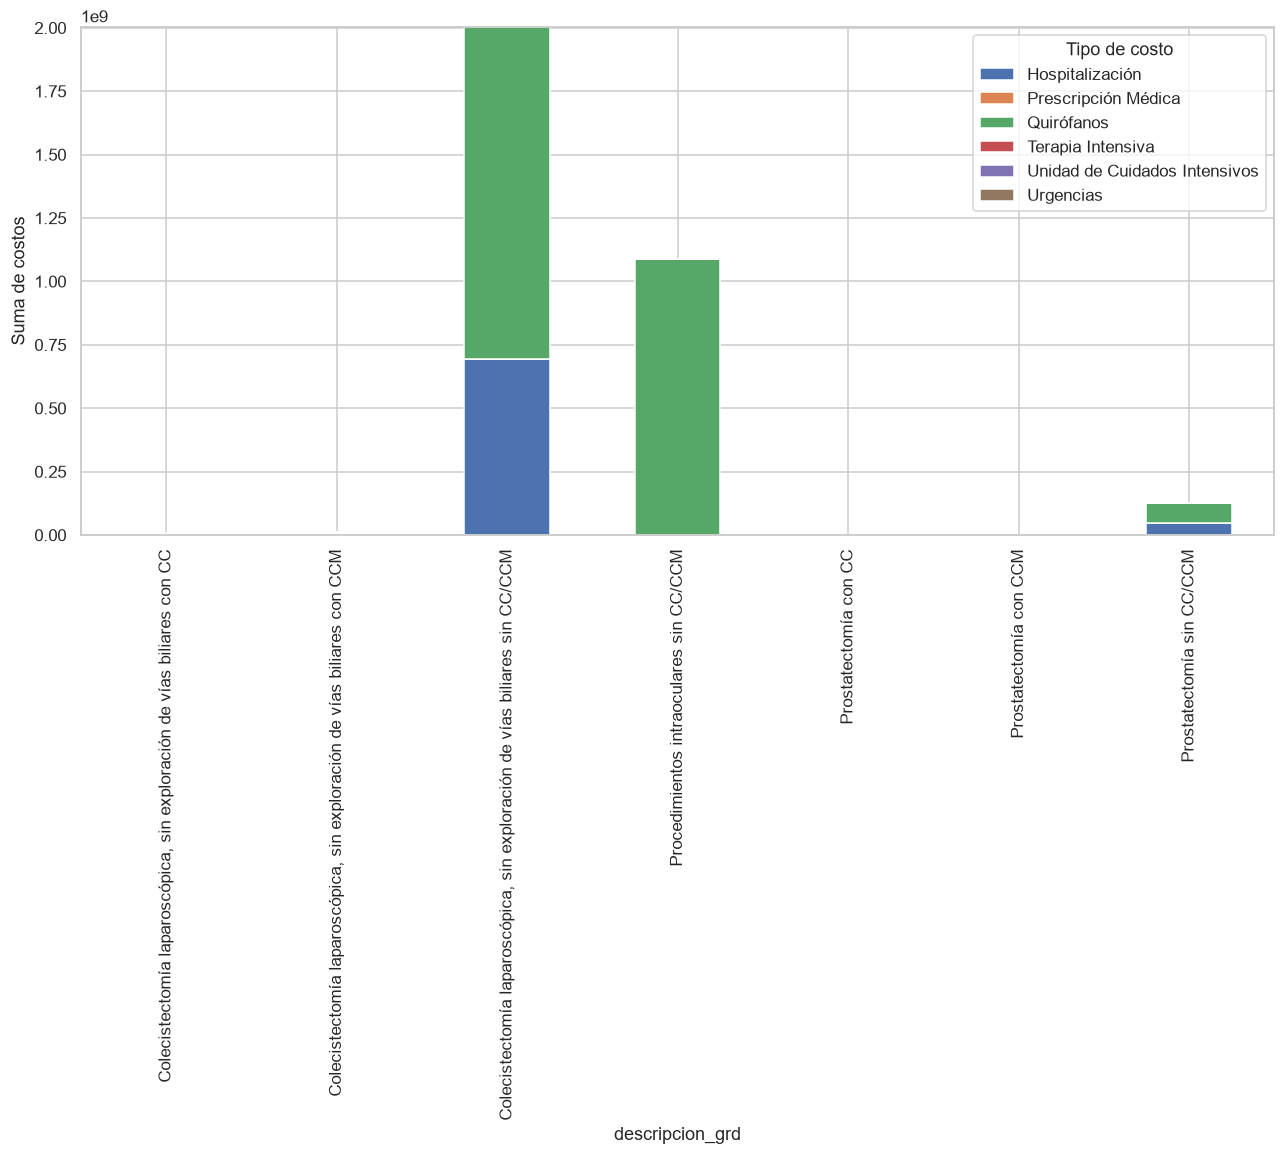

In [60]:
var_x="descripcion_grd"

costos=["Hospitalización", "Prescripción Médica", "Quirófanos", "Terapia Intensiva", "Unidad de Cuidados Intensivos", "Urgencias"]

df_viz=df_final.copy()
df_costos=(df_viz.groupby(var_x)[costos]
           .sum()
           .reset_index()
)

df_costos.set_index(var_x)[costos].plot(
    kind="bar",
    stacked=True,
    figsize=(14,6)
)
plt.xlabel(var_x)
plt.ylabel("Suma de costos")
plt.legend(title="Tipo de costo")
guardar_grafica("08_1_costo_por_grd_centro_costo")
plt.show()

## 8.2 Visualización de costos

**Gráfica:** los mismos costos apilados, ahora por **grupo de edad**.

Gráfica guardada: graficas/reporte\08_2_costos_por_grupo_edad.png


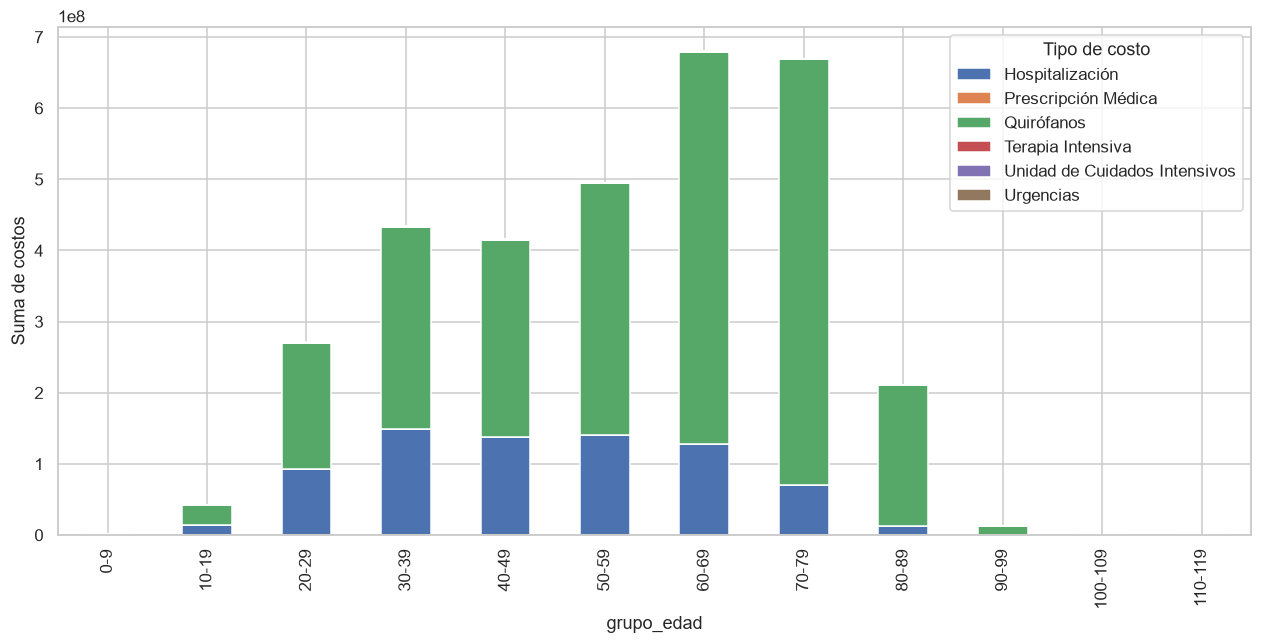

In [61]:
var_x="grupo_edad"

costos=["Hospitalización", "Prescripción Médica", "Quirófanos", "Terapia Intensiva", "Unidad de Cuidados Intensivos", "Urgencias"]

df_viz=df_final.copy()
df_costos=(df_viz.groupby(var_x)[costos]
           .sum()
           .reset_index()
)

df_costos.set_index(var_x)[costos].plot(
    kind="bar",
    stacked=True,
    figsize=(14,6)
)
plt.xlabel(var_x)
plt.ylabel("Suma de costos")
plt.legend(title="Tipo de costo")
guardar_grafica("08_2_costos_por_grupo_edad")
plt.show()

**Costos por grupo de edad para cada GRD.** Para cada GRD se muestra la tabla y la gráfica apilada en **millones de pesos (mdp)**. La columna `Total` suma hospitalización y quirófanos y se imprime su suma general.

,grupo_edad,Hospitalización,Prescripción Médica,Quirófanos,Terapia Intensiva,Unidad de Cuidados Intensivos,Urgencias,Total
0,0-9,0.0,0.0,0.061641,0.0,0.0,0.0,0.061641
1,10-19,0.0,0.0,0.123281,0.0,0.0,0.0,0.123281
2,20-29,0.0,0.0,0.770508,0.0,0.0,0.0,0.770508
3,30-39,0.0,0.0,3.051211,0.0,0.0,0.0,3.051211
4,40-49,0.0,0.0,17.706270,0.0,0.0,0.0,17.706270
5,50-59,0.0,0.0,91.135668,0.0,0.0,0.0,91.135668
6,60-69,0.0,0.0,316.740364,0.0,0.0,0.0,316.740364
7,70-79,0.0,0.0,471.242597,0.0,0.0,0.0,471.242597
8,80-89,0.0,0.0,176.014812,0.0,0.0,0.0,176.014812
9,90-99,0.0,0.0,10.293985,0.0,0.0,0.0,10.293985


1087.340668678051
Gráfica guardada: graficas/reporte\08_2_costos_edad_procedimientos_intraoculares_sin_cc_ccm.png


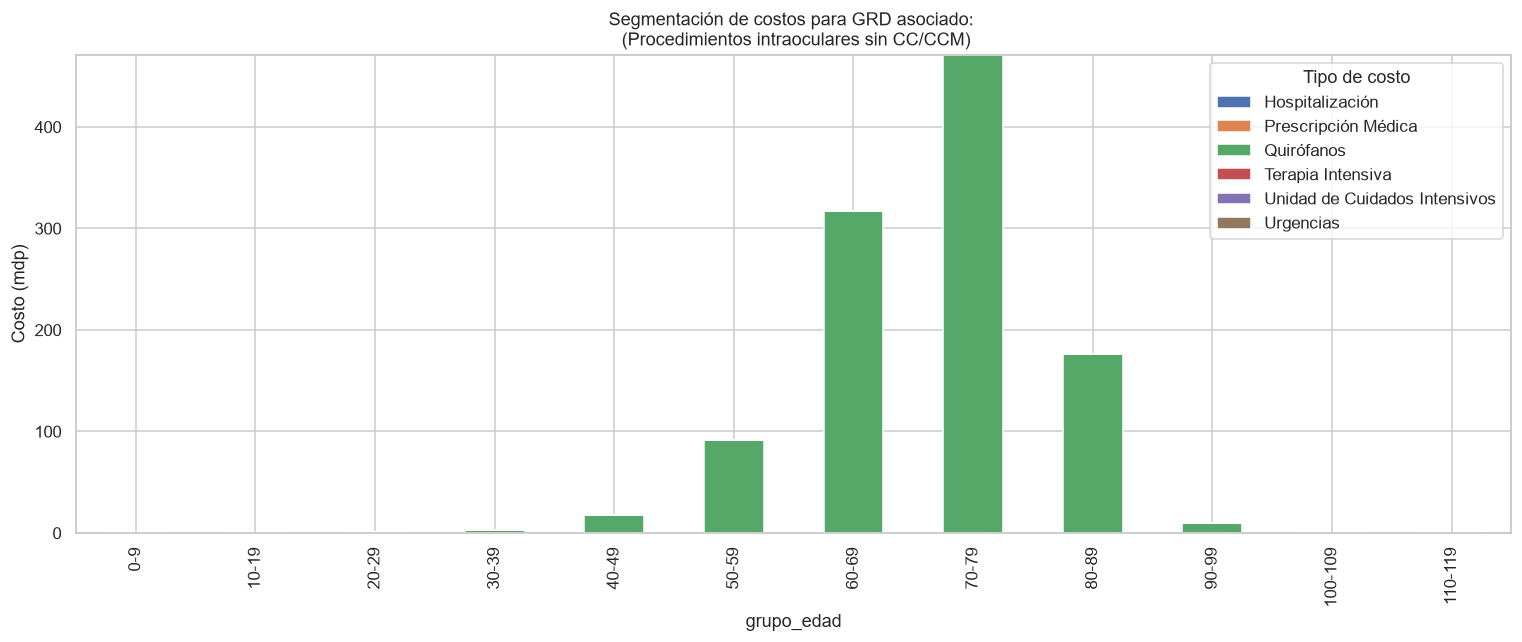

,grupo_edad,Hospitalización,Prescripción Médica,Quirófanos,Terapia Intensiva,Unidad de Cuidados Intensivos,Urgencias,Total
0,0-9,0.422485,0.0,0.798996,0.0,0.0,0.0,1.221481
1,10-19,14.556523,0.0,27.529033,0.0,0.0,0.0,42.085556
2,20-29,93.023481,0.0,175.924322,0.0,0.0,0.0,268.947803
3,30-39,148.080937,0.0,280.047987,0.0,0.0,0.0,428.128924
4,40-49,136.424196,0.0,258.002970,0.0,0.0,0.0,394.427166
5,50-59,133.620433,0.0,252.700544,0.0,0.0,0.0,386.320977
6,60-69,103.316748,0.0,195.390763,0.0,0.0,0.0,298.707510
7,70-79,51.562355,0.0,97.513791,0.0,0.0,0.0,149.076146
8,80-89,11.426295,0.0,21.609201,0.0,0.0,0.0,33.035496
9,90-99,0.652931,0.0,1.234812,0.0,0.0,0.0,1.887743


2003.8388028315728
Gráfica guardada: graficas/reporte\08_2_costos_edad_colecistectomia_laparoscopica_sin_exploracion_de_vias_biliar.png


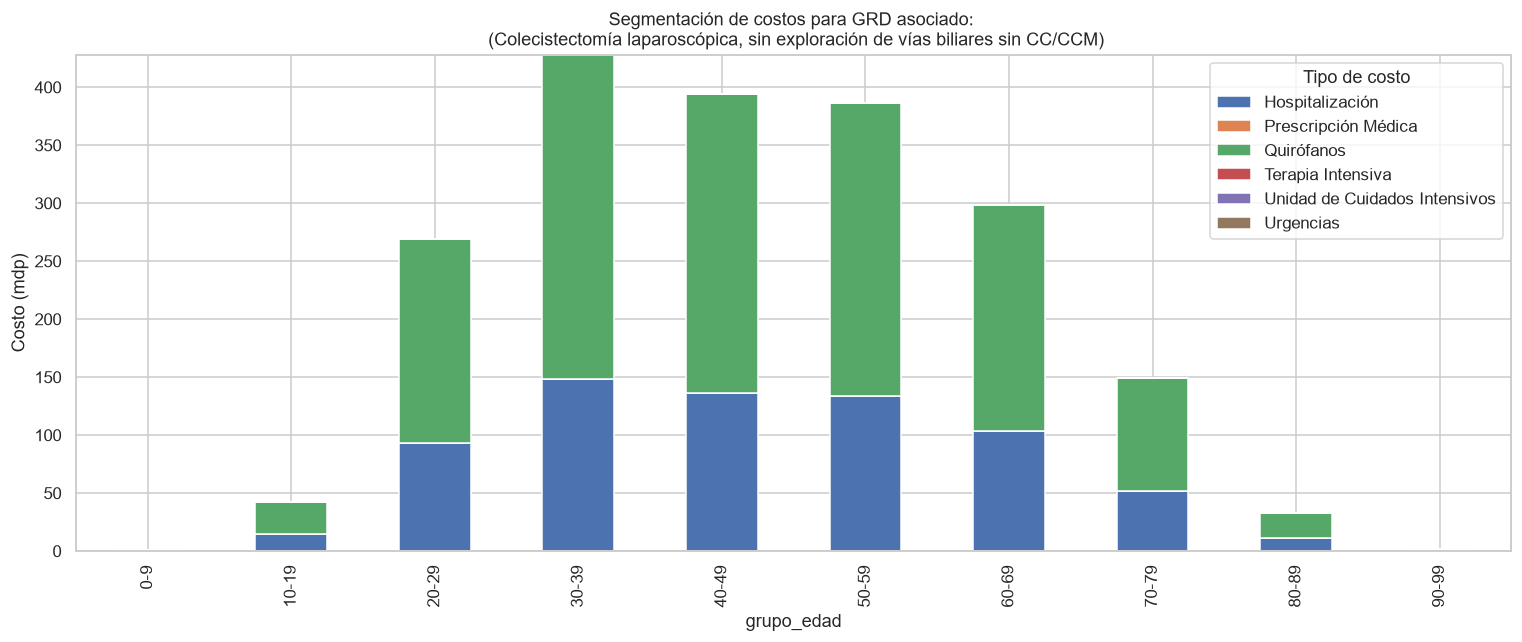

,grupo_edad,Hospitalización,Prescripción Médica,Quirófanos,Terapia Intensiva,Unidad de Cuidados Intensivos,Urgencias,Total
0,40-49,0.337956,0.000411,0.573441,0.0,0.0,0.0,0.911397
1,50-59,5.530194,0.006728,9.383575,0.0,0.0,0.0,14.913769
2,60-69,22.704518,0.027622,38.524788,0.0,0.0,0.0,61.229306
3,70-79,17.450834,0.021230,29.610392,0.0,0.0,0.0,47.061226
4,80-89,0.460849,0.000561,0.781965,0.0,0.0,0.0,1.242814


125.3585113088186
Gráfica guardada: graficas/reporte\08_2_costos_edad_prostatectomia_sin_cc_ccm.png


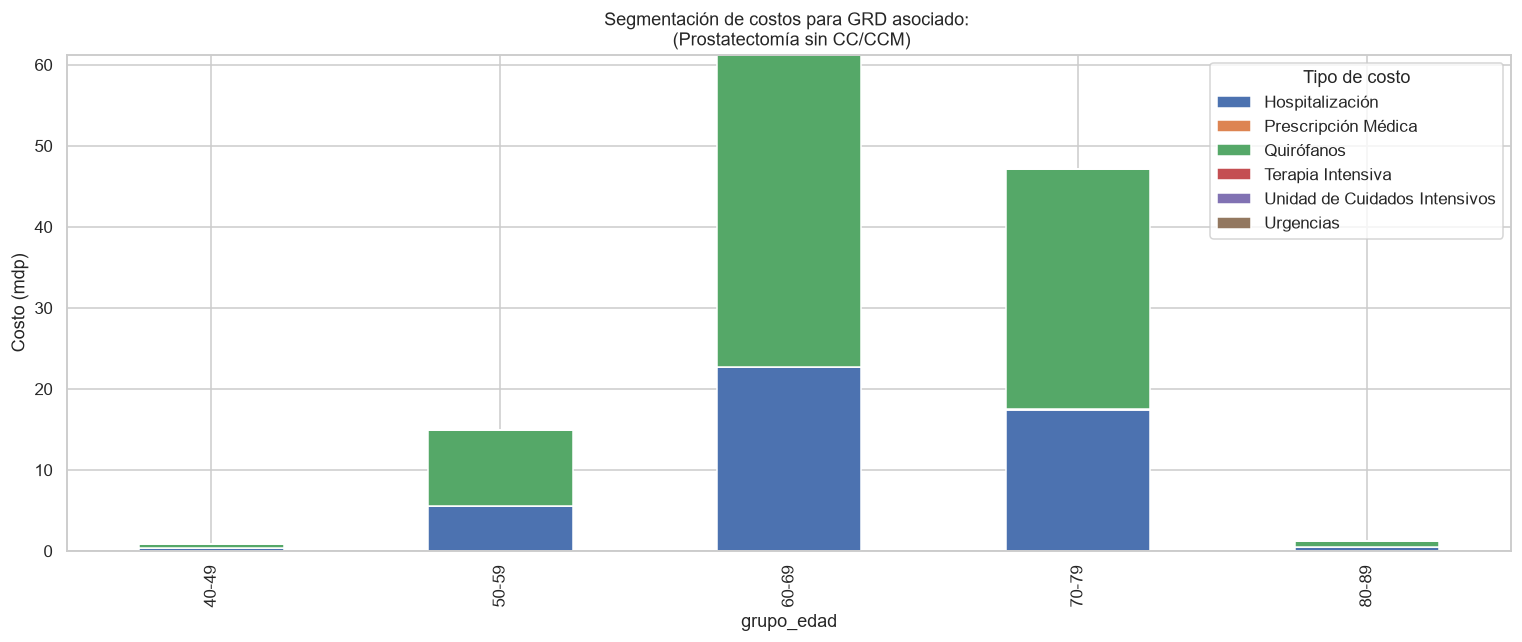

,grupo_edad,Hospitalización,Prescripción Médica,Quirófanos,Terapia Intensiva,Unidad de Cuidados Intensivos,Urgencias,Total
0,10-19,0.038869,0.000006,0.029095,0.0,0.0,0.005217,0.067964
1,20-29,0.427559,0.000065,0.320043,0.0,0.0,0.057389,0.747602
2,30-39,0.932855,0.000142,0.698276,0.0,0.0,0.125213,1.631131
3,40-49,0.699642,0.000107,0.523707,0.0,0.0,0.093910,1.223349
4,50-59,0.505297,0.000077,0.378233,0.0,0.0,0.067824,0.883530
5,60-69,0.388690,0.000059,0.290948,0.0,0.0,0.052172,0.679638
6,70-79,0.155476,0.000024,0.116379,0.0,0.0,0.020869,0.271855
7,80-89,0.077738,0.000012,0.058190,0.0,0.0,0.010434,0.135928


5.640996312404059
Gráfica guardada: graficas/reporte\08_2_costos_edad_colecistectomia_laparoscopica_sin_exploracion_de_vias_biliar.png


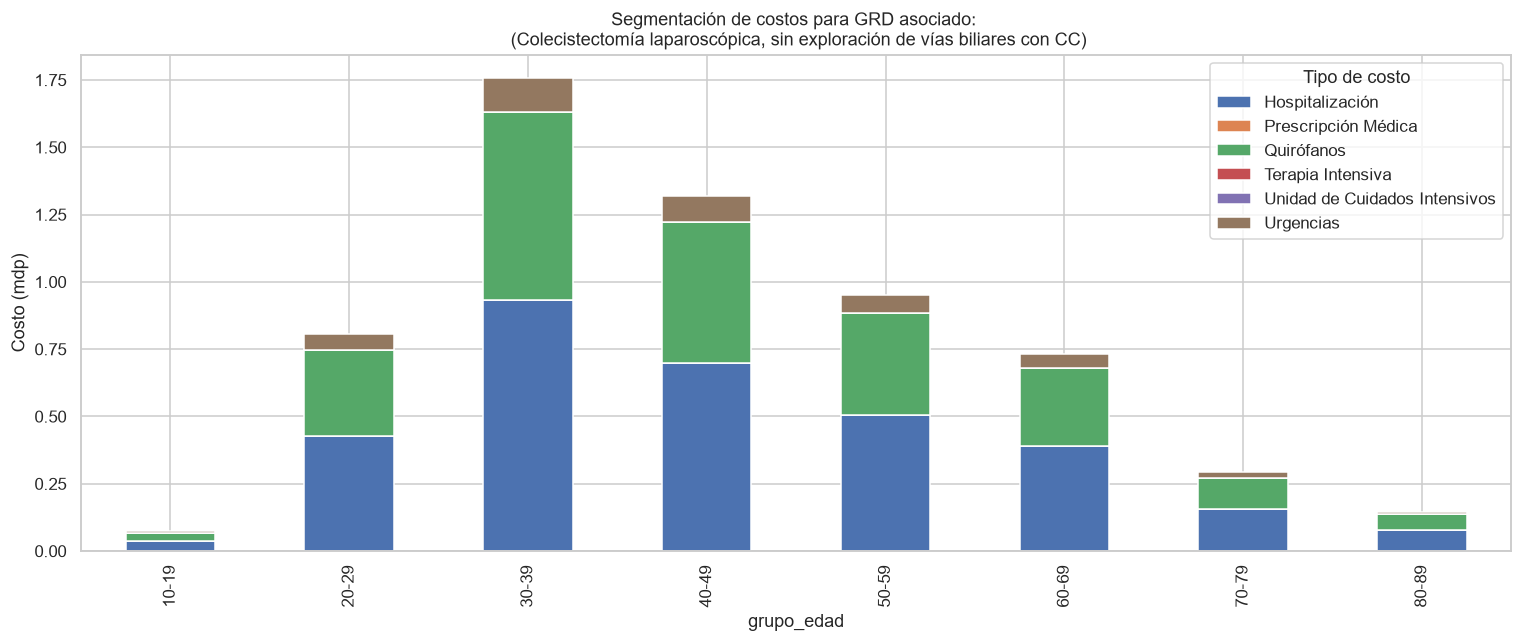

,grupo_edad,Hospitalización,Prescripción Médica,Quirófanos,Terapia Intensiva,Unidad de Cuidados Intensivos,Urgencias,Total
0,20-29,0.053013,0.0,0.036232,0.0,0.048929,0.009639,0.089245
1,30-39,0.477121,0.0,0.326088,0.0,0.440364,0.086748,0.803209
2,40-49,0.636162,0.0,0.434784,0.0,0.587152,0.115663,1.070946
3,50-59,0.795202,0.0,0.543480,0.0,0.733940,0.144579,1.338682
4,60-69,1.007256,0.0,0.688408,0.0,0.929658,0.183134,1.695664
5,70-79,0.636162,0.0,0.434784,0.0,0.587152,0.115663,1.070946
6,80-89,0.318081,0.0,0.217392,0.0,0.293576,0.057832,0.535473
7,90-99,0.053013,0.0,0.036232,0.0,0.048929,0.009639,0.089245


6.6934099097579995
Gráfica guardada: graficas/reporte\08_2_costos_edad_colecistectomia_laparoscopica_sin_exploracion_de_vias_biliar.png


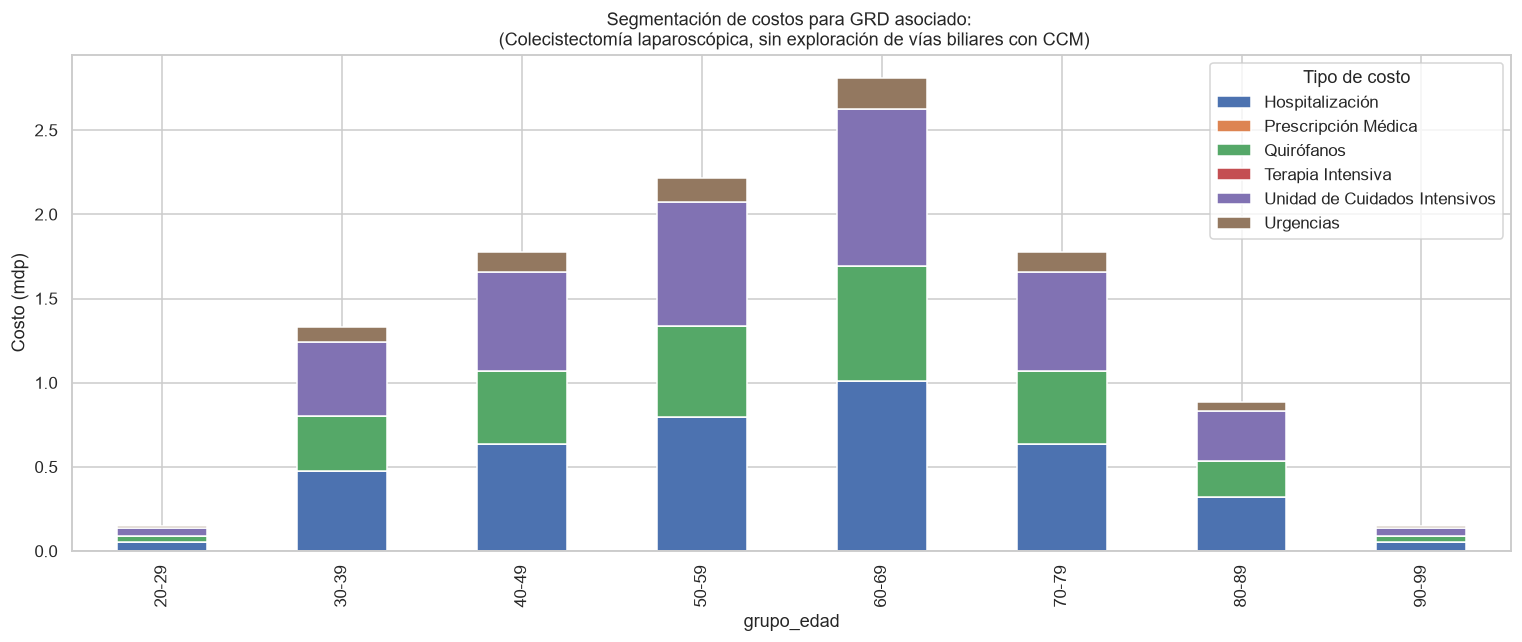

,grupo_edad,Hospitalización,Prescripción Médica,Quirófanos,Terapia Intensiva,Unidad de Cuidados Intensivos,Urgencias,Total
0,70-79,0.110513,0.001986,0.027214,0.0,0.0,0.0,0.137727


0.13772673373928
Gráfica guardada: graficas/reporte\08_2_costos_edad_prostatectomia_con_ccm.png


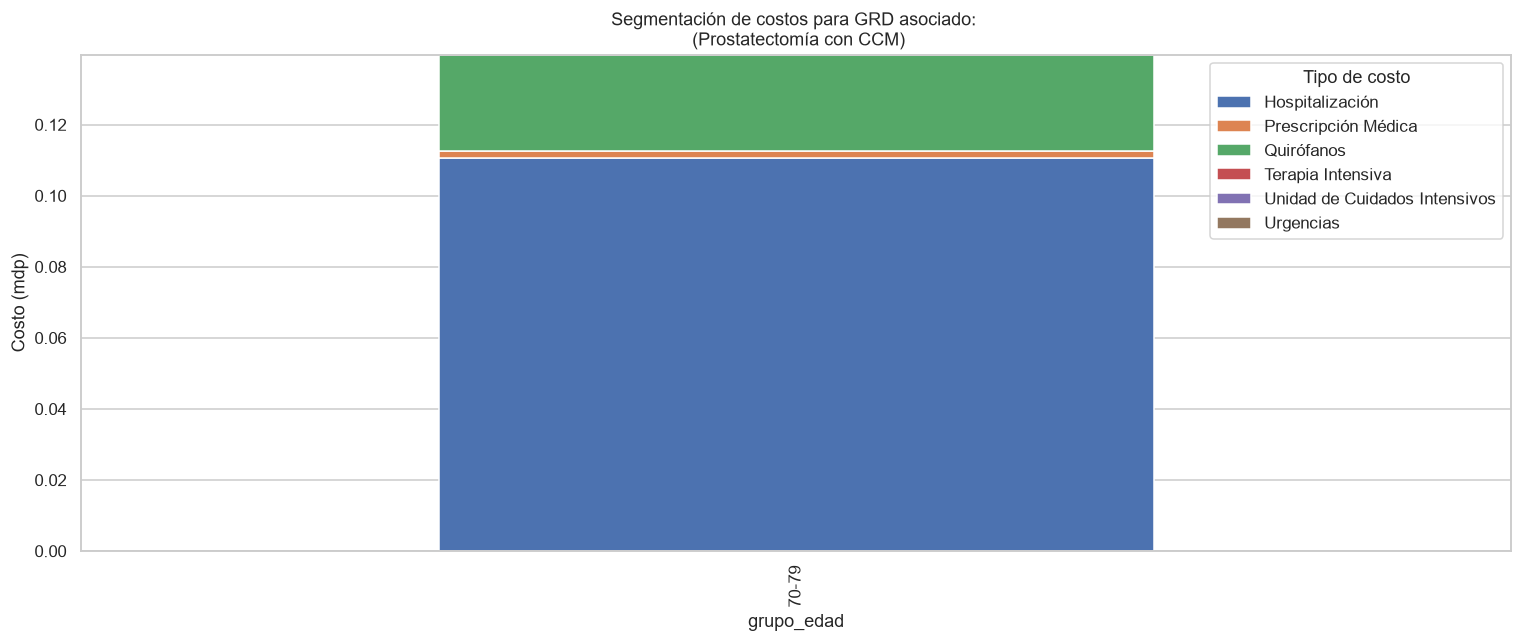

,grupo_edad,Hospitalización,Prescripción Médica,Quirófanos,Terapia Intensiva,Unidad de Cuidados Intensivos,Urgencias,Total
0,60-69,0.070847,0.000421,0.049681,0.0,0.0,0.0,0.120528


0.12052786700728
Gráfica guardada: graficas/reporte\08_2_costos_edad_prostatectomia_con_cc.png


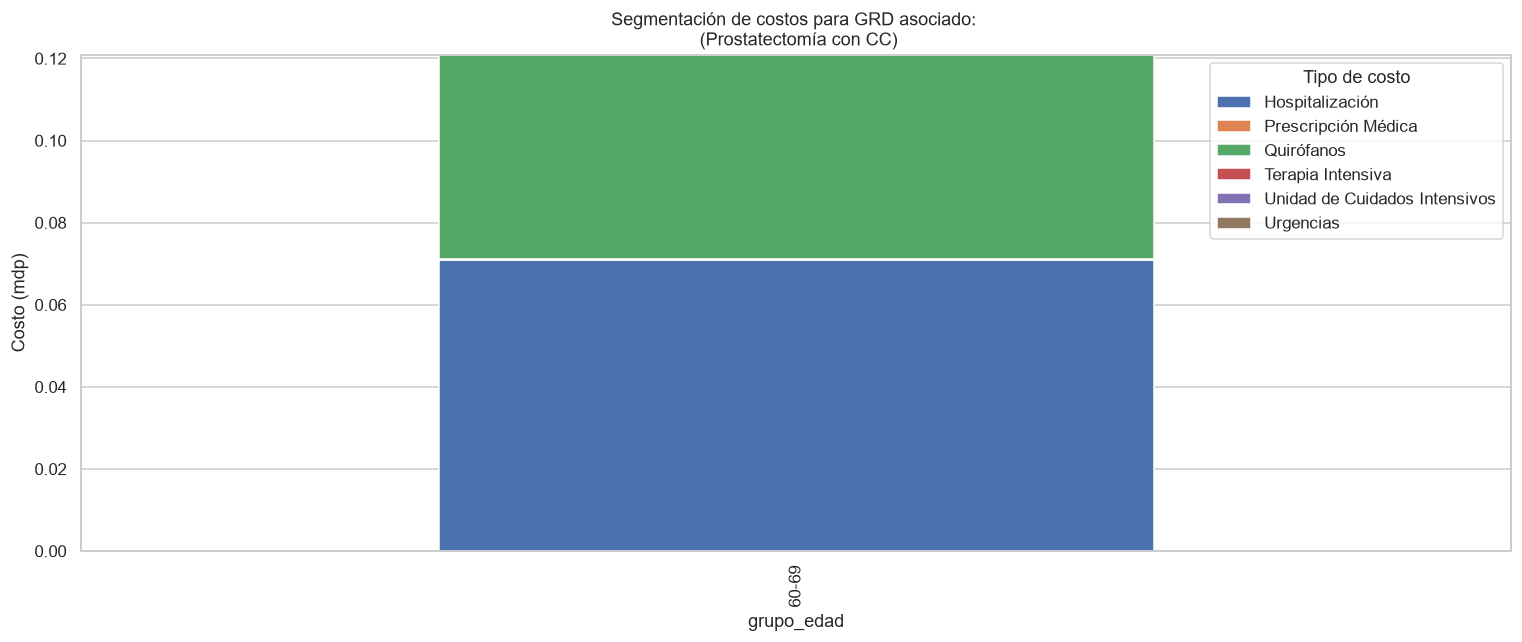

In [62]:
var_x="grupo_edad"

costos=["Hospitalización", "Prescripción Médica", "Quirófanos", "Terapia Intensiva", "Unidad de Cuidados Intensivos", "Urgencias"]


for grd in df_final["descripcion_grd"].unique():
    df_viz=df_final[df_final["descripcion_grd"]==grd].copy()
    df_costos=(df_viz.groupby(var_x)[costos]
            .sum()
            .reset_index()
    )
    
    df_costos[costos]=df_costos[costos]/1e6
    df_costos["Total"]=df_costos["Hospitalización"]+df_costos["Quirófanos"]
    display(df_costos)

    print(df_costos["Total"].sum())

    df_costos.set_index(var_x)[costos].plot(
        kind="bar",
        stacked=True,
        figsize=(14,6)
    )
    plt.xlabel(var_x)
    plt.ylabel(f"Costo (mdp)")
    plt.title(f"Segmentación de costos para GRD asociado: \n ({grd})")
    plt.legend(title="Tipo de costo")
    plt.tight_layout()
    guardar_grafica("08_2_costos_edad_" + nombre_archivo(grd))
    plt.show()

**Costo total por intervención.** Compara los GRD presentes en `df_final` en la tabla de costos original, apilados por centro, y agrega la columna `Total` (hospitalización + quirófanos).

Index(['descripcion_grd', 'Hospitalización', 'Prescripción Médica',
       'Quirófanos', 'Terapia Intensiva', 'Unidad de Cuidados Intensivos',
       'Urgencias'],
      dtype='str', name='centro_cve')
Gráfica guardada: graficas/reporte\08_2_costo_total_por_intervencion.png


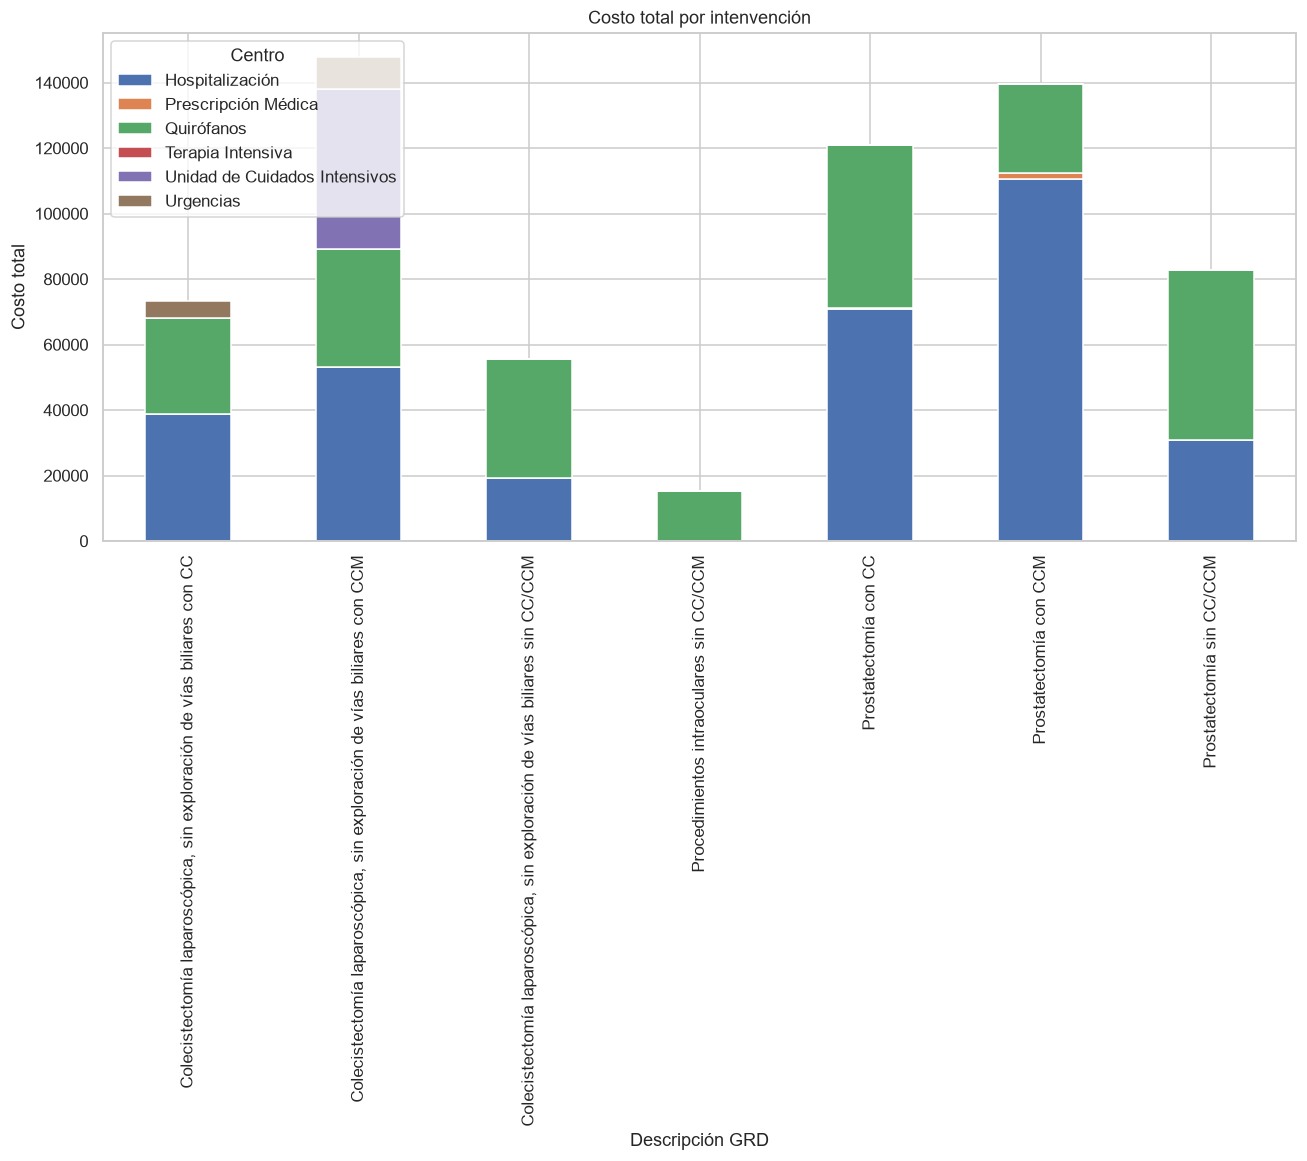

centro_cve,descripcion_grd,Hospitalización,Prescripción Médica,Quirófanos,Terapia Intensiva,Unidad de Cuidados Intensivos,Urgencias,Total
3,"Colecistectomía laparoscópica, sin exploración...",38868.975856,5.920000,29094.835137,0.0,0.000000,5217.197459,67963.810993
4,"Colecistectomía laparoscópica, sin exploración...",53013.481841,0.000000,36231.983622,0.0,48929.350398,9638.618093,89245.465463
5,"Colecistectomía laparoscópica, sin exploración...",19203.856439,0.000000,36317.985650,0.0,0.000000,0.000000,55521.842089
9,Procedimientos intraoculares sin CC/CCM,0.000000,0.000000,15410.156869,0.0,0.000000,0.000000,15410.156869
10,Prostatectomía con CC,70847.014223,420.742789,49680.852784,0.0,0.000000,0.000000,120527.867007
11,Prostatectomía con CCM,110512.927741,1986.062115,27213.805998,0.0,0.000000,0.000000,137726.733739
12,Prostatectomía sin CC/CCM,30723.299369,37.377000,52130.971159,0.0,0.000000,0.000000,82854.270528


In [63]:
df_plot=(
    df_cme_cata_cole_pro.groupby(["descripcion_grd", "centro_cve"])["costo_total"]
    .sum()
    .unstack(fill_value=0)
    .reset_index()
)
lista=df_final["descripcion_grd"].unique()
df_plot=df_plot[df_plot["descripcion_grd"].isin(lista)]
print(df_plot.columns)
#df_costos.set_index(var_x)
df_plot.set_index("descripcion_grd").plot(
    kind="bar",
    stacked=True,
    figsize=(14,6)
)
plt.xlabel("Descripción GRD")
plt.ylabel("Costo total")
plt.title("Costo total por intenvención")
plt.legend(title="Centro")
plt.xticks(rotation=90)
guardar_grafica("08_2_costo_total_por_intervencion")
plt.show()
df_plot["Total"]=df_plot["Hospitalización"]+df_plot["Quirófanos"]
display(df_plot)

## 8.3 Ortopedia

**Tabla de costos ancha de ortopedia.** Los escenarios que no se promedian (1.1.1 → `482_1` y 1.1.2 → `482_2`) se agrupan desde la base raw `df_cme_cde`: suma de `costo_total_2024` por código, escenario y factor, pivoteada a un renglón por escenario. Después se **pega** el renglón del promedio de fijación (`482_3`) calculado en la sección 4.2. El resultado, `costos_wide_orto`, tiene **un renglón por código**.

In [64]:
# ---- C1 ----
# 1) Escenarios que NO se promedian: se agrupan desde la base raw (igual que antes)
numero_escenario = df_cme_cde["escenario"].astype(str).str.strip().str[:5]
es_fijacion_cde = numero_escenario.isin(CLAVES_FIJACION)

costos_orto=(
    df_cme_cde.loc[~es_fijacion_cde]
    .groupby(["codigo_esc", "escenario","factor_produccion"],as_index=False)
    .agg(
        costo_total=("costo_total_2024", "sum")
    )
)

costos_wide_orto=(
    costos_orto
    .pivot(
        index=["codigo_esc", "escenario"],
        columns="factor_produccion",
        values="costo_total"
    )
    .reset_index()
)
costos_wide_orto.columns.name=None

# 2) Se pega el renglón del promedio de fijación (sección 4.2) a la base AGRUPADA
costos_wide_orto = pd.concat([costos_wide_orto, costos_promedio_fijacion_wide], ignore_index=True)

# ---------------- Verificaciones ----------------
factores_orto = [c for c in costos_wide_orto.columns if c not in ("codigo_esc", "escenario")]
if costos_wide_orto["codigo_esc"].duplicated().any():
    raise ValueError("Hay códigos repetidos en costos_wide_orto; el merge duplicaría procedimientos.")

total_por_codigo = costos_wide_orto.set_index(["codigo_esc", "escenario"])[factores_orto].fillna(0).sum(axis=1)
raw_intactos = df_cme_cde.loc[~es_fijacion_cde].groupby("codigo_esc")["costo_total_2024"].sum()
for codigo, total_raw in raw_intactos.items():
    total_ancho = total_por_codigo.xs(codigo, level="codigo_esc").iloc[0]
    print(f"{codigo}: raw {total_raw:,.2f} | tabla ancha {total_ancho:,.2f} | igual: {np.isclose(total_raw, total_ancho)}")
print(f"{CODIGO_PROMEDIO_FIJACION}: promedio {total_por_codigo.xs(CODIGO_PROMEDIO_FIJACION, level='codigo_esc').iloc[0]:,.2f}"
      f" | promedio de los 3 totales {costo_escenario_factor.sum(axis=1).mean():,.2f}")
print()
print("Costo total por escenario (tabla ancha):")
print(total_por_codigo.round(1))
costos_wide_orto["codigo_esc"].value_counts()

482_1: raw 97,564.98 | tabla ancha 97,564.98 | igual: True
482_2: raw 73,624.84 | tabla ancha 73,624.84 | igual: True
482_3: promedio 71,900.35 | promedio de los 3 totales 71,900.35

Costo total por escenario (tabla ancha):
codigo_esc  escenario                                                              
482_1       1.1.1 Paciente con fractura de cadera y sustitución total de cadera.       97565.0
482_2       1.1.2 Paciente con fractura de cadera y sustitución parcial de cadera.     73624.8
482_3       1.1.6 Promedio de fijación de fractura de cadera (1.1.3, 1.1.4 y 1.1.5)    71900.3
dtype: float64


codigo_esc
482_1    1
482_2    1
482_3    1
Name: count, dtype: int64

Comprobación de que los códigos de ortopedia de la demanda (`df_cme`) tienen exactamente un costo en `costos_wide_orto`.

In [65]:
# ---- C2 ----
codigos_orto_demanda = sorted(df_cme.loc[df_cme["grd_cme"].astype(str).str.startswith("482"), "grd_cme"].astype(str).unique())
codigos_costos = sorted(costos_wide_orto["codigo_esc"].astype(str).unique())
print("Códigos de ortopedia en df_cme:      ", codigos_orto_demanda)
print("Códigos en costos_wide_orto:         ", codigos_costos)
print("Códigos de demanda SIN costo:        ", sorted(set(codigos_orto_demanda) - set(codigos_costos)))
print("Códigos de costo SIN demanda:        ", sorted(set(codigos_costos) - set(codigos_orto_demanda)))
set(codigos_orto_demanda) == set(codigos_costos)

Códigos de ortopedia en df_cme:       ['482_1', '482_2', '482_3']
Códigos en costos_wide_orto:          ['482_1', '482_2', '482_3']
Códigos de demanda SIN costo:         []
Códigos de costo SIN demanda:         []


True

**Integración demanda × costos (ortopedia).** Une `df_cme` con `costos_wide_orto` por código de GRD para obtener `df_final_orto`. Como ambas tablas tienen la columna `escenario`, el cruce produce `escenario_x` (de la demanda) y `escenario_y` (de la tabla de costos). `validate="many_to_one"` garantiza que cada procedimiento reciba **un solo** costo.

In [66]:
# ---- C3 ----
df_final_orto=df_cme.merge(
    costos_wide_orto,
    left_on="grd_cme",
    right_on="codigo_esc",
    how="inner",
    validate="many_to_one",      # error si un código tuviera más de un renglón de costos
)

# Cada procedimiento de ortopedia debe aparecer una sola vez
n_demanda_orto = int(df_cme["grd_cme"].isin(costos_wide_orto["codigo_esc"]).sum())
print(f"Procedimientos de ortopedia en df_cme: {n_demanda_orto:,} | renglones en df_final_orto: {len(df_final_orto):,}")
if len(df_final_orto) != n_demanda_orto:
    raise ValueError("df_final_orto no tiene un renglón por procedimiento; revise costos_wide_orto.")
df_final_orto.groupby(["grd_cme", "escenario_x", "escenario_y"]).size().rename("procedimientos")

Procedimientos de ortopedia en df_cme: 21,711 | renglones en df_final_orto: 21,711


grd_cme  escenario_x                                             escenario_y                                                            
482_1    Sustitucion total de cadera                             1.1.1 Paciente con fractura de cadera y sustitución total de cadera.        5371
482_2    Sustitucion parcial de cadera                           1.1.2 Paciente con fractura de cadera y sustitución parcial de cadera.      2612
482_3    Fijacion de fractura de cadera con tornillos canulados  1.1.6 Promedio de fijación de fractura de cadera (1.1.3, 1.1.4 y 1.1.5)    13728
Name: procedimientos, dtype: int64

Vista de `df_final_orto`.

In [67]:
df_final_orto

,cve_ingreso,fec_solicitud,fec_programacion_original,fec_realizacion,des_especialidad,ind_sexo,num_edad,cve_proc_prin_intervencion,des_proc_prin_intervencion,cve_cie_10_principal,...,codigo_esc,escenario_y,Banco de sangre,Capacidad instalada,Consumibles médicos,Estudios de gabinete,Estudios de laboratorio,Gases medicinales,Medicamentos,Servicios médicos indirectos
0,Urgente,2024-04-22,2024-04-24 09:30:00,2024-04-24 09:30:00,Traumatología y ortopedia,M,65.0,7935,Reduccion abierta de fractura con fijacion int...,S721,...,482_3,1.1.6 Promedio de fijación de fractura de cade...,1811.4,50743.18,14036.975164,2093.0,1205.997736,121.477204,1408.394835,479.922057
1,Urgente,2026-03-09,2026-03-11 14:30:00,2026-03-11 15:40:00,Traumatología y ortopedia,F,79.0,8151,Sustitucion o reemplazo total de cadera,S720,...,482_1,1.1.1 Paciente con fractura de cadera y sustit...,1811.4,56369.00,33844.243446,2093.0,1205.997736,124.455630,1636.961901,479.922057
2,Urgente,2026-04-27,2026-04-28 10:00:00,2026-04-28 11:30:00,Traumatología y ortopedia,M,75.0,8151,Sustitucion o reemplazo total de cadera,S720,...,482_1,1.1.1 Paciente con fractura de cadera y sustit...,1811.4,56369.00,33844.243446,2093.0,1205.997736,124.455630,1636.961901,479.922057
3,Urgente,2026-07-27,2026-07-31 14:05:00,2026-08-17 09:25:00,Traumatología y ortopedia,M,87.0,7935,Reduccion abierta de fractura con fijacion int...,S720,...,482_3,1.1.6 Promedio de fijación de fractura de cade...,1811.4,50743.18,14036.975164,2093.0,1205.997736,121.477204,1408.394835,479.922057
4,Urgente,2025-03-26,2025-03-29 10:00:00,2025-03-29 12:00:00,Traumatología y ortopedia,M,93.0,7935,Reduccion abierta de fractura con fijacion int...,S720,...,482_3,1.1.6 Promedio de fijación de fractura de cade...,1811.4,50743.18,14036.975164,2093.0,1205.997736,121.477204,1408.394835,479.922057
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
21706,Urgente,2024-06-10,2024-06-18 09:05:00,2024-06-18 09:05:00,Traumatología y ortopedia,F,89.0,7935,Reduccion abierta de fractura con fijacion int...,S721,...,482_3,1.1.6 Promedio de fijación de fractura de cade...,1811.4,50743.18,14036.975164,2093.0,1205.997736,121.477204,1408.394835,479.922057
21707,Urgente,2025-06-16,2025-07-02 14:00:00,2025-07-02 15:21:00,Traumatología y ortopedia,F,60.0,7935,Reduccion abierta de fractura con fijacion int...,S720,...,482_3,1.1.6 Promedio de fijación de fractura de cade...,1811.4,50743.18,14036.975164,2093.0,1205.997736,121.477204,1408.394835,479.922057
21708,Urgente,2024-11-21,2024-11-23 11:00:00,2024-11-23 16:45:00,Traumatología y ortopedia,F,82.0,7935,Reduccion abierta de fractura con fijacion int...,S720,...,482_3,1.1.6 Promedio de fijación de fractura de cade...,1811.4,50743.18,14036.975164,2093.0,1205.997736,121.477204,1408.394835,479.922057
21709,Urgente,2025-05-27,2025-05-27 23:30:00,2025-05-27 23:30:00,Miembro Pélvico,F,94.0,7935,Reduccion abierta de fractura con fijacion int...,S720,...,482_3,1.1.6 Promedio de fijación de fractura de cade...,1811.4,50743.18,14036.975164,2093.0,1205.997736,121.477204,1408.394835,479.922057


Frecuencia de escenarios según la tabla de costos.

In [68]:
df_final_orto["escenario_y"].value_counts()

escenario_y
1.1.6 Promedio de fijación de fractura de cadera (1.1.3, 1.1.4 y 1.1.5)    13728
1.1.1 Paciente con fractura de cadera y sustitución total de cadera.        5371
1.1.2 Paciente con fractura de cadera y sustitución parcial de cadera.      2612
Name: count, dtype: int64

**Gráfica:** costo por escenario apilado por factor de producción (banco de sangre, capacidad instalada, consumibles médicos, estudios de gabinete y de laboratorio, gases medicinales, medicamentos y servicios médicos indirectos).

Gráfica guardada: graficas/reporte\08_3_ortopedia_costo_por_factor.png


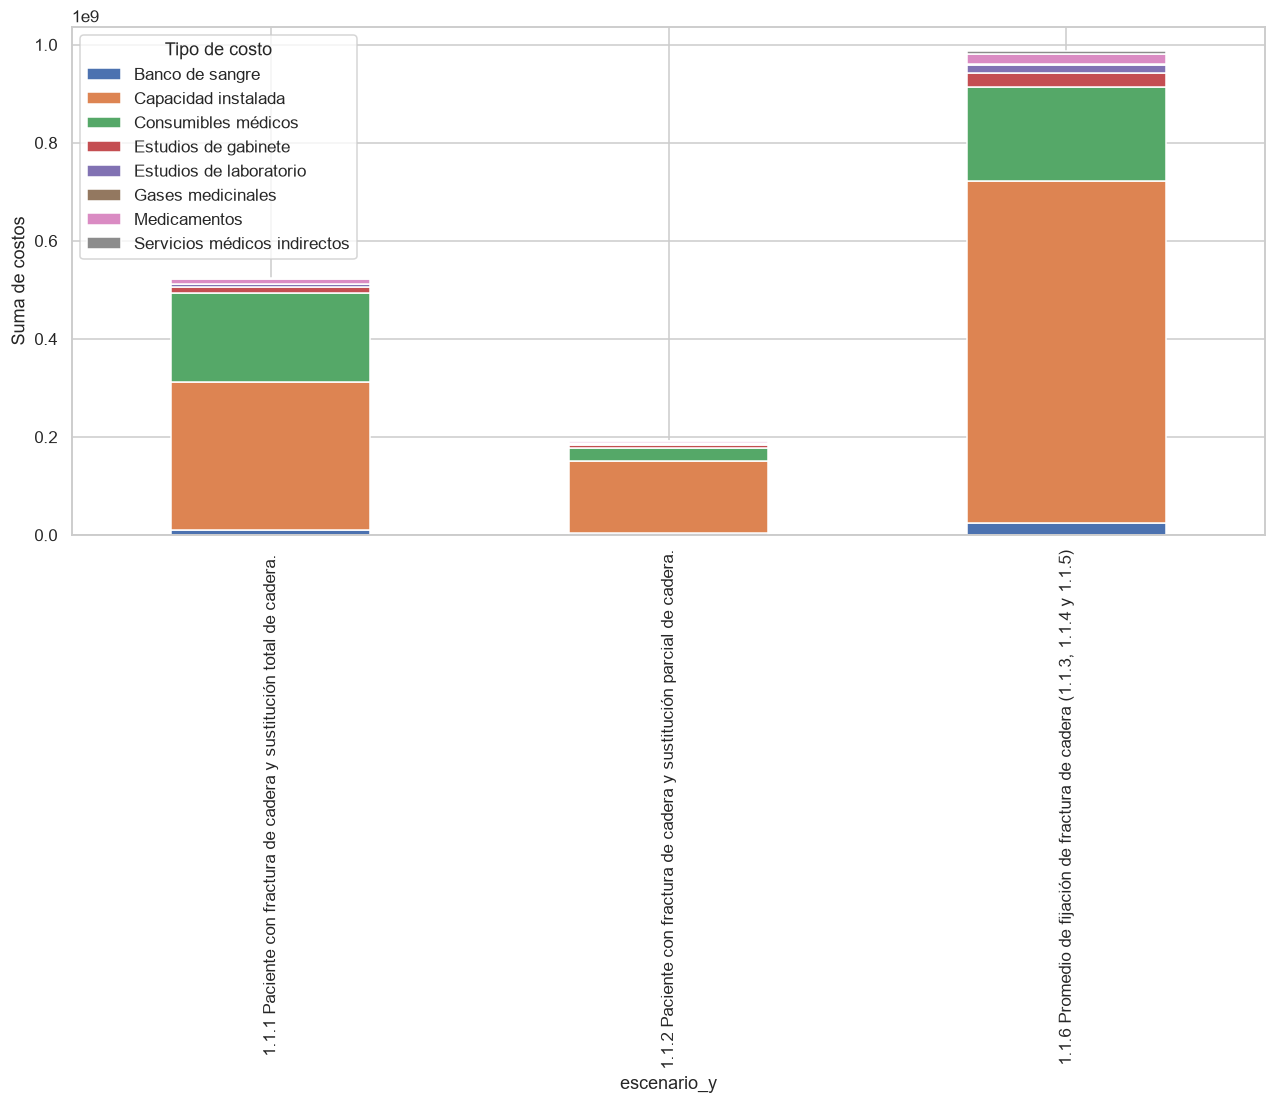

In [69]:
var_x="escenario_y"

							
costos=["Banco de sangre", "Capacidad instalada", "Consumibles médicos", "Estudios de gabinete", "Estudios de laboratorio", "Gases medicinales",
		"Medicamentos", "Servicios médicos indirectos"]

df_viz=df_final_orto.copy()
df_costos=(df_viz.groupby(var_x)[costos]
           .sum()
           .reset_index()
)

df_costos.set_index(var_x)[costos].plot(
    kind="bar",
    stacked=True,
    figsize=(14,6)
)
plt.xlabel(var_x)
plt.ylabel("Suma de costos")
plt.legend(title="Tipo de costo")
guardar_grafica("08_3_ortopedia_costo_por_factor")
plt.show()

**Gráfica:** los mismos factores de producción por grupo de edad.

Gráfica guardada: graficas/reporte\08_3_ortopedia_costo_por_edad.png


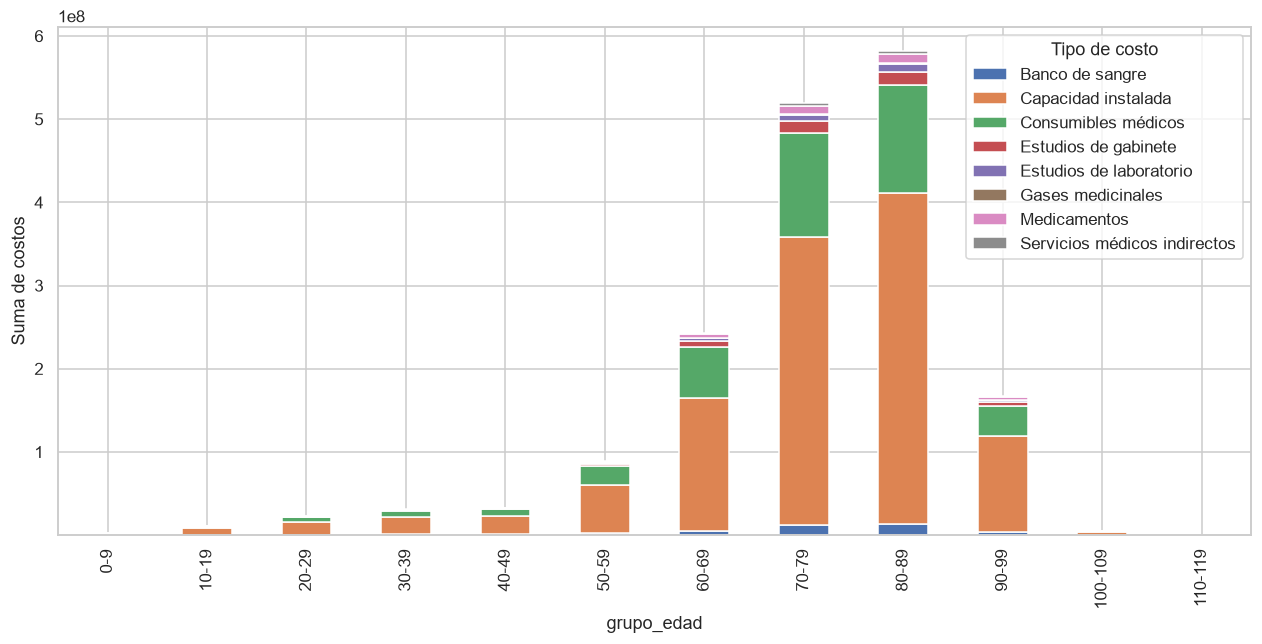

In [70]:
var_x="grupo_edad"


df_viz=df_final_orto.copy()
df_costos=(df_viz.groupby(var_x)[costos]
           .sum()
           .reset_index()
)

df_costos.set_index(var_x)[costos].plot(
    kind="bar",
    stacked=True,
    figsize=(14,6)
)
plt.xlabel(var_x)
plt.ylabel("Suma de costos")
plt.legend(title="Tipo de costo")
guardar_grafica("08_3_ortopedia_costo_por_edad")
plt.show()

**Costos por grupo de edad para cada escenario** (en mdp). La columna `Total` suma todos los factores de producción.

,grupo_edad,Banco de sangre,Capacidad instalada,Consumibles médicos,Estudios de gabinete,Estudios de laboratorio,Gases medicinales,Medicamentos,Servicios médicos indirectos,Total
0,0-9,0.052531,1.471552,0.407072,0.060697,0.034974,0.003523,0.040843,0.013918,2.085110
1,10-19,0.271710,7.611477,2.105546,0.313950,0.180900,0.018222,0.211259,0.071988,10.785052
2,20-29,0.467341,13.091740,3.621540,0.539994,0.311147,0.031341,0.363366,0.123820,18.550290
3,30-39,0.505381,14.157347,3.916316,0.583947,0.336473,0.033892,0.392942,0.133898,20.060197
4,40-49,0.536174,15.019981,4.154945,0.619528,0.356975,0.035957,0.416885,0.142057,21.282503
5,50-59,1.206392,33.794958,9.348625,1.393938,0.803194,0.080904,0.937991,0.319628,47.885631
6,60-69,3.111985,87.176783,24.115523,3.595774,2.071904,0.208698,2.419622,0.824506,123.524796
7,70-79,7.290885,204.241299,56.498825,8.424325,4.854141,0.488946,5.668789,1.931686,289.398897
8,80-89,8.741816,244.886587,67.742442,10.100818,5.820145,0.586249,6.796913,2.316104,346.991075
9,90-99,2.606605,73.019436,20.199207,3.011827,1.735431,0.174806,2.026680,0.690608,103.464599


987.0479635572441
Gráfica guardada: graficas/reporte\08_3_ortopedia_costos_edad_fijacion_de_fractura_de_cadera_con_tornillos_canulados.png


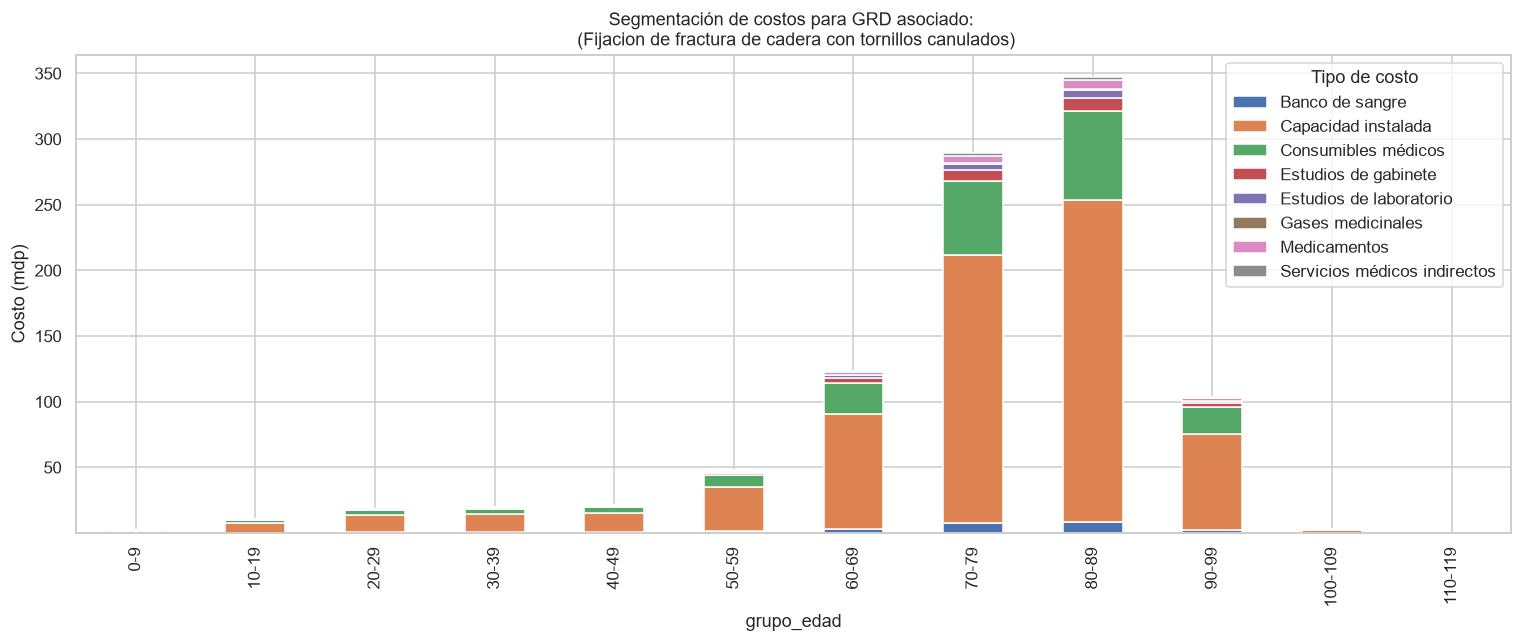

,grupo_edad,Banco de sangre,Capacidad instalada,Consumibles médicos,Estudios de gabinete,Estudios de laboratorio,Gases medicinales,Medicamentos,Servicios médicos indirectos,Total
0,20-29,0.074267,2.311129,1.387614,0.085813,0.049446,0.005103,0.067115,0.019677,4.000164
1,30-39,0.186574,5.806007,3.485957,0.215579,0.124218,0.012819,0.168607,0.049432,10.049193
2,40-49,0.197443,6.144221,3.689023,0.228137,0.131454,0.013566,0.178429,0.052312,10.634583
3,50-59,0.699200,21.758434,13.063878,0.807898,0.465515,0.048040,0.631867,0.185250,37.660083
4,60-69,1.945444,60.540306,36.348717,2.247882,1.295242,0.133665,1.758097,0.515436,104.784789
5,70-79,3.284068,102.196997,61.359613,3.794609,2.186474,0.225638,2.967812,0.870099,176.885310
6,80-89,2.735214,85.117190,51.104808,3.160430,1.821057,0.187928,2.471812,0.724682,147.323121
7,90-99,0.586894,18.263556,10.965535,0.678132,0.390743,0.040324,0.530376,0.155495,31.611054
8,100-109,0.019925,0.620059,0.372287,0.023023,0.013266,0.001369,0.018007,0.005279,1.073215


524.0215117153477
Gráfica guardada: graficas/reporte\08_3_ortopedia_costos_edad_sustitucion_total_de_cadera.png


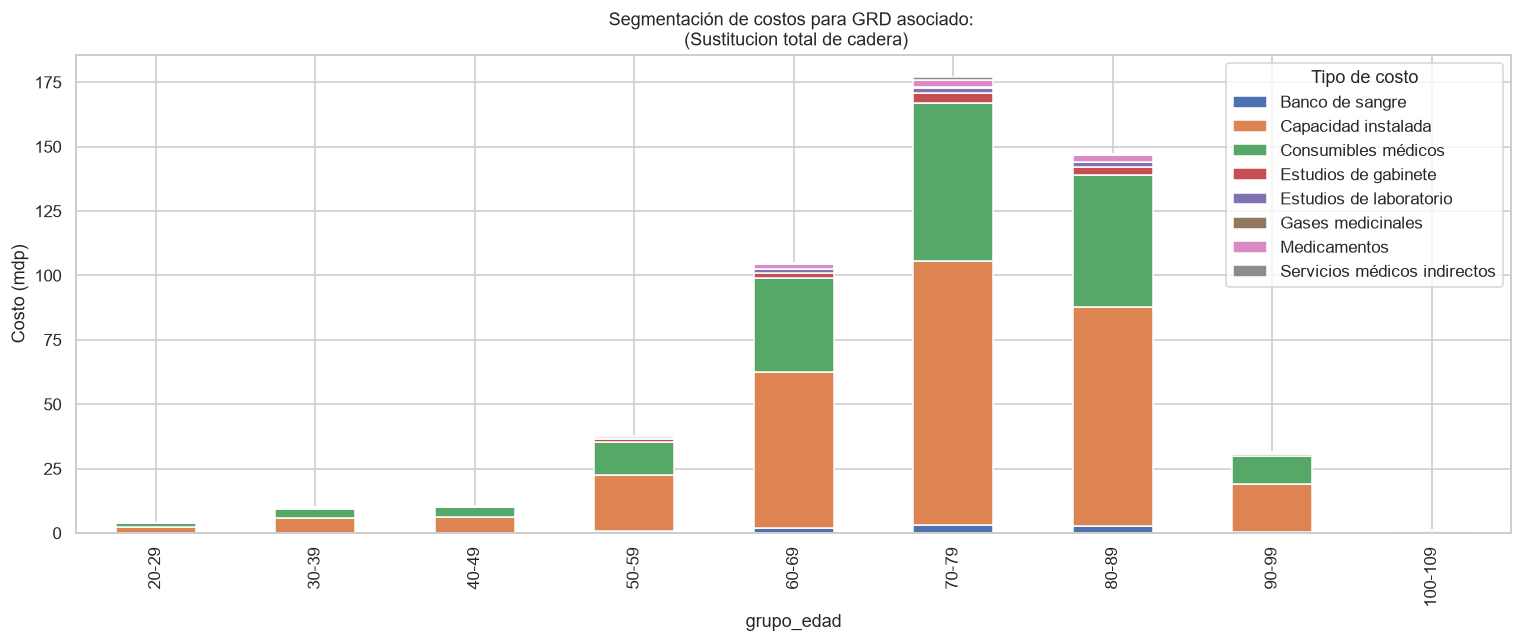

,grupo_edad,Banco de sangre,Capacidad instalada,Consumibles médicos,Estudios de gabinete,Estudios de laboratorio,Gases medicinales,Medicamentos,Servicios médicos indirectos,Total
0,20-29,0.005434,0.169107,0.029682,0.006279,0.003618,0.000373,0.004941,0.001440,0.220875
1,30-39,0.018114,0.563690,0.098942,0.020930,0.012060,0.001245,0.016469,0.004799,0.736248
2,40-49,0.025360,0.789166,0.138518,0.029302,0.016884,0.001742,0.023057,0.006719,1.030748
3,50-59,0.070645,2.198391,0.385872,0.081627,0.047034,0.004854,0.064229,0.018717,2.871369
4,60-69,0.356846,11.104693,1.949150,0.412321,0.237582,0.024518,0.324440,0.094545,14.504094
5,70-79,1.300585,40.472942,7.104007,1.502774,0.865906,0.089359,1.182478,0.344584,52.862636
6,80-89,2.155566,67.079110,11.774051,2.490670,1.435137,0.148102,1.959817,0.571107,87.613560
7,90-99,0.775279,24.125932,4.234701,0.895804,0.516167,0.053267,0.704875,0.205407,31.511432
8,100-109,0.023548,0.732797,0.128624,0.027209,0.015678,0.001618,0.021410,0.006239,0.957123


192.30808393436325
Gráfica guardada: graficas/reporte\08_3_ortopedia_costos_edad_sustitucion_parcial_de_cadera.png


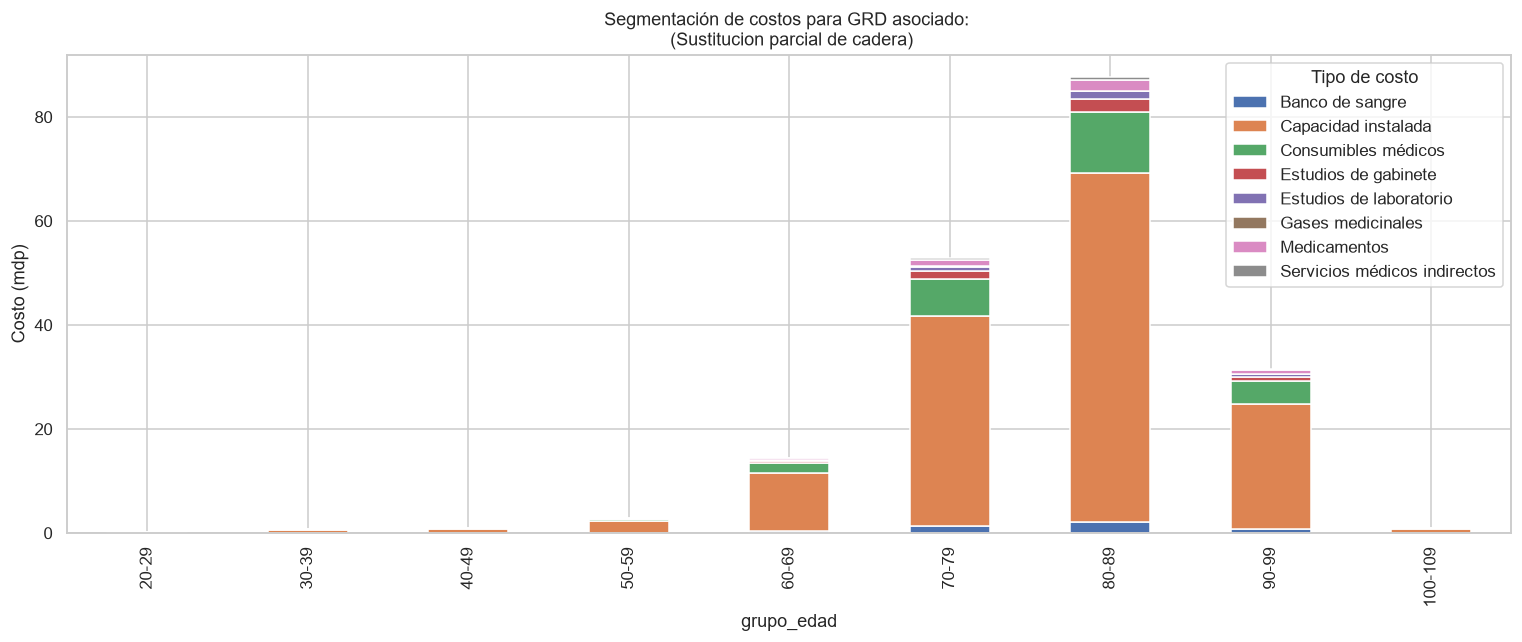

In [71]:
for grd in df_final_orto["escenario_x"].unique():
    df_viz=df_final_orto[df_final_orto["escenario_x"]==grd].copy()
    df_costos=(df_viz.groupby(var_x)[costos]
            .sum()
            .reset_index()
    )
    
    df_costos[costos]=df_costos[costos]/1e6
    df_costos["Total"]=0
    for costo in costos:
        df_costos["Total"]+=df_costos[costo]

    display(df_costos)

    print(df_costos["Total"].sum())

    df_costos.set_index(var_x)[costos].plot(
        kind="bar",
        stacked=True,
        figsize=(14,6)
    )
    plt.xlabel(var_x)
    plt.ylabel(f"Costo (mdp)")
    plt.title(f"Segmentación de costos para GRD asociado: \n ({grd})")
    plt.legend(title="Tipo de costo")
    plt.tight_layout()
    guardar_grafica("08_3_ortopedia_costos_edad_" + nombre_archivo(grd))
    plt.show()

# 9. Caracterización de la demanda

## 9.1 Diagramas de Sankey: catarata, colecistectomía y prostatectomía

GRD que se graficarán.

In [72]:
for grd in df_final["descripcion_grd"].unique():
    print(grd)

Procedimientos intraoculares sin CC/CCM
Colecistectomía laparoscópica, sin exploración de vías biliares sin CC/CCM
Prostatectomía sin CC/CCM
Colecistectomía laparoscópica, sin exploración de vías biliares con CC
Colecistectomía laparoscópica, sin exploración de vías biliares con CCM
Prostatectomía con CCM
Prostatectomía con CC


**Diagrama de Sankey por GRD.** Para cada GRD se representa el recorrido:

**grupo de edad → tipo de ingreso → diagnóstico principal → sexo**

Para que el diagrama sea legible se conservan solo los **5 diagnósticos principales** de cada GRD, y la celda imprime qué porcentaje de las observaciones capturan. Los nombres de diagnóstico se truncan a 50 caracteres. El grosor de cada flujo es el número de procedimientos. Como se itera sobre los GRD, se genera un diagrama por cada uno.

In [73]:
# Visualización  por especialidad
import plotly.graph_objects as go

for grds in df_final["descripcion_grd"].unique():
    grd_sel= grds
    sexo="sexo"
    ingreso="cve_ingreso"
    diag="des_cie_principal"
    edad="grupo_edad"
    grd="descripcion_grd"
    rank=5


    df_sankey=df_final.loc[df_final[grd].eq(grd_sel)].copy()
    val_total_esp=len(df_sankey)


    top_diag=(
        df_sankey #acotar procedimientos
        .groupby([grd,diag])
        .size()
        .reset_index(name="n")
        .sort_values([grd,"n"],ascending=[True,False]
                    )
    )

    top_diag["rank_diag"]=(
        top_diag
        .groupby(grd)
        .cumcount()+1)

    top_diag=top_diag.loc[top_diag["rank_diag"]<=rank]
    print(f"Utilizando el top {rank} de diagnosticos se captura el {round(float(top_diag["n"].sum()/val_total_esp*100),2)} para el GRD {grd}")
    ################################################################

    #>fILTRO Y FLUJOS

    ################################################################

    df_sankey=df_sankey.merge(
        top_diag[[grd,diag]],
        on=[grd,diag],
        how="inner"
    )

    #Edad proc
    flujo_1=(
        df_sankey
        .groupby([edad,ingreso],observed=True)
        .size()
        .reset_index(name="value")
    )
    flujo_1["source"]="Edad incial: "+ flujo_1[edad].astype(str)
    flujo_1["target"]="Ingreso: "+ flujo_1[ingreso].astype(str)


    df_sankey["diag_corto"]=(
        df_sankey[diag]
        .astype(str)
        .str.slice(0,50)
        .str.strip()
    )


    #proc diag

    flujo_2=(
        df_sankey
        .groupby([ingreso,"diag_corto"],observed=True)
        .size()
        .reset_index(name="value")
    )
    flujo_2["source"]="Ingreso: "+ flujo_2[ingreso].astype(str)
    flujo_2["target"]="Dx: "+ flujo_2["diag_corto"].astype(str)

    #diag edad

    flujo_3=(
        df_sankey
        .groupby(["diag_corto", sexo],observed=True)
        .size()
        .reset_index(name="value")
    )
    flujo_3["source"]="Dx: "+ flujo_3["diag_corto"].astype(str)
    flujo_3["target"]="Sexo: "+ flujo_3[sexo].astype(str)

    links=pd.concat([
        flujo_1[["source","target", "value"]],
        flujo_2[["source","target", "value"]],
        flujo_3[["source","target", "value"]]
    ], ignore_index= True)


    #Nodos

    nodes=pd.Index(
        pd.concat(
            [links["source"], links["target"]]
        ).unique()
    )
    node_map={
        nombre:i
        for i, nombre in enumerate(nodes)
    }

    links["source_id"]=links["source"].map(node_map)

    links["target_id"]=links["target"].map(node_map)
    ################################################################
    #Grafica
    ################################################################

    fig= go.Figure(
        go.Sankey(
            node=dict(
                label=nodes.tolist(),
                pad=15,
                thickness=18
            ),
            link=dict(
                source=links["source_id"],
                target=links["target_id"],
                value=links["value"]
            )
        )
    )
    fig.update_layout(
        title=f"Rango edad -> Tipo de Ingreso -> Diagnóstico -> Sexo <br>{grd_sel} ({len(df_sankey):,} observaciones)",
        font_size=15,
        width=1400,
        height=800
    )
    guardar_plotly(fig, "09_1_sankey_" + nombre_archivo(grds))
    fig.show()
    #Grafica

Utilizando el top 5 de diagnosticos se captura el 99.99 para el GRD descripcion_grd
Gráfica guardada: graficas/reporte\09_1_sankey_procedimientos_intraoculares_sin_cc_ccm.html


Utilizando el top 5 de diagnosticos se captura el 99.93 para el GRD descripcion_grd
Gráfica guardada: graficas/reporte\09_1_sankey_colecistectomia_laparoscopica_sin_exploracion_de_vias_biliar.html


Utilizando el top 5 de diagnosticos se captura el 100.0 para el GRD descripcion_grd
Gráfica guardada: graficas/reporte\09_1_sankey_prostatectomia_sin_cc_ccm.html


Utilizando el top 5 de diagnosticos se captura el 100.0 para el GRD descripcion_grd
Gráfica guardada: graficas/reporte\09_1_sankey_colecistectomia_laparoscopica_sin_exploracion_de_vias_biliar.html


Utilizando el top 5 de diagnosticos se captura el 100.0 para el GRD descripcion_grd
Gráfica guardada: graficas/reporte\09_1_sankey_colecistectomia_laparoscopica_sin_exploracion_de_vias_biliar.html


Utilizando el top 5 de diagnosticos se captura el 100.0 para el GRD descripcion_grd
Gráfica guardada: graficas/reporte\09_1_sankey_prostatectomia_con_ccm.html


Utilizando el top 5 de diagnosticos se captura el 100.0 para el GRD descripcion_grd
Gráfica guardada: graficas/reporte\09_1_sankey_prostatectomia_con_cc.html


## 9.2 Diagramas de Sankey: ortopedia

Escenarios que se graficarán.

In [74]:
for grd in df_final_orto["escenario_x"].unique():
    print(grd)

Fijacion de fractura de cadera con tornillos canulados
Sustitucion total de cadera
Sustitucion parcial de cadera


Mismo diagrama de Sankey que en la sección 9.1, aplicado a los escenarios de ortopedia (`df_final_orto`).

In [75]:
# Visualización  por especialidad
import plotly.graph_objects as go

for grds in df_final_orto["escenario_x"].unique():
    grd_sel= grds
    sexo="sexo"
    ingreso="cve_ingreso"
    diag="des_cie_principal"
    edad="grupo_edad"
    grd="escenario_x"
    rank=5


    df_sankey=df_final_orto.loc[df_final_orto[grd].eq(grd_sel)].copy()
    val_total_esp=len(df_sankey)


    top_diag=(
        df_sankey #acotar procedimientos
        .groupby([grd,diag])
        .size()
        .reset_index(name="n")
        .sort_values([grd,"n"],ascending=[True,False]
                    )
    )

    top_diag["rank_diag"]=(
        top_diag
        .groupby(grd)
        .cumcount()+1)

    top_diag=top_diag.loc[top_diag["rank_diag"]<=rank]
    print(f"Utilizando el top {rank} de diagnosticos se captura el {round(float(top_diag["n"].sum()/val_total_esp*100),2)} para el GRD {grd}")
    ################################################################

    #>fILTRO Y FLUJOS

    ################################################################

    df_sankey=df_sankey.merge(
        top_diag[[grd,diag]],
        on=[grd,diag],
        how="inner"
    )

    #Edad proc
    flujo_1=(
        df_sankey
        .groupby([edad,ingreso],observed=True)
        .size()
        .reset_index(name="value")
    )
    flujo_1["source"]="Edad incial: "+ flujo_1[edad].astype(str)
    flujo_1["target"]="Ingreso: "+ flujo_1[ingreso].astype(str)


    df_sankey["diag_corto"]=(
        df_sankey[diag]
        .astype(str)
        .str.slice(0,50)
        .str.strip()
    )


    #proc diag

    flujo_2=(
        df_sankey
        .groupby([ingreso,"diag_corto"],observed=True)
        .size()
        .reset_index(name="value")
    )
    flujo_2["source"]="Ingreso: "+ flujo_2[ingreso].astype(str)
    flujo_2["target"]="Dx: "+ flujo_2["diag_corto"].astype(str)

    #diag edad

    flujo_3=(
        df_sankey
        .groupby(["diag_corto", sexo],observed=True)
        .size()
        .reset_index(name="value")
    )
    flujo_3["source"]="Dx: "+ flujo_3["diag_corto"].astype(str)
    flujo_3["target"]="Sexo: "+ flujo_3[sexo].astype(str)

    links=pd.concat([
        flujo_1[["source","target", "value"]],
        flujo_2[["source","target", "value"]],
        flujo_3[["source","target", "value"]]
    ], ignore_index= True)


    #Nodos

    nodes=pd.Index(
        pd.concat(
            [links["source"], links["target"]]
        ).unique()
    )
    node_map={
        nombre:i
        for i, nombre in enumerate(nodes)
    }

    links["source_id"]=links["source"].map(node_map)

    links["target_id"]=links["target"].map(node_map)
    ################################################################
    #Grafica
    ################################################################

    fig= go.Figure(
        go.Sankey(
            node=dict(
                label=nodes.tolist(),
                pad=15,
                thickness=18
            ),
            link=dict(
                source=links["source_id"],
                target=links["target_id"],
                value=links["value"]
            )
        )
    )
    fig.update_layout(
        title=f"Rango edad -> Tipo de Ingreso -> Diagnóstico -> Sexo <br>{grd_sel} ({len(df_sankey):,} observaciones)",
        font_size=15,
        width=1400,
        height=800
    )
    guardar_plotly(fig, "09_2_sankey_" + nombre_archivo(grds))
    fig.show()
    #Grafica

Utilizando el top 5 de diagnosticos se captura el 99.98 para el GRD escenario_x
Gráfica guardada: graficas/reporte\09_2_sankey_fijacion_de_fractura_de_cadera_con_tornillos_canulados.html


Utilizando el top 5 de diagnosticos se captura el 100.0 para el GRD escenario_x
Gráfica guardada: graficas/reporte\09_2_sankey_sustitucion_total_de_cadera.html


Utilizando el top 5 de diagnosticos se captura el 100.0 para el GRD escenario_x
Gráfica guardada: graficas/reporte\09_2_sankey_sustitucion_parcial_de_cadera.html


## 9.3 Diagrama de Sankey: demanda total

Mismo diagrama de las secciones 9.1 y 9.2, ahora con **toda la demanda** (catarata, colecistectomía, prostatectomía y ortopedia) y una columna más al inicio, el **GRD**:

**GRD → grupo de edad → tipo de ingreso → diagnóstico principal → sexo**

Se conservan los **5 diagnósticos principales de cada GRD**, igual que en los diagramas por GRD, y la celda imprime qué porcentaje de las observaciones capturan. Los nombres de GRD y diagnóstico se truncan a 50 caracteres. La demanda de ortopedia usa el escenario clínico (`escenario_x`) como GRD, igual que en 9.2.

In [76]:
# Visualización de la demanda total
import plotly.graph_objects as go

# ---------------- Demanda total: CME + ortopedia con una columna común de GRD ----------------
columnas_sankey = ["grupo_edad", "cve_ingreso", "des_cie_principal", "sexo"]
demanda_sankey_cme = df_final[columnas_sankey].copy()
demanda_sankey_cme["grd_sankey"] = df_final["descripcion_grd"]
demanda_sankey_orto = df_final_orto[columnas_sankey].copy()
demanda_sankey_orto["grd_sankey"] = df_final_orto["escenario_x"]
demanda_total = pd.concat([demanda_sankey_cme, demanda_sankey_orto], ignore_index=True)

sexo="sexo"
ingreso="cve_ingreso"
diag="des_cie_principal"
edad="grupo_edad"
grd="grd_sankey"
rank=5

df_sankey=demanda_total.copy()
val_total_esp=len(df_sankey)


top_diag=(
    df_sankey #acotar procedimientos
    .groupby([grd,diag])
    .size()
    .reset_index(name="n")
    .sort_values([grd,"n"],ascending=[True,False]
                )
)

top_diag["rank_diag"]=(
    top_diag
    .groupby(grd)
    .cumcount()+1)

top_diag=top_diag.loc[top_diag["rank_diag"]<=rank]
print(f"Utilizando el top {rank} de diagnosticos de cada GRD se captura el {round(float(top_diag["n"].sum()/val_total_esp*100),2)} de la demanda total")
################################################################

#>fILTRO Y FLUJOS

################################################################

df_sankey=df_sankey.merge(
    top_diag[[grd,diag]],
    on=[grd,diag],
    how="inner"
)

df_sankey["grd_corto"]=(
    df_sankey[grd]
    .astype(str)
    .str.slice(0,50)
    .str.strip()
)

#GRD edad
flujo_0=(
    df_sankey
    .groupby(["grd_corto",edad],observed=True)
    .size()
    .reset_index(name="value")
)
flujo_0["source"]="GRD: "+ flujo_0["grd_corto"].astype(str)
flujo_0["target"]="Edad incial: "+ flujo_0[edad].astype(str)

#Edad proc
flujo_1=(
    df_sankey
    .groupby([edad,ingreso],observed=True)
    .size()
    .reset_index(name="value")
)
flujo_1["source"]="Edad incial: "+ flujo_1[edad].astype(str)
flujo_1["target"]="Ingreso: "+ flujo_1[ingreso].astype(str)


df_sankey["diag_corto"]=(
    df_sankey[diag]
    .astype(str)
    .str.slice(0,50)
    .str.strip()
)


#proc diag

flujo_2=(
    df_sankey
    .groupby([ingreso,"diag_corto"],observed=True)
    .size()
    .reset_index(name="value")
)
flujo_2["source"]="Ingreso: "+ flujo_2[ingreso].astype(str)
flujo_2["target"]="Dx: "+ flujo_2["diag_corto"].astype(str)

#diag edad

flujo_3=(
    df_sankey
    .groupby(["diag_corto", sexo],observed=True)
    .size()
    .reset_index(name="value")
)
flujo_3["source"]="Dx: "+ flujo_3["diag_corto"].astype(str)
flujo_3["target"]="Sexo: "+ flujo_3[sexo].astype(str)

links=pd.concat([
    flujo_0[["source","target", "value"]],
    flujo_1[["source","target", "value"]],
    flujo_2[["source","target", "value"]],
    flujo_3[["source","target", "value"]]
], ignore_index= True)


#Nodos

nodes=pd.Index(
    pd.concat(
        [links["source"], links["target"]]
    ).unique()
)
node_map={
    nombre:i
    for i, nombre in enumerate(nodes)
}

links["source_id"]=links["source"].map(node_map)

links["target_id"]=links["target"].map(node_map)
################################################################
#Grafica
################################################################

fig= go.Figure(
    go.Sankey(
        node=dict(
            label=nodes.tolist(),
            pad=15,
            thickness=18
        ),
        link=dict(
            source=links["source_id"],
            target=links["target_id"],
            value=links["value"]
        )
    )
)
fig.update_layout(
    title=f"GRD -> Rango edad -> Tipo de Ingreso -> Diagnóstico -> Sexo <br>Demanda total ({len(df_sankey):,} observaciones)",
    font_size=12,
    width=1400,
    height=800
)
guardar_plotly(fig, "09_3_sankey_demanda_total")
fig.show()

Utilizando el top 5 de diagnosticos de cada GRD se captura el 99.97 de la demanda total
Gráfica guardada: graficas/reporte\09_3_sankey_demanda_total.html


# 10. Insumos para la redacción

Cifras descriptivas de apoyo para el texto del reporte: tamaño de la muestra y composición por GRD y por procedimiento.

Total de observaciones analizadas (catarata, colecistectomía y prostatectomía más ortopedia).

In [77]:
obs=len(df_final)+len(df_final_orto)
obs

130035

Observaciones por GRD (sin ortopedia).

In [78]:
df_final["descripcion_grd"].value_counts()

descripcion_grd
Procedimientos intraoculares sin CC/CCM                                       70560
Colecistectomía laparoscópica, sin exploración de vías biliares sin CC/CCM    36091
Prostatectomía sin CC/CCM                                                      1513
Colecistectomía laparoscópica, sin exploración de vías biliares con CC           83
Colecistectomía laparoscópica, sin exploración de vías biliares con CCM          75
Prostatectomía con CCM                                                            1
Prostatectomía con CC                                                             1
Name: count, dtype: int64

Observaciones por escenario de ortopedia.

In [79]:
df_final_orto["escenario_x"].value_counts()

escenario_x
Fijacion de fractura de cadera con tornillos canulados    13728
Sustitucion total de cadera                                5371
Sustitucion parcial de cadera                              2612
Name: count, dtype: int64

Procedimientos principales más frecuentes dentro de cada GRD.

In [80]:
for grd in df_final["descripcion_grd"].unique():
    print(f"{"*"*100}")
    print(f"{grd}")
    print(df_final[df_final["descripcion_grd"]==grd][px_des].value_counts())

****************************************************************************************************
Procedimientos intraoculares sin CC/CCM
des_proc_prin_intervencion
Facoemulsificacion y aspiracion de catarata                                                                      67574
Insercion de protesis de cristalino intraocular en el momento de la extraccion de la catarata, una sola etapa     2535
Facofragmentacion mecanica y otra aspiracion de catarata                                                           451
Name: count, dtype: int64
****************************************************************************************************
Colecistectomía laparoscópica, sin exploración de vías biliares sin CC/CCM
des_proc_prin_intervencion
Colecistectomia laparoscopica      36058
Hepatectomia parcial (subtotal)       33
Name: count, dtype: int64
****************************************************************************************************
Prostatectomía sin CC/CCM
des_proc_pr

Procedimientos principales más frecuentes dentro de cada escenario de ortopedia.

In [81]:
for grd in df_final_orto["escenario_x"].unique():
    print(f"{"*"*100}")
    print(f"{grd}")
    print(df_final_orto[df_final_orto["escenario_x"]==grd][px_des].value_counts())

****************************************************************************************************
Fijacion de fractura de cadera con tornillos canulados
des_proc_prin_intervencion
Reduccion abierta de fractura con fijacion interna. femur    7606
Reduccion cerrada de fractura con fijacion interna. femur    6122
Name: count, dtype: int64
****************************************************************************************************
Sustitucion total de cadera
des_proc_prin_intervencion
Sustitucion o reemplazo total de cadera    5371
Name: count, dtype: int64
****************************************************************************************************
Sustitucion parcial de cadera
des_proc_prin_intervencion
Sustitucion parcial de cadera    2612
Name: count, dtype: int64


# 13. Proyección de costos por GRD

**Objetivo.** Proyectar los costos de cada GRD con el crecimiento de la **población derechohabiente del IMSS** por **rango de edad** (`grupo_edad`) y comparar su crecimiento con el de los **ingresos** del IMSS.

**Pasos:**

1. **Parámetros:** año base, horizonte, mínimo de observaciones, archivos de población y de precios.
2. **Insumos:** población CONAPO, microdatos de la ENIGH 2024 (personas e ingresos), INPC Salud y, del cuaderno de ingresos, la población del SEM y las tasas de ingreso.
3. **Demanda con costo:** une `df_final` y `df_final_orto`, pasa el costo por caso a **pesos de 2026** y quita los GRD con menos de `M_MIN_OBS` casos en el año base.
4. **Población derechohabiente por rango de edad:** `CONAPO × tasa de derechohabiencia IMSS (ENIGH 2024, con factor de expansión)`, con **los mismos cortes** de `grupo_edad`.
5. **Incidencia:** casos del año base por cada 100 mil derechohabientes, por GRD y rango de edad.
6. **Proyección:** casos futuros = incidencia × derechohabientes futuros; costo = casos × costo por caso.
7. **Costos y tasas de crecimiento** por GRD y del total, contra los ingresos.

**Supuestos (importantes):**

* La incidencia y el costo real por caso de cada GRD y rango de edad se mantienen **constantes** en el año base. Todo el crecimiento viene de **cuánto y cómo cambia la población** (efecto demográfico puro).
* La población es la **derechohabiente**: cotizantes, pensionados y familiares, de 0 a 109 años. La tasa de derechohabiencia por edad y sexo se queda fija en la de 2024.
* La población **cotizante del SEM** no se usa para proyectar. Se conserva para describir su envejecimiento y su afiliación (secciones 13.4 y 14) y para el análisis de sensibilidad al denominador poblacional (sección 17).
* **Unidades:** millones de pesos de 2026 (MDP 2026) desde la sección 13.3.

## 13.1 Parámetros

Todo lo que se puede cambiar está en esta celda.

* `ANIO_BASE`: año de la demanda observada con el que se calcula la incidencia. Se recomienda un año **completo**: 2026 está incompleto, por eso las proyecciones parten de 2025.
* `ANIO_FINAL`: último año proyectado (las tasas de ingreso llegan a 2055).
* `columnas_costo_cme`: columnas que forman el costo por caso en `df_final`. Por defecto son las mismas de la columna `Total` de la sección 8.2 (Hospitalización + Quirófanos).
* `columnas_costo_orto`: factores de producción que forman el costo por caso en `df_final_orto` (igual que la sección 8.3).
* `deflactor`: índice de precios por año (**por ahora todo en 1**). El costo en pesos constantes se calcula como `costo / deflactor`.

In [82]:
ARCHIVO_INSUMOS = "datos/procesada/insumos_proyeccion_costos.xlsx"

ANIO_BASE = 2025
ANIO_FINAL = 2055
anios_proyeccion = list(range(ANIO_BASE, ANIO_FINAL + 1))

# Mínimo de casos en ANIO_BASE para proyectar un GRD (los que tienen menos se quitan en 13.3)
M_MIN_OBS = 10

# Columnas de costo por caso (mismas que la sección 8)
columnas_costo_cme = ["Hospitalización", "Quirófanos"]
columnas_costo_orto = ["Banco de sangre", "Capacidad instalada", "Consumibles médicos", "Estudios de gabinete",
                       "Estudios de laboratorio", "Gases medicinales", "Medicamentos", "Servicios médicos indirectos"]

# Precios: los costos se pasan a pesos de 2026 con el INPC Salud
ARCHIVO_INPC_SALUD = "datos/INPC_Salud.xlsx"
ANIO_PRECIOS_CME = 2025                   # periodo de df_cme_cata_cole_pro
ANIO_PRECIOS_ORTO = 2024                  # costo_total_2024 de df_cme_cde

# Deflactor por año para la proyección. En 1 = los costos se quedan en pesos de 2026 constantes.
deflactor = pd.Series(1.0, index=anios_proyeccion, name="deflactor")
deflactor.index.name = "anio"

# Población para la incidencia y las proyecciones: CONAPO × derechohabiencia IMSS (microdatos ENIGH 2024)
ARCHIVO_CONAPO = "datos/00_Pob_Mitad_1950_2070.csv"
ARCHIVO_ENIGH_POBLACION = "datos/poblacion.csv"    # ENIGH 2024: una fila por persona
ARCHIVO_ENIGH_INGRESOS = "datos/ingresos.csv"      # ENIGH 2024: una fila por persona y clave de ingreso
AJUSTE_TASA_DH = 1.0         # 1 = tasa de 2024 sin cambio; 1.1 = 10 % más derechohabientes en todas las edades

# Ingreso por trabajo subordinado: claves de la tabla de ingresos de la ENIGH 2024 (ver la nota de la sección 13.2)
CLAVES_SUBORDINADO = {
    "Sueldos, salarios o jornal": ["P001", "P002", "P011", "P014", "P018", "P067"],
    "Horas extras": ["P004"],
    "Comisiones y propinas": ["P003"],
    "Aguinaldo y reparto de utilidades": ["P008", "P009", "P015", "P016"],
    "Indemnizaciones del trabajo": ["P035", "P036"],
    "Otras remuneraciones": ["P005", "P006", "P007", "P013", "P020"],
}

print("Años proyectados:", ANIO_BASE, "a", ANIO_FINAL, "| mínimo de casos por GRD:", M_MIN_OBS)
print("Años de precios en df_cme_cata_cole_pro:", df_cme_cata_cole_pro["periodo"].unique())

Años proyectados: 2025 a 2055 | mínimo de casos por GRD: 10
Años de precios en df_cme_cata_cole_pro: [2025]


## 13.2 Insumos

| Objeto | Contenido | Archivo |
|---|---|---|
| `conapo` | Población nacional a mitad de año por edad simple (0 a 109) y sexo. El archivo trae las 32 entidades; el nacional es su suma | `00_Pob_Mitad_1950_2070.csv` |
| `enigh` | Una fila por persona de la ENIGH 2024: sexo, edad, factor de expansión, si es derechohabiente IMSS (`dh_imss`) y su ingreso mensual por trabajo subordinado (`ing_sub_mensual`) | `poblacion.csv` e `ingresos.csv` |
| `deflactor_salud` | INPC Salud, 2026 = 1 (pestaña `Deflactor`, columna `Deflactor 2026**`). Se quitan los años con un solo asterisco (menos de 6 meses de datos) y las notas al pie | `INPC_Salud.xlsx` |
| `poblacion_edad_imss` | Población **cotizante** del SEM por edad simple (solo para comparar) | `insumos_proyeccion_costos.xlsx` |
| `tasas_ingreso_imss` | Tasas de crecimiento de los ingresos | `insumos_proyeccion_costos.xlsx` |

### Cómo se definen los derechohabientes y el ingreso por trabajo subordinado (ENIGH 2024)

Se usan los **microdatos** de la ENIGH 2024 (nueva serie, INEGI). Las variables y claves vienen del documento *Descripción de la base de datos* de la encuesta.

**1. Derechohabiente IMSS**

| Decisión | Qué se hizo | Por qué |
|---|---|---|
| Variable | `inst_1 = 1` de la tabla `poblacion` (pregunta: *¿Usted está afiliado o tiene acceso a servicios médicos en… el Seguro Social (IMSS)?*) | Es la pregunta directa por institución, para todas las edades |
| Persona con IMSS y otra institución | Cuenta como derechohabiente IMSS, **una sola vez** | Tiene derecho al SEM; en los microdatos cada persona es una fila, así que no hay doble conteo |
| IMSS-Bienestar (`inst_5`) | **No** cuenta | Atiende a la población sin seguridad social; no es derechohabiencia del SEM |
| Vía de afiliación (`inscr_1` a `inscr_8`: trabajo, jubilación, familiar…) | No se filtra | Los derechohabientes incluyen titulares, pensionados y familiares. Además, `inscr_*` no dice a qué institución corresponde |
| `atemed` | No se usa | Pregunta si *tendría acceso* a un instituto público en caso de enfermedad; no es afiliación |
| Expansión | Se suma el `factor` de la tabla `poblacion` | Convierte la muestra (unas 309 mil personas) en el total nacional |

**2. Tasa fija y reescalamiento con CONAPO.** La ENIGH solo da la **proporción** de derechohabientes en cada rango de edad (`grupo_edad`, los mismos cortes de la sección 3.2) y sexo: `personas con IMSS / personas totales`, las dos con el factor de expansión. Esa proporción se queda **fija en la de 2024** y se multiplica por la población de CONAPO de cada año. Así el numerador y el denominador de la tasa vienen de la misma encuesta, y el nivel de la población lo pone CONAPO, que es la misma población que se usa en todo el reporte.

**3. Ingreso por trabajo subordinado.** Es la suma de `ing_tri` (ingreso trimestral, a pesos de agosto de 2024) de estas claves de la tabla `ingresos`, por persona. Se divide entre 3 para tenerlo mensual. Reproduce la variable `trabajo` del concentrado del hogar del INEGI, sin las remuneraciones en especie (esas salen de la tabla de gastos).

| Componente | Claves | Descripción en el catálogo |
|---|---|---|
| Sueldos, salarios o jornal | P001, P002, P011, P014, P018, P067 | Sueldos o jornal y destajo del trabajo principal; sueldos de cooperativas y sociedades; trabajo secundario; menores de 12 años |
| Horas extras | P004 | Horas extras |
| Comisiones y propinas | P003 | Comisiones y propinas |
| Aguinaldo y reparto de utilidades | P008, P009, P015, P016 | Del trabajo principal y del secundario |
| Indemnizaciones del trabajo | P035, P036 | Por accidentes de trabajo; por despido y retiro voluntario |
| Otras remuneraciones | P005, P006, P007, P013, P020 | Incentivos y premios; bonos; primas vacacionales; otros ingresos de cooperativas y sociedades |

**No entran:** ganancias o utilidades de cooperativas y sociedades (P012, P019) ni ingresos de negocios propios (trabajo independiente), otros trabajos sin distinguir si son subordinados (P021, P022), **rentas de la propiedad o del capital** (P023 a P031), jubilaciones, transferencias y programas sociales.

El ingreso **no se usa para proyectar**. Sirve para describir a los derechohabientes y para tener una referencia en los experimentos de afiliación de la sección 14 (cuántas personas trabajan como subordinadas y no tienen IMSS).

In [83]:
poblacion_edad_imss = pd.read_excel(ARCHIVO_INSUMOS, sheet_name="poblacion_edad_imss")
tasas_ingreso_imss = pd.read_excel(ARCHIVO_INSUMOS, sheet_name="tasas_ingreso_imss").set_index("anio")

# ---------------- CONAPO: total nacional = suma de las 32 entidades ----------------
conapo = pd.read_csv(ARCHIVO_CONAPO, usecols=["ANIO", "EDAD", "SEXO", "POBLACION"])
conapo = conapo.loc[(conapo["ANIO"] >= ANIO_BASE) & (conapo["ANIO"] <= ANIO_FINAL)]
conapo = conapo.groupby(["ANIO", "EDAD", "SEXO"])["POBLACION"].sum().reset_index()
conapo = conapo.rename(columns={"ANIO": "anio", "EDAD": "edad", "SEXO": "sexo", "POBLACION": "poblacion"})

# ---------------- ENIGH 2024: personas (una fila por persona) ----------------
LLAVE_PERSONA = ["folioviv", "foliohog", "numren"]
enigh = pd.read_csv(ARCHIVO_ENIGH_POBLACION, dtype=str, usecols=LLAVE_PERSONA + ["sexo", "edad", "inst_1", "factor"])
enigh["edad"] = enigh["edad"].astype(int)
enigh["factor"] = enigh["factor"].astype(float)
enigh["sexo"] = enigh["sexo"].map({"1": "Hombres", "2": "Mujeres"})
# Derechohabiente IMSS: declara estar afiliado o tener acceso al IMSS (inst_1 = 1), aunque tenga otra institución
enigh["dh_imss"] = (pd.to_numeric(enigh["inst_1"], errors="coerce") == 1).astype(int)

# ---------------- ENIGH 2024: ingreso por trabajo subordinado por persona ----------------
claves_subordinado = [clave for lista in CLAVES_SUBORDINADO.values() for clave in lista]
ingresos_enigh = pd.read_csv(ARCHIVO_ENIGH_INGRESOS, dtype={"folioviv": str, "foliohog": str, "numren": str, "clave": str},
                             usecols=LLAVE_PERSONA + ["clave", "ing_tri"])
ingreso_subordinado = (ingresos_enigh.loc[ingresos_enigh["clave"].isin(claves_subordinado)]
                       .groupby(LLAVE_PERSONA)["ing_tri"].sum().rename("ing_sub_tri").reset_index())
enigh = enigh.merge(ingreso_subordinado, on=LLAVE_PERSONA, how="left")
enigh["ing_sub_tri"] = enigh["ing_sub_tri"].fillna(0.0)
enigh["ing_sub_mensual"] = enigh["ing_sub_tri"] / 3                  # pesos de agosto de 2024 al mes
enigh["subordinado"] = (enigh["ing_sub_tri"] > 0).astype(int)        # 1 = recibe ingreso por trabajo subordinado

# ---------------- INPC Salud (2026 = 1) ----------------
inpc_salud = pd.read_excel(ARCHIVO_INPC_SALUD, sheet_name="Deflactor", header=5, usecols="E:J")
inpc_salud["anio_texto"] = inpc_salud["Año"].astype(str).str.strip()
un_asterisco = inpc_salud["anio_texto"].str.endswith("*") & ~inpc_salud["anio_texto"].str.endswith("**")
inpc_salud = inpc_salud.loc[inpc_salud["Deflactor 2026**"].notna() & ~un_asterisco].copy()
inpc_salud["anio"] = inpc_salud["anio_texto"].str.replace("*", "", regex=False).astype(int)
deflactor_salud = inpc_salud.set_index("anio")["Deflactor 2026**"]
factor_cme = 1 / deflactor_salud.loc[ANIO_PRECIOS_CME]
factor_orto = 1 / deflactor_salud.loc[ANIO_PRECIOS_ORTO]

print("CONAPO: años", conapo["anio"].min(), "a", conapo["anio"].max(), "| edades", conapo["edad"].min(), "a", conapo["edad"].max())
print(f"Población CONAPO {ANIO_BASE}: {conapo.loc[conapo['anio'] == ANIO_BASE, 'poblacion'].sum() / 1e6:,.2f} millones")
print(f"ENIGH 2024: {len(enigh):,} personas en la muestra = {enigh['factor'].sum() / 1e6:,.2f} millones con el factor de expansión")
print(f"Derechohabientes IMSS en la ENIGH: {(enigh['factor'] * enigh['dh_imss']).sum() / 1e6:,.2f} millones "
      f"({(enigh['factor'] * enigh['dh_imss']).sum() / enigh['factor'].sum() * 100:.1f} % de la población)")
print(f"Personas con ingreso por trabajo subordinado: {(enigh['factor'] * enigh['subordinado']).sum() / 1e6:,.2f} millones")
print(f"Claves de ingreso subordinado encontradas: {sorted(ingresos_enigh.loc[ingresos_enigh['clave'].isin(claves_subordinado), 'clave'].unique())}")
print(f"Factor a pesos de 2026 — CME (precios {ANIO_PRECIOS_CME}): {factor_cme:.4f} | Ortopedia (precios {ANIO_PRECIOS_ORTO}): {factor_orto:.4f}")
print("Población SEM (cotizantes): años", poblacion_edad_imss["anio"].min(), "a", poblacion_edad_imss["anio"].max())
print("Tasas de ingreso: años", tasas_ingreso_imss.index.min(), "a", tasas_ingreso_imss.index.max())

CONAPO: años 2025 a 2055 | edades 0 a 109
Población CONAPO 2025: 133.37 millones
ENIGH 2024: 308,598 personas en la muestra = 130.33 millones con el factor de expansión
Derechohabientes IMSS en la ENIGH: 53.63 millones (41.2 % de la población)
Personas con ingreso por trabajo subordinado: 48.99 millones
Claves de ingreso subordinado encontradas: ['P001', 'P002', 'P003', 'P004', 'P005', 'P006', 'P007', 'P008', 'P009', 'P011', 'P013', 'P014', 'P015', 'P016', 'P018', 'P035', 'P036', 'P067']
Factor a pesos de 2026 — CME (precios 2025): 1.0047 | Ortopedia (precios 2024): 1.0514
Población SEM (cotizantes): años 2024 a 2070
Tasas de ingreso: años 2025 a 2055


## 13.3 Demanda con costo por caso

Unimos las dos tablas finales del reporte en **una sola** (`demanda_costos`) con las mismas columnas:

| Columna | De `df_final` | De `df_final_orto` |
|---|---|---|
| `grd` | `descripcion_grd` | `escenario_x` |
| `anio` | `anio` | `anio` |
| `grupo_edad` | `grupo_edad` | `grupo_edad` |
| `costo_caso` | suma de `columnas_costo_cme` × `factor_cme` | suma de `columnas_costo_orto` × `factor_orto` |

* Los costos vacíos se toman como 0 al sumar.
* `costo_caso` queda en **pesos de 2026**: cada tabla de costos se multiplica por el factor del INPC Salud de su año de precios (13.2).
* **Mínimo de observaciones.** En el año base se quitan los GRD con menos de `M_MIN_OBS` casos: con tan pocos casos, la incidencia por rango de edad no es confiable. La celda imprime cuáles se quitan y cuánto pesaban.

In [84]:
df_final

,cve_ingreso,fec_solicitud,fec_programacion_original,fec_realizacion,des_especialidad,ind_sexo,num_edad,cve_proc_prin_intervencion,des_proc_prin_intervencion,cve_cie_10_principal,...,CCM,tipo_complicacion,grd_cve,descripcion_grd,Hospitalización,Prescripción Médica,Quirófanos,Terapia Intensiva,Unidad de Cuidados Intensivos,Urgencias
0,Programado,2024-07-02,2024-07-09 15:45:00,2024-07-09 18:16:00,Oftalmología,F,81.0,1341,Facoemulsificacion y aspiracion de catarata,H259,...,1,NaN,117,Procedimientos intraoculares sin CC/CCM,NaN,NaN,15410.156869,NaN,NaN,NaN
1,Programado,2025-07-11,2025-07-17 07:30:00,2025-07-17 08:30:00,Oftalmología,F,76.0,1341,Facoemulsificacion y aspiracion de catarata,H259,...,1,NaN,117,Procedimientos intraoculares sin CC/CCM,NaN,NaN,15410.156869,NaN,NaN,NaN
2,Programado,2025-08-15,2025-08-15 15:32:00,2025-08-15 15:32:00,Oftalmología,F,47.0,1341,Facoemulsificacion y aspiracion de catarata,H259,...,0,NaN,117,Procedimientos intraoculares sin CC/CCM,NaN,NaN,15410.156869,NaN,NaN,NaN
3,Programado,2025-08-15,2025-08-15 14:42:00,2025-08-15 16:31:00,Oftalmología,M,69.0,1341,Facoemulsificacion y aspiracion de catarata,H259,...,1,NaN,117,Procedimientos intraoculares sin CC/CCM,NaN,NaN,15410.156869,NaN,NaN,NaN
4,Programado,2024-07-18,2024-09-04 15:15:00,2024-09-04 15:30:00,Oftalmología,F,74.0,1341,Facoemulsificacion y aspiracion de catarata,H259,...,1,NaN,117,Procedimientos intraoculares sin CC/CCM,NaN,NaN,15410.156869,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108319,Programado,2025-04-29,2025-05-05 10:10:00,2025-05-05 10:10:00,Oftalmología,M,78.0,1341,Facoemulsificacion y aspiracion de catarata,H251,...,0,NaN,117,Procedimientos intraoculares sin CC/CCM,NaN,NaN,15410.156869,NaN,NaN,NaN
108320,Programado,2026-04-17,2026-04-25 15:40:00,2026-04-25 19:21:00,Oftalmología,M,68.0,1341,Facoemulsificacion y aspiracion de catarata,H251,...,0,NaN,117,Procedimientos intraoculares sin CC/CCM,NaN,NaN,15410.156869,NaN,NaN,NaN
108321,Programado,2024-04-24,2024-05-06 14:30:00,2024-05-06 15:40:00,Oftalmología,F,86.0,1341,Facoemulsificacion y aspiracion de catarata,H251,...,1,NaN,117,Procedimientos intraoculares sin CC/CCM,NaN,NaN,15410.156869,NaN,NaN,NaN
108322,Programado,2026-03-13,2026-03-14 10:35:00,2026-03-14 10:50:00,Oftalmología,M,62.0,1341,Facoemulsificacion y aspiracion de catarata,H251,...,1,NaN,117,Procedimientos intraoculares sin CC/CCM,NaN,NaN,15410.156869,NaN,NaN,NaN


In [85]:
# --- Parte CME (catarata, colecistectomía, prostatectomía), en pesos de 2026 ---
demanda_cme = pd.DataFrame()
demanda_cme["grd"] = df_final["descripcion_grd"]
demanda_cme["anio"] = df_final["anio"]
demanda_cme["grupo_edad"] = df_final["grupo_edad"]
demanda_cme["sexo"] = df_final["sexo"].map({"Hombre": "Hombres", "Mujer": "Mujeres"})      # mismos nombres que CONAPO
demanda_cme["costo_caso"] = df_final[columnas_costo_cme].fillna(0).sum(axis=1) * factor_cme

# --- Parte ortopedia (fractura de cadera), en pesos de 2026 ---
demanda_orto = pd.DataFrame()
demanda_orto["grd"] = df_final_orto["escenario_x"]
demanda_orto["anio"] = df_final_orto["anio"]
demanda_orto["grupo_edad"] = df_final_orto["grupo_edad"]
demanda_orto["sexo"] = df_final_orto["sexo"].map({"Hombre": "Hombres", "Mujer": "Mujeres"})
demanda_orto["costo_caso"] = df_final_orto[columnas_costo_orto].fillna(0).sum(axis=1) * factor_orto

demanda_costos = pd.concat([demanda_cme, demanda_orto], ignore_index=True)

# Revisión: procedimientos por año (para elegir un ANIO_BASE completo)
print("Procedimientos por año:")
print(demanda_costos.groupby("anio").size())
print()
print("GRD incluidos:")
print(demanda_costos["grd"].value_counts())

Procedimientos por año:
anio
2024    42737
2025    49069
2026    38229
dtype: int64

GRD incluidos:
grd
Procedimientos intraoculares sin CC/CCM                                       70560
Colecistectomía laparoscópica, sin exploración de vías biliares sin CC/CCM    36091
Fijacion de fractura de cadera con tornillos canulados                        13728
Sustitucion total de cadera                                                    5371
Sustitucion parcial de cadera                                                  2612
Prostatectomía sin CC/CCM                                                      1513
Colecistectomía laparoscópica, sin exploración de vías biliares con CC           83
Colecistectomía laparoscópica, sin exploración de vías biliares con CCM          75
Prostatectomía con CCM                                                            1
Prostatectomía con CC                                                             1
Name: count, dtype: int64


In [86]:
# Nos quedamos con el año base
demanda_base = demanda_costos.loc[demanda_costos["anio"] == ANIO_BASE].copy()

sin_edad = demanda_base["grupo_edad"].isna().sum()
print(f"Procedimientos en {ANIO_BASE}: {len(demanda_base):,}")
print(f"Procedimientos sin rango de edad (se excluyen): {sin_edad:,}")
demanda_base = demanda_base.loc[demanda_base["grupo_edad"].notna()]

# La incidencia es por sexo: los casos sin sexo no se pueden asignar a una población
sin_sexo = demanda_base["sexo"].isna().sum()
print(f"Procedimientos sin sexo (se excluyen): {sin_sexo:,} ({sin_sexo / len(demanda_base) * 100:.2f}%)")
demanda_base = demanda_base.loc[demanda_base["sexo"].notna()]

# ---------------- Mínimo de observaciones por GRD ----------------
casos_por_grd = demanda_base["grd"].value_counts()
grd_excluidos = casos_por_grd.loc[casos_por_grd < M_MIN_OBS]
grd_proyectados = casos_por_grd.loc[casos_por_grd >= M_MIN_OBS].index

costo_excluido = demanda_base.loc[demanda_base["grd"].isin(grd_excluidos.index), "costo_caso"].sum()
print(f"\nGRD con menos de {M_MIN_OBS} casos en {ANIO_BASE} (se quitan):")
print(grd_excluidos if len(grd_excluidos) > 0 else "  ninguno")
print(f"Casos que se quitan: {grd_excluidos.sum():,} de {len(demanda_base):,} "
      f"| costo que se quita: {costo_excluido / demanda_base['costo_caso'].sum() * 100:.2f}% del total")

demanda_base = demanda_base.loc[demanda_base["grd"].isin(grd_proyectados)]
print(f"\nGRD que se proyectan: {len(grd_proyectados)}")
casos_por_grd.loc[grd_proyectados]

Procedimientos en 2025: 49,069
Procedimientos sin rango de edad (se excluyen): 0
Procedimientos sin sexo (se excluyen): 0 (0.00%)

GRD con menos de 10 casos en 2025 (se quitan):
grd
Prostatectomía con CCM    1
Name: count, dtype: int64
Casos que se quitan: 1 de 49,069 | costo que se quita: 0.01% del total

GRD que se proyectan: 8


grd
Procedimientos intraoculares sin CC/CCM                                       27070
Colecistectomía laparoscópica, sin exploración de vías biliares sin CC/CCM    13274
Fijacion de fractura de cadera con tornillos canulados                         5289
Sustitucion total de cadera                                                    1927
Sustitucion parcial de cadera                                                   930
Prostatectomía sin CC/CCM                                                       540
Colecistectomía laparoscópica, sin exploración de vías biliares con CC           19
Colecistectomía laparoscópica, sin exploración de vías biliares con CCM          19
Name: count, dtype: int64

## 13.4 Población derechohabiente por rango de edad

El rango de edad del reporte (`grupo_edad`) se construyó en la sección 3.2 con cohortes de tamaño `n` (con `n` = 10: 0-9, 10-19, …). Leemos sus etiquetas y reconstruimos los cortes; si se cambia `n` en la sección 3.2, esta sección se ajusta sola.

**Tres pasos:**

1. **Tasa de derechohabiencia IMSS** por rango y sexo (microdatos ENIGH 2024): `personas con IMSS / personas totales`, las dos sumando el factor de expansión. Se queda **fija en la de 2024**. Los rangos sin observaciones en la ENIGH (110 años o más) toman la tasa del rango anterior. El rango 100-109 tiene muy pocas observaciones, pero pesa muy poco en el total.
2. **Derechohabientes por edad simple** = población CONAPO × tasa de su rango × `AJUSTE_TASA_DH` (columna `derechohabientes` de `conapo`). Esta tabla por edad simple es la que usan los escenarios de la sección 14.
3. `pob_conapo` = derechohabientes por año, rango y **sexo**: **es la población que usan la incidencia y las proyecciones (13.5 en adelante).** `poblacion_rango` es su suma de hombres y mujeres y se usa para las gráficas y los totales.

También se calcula `poblacion_rango_sem` (cotizantes del SEM) con los mismos cortes, para comparar.

> **Nota sobre la fuente de afiliación.** La tasa se calcula con los microdatos de la ENIGH 2024 ponderados con el factor de expansión (alrededor de 41 % de la población con IMSS). El tabulado `Afiliacion_2024.xlsx`, usado en una versión preliminar, no es representativo a nivel nacional (suma 8.7 millones de personas) y daba 53.8 %, unos 70.7 millones de derechohabientes en 2025. La sección 18 compara los conteos.

In [87]:
# ---------------- Cortes de edad tal como están en el reporte ----------------
etiquetas_rango = list(df_final["grupo_edad"].cat.categories)
cortes_rango = []
for etiqueta in etiquetas_rango:
    cortes_rango.append(int(etiqueta.split("-")[0]))
cortes_rango.append(int(etiquetas_rango[-1].split("-")[1]) + 1)
print("Etiquetas:", etiquetas_rango)
print("Cortes:", cortes_rango)

# ---------------- 1) Tasa de derechohabiencia IMSS por rango y sexo (ENIGH 2024, con factor de expansión) ----------------
enigh["grupo_edad"] = pd.cut(enigh["edad"], bins=cortes_rango, labels=etiquetas_rango, right=False)
enigh["factor_dh"] = enigh["factor"] * enigh["dh_imss"]
personas_total = enigh.groupby(["grupo_edad", "sexo"], observed=False)["factor"].sum()
personas_imss = enigh.groupby(["grupo_edad", "sexo"], observed=False)["factor_dh"].sum()
tasa_derechohabiencia = (personas_imss / personas_total).unstack("sexo")
tasa_derechohabiencia = tasa_derechohabiencia.ffill()        # rangos sin dato: tasa del rango anterior

# ---------------- 2) Derechohabientes por edad simple = CONAPO × tasa de su rango ----------------
conapo["grupo_edad"] = pd.cut(conapo["edad"], bins=cortes_rango, labels=etiquetas_rango, right=False)
conapo["tasa_dh"] = 0.0
for sexo in ["Hombres", "Mujeres"]:
    filas = conapo["sexo"] == sexo
    conapo.loc[filas, "tasa_dh"] = conapo.loc[filas, "grupo_edad"].map(tasa_derechohabiencia[sexo]).astype(float)
conapo["derechohabientes"] = conapo["poblacion"] * conapo["tasa_dh"] * AJUSTE_TASA_DH

# Por año, rango y sexo (para las pirámides)
pob_conapo = conapo.groupby(["anio", "grupo_edad", "sexo"], observed=False)[["poblacion", "derechohabientes"]].sum().reset_index()

# ---------------- 3) Población por año y rango que se usa para proyectar ----------------
poblacion_rango = conapo.groupby(["anio", "grupo_edad"], observed=False)["derechohabientes"].sum().unstack("grupo_edad")
poblacion_rango = poblacion_rango.loc[anios_proyeccion]

# ---------------- Para comparar: cotizantes del SEM con los mismos cortes ----------------
poblacion_edad_imss["grupo_edad"] = pd.cut(poblacion_edad_imss["edad"], bins=cortes_rango, labels=etiquetas_rango, right=False)
poblacion_rango_sem = poblacion_edad_imss.groupby(["anio", "grupo_edad"], observed=False)["personas"].sum().unstack("grupo_edad")
poblacion_rango_sem = poblacion_rango_sem.loc[anios_proyeccion]

resumen_poblacion = pd.DataFrame({
    "poblacion_CONAPO": conapo.groupby("anio")["poblacion"].sum() / 1e6,
    "derechohabientes_IMSS": poblacion_rango.sum(axis=1) / 1e6,
    "cotizantes_SEM": poblacion_rango_sem.sum(axis=1) / 1e6,
})
print("\nPoblación (millones):")
display(resumen_poblacion.loc[[ANIO_BASE, 2030, 2040, 2050, ANIO_FINAL]].round(2))
print("Derechohabientes por rango de edad (millones):")
(poblacion_rango.loc[[ANIO_BASE, 2030, 2040, 2050, ANIO_FINAL]] / 1e6).round(3)

Etiquetas: ['0-9', '10-19', '20-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80-89', '90-99', '100-109', '110-119']
Cortes: [0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120]

Población (millones):


,poblacion_CONAPO,derechohabientes_IMSS,cotizantes_SEM
anio,,,
2025,133.37,54.65,22.35
2030,138.03,56.83,25.23
2040,144.48,59.96,33.88
2050,146.94,61.33,43.58
2055,146.87,61.46,46.69


Derechohabientes por rango de edad (millones):


grupo_edad,0-9,10-19,20-29,30-39,40-49,50-59,60-69,70-79,80-89,90-99,100-109,110-119
anio,,,,,,,,,,,,
2025,7.075,9.023,9.352,8.775,6.840,5.758,4.340,2.442,0.889,0.155,0.005,0.0
2030,6.748,8.637,9.305,9.076,7.464,6.153,5.118,3.039,1.083,0.200,0.007,0.0
2040,5.995,7.866,8.758,9.031,8.424,7.088,6.242,4.509,1.703,0.332,0.014,0.0
2050,5.316,6.992,7.977,8.498,8.400,8.028,7.272,5.606,2.636,0.580,0.027,0.0
2055,5.007,6.585,7.539,8.128,8.275,8.054,7.973,6.006,3.085,0.767,0.038,0.0


Gráfica guardada: graficas/reporte\13_4_tasa_derechohabiencia.png


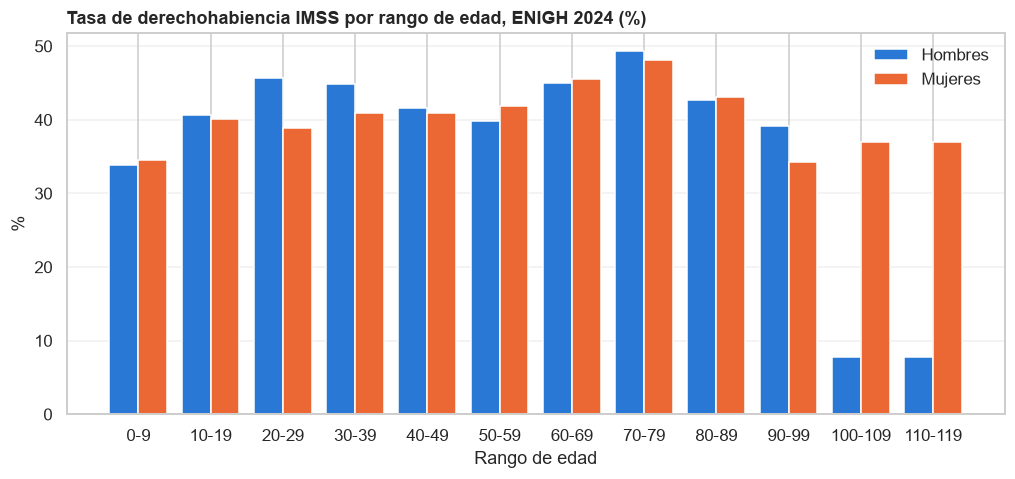

In [88]:
posiciones_dh = np.arange(len(tasa_derechohabiencia))
plt.figure(figsize=(11, 4.5))
plt.bar(posiciones_dh - 0.2, tasa_derechohabiencia["Hombres"] * 100, width=0.4, color="#2a78d6", label="Hombres")
plt.bar(posiciones_dh + 0.2, tasa_derechohabiencia["Mujeres"] * 100, width=0.4, color="#eb6834", label="Mujeres")
plt.xticks(posiciones_dh, tasa_derechohabiencia.index)
plt.title("Tasa de derechohabiencia IMSS por rango de edad, ENIGH 2024 (%)", loc="left", fontweight="bold")
plt.xlabel("Rango de edad")
plt.ylabel("%")
plt.legend(frameon=False)
plt.grid(alpha=0.3, axis="y")
guardar_grafica("13_4_tasa_derechohabiencia")
plt.show()

Gráfica guardada: graficas/reporte\13_4_indice_derechohabientes_por_edad.png


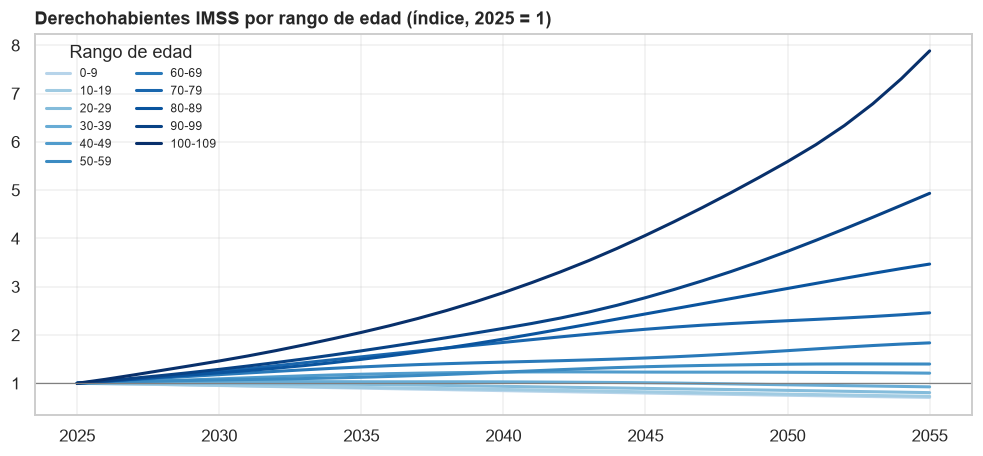

Gráfica guardada: graficas/reporte\13_4_crecimiento_dh_vs_sem_por_edad.png


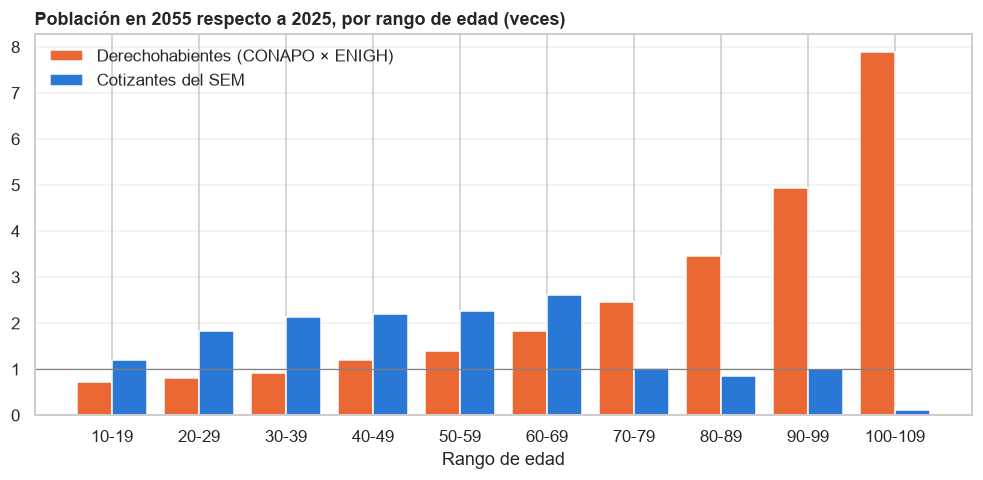

,Derechohabientes (CONAPO × ENIGH),Cotizantes del SEM
grupo_edad,,
10-19,0.73,1.21
20-29,0.81,1.83
30-39,0.93,2.14
40-49,1.21,2.21
50-59,1.40,2.27
60-69,1.84,2.62
70-79,2.46,1.04
80-89,3.47,0.84
90-99,4.93,1.01


In [89]:
# Crecimiento acumulado de cada rango (año base = 1)
indice_poblacion = poblacion_rango / poblacion_rango.loc[ANIO_BASE]
indice_sem = poblacion_rango_sem / poblacion_rango_sem.loc[ANIO_BASE]

# Gráfica 1: derechohabientes por rango (la población que se usa para proyectar)
# Color: de azul claro (jóvenes) a azul oscuro (mayores), porque la edad tiene un orden
rangos_con_poblacion = [rango for rango in etiquetas_rango if poblacion_rango.loc[ANIO_BASE, rango] > 0]
colores_rango = plt.cm.Blues(np.linspace(0.3, 1, len(rangos_con_poblacion)))
plt.figure(figsize=(11, 4.5))
for color, rango in zip(colores_rango, rangos_con_poblacion):
    plt.plot(indice_poblacion.index, indice_poblacion[rango], color=color, linewidth=2, label=rango)
plt.axhline(1, color="gray", linewidth=0.8)
plt.title(f"Derechohabientes IMSS por rango de edad (índice, {ANIO_BASE} = 1)", loc="left", fontweight="bold")
plt.legend(title="Rango de edad", frameon=False, fontsize=8, ncol=2)
plt.grid(alpha=0.3)
guardar_grafica("13_4_indice_derechohabientes_por_edad")
plt.show()

# Gráfica 2: crecimiento al ANIO_FINAL por rango, derechohabientes vs. cotizantes del SEM
crecimiento_final = pd.DataFrame({"Derechohabientes (CONAPO × ENIGH)": indice_poblacion.loc[ANIO_FINAL],
                                  "Cotizantes del SEM": indice_sem.loc[ANIO_FINAL]})
crecimiento_final = crecimiento_final.loc[poblacion_rango_sem.loc[ANIO_BASE] > 0]
posiciones = np.arange(len(crecimiento_final))
plt.figure(figsize=(11, 4.5))
plt.bar(posiciones - 0.2, crecimiento_final.iloc[:, 0], width=0.4, color="#eb6834", label=crecimiento_final.columns[0])
plt.bar(posiciones + 0.2, crecimiento_final.iloc[:, 1], width=0.4, color="#2a78d6", label=crecimiento_final.columns[1])
plt.axhline(1, color="gray", linewidth=0.8)
plt.xticks(posiciones, crecimiento_final.index)
plt.title(f"Población en {ANIO_FINAL} respecto a {ANIO_BASE}, por rango de edad (veces)", loc="left", fontweight="bold")
plt.xlabel("Rango de edad")
plt.legend(frameon=False)
plt.grid(alpha=0.3, axis="y")
guardar_grafica("13_4_crecimiento_dh_vs_sem_por_edad")
plt.show()
crecimiento_final.round(2)

**¿Qué parte de los derechohabientes cotiza al SEM?** Este cociente **no se usa en ningún cálculo**; sirve para contrastar las dos poblaciones:

`% de derechohabientes que cotizan al SEM = cotizantes del SEM / derechohabientes IMSS × 100`

* **Gráfica 1:** por rango de edad, en `ANIO_BASE` y `ANIO_FINAL`. Muestra por qué la población del SEM **subestima a los adultos mayores**: arriba de los 60 años casi nadie cotiza, aunque sí es derechohabiente (pensionados y familiares).
* **Gráfica 2:** el total por año. Si baja, cada cotizante "sostiene" a más derechohabientes.

Los cotizantes son un **subconjunto** de los derechohabientes. Si en algún rango el cociente pasa de 100 %, es una señal de que la tasa de la ENIGH es baja para ese rango.

Gráfica guardada: graficas/reporte\13_4_sem_como_pct_dh_por_edad.png


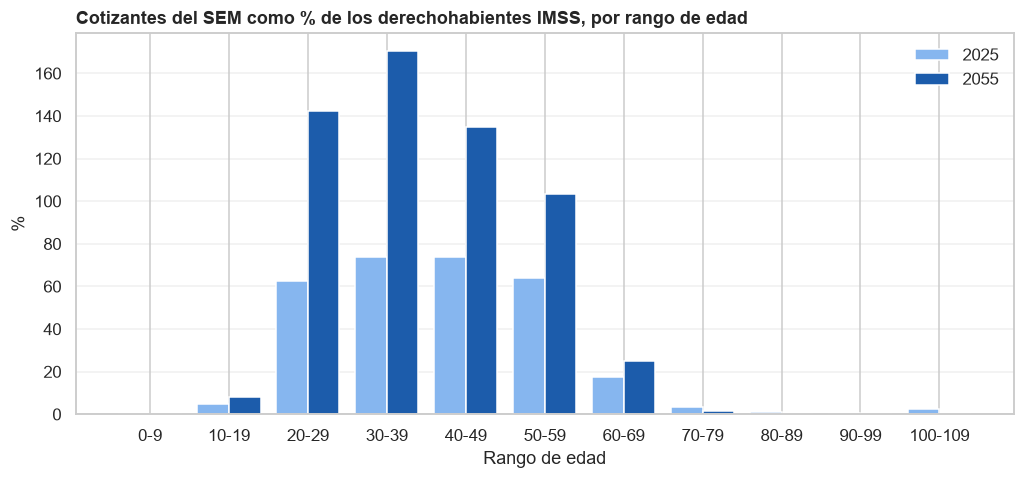

Gráfica guardada: graficas/reporte\13_4_sem_como_pct_dh_total.png


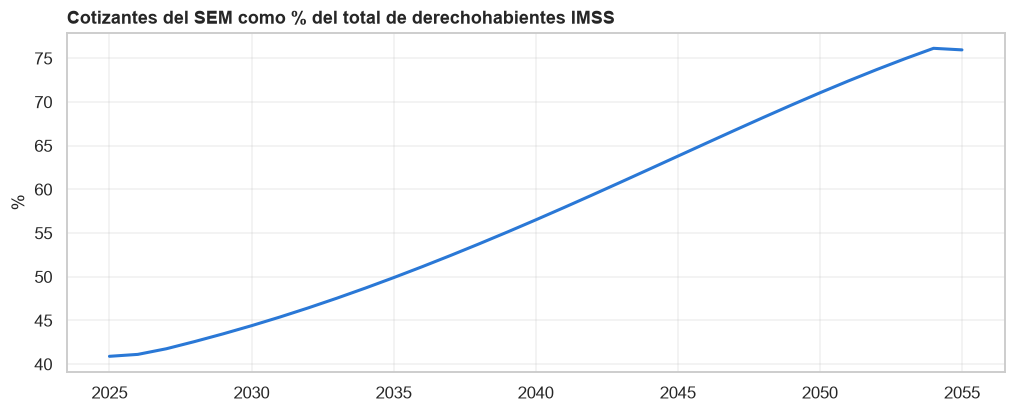

Cotizantes del SEM como % de los derechohabientes:


grupo_edad,0-9,10-19,20-29,30-39,40-49,50-59,60-69,70-79,80-89,90-99,100-109,Total
anio,,,,,,,,,,,,
2025,0.0,4.8,62.7,73.7,73.9,63.8,17.4,3.6,1.2,0.7,2.5,40.9
2040,0.0,9.6,106.2,96.6,93.7,82.9,20.5,1.2,0.6,0.6,0.1,56.5
2055,0.0,7.9,142.5,170.4,134.9,103.4,24.8,1.5,0.3,0.1,0.0,76.0


In [90]:
pct_sem_en_dh = poblacion_rango_sem / poblacion_rango * 100
pct_sem_total = poblacion_rango_sem.sum(axis=1) / poblacion_rango.sum(axis=1) * 100

# Gráfica 1: por rango de edad
rangos_grafica = [rango for rango in etiquetas_rango if poblacion_rango.loc[ANIO_BASE, rango] > 0]
posiciones = np.arange(len(rangos_grafica))
plt.figure(figsize=(11, 4.5))
plt.bar(posiciones - 0.2, pct_sem_en_dh.loc[ANIO_BASE, rangos_grafica], width=0.4, color="#86b6ef", label=str(ANIO_BASE))
plt.bar(posiciones + 0.2, pct_sem_en_dh.loc[ANIO_FINAL, rangos_grafica], width=0.4, color="#1c5cab", label=str(ANIO_FINAL))
plt.xticks(posiciones, rangos_grafica)
plt.title("Cotizantes del SEM como % de los derechohabientes IMSS, por rango de edad", loc="left", fontweight="bold")
plt.xlabel("Rango de edad")
plt.ylabel("%")
plt.legend(frameon=False)
plt.grid(alpha=0.3, axis="y")
guardar_grafica("13_4_sem_como_pct_dh_por_edad")
plt.show()

# Gráfica 2: total por año
plt.figure(figsize=(11, 4))
plt.plot(pct_sem_total.index, pct_sem_total, color="#2a78d6", linewidth=2)
plt.title("Cotizantes del SEM como % del total de derechohabientes IMSS", loc="left", fontweight="bold")
plt.ylabel("%")
plt.grid(alpha=0.3)
guardar_grafica("13_4_sem_como_pct_dh_total")
plt.show()

print("Cotizantes del SEM como % de los derechohabientes:")
tabla_pct = pct_sem_en_dh.loc[[ANIO_BASE, 2040, ANIO_FINAL], rangos_grafica].copy()
tabla_pct["Total"] = pct_sem_total.loc[[ANIO_BASE, 2040, ANIO_FINAL]]
tabla_pct.round(1)

**Afiliación e ingreso por trabajo subordinado por rango de edad (ENIGH 2024).** Todo con el factor de expansión. Esta tabla **no entra a ningún cálculo**; sirve para leer la tasa y para calibrar los experimentos de la sección 14.

| Columna | Qué es |
|---|---|
| `tasa_dh_imss_%` | % del rango que es derechohabiente IMSS (la tasa que se usa para proyectar, ambos sexos) |
| `subordinados_%` | % del rango que recibe ingreso por trabajo subordinado |
| `subordinados_sin_imss_pp` | Puntos porcentuales del rango que trabajan como subordinados **y no tienen IMSS**. Es una referencia para los experimentos de afiliación: afiliarlos a todos subiría la tasa al menos esos puntos (más, si se suman sus familias) |
| `ingreso_mensual_con_imss`, `ingreso_mensual_sin_imss` | Ingreso mensual promedio por trabajo subordinado de quienes lo reciben, con y sin IMSS (pesos de agosto de 2024) |

In [91]:
# Sumas con el factor de expansión por rango de edad (ambos sexos)
enigh["factor_sub"] = enigh["factor"] * enigh["subordinado"]
enigh["factor_sub_imss"] = enigh["factor_sub"] * enigh["dh_imss"]
enigh["factor_sub_sin_imss"] = enigh["factor_sub"] * (1 - enigh["dh_imss"])
enigh["ingreso_sub_imss"] = enigh["ing_sub_mensual"] * enigh["factor_sub_imss"]
enigh["ingreso_sub_sin_imss"] = enigh["ing_sub_mensual"] * enigh["factor_sub_sin_imss"]

columnas_suma = ["factor", "factor_dh", "factor_sub", "factor_sub_imss", "factor_sub_sin_imss", "ingreso_sub_imss", "ingreso_sub_sin_imss"]
sumas_rango = enigh.groupby("grupo_edad", observed=False)[columnas_suma].sum()
sumas_rango.loc["Total"] = sumas_rango.sum()
sumas_rango = sumas_rango.loc[sumas_rango["factor"] > 0]

afiliacion_ingreso = pd.DataFrame(index=sumas_rango.index)
afiliacion_ingreso["tasa_dh_imss_%"] = sumas_rango["factor_dh"] / sumas_rango["factor"] * 100
afiliacion_ingreso["subordinados_%"] = sumas_rango["factor_sub"] / sumas_rango["factor"] * 100
afiliacion_ingreso["subordinados_sin_imss_pp"] = sumas_rango["factor_sub_sin_imss"] / sumas_rango["factor"] * 100
afiliacion_ingreso["ingreso_mensual_con_imss"] = sumas_rango["ingreso_sub_imss"] / sumas_rango["factor_sub_imss"]
afiliacion_ingreso["ingreso_mensual_sin_imss"] = sumas_rango["ingreso_sub_sin_imss"] / sumas_rango["factor_sub_sin_imss"]

afiliacion_ingreso.round(1)

,tasa_dh_imss_%,subordinados_%,subordinados_sin_imss_pp,ingreso_mensual_con_imss,ingreso_mensual_sin_imss
grupo_edad,,,,,
0-9,34.2,1.4,0.9,147.6,139.6
10-19,40.4,16.4,11.2,4433.0,3833.8
20-29,42.2,58.7,28.5,11360.0,7542.3
30-39,42.8,65.3,30.1,15080.5,10031.7
40-49,41.2,60.9,29.0,15647.2,10403.1
50-59,40.9,50.9,25.0,14492.1,10417.9
60-69,45.3,25.3,14.4,12903.5,9751.4
70-79,48.6,8.6,5.1,8275.0,8806.5
80-89,42.9,2.4,1.3,11279.4,4953.4


## 13.5 Incidencia por rango de edad y sexo

$$\text{Incidencia}_{g,e,s} = \frac{\text{Casos}_{g,e,s,\,base}}{\text{Derechohabientes}_{e,s,\,base}} \times 100{,}000$$

La incidencia se calcula **por GRD, rango de edad y sexo**: la prostatectomía solo ocurre en hombres y la fractura de cadera es más frecuente en mujeres, que además son mayoría en las edades avanzadas. Los derechohabientes por rango y sexo vienen de `pob_conapo` (13.4).

También calculamos el **costo promedio por caso** de cada GRD, rango y sexo.

**Gráfica:** tres paneles con la misma escala: total (casos de ambos sexos / derechohabientes de ambos sexos), hombres y mujeres.

In [92]:
casos_base = demanda_base.groupby(["grd", "grupo_edad", "sexo"], observed=False).size().rename("casos_base")
costo_promedio = demanda_base.groupby(["grd", "grupo_edad", "sexo"], observed=False)["costo_caso"].mean().rename("costo_promedio_caso")

incidencia = pd.concat([casos_base, costo_promedio], axis=1).reset_index()

# Pegamos los derechohabientes del año base de cada rango y sexo
poblacion_base = pob_conapo.loc[pob_conapo["anio"] == ANIO_BASE, ["grupo_edad", "sexo", "derechohabientes"]]
poblacion_base = poblacion_base.rename(columns={"derechohabientes": "poblacion_base"})
incidencia = incidencia.merge(poblacion_base, on=["grupo_edad", "sexo"], how="left")

# Incidencia por 100 mil (si la población del rango es 0, no se puede calcular)
incidencia["incidencia_100mil"] = np.nan
con_poblacion = incidencia["poblacion_base"] > 0
incidencia.loc[con_poblacion, "incidencia_100mil"] = (
    incidencia.loc[con_poblacion, "casos_base"] / incidencia.loc[con_poblacion, "poblacion_base"] * 100000
)

# Aviso: casos en rangos sin población (no se podrán proyectar)
casos_sin_poblacion = incidencia.loc[(~con_poblacion) & (incidencia["casos_base"] > 0), "casos_base"].sum()
print(f"Casos en rangos sin derechohabientes (quedan fuera de la proyección): {casos_sin_poblacion:,}")

incidencia.loc[incidencia["casos_base"] > 0].round(2)

Casos en rangos sin derechohabientes (quedan fuera de la proyección): 1


,grd,grupo_edad,sexo,casos_base,costo_promedio_caso,poblacion_base,incidencia_100mil
5,"Colecistectomía laparoscópica, sin exploración...",20-29,Mujeres,4,68281.43,4285193.11,0.09
6,"Colecistectomía laparoscópica, sin exploración...",30-39,Hombres,2,68281.43,4512115.09,0.04
7,"Colecistectomía laparoscópica, sin exploración...",30-39,Mujeres,2,68281.43,4263238.42,0.05
9,"Colecistectomía laparoscópica, sin exploración...",40-49,Mujeres,5,68281.43,3648692.25,0.14
10,"Colecistectomía laparoscópica, sin exploración...",50-59,Hombres,1,68281.43,2626537.22,0.04
...,...,...,...,...,...,...,...
173,Sustitucion total de cadera,80-89,Mujeres,384,102579.82,493449.93,77.82
174,Sustitucion total de cadera,90-99,Hombres,34,102579.82,74461.45,45.66
175,Sustitucion total de cadera,90-99,Mujeres,87,102579.82,80892.00,107.55
176,Sustitucion total de cadera,100-109,Hombres,2,102579.82,817.70,244.59


Gráfica guardada: graficas/reporte\13_5_incidencia_por_edad.png


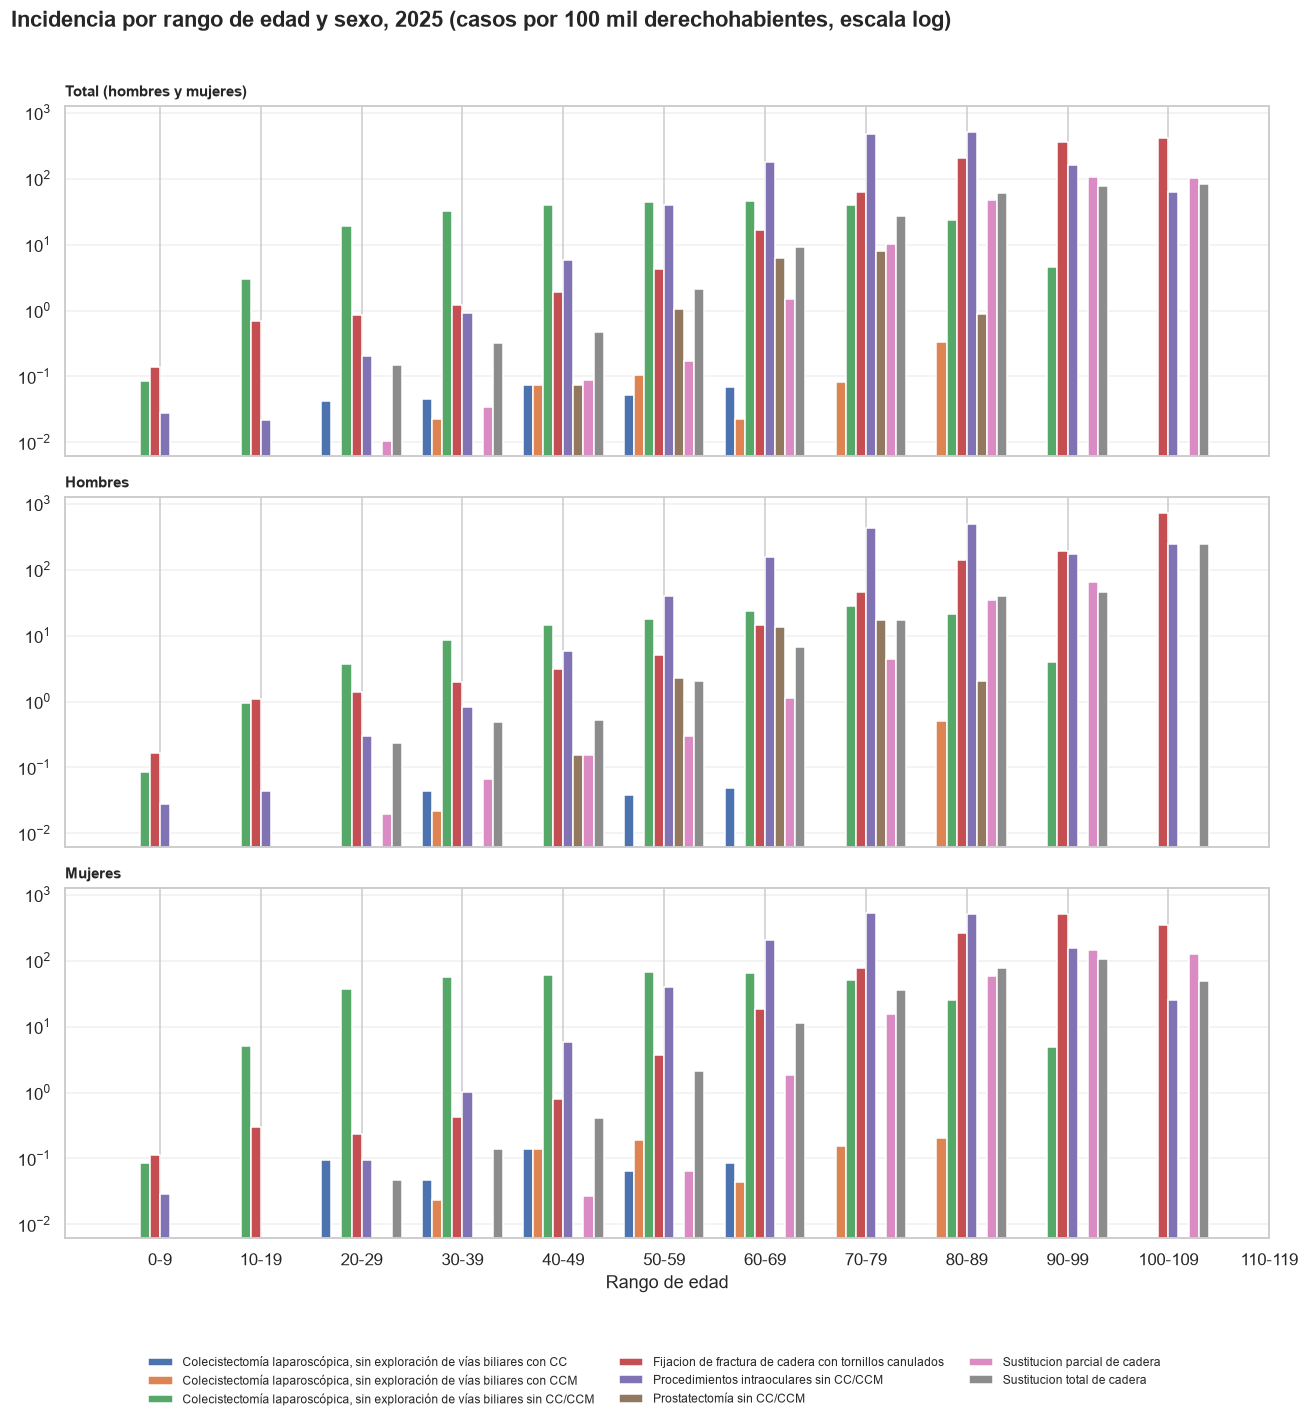

In [93]:
# ---------------- Tablas de incidencia: total (ambos sexos), hombres y mujeres ----------------
# Total: casos de hombres + mujeres / derechohabientes de ambos sexos (no es el promedio de las dos tasas)
casos_total = incidencia.groupby(["grupo_edad", "grd"], observed=False)["casos_base"].sum().unstack("grd")
tabla_incidencia = casos_total.div(poblacion_rango.loc[ANIO_BASE], axis=0) * 100000
tabla_incidencia = tabla_incidencia.replace([np.inf, -np.inf], np.nan)      # rangos sin derechohabientes

tabla_incidencia_sexo = {}
for sexo in ["Hombres", "Mujeres"]:
    tabla_incidencia_sexo[sexo] = incidencia.loc[incidencia["sexo"] == sexo].pivot(
        index="grupo_edad", columns="grd", values="incidencia_100mil")

lista_grd = list(tabla_incidencia.columns)
posiciones = np.arange(len(etiquetas_rango))
ancho = 0.8 / len(lista_grd)
paneles = [("Total (hombres y mujeres)", tabla_incidencia),
           ("Hombres", tabla_incidencia_sexo["Hombres"]),
           ("Mujeres", tabla_incidencia_sexo["Mujeres"])]

fig, ejes = plt.subplots(3, 1, figsize=(12, 13), sharex=True, sharey=True)
for eje, (titulo, tabla) in zip(ejes, paneles):
    tabla = tabla.reindex(index=etiquetas_rango, columns=lista_grd)
    for i in range(len(lista_grd)):
        grd = lista_grd[i]
        eje.bar(posiciones + i * ancho - 0.4 + ancho / 2, tabla[grd], width=ancho, color=f"C{i}", label=grd)
    eje.set_yscale("log")
    eje.set_title(titulo, loc="left", fontweight="bold", fontsize=10)
    eje.grid(alpha=0.3, axis="y")
ejes[-1].set_xticks(posiciones)
ejes[-1].set_xticklabels(etiquetas_rango)
ejes[-1].set_xlabel("Rango de edad")
fig.legend(*ejes[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=8, frameon=False)
fig.suptitle(f"Incidencia por rango de edad y sexo, {ANIO_BASE} (casos por 100 mil derechohabientes, escala log)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=[0, 0.07, 1, 0.97])
guardar_grafica("13_5_incidencia_por_edad")
plt.show()

### 13.5.1 Incidencia imputada vs. referencias

La incidencia del reporte (`incidencia`) es **imputada**: casos atendidos en el IMSS en `ANIO_BASE` / derechohabientes. Para saber si sus magnitudes son razonables se compara contra una **tabla de referencia editable** (`incidencia_referencia`), por procedimiento y rango de edad.

* Los GRD se agrupan en cuatro procedimientos de referencia (`MAPEO_REFERENCIA`): catarata, colecistectomía, prostatectomía y fractura de cadera (fijación + sustituciones).
* Las referencias son **por 100 mil personas de ambos sexos**. La prostatectomía de la literatura suele venir por 100 mil hombres; aquí se dividió entre 2.
* Una incidencia imputada **menor** que la referencia puede ser real (otra población, otro periodo) o reflejar **demanda no atendida** (lista de espera, capacidad).

> **#fuente google, revisar con literatura con base en lo que digan los demás.** Los valores de la tabla son una primera propuesta para discutir, no cifras validadas. Las pocas cifras publicadas que se encontraron están en la columna `nota`.

> **Experimento interno del equipo.** La tabla de referencia es preliminar y no se usa en el informe; el informe usa la tabla observada de 13.5.2.

In [94]:
# ======================= TABLA DE REFERENCIA (EDITABLE) =======================
# #fuente google, revisar con literatura con base en lo que digan los demás
# Unidades: casos por 100 mil personas (ambos sexos) por año.
incidencia_referencia = pd.DataFrame(
    columns=["procedimiento", "grupo_edad", "incidencia_ref_100mil", "nota"],
    data=[
        # Fractura de cadera (todas las cirugías). Publicado: 169 mujeres / 98 hombres por 100 mil de 50+ años
        # (Clark et al. 2005, Osteoporos Int); 168 (2006) a 139 (2019) por 100 mil de 60+ (Osteoporos Int 2024).
        # Valores por edad estimados para que el promedio de 60+ quede cerca de 140-170.
        ["Fractura de cadera", "50-59",   15, "estimado"],
        ["Fractura de cadera", "60-69",   40, "estimado"],
        ["Fractura de cadera", "70-79",  150, "estimado"],
        ["Fractura de cadera", "80-89",  550, "estimado"],
        ["Fractura de cadera", "90-99", 1200, "estimado"],
        # Catarata: tasa de cirugía de catarata (TCC) de México del orden de 2,000-3,000 por millón de habitantes
        # (cifras OMS/IAPB citadas en internet). Distribución por edad estimada.
        ["Catarata", "40-49",  100, "estimado"],
        ["Catarata", "50-59",  300, "estimado"],
        ["Catarata", "60-69", 1200, "estimado"],
        ["Catarata", "70-79", 2500, "estimado"],
        ["Catarata", "80-89", 3000, "estimado"],
        ["Catarata", "90-99", 2000, "estimado"],
        # Colecistectomía: estudios poblacionales (registros de seguros) dan del orden de 150-300 por 100 mil adultos.
        ["Colecistectomía", "20-29", 100, "estimado"],
        ["Colecistectomía", "30-39", 180, "estimado"],
        ["Colecistectomía", "40-49", 220, "estimado"],
        ["Colecistectomía", "50-59", 250, "estimado"],
        ["Colecistectomía", "60-69", 280, "estimado"],
        ["Colecistectomía", "70-79", 270, "estimado"],
        ["Colecistectomía", "80-89", 200, "estimado"],
        # Prostatectomía radical: en EE. UU., 38.7 por 100 mil hombres en 1991 (CDC, MMWR). Aquí por 100 mil personas.
        ["Prostatectomía", "50-59", 20, "estimado"],
        ["Prostatectomía", "60-69", 50, "estimado"],
        ["Prostatectomía", "70-79", 25, "estimado"],
    ],
)

# GRD del reporte -> procedimiento de referencia (se busca el texto en el nombre del GRD)
MAPEO_REFERENCIA = {"intraocular": "Catarata", "Colecistectom": "Colecistectomía",
                    "Prostatectom": "Prostatectomía", "cadera": "Fractura de cadera"}

incidencia_ref_grd = incidencia[["grd", "grupo_edad", "casos_base", "poblacion_base"]].copy()
incidencia_ref_grd["grupo_edad"] = incidencia_ref_grd["grupo_edad"].astype(str)
incidencia_ref_grd["procedimiento"] = ""
for texto, procedimiento in MAPEO_REFERENCIA.items():
    filas = incidencia_ref_grd["grd"].str.contains(texto, case=False)
    incidencia_ref_grd.loc[filas, "procedimiento"] = procedimiento
print("GRD sin procedimiento de referencia:", incidencia_ref_grd.loc[incidencia_ref_grd["procedimiento"] == "", "grd"].unique())

# Incidencia imputada por procedimiento: suma de casos de sus GRD / derechohabientes del rango
casos_proc = incidencia_ref_grd.groupby(["procedimiento", "grupo_edad"])["casos_base"].sum().reset_index()
dh_base_ref = poblacion_rango.loc[ANIO_BASE].copy()          # derechohabientes de ambos sexos por rango
dh_base_ref.index = dh_base_ref.index.astype(str)
casos_proc["incidencia_imputada_100mil"] = casos_proc["casos_base"] / casos_proc["grupo_edad"].map(dh_base_ref) * 100000
imputada = casos_proc[["procedimiento", "grupo_edad", "incidencia_imputada_100mil"]]

comparacion_ref = imputada.merge(incidencia_referencia, on=["procedimiento", "grupo_edad"], how="outer")
comparacion_ref["imputada / referencia"] = comparacion_ref["incidencia_imputada_100mil"] / comparacion_ref["incidencia_ref_100mil"]
comparacion_ref = comparacion_ref.loc[comparacion_ref["procedimiento"] != ""]
comparacion_ref.loc[comparacion_ref["incidencia_ref_100mil"].notna()].round(2)

GRD sin procedimiento de referencia: <StringArray>
[]
Length: 0, dtype: str


,procedimiento,grupo_edad,incidencia_imputada_100mil,incidencia_ref_100mil,nota,imputada / referencia
6,Catarata,40-49,5.83,100.0,estimado,0.06
7,Catarata,50-59,39.30,300.0,estimado,0.13
8,Catarata,60-69,180.92,1200.0,estimado,0.15
9,Catarata,70-79,480.25,2500.0,estimado,0.19
10,Catarata,80-89,502.01,3000.0,estimado,0.17
11,Catarata,90-99,163.50,2000.0,estimado,0.08
16,Colecistectomía,20-29,19.09,100.0,estimado,0.19
17,Colecistectomía,30-39,31.87,180.0,estimado,0.18
18,Colecistectomía,40-49,39.77,220.0,estimado,0.18
19,Colecistectomía,50-59,44.49,250.0,estimado,0.18


c:\Users\juanp\anaconda3\envs\reporte_grd\Lib\site-packages\matplotlib\transforms.py:2496: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),
c:\Users\juanp\anaconda3\envs\reporte_grd\Lib\site-packages\matplotlib\transforms.py:2496: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


Gráfica guardada: graficas/reporte\13_5_1_incidencia_imputada_vs_referencia.png


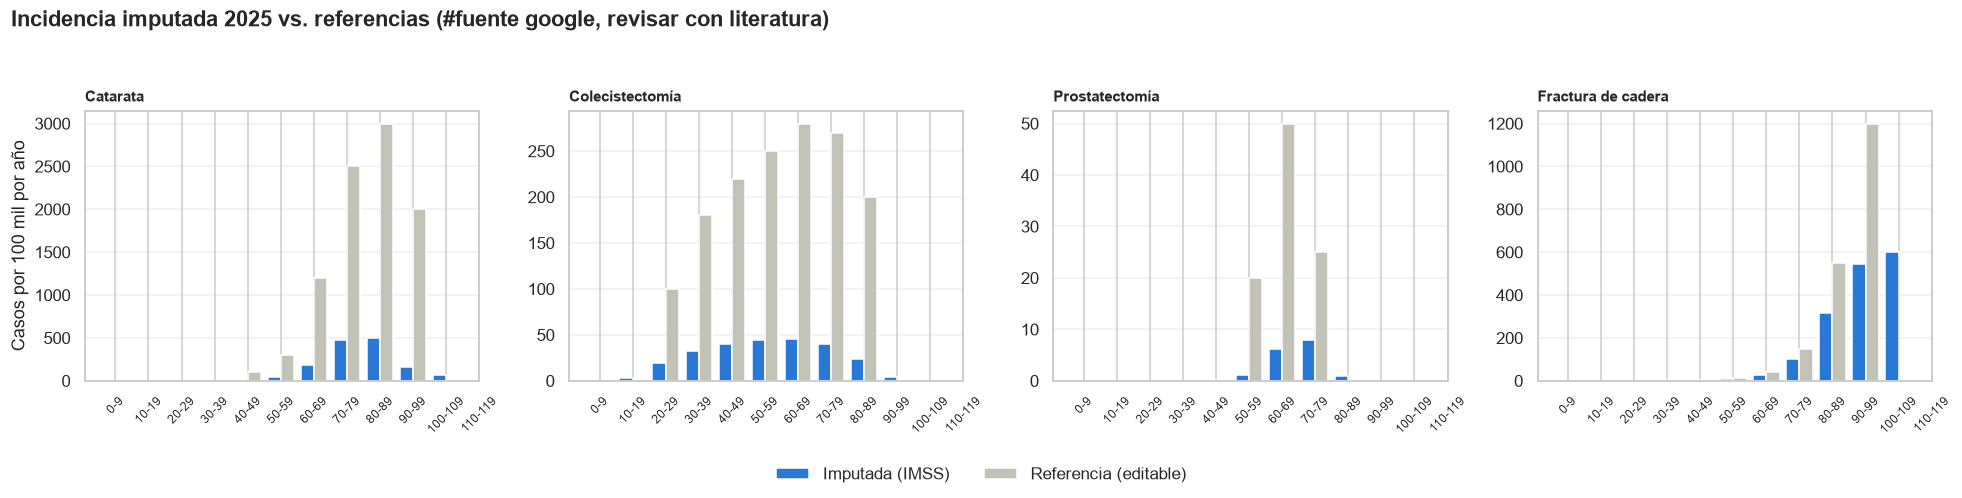

In [95]:
procedimientos = ["Catarata", "Colecistectomía", "Prostatectomía", "Fractura de cadera"]
fig, ejes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=False)
for eje, procedimiento in zip(ejes, procedimientos):
    tabla = comparacion_ref.loc[comparacion_ref["procedimiento"] == procedimiento].set_index("grupo_edad")
    tabla = tabla.reindex([rango for rango in etiquetas_rango if rango in tabla.index])
    posiciones = np.arange(len(tabla))
    eje.bar(posiciones - 0.2, tabla["incidencia_imputada_100mil"], width=0.4, color="#2a78d6", label="Imputada (IMSS)")
    eje.bar(posiciones + 0.2, tabla["incidencia_ref_100mil"], width=0.4, color="#c3c2b7", label="Referencia (editable)")
    eje.set_xticks(posiciones)
    eje.set_xticklabels(tabla.index, rotation=45, fontsize=8)
    eje.set_title(procedimiento, loc="left", fontweight="bold", fontsize=10)
    eje.grid(alpha=0.3, axis="y")
ejes[0].set_ylabel("Casos por 100 mil por año")
fig.legend(*ejes[0].get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False)
fig.suptitle(f"Incidencia imputada {ANIO_BASE} vs. referencias (#fuente google, revisar con literatura)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=[0, 0.08, 1, 0.94])
guardar_grafica("13_5_1_incidencia_imputada_vs_referencia")
plt.show()

### 13.5.2 Tabla de incidencia observada por procedimiento

Tabla para el informe: **casos de 2025 por cada 100 mil derechohabientes**, por procedimiento y rango de edad. Cada procedimiento suma sus GRD (por ejemplo, *Fractura de cadera* = fijación + sustitución total + sustitución parcial). La columna `Total` suma los cuatro procedimientos y el renglón `Todas las edades` divide todos los casos entre todos los derechohabientes.

Los rangos sin derechohabientes (110-119) no entran. La tabla se guarda en Excel en `tablas/reporte`, con pestañas para hombres, mujeres y por GRD.

In [96]:
# ---------------- Procedimiento de cada GRD (se busca el texto en el nombre del GRD) ----------------
PROCEDIMIENTO_POR_TEXTO = {"intraocular": "Catarata", "Colecistectom": "Colecistectomía",
                           "Prostatectom": "Prostatectomía", "cadera": "Fractura de cadera"}
CARPETA_TABLAS = "tablas/reporte"
os.makedirs(CARPETA_TABLAS, exist_ok=True)

casos_obs = incidencia[["grd", "grupo_edad", "sexo", "casos_base"]].copy()
casos_obs["grupo_edad"] = casos_obs["grupo_edad"].astype(str)
casos_obs["procedimiento"] = "Sin asignar"
for texto, procedimiento in PROCEDIMIENTO_POR_TEXTO.items():
    filas = casos_obs["grd"].str.contains(texto, case=False)
    casos_obs.loc[filas, "procedimiento"] = procedimiento
print("GRD sin procedimiento:", list(casos_obs.loc[casos_obs["procedimiento"] == "Sin asignar", "grd"].unique()))

# Derechohabientes del año base por rango (solo rangos con población)
dh_base = poblacion_rango.loc[ANIO_BASE].copy()
dh_base.index = dh_base.index.astype(str)
rangos_con_dh = [rango for rango in etiquetas_rango if dh_base.loc[rango] > 0]

# Casos por rango y procedimiento (se suman los GRD de cada procedimiento)
casos_proc = casos_obs.pivot_table(index="grupo_edad", columns="procedimiento", values="casos_base", aggfunc="sum")
casos_proc = casos_proc.reindex(rangos_con_dh).fillna(0)
casos_proc["Total"] = casos_proc.sum(axis=1)

# Incidencia = casos / derechohabientes × 100 mil
tabla_incidencia_obs = casos_proc.div(dh_base.loc[rangos_con_dh], axis=0) * 100000
tabla_incidencia_obs.loc["Todas las edades"] = casos_proc.sum() / dh_base.loc[rangos_con_dh].sum() * 100000

# Verificación: el total de todas las edades coincide con la incidencia total de la sección 13.8
print(f"Casos {ANIO_BASE}: {casos_proc['Total'].sum():,.0f} | incidencia total: {tabla_incidencia_obs.loc['Todas las edades', 'Total']:.1f} por 100 mil")

# ---------------- Misma tabla por sexo ----------------
dh_sexo_base = pob_conapo.loc[pob_conapo["anio"] == ANIO_BASE].pivot(index="grupo_edad", columns="sexo", values="derechohabientes")
dh_sexo_base.index = dh_sexo_base.index.astype(str)
tablas_sexo = {}
for sexo in ["Hombres", "Mujeres"]:
    casos_sexo = casos_obs.loc[casos_obs["sexo"] == sexo].pivot_table(index="grupo_edad", columns="procedimiento",
                                                                    values="casos_base", aggfunc="sum")
    casos_sexo = casos_sexo.reindex(index=rangos_con_dh, columns=casos_proc.columns).fillna(0)
    casos_sexo["Total"] = casos_sexo.drop(columns="Total").sum(axis=1)
    tabla_sexo = casos_sexo.div(dh_sexo_base.loc[rangos_con_dh, sexo], axis=0) * 100000
    tabla_sexo.loc["Todas las edades"] = casos_sexo.sum() / dh_sexo_base.loc[rangos_con_dh, sexo].sum() * 100000
    tablas_sexo[sexo] = tabla_sexo

# Tabla por GRD (misma que la gráfica de 13.5) para el anexo
tabla_incidencia_grd = tabla_incidencia.copy()
tabla_incidencia_grd.index = tabla_incidencia_grd.index.astype(str)
tabla_incidencia_grd = tabla_incidencia_grd.reindex(rangos_con_dh)

ruta_tabla = os.path.join(CARPETA_TABLAS, "13_5_2_incidencia_observada.xlsx")
with pd.ExcelWriter(ruta_tabla) as escritor:
    tabla_incidencia_obs.round(2).to_excel(escritor, sheet_name="por_procedimiento")
    tablas_sexo["Hombres"].round(2).to_excel(escritor, sheet_name="hombres")
    tablas_sexo["Mujeres"].round(2).to_excel(escritor, sheet_name="mujeres")
    tabla_incidencia_grd.round(2).to_excel(escritor, sheet_name="por_grd")
print("Tabla guardada:", ruta_tabla)

tabla_incidencia_obs.round(1)

GRD sin procedimiento: []
Casos 2025: 49,067 | incidencia total: 89.8 por 100 mil
Tabla guardada: tablas/reporte\13_5_2_incidencia_observada.xlsx


procedimiento,Catarata,Colecistectomía,Fractura de cadera,Prostatectomía,Total
grupo_edad,,,,,
0-9,0.0,0.1,0.1,0.0,0.3
10-19,0.0,3.0,0.7,0.0,3.7
20-29,0.2,19.1,1.0,0.0,20.3
30-39,0.9,31.9,1.6,0.0,34.4
40-49,5.8,39.8,2.5,0.1,48.1
50-59,39.3,44.5,6.6,1.0,91.4
60-69,180.9,45.7,27.3,6.3,260.2
70-79,480.2,39.9,99.3,8.0,627.4
80-89,502.0,23.8,316.2,0.9,842.9


## 13.6 Proyección de casos y costos

Para cada año *t*:

* `casos_t = incidencia × población_t / 100,000`, por GRD, rango de edad y **sexo** (población de `pob_conapo`)
* `costo_nominal_t = casos_t × costo_promedio_caso`
* `costo_real_t = costo_nominal_t / deflactor_t`

In [97]:
lista_proyeccion = []

for anio in anios_proyeccion:
    tabla_anio = incidencia[["grd", "grupo_edad", "sexo", "incidencia_100mil", "costo_promedio_caso"]].copy()
    tabla_anio["anio"] = anio

    # Derechohabientes del rango y sexo en ese año
    poblacion_anio = pob_conapo.loc[pob_conapo["anio"] == anio, ["grupo_edad", "sexo", "derechohabientes"]]
    poblacion_anio = poblacion_anio.rename(columns={"derechohabientes": "poblacion"})
    tabla_anio = tabla_anio.merge(poblacion_anio, on=["grupo_edad", "sexo"], how="left")

    tabla_anio["casos"] = tabla_anio["incidencia_100mil"] * tabla_anio["poblacion"] / 100000
    tabla_anio["costo_nominal"] = tabla_anio["casos"] * tabla_anio["costo_promedio_caso"]
    tabla_anio["costo_real"] = tabla_anio["costo_nominal"] / deflactor.loc[anio]

    lista_proyeccion.append(tabla_anio)

proyeccion_costos = pd.concat(lista_proyeccion, ignore_index=True)
proyeccion_costos = proyeccion_costos.fillna({"casos": 0, "costo_nominal": 0, "costo_real": 0})

# Verificación: en el año base los casos proyectados deben ser iguales a los observados
casos_observados = demanda_base.loc[demanda_base["grupo_edad"].isin(
    incidencia.loc[incidencia["poblacion_base"] > 0, "grupo_edad"].unique())].shape[0]
casos_modelo_base = proyeccion_costos.loc[proyeccion_costos["anio"] == ANIO_BASE, "casos"].sum()
print(f"Casos observados en {ANIO_BASE} (rangos con población): {casos_observados:,}")
print(f"Casos del modelo en {ANIO_BASE}: {casos_modelo_base:,.0f}")

Casos observados en 2025 (rangos con población): 49,067
Casos del modelo en 2025: 49,067


In [98]:
# Costo real por GRD y año (millones de pesos de 2026)
costo_grd = proyeccion_costos.groupby(["anio", "grd"])["costo_real"].sum().unstack("grd") / 1e6
costo_grd["Total GRD"] = costo_grd.sum(axis=1)

casos_grd = proyeccion_costos.groupby(["anio", "grd"])["casos"].sum().unstack("grd")

print("Costo real proyectado (millones de pesos de 2026):")
costo_grd.loc[[ANIO_BASE, 2030, 2035, 2040, 2045, 2050, ANIO_FINAL]].round(1)

Costo real proyectado (millones de pesos de 2026):


grd,"Colecistectomía laparoscópica, sin exploración de vías biliares con CC","Colecistectomía laparoscópica, sin exploración de vías biliares con CCM","Colecistectomía laparoscópica, sin exploración de vías biliares sin CC/CCM",Fijacion de fractura de cadera con tornillos canulados,Procedimientos intraoculares sin CC/CCM,Prostatectomía sin CC/CCM,Sustitucion parcial de cadera,Sustitucion total de cadera,Total GRD
anio,,,,,,,,,
2025,1.3,1.7,740.4,399.8,419.1,45.0,72.0,197.7,1877.0
2030,1.4,1.9,802.7,482.3,504.5,53.3,88.6,238.6,2173.3
2035,1.4,2.1,858.7,582.9,602.6,61.8,109.5,287.4,2506.5
2040,1.5,2.4,905.6,703.6,704.3,69.1,135.8,342.8,2865.2
2045,1.5,2.6,942.4,842.4,807.3,76.0,167.4,403.9,3243.4
2050,1.5,2.8,968.6,988.0,900.1,83.0,202.0,465.0,3611.1
2055,1.5,3.0,985.2,1139.8,988.7,90.5,238.7,526.7,3974.1


Gráfica guardada: graficas/reporte\13_6_indice_costo_por_grd.png


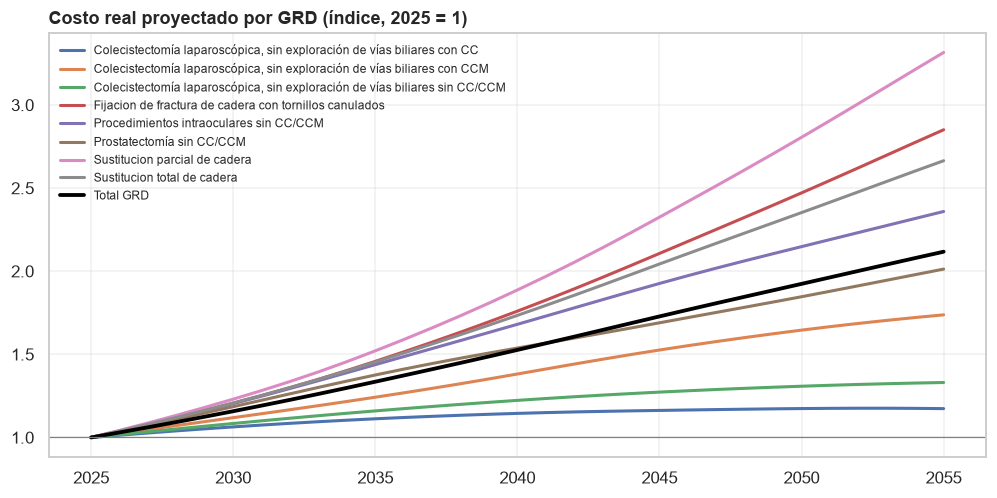

In [99]:
plt.figure(figsize=(11, 5))
for grd in lista_grd:
    plt.plot(costo_grd.index, costo_grd[grd] / costo_grd.loc[ANIO_BASE, grd], linewidth=2, label=grd)
plt.plot(costo_grd.index, costo_grd["Total GRD"] / costo_grd.loc[ANIO_BASE, "Total GRD"], color="black", linewidth=2.5, label="Total GRD")
plt.axhline(1, color="gray", linewidth=0.8)
plt.title(f"Costo real proyectado por GRD (índice, {ANIO_BASE} = 1)", loc="left", fontweight="bold")
plt.legend(fontsize=8, frameon=False)
plt.grid(alpha=0.3)
guardar_grafica("13_6_indice_costo_por_grd")
plt.show()

## 13.7 Costos y tasas de crecimiento: por GRD y total

**Cómo se calcula el total.** `Total GRD` es la **suma** de los costos de todos los GRD en cada año, no el promedio de los GRD:

$$\text{Total}_t = \sum_{g} \text{Costo}_{g,t}$$

La tasa del total se calcula **desde esa suma**:

$$\text{tasa Total}_t = \frac{\text{Total}_t}{\text{Total}_{t-1}} - 1$$

Esto equivale a un **promedio ponderado** de las tasas de cada GRD, con peso igual a su costo del año anterior. Por eso los GRD caros (por ejemplo, colecistectomía o cadera) mueven el total mucho más que los baratos. La celda de verificación lo compara contra el promedio simple de las tasas, que **no** se usa.

**Gráficas:**

1. **Línea de tiempo de costos** (MDP de 2026): área apilada por GRD. La altura total es `Total GRD`.
2. **Tasas de crecimiento** por GRD y del total, contra los ingresos (desde 2027, porque los ingresos 2025-2026 incluyen el cambio de dato observado a proyectado).

Gráfica guardada: graficas/reporte\13_7_linea_tiempo_costos.png


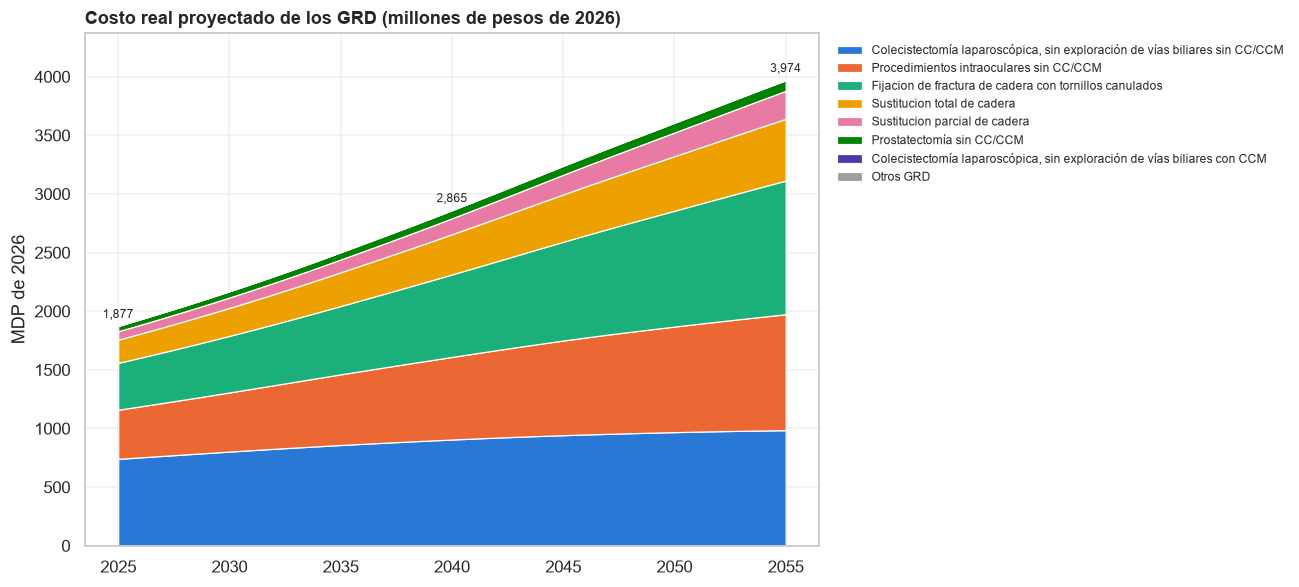

In [100]:
# ---------------- Línea de tiempo de costos (área apilada por GRD) ----------------
# GRD ordenados de mayor a menor costo en el año base; si hay más de 7, los más chicos van a "Otros GRD"
orden = costo_grd.drop(columns="Total GRD").loc[ANIO_BASE].sort_values(ascending=False).index
costo_grafica = costo_grd[list(orden[:7])].copy()
if len(orden) > 7:
    costo_grafica["Otros GRD"] = costo_grd[list(orden[7:])].sum(axis=1)
colores_grd = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#9e9e9e"]

plt.figure(figsize=(12, 5.5))
plt.stackplot(costo_grafica.index, [costo_grafica[columna] for columna in costo_grafica.columns],
              labels=list(costo_grafica.columns), colors=colores_grd[:len(costo_grafica.columns)],
              edgecolor="white", linewidth=0.8)
for anio in [ANIO_BASE, 2040, ANIO_FINAL]:
    plt.annotate(f"{costo_grd.loc[anio, 'Total GRD']:,.0f}", (anio, costo_grd.loc[anio, "Total GRD"]),
                 textcoords="offset points", xytext=(0, 5), ha="center", fontsize=8)
plt.title("Costo real proyectado de los GRD (millones de pesos de 2026)", loc="left", fontweight="bold")
plt.ylabel("MDP de 2026")
plt.ylim(0, costo_grd["Total GRD"].max() * 1.1)
plt.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
guardar_grafica("13_7_linea_tiempo_costos")
plt.show()

In [101]:
tasas_costo_grd = costo_grd.pct_change().loc[ANIO_BASE + 1:]

# Unimos con las tasas de ingreso en una sola tabla
tasas_comparacion = tasas_costo_grd.copy()
tasas_comparacion["Ingresos SEM"] = tasas_ingreso_imss.loc[ANIO_BASE + 1:ANIO_FINAL, "g_ingresos_SEM"]
tasas_comparacion["Ingresos consolidado"] = tasas_ingreso_imss.loc[ANIO_BASE + 1:ANIO_FINAL, "g_ingresos_consolidado"]

(tasas_comparacion * 100).round(2).head(10)

grd,"Colecistectomía laparoscópica, sin exploración de vías biliares con CC","Colecistectomía laparoscópica, sin exploración de vías biliares con CCM","Colecistectomía laparoscópica, sin exploración de vías biliares sin CC/CCM",Fijacion de fractura de cadera con tornillos canulados,Procedimientos intraoculares sin CC/CCM,Prostatectomía sin CC/CCM,Sustitucion parcial de cadera,Sustitucion total de cadera,Total GRD,Ingresos SEM,Ingresos consolidado
anio,,,,,,,,,,,
2026,1.37,2.41,1.73,3.86,3.83,3.62,4.27,3.89,3.03,3.04,1.79
2027,1.30,2.33,1.67,3.84,3.80,3.52,4.25,3.86,2.99,1.60,3.04
2028,1.24,2.26,1.62,3.82,3.77,3.45,4.23,3.83,2.97,3.04,3.15
2029,1.18,2.21,1.58,3.81,3.76,3.38,4.22,3.82,2.95,3.10,3.21
2030,1.11,2.16,1.54,3.79,3.74,3.32,4.20,3.80,2.94,3.13,3.23
2031,1.04,2.13,1.48,3.79,3.72,3.26,4.20,3.78,2.92,3.16,3.26
2032,0.97,2.11,1.42,3.81,3.68,3.17,4.25,3.78,2.91,3.19,3.28
2033,0.90,2.10,1.36,3.85,3.64,3.05,4.32,3.79,2.90,3.22,3.30
2034,0.83,2.10,1.29,3.91,3.57,2.91,4.42,3.80,2.89,3.25,3.33


In [102]:
# ---------------- Verificación: el total es la suma, y su tasa es un promedio ponderado ----------------
columnas_grd = [columna for columna in costo_grd.columns if columna != "Total GRD"]
print("¿Total GRD = suma de los GRD en todos los años?",
      np.allclose(costo_grd["Total GRD"], costo_grd[columnas_grd].sum(axis=1)))

pesos = costo_grd[columnas_grd].shift(1)                                  # costo del año anterior
tasa_ponderada = (tasas_costo_grd[columnas_grd] * pesos.loc[tasas_costo_grd.index]).sum(axis=1) / pesos.loc[tasas_costo_grd.index].sum(axis=1)
tasa_simple = tasas_costo_grd[columnas_grd].mean(axis=1)

verificacion_total = pd.DataFrame({
    "tasa Total GRD (de la suma)": tasas_costo_grd["Total GRD"],
    "promedio ponderado de los GRD": tasa_ponderada,
    "promedio simple de los GRD (no se usa)": tasa_simple,
}) * 100
verificacion_total.loc[[ANIO_BASE + 1, 2030, 2040, 2050, ANIO_FINAL]].round(3)

¿Total GRD = suma de los GRD en todos los años? True


,tasa Total GRD (de la suma),promedio ponderado de los GRD,promedio simple de los GRD (no se usa)
anio,,,
2026,3.025,3.025,3.124
2030,2.937,2.937,2.958
2040,2.632,2.632,2.532
2050,2.054,2.054,1.897
2055,1.834,1.834,1.605


Gráfica guardada: graficas/reporte\13_7_tasas_costos_vs_ingresos.png


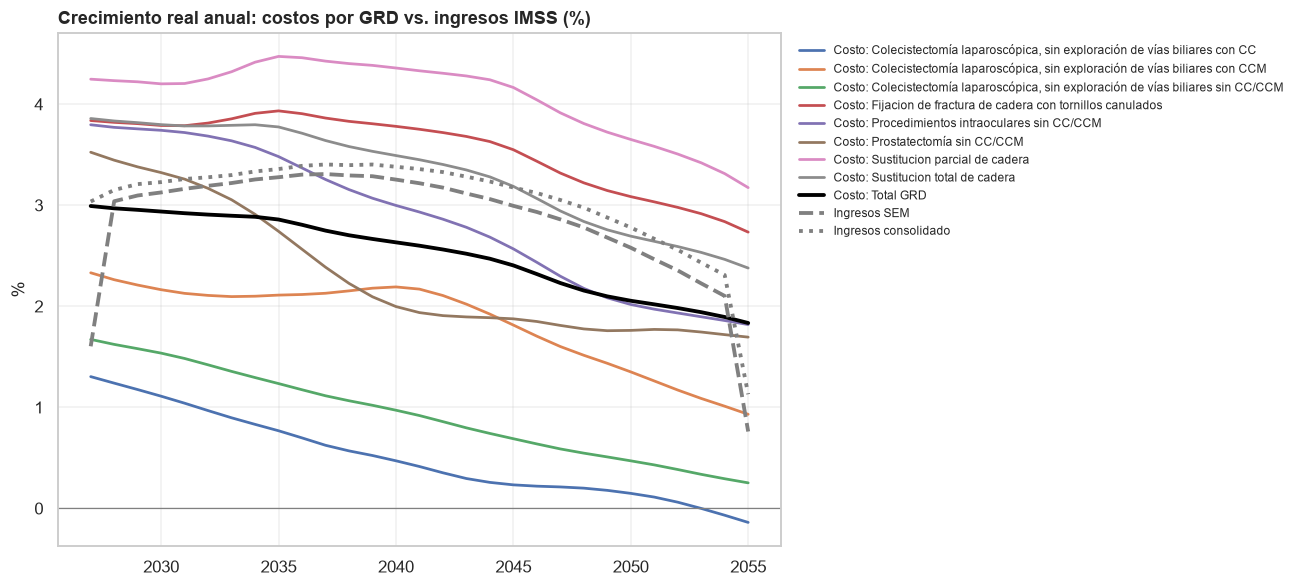

In [103]:
desde = 2027
tabla_grafica = tasas_comparacion.loc[desde:]

plt.figure(figsize=(12, 5.5))
for grd in lista_grd:
    plt.plot(tabla_grafica.index, tabla_grafica[grd] * 100, linewidth=1.8, label=f"Costo: {grd}")
plt.plot(tabla_grafica.index, tabla_grafica["Total GRD"] * 100, color="black", linewidth=2.5, label="Costo: Total GRD")
plt.plot(tabla_grafica.index, tabla_grafica["Ingresos SEM"] * 100, color="gray", linestyle="--", linewidth=2.5, label="Ingresos SEM")
plt.plot(tabla_grafica.index, tabla_grafica["Ingresos consolidado"] * 100, color="gray", linestyle=":", linewidth=2.5, label="Ingresos consolidado")
plt.axhline(0, color="gray", linewidth=0.8)
plt.title("Crecimiento real anual: costos por GRD vs. ingresos IMSS (%)", loc="left", fontweight="bold")
plt.ylabel("%")
plt.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
guardar_grafica("13_7_tasas_costos_vs_ingresos")
plt.show()

In [104]:
costo_grd

grd,"Colecistectomía laparoscópica, sin exploración de vías biliares con CC","Colecistectomía laparoscópica, sin exploración de vías biliares con CCM","Colecistectomía laparoscópica, sin exploración de vías biliares sin CC/CCM",Fijacion de fractura de cadera con tornillos canulados,Procedimientos intraoculares sin CC/CCM,Prostatectomía sin CC/CCM,Sustitucion parcial de cadera,Sustitucion total de cadera,Total GRD
anio,,,,,,,,,
2025,1.297347,1.703588,740.441135,399.827375,419.086942,44.950395,71.990516,197.671315,1876.968614
2026,1.315175,1.744641,753.260608,415.276253,435.150073,46.576829,75.063909,205.363937,1933.751425
2027,1.332320,1.785312,765.855474,431.213509,451.668130,48.218349,78.251982,213.286511,1991.611588
2028,1.348829,1.825706,778.281472,447.684784,468.697178,49.879648,81.563967,221.462856,2050.744440
2029,1.364685,1.866050,790.579169,464.728303,486.298399,51.565190,85.006895,229.915661,2111.324350
2030,1.379831,1.906426,802.722835,482.336107,504.491325,53.278461,88.577878,238.646091,2173.338954
2031,1.394189,1.946984,814.628402,500.600204,523.252943,55.014245,92.301772,247.677128,2236.815868
2032,1.407676,1.988012,826.197135,519.687729,542.527600,56.756215,96.224426,257.050586,2301.839379
2033,1.420290,2.029671,837.395730,539.721060,562.259702,58.489313,100.382070,266.793902,2368.491738


## 13.8 ¿Qué mueve el costo del escenario base?

Con la incidencia y el costo por caso fijos, el costo solo puede moverse por **la población**: cuántos derechohabientes hay y qué edad tienen. Cuatro paneles:

1. **Incidencia por rango de edad** (todos los GRD juntos): casos / derechohabientes de cada rango y año. Es **casi constante**: la incidencia de cada rango y sexo no cambia, y la del rango solo se mueve si cambia la proporción de hombres y mujeres dentro del rango. La línea naranja es la **incidencia total** (casos totales / derechohabientes totales): sube aunque las de cada rango no cambien, porque pesan más los rangos de mayor edad.
2. **Derechohabientes totales** (millones).
3. **% de derechohabientes por rango de edad** (área apilada al 100 %).
4. **Descomposición del costo:** costo proyectado vs. el costo si la **estructura por edad y sexo se quedara como en `ANIO_BASE`** y solo creciera el total.
   * `efecto tamaño` = costo con estructura fija − costo del año base.
   * `efecto envejecimiento` = costo proyectado − costo con estructura fija.

El costo por persona de cada rango y sexo es `costo_rango_sexo = Σ_GRD incidencia × costo promedio por caso / 100,000`. El `efecto envejecimiento` incluye el cambio en la composición por sexo de cada edad.

Gráfica guardada: graficas/reporte\13_8_motores_costo_base.png


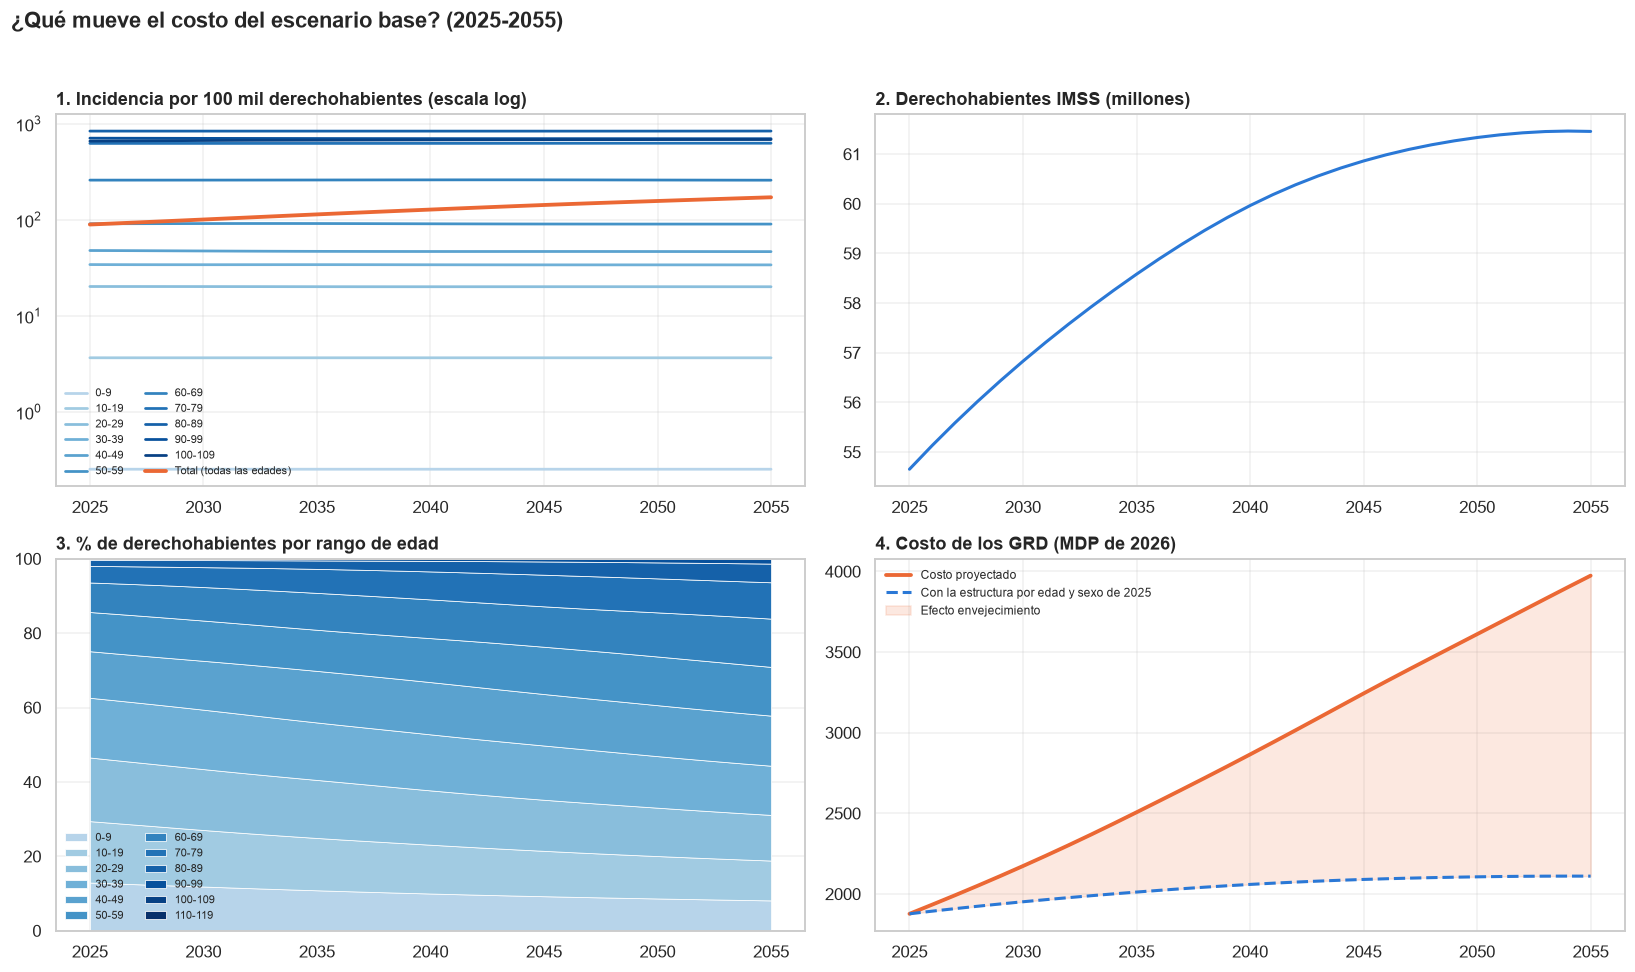

Verificación: costo del año base con estructura fija = costo proyectado del año base: True
Incidencia por rango (cambia solo por la mezcla de sexos): variación máxima en el horizonte (%): 3.924127


,costo_proyectado,costo_estructura_fija,efecto_tamano,efecto_envejecimiento,% del crecimiento por envejecimiento
2030,2173.3,1951.7,74.7,221.7,74.8
2040,2865.2,2059.2,182.3,805.9,81.6
2050,3611.1,2106.3,229.3,1504.8,86.8
2055,3974.1,2110.5,233.6,1863.6,88.9


In [105]:
# ---------------- Panel 1: incidencia implícita por rango y total (todos los GRD) ----------------
casos_rango = proyeccion_costos.groupby(["anio", "grupo_edad"], observed=False)["casos"].sum().unstack("grupo_edad")
rangos_con_casos = [rango for rango in etiquetas_rango if casos_rango.loc[ANIO_BASE, rango] > 0]
incidencia_rango = casos_rango[rangos_con_casos] / poblacion_rango[rangos_con_casos] * 100000
incidencia_total = casos_rango.sum(axis=1) / poblacion_rango.sum(axis=1) * 100000

# ---------------- Panel 4: costo con la estructura de edad del año base ----------------
costo_por_persona = (incidencia["incidencia_100mil"].fillna(0) * incidencia["costo_promedio_caso"].fillna(0) / 100000)
costo_por_persona = costo_por_persona.groupby([incidencia["grupo_edad"], incidencia["sexo"]], observed=False).sum()   # pesos por derechohabiente
dh_rango_sexo = pob_conapo.set_index(["anio", "grupo_edad", "sexo"])["derechohabientes"]
estructura_base = dh_rango_sexo.loc[ANIO_BASE] / dh_rango_sexo.loc[ANIO_BASE].sum()          # % por rango y sexo
costo_estructura_fija = pd.Series(index=anios_proyeccion, dtype=float)
for anio in anios_proyeccion:
    poblacion_fija = dh_rango_sexo.loc[anio].sum() * estructura_base
    costo_estructura_fija.loc[anio] = (poblacion_fija * costo_por_persona).sum() / deflactor.loc[anio] / 1e6
costo_proyectado = costo_grd["Total GRD"]

colores_rango = plt.cm.Blues(np.linspace(0.3, 1, len(etiquetas_rango)))
color_de = dict(zip(etiquetas_rango, colores_rango))

fig, ejes = plt.subplots(2, 2, figsize=(15, 9))
# 1) Incidencia
for rango in rangos_con_casos:
    ejes[0, 0].plot(incidencia_rango.index, incidencia_rango[rango], color=color_de[rango], linewidth=1.8, label=rango)
ejes[0, 0].plot(incidencia_total.index, incidencia_total, color="#eb6834", linewidth=2.5, label="Total (todas las edades)")
ejes[0, 0].set_yscale("log")
ejes[0, 0].set_title("1. Incidencia por 100 mil derechohabientes (escala log)", loc="left", fontweight="bold")
ejes[0, 0].legend(fontsize=7, frameon=False, ncol=2)
# 2) Población total
ejes[0, 1].plot(poblacion_rango.index, poblacion_rango.sum(axis=1) / 1e6, color="#2a78d6", linewidth=2)
ejes[0, 1].set_title("2. Derechohabientes IMSS (millones)", loc="left", fontweight="bold")
# 3) % por rango
porcentaje_rango = poblacion_rango.div(poblacion_rango.sum(axis=1), axis=0) * 100
ejes[1, 0].stackplot(porcentaje_rango.index, [porcentaje_rango[rango] for rango in etiquetas_rango],
                     labels=etiquetas_rango, colors=colores_rango, edgecolor="white", linewidth=0.5)
ejes[1, 0].set_ylim(0, 100)
ejes[1, 0].set_title("3. % de derechohabientes por rango de edad", loc="left", fontweight="bold")
ejes[1, 0].legend(fontsize=7, frameon=False, ncol=2, loc="lower left")
# 4) Descomposición
ejes[1, 1].plot(costo_proyectado.index, costo_proyectado, color="#eb6834", linewidth=2.5, label="Costo proyectado")
ejes[1, 1].plot(costo_estructura_fija.index, costo_estructura_fija, color="#2a78d6", linewidth=2,
                linestyle="--", label=f"Con la estructura por edad y sexo de {ANIO_BASE}")
ejes[1, 1].fill_between(costo_proyectado.index, costo_estructura_fija, costo_proyectado, color="#eb6834", alpha=0.15,
                        label="Efecto envejecimiento")
ejes[1, 1].set_title("4. Costo de los GRD (MDP de 2026)", loc="left", fontweight="bold")
ejes[1, 1].legend(fontsize=8, frameon=False)
for eje in ejes.reshape(-1):
    eje.grid(alpha=0.3)
fig.suptitle(f"¿Qué mueve el costo del escenario base? ({ANIO_BASE}-{ANIO_FINAL})", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.96])
guardar_grafica("13_8_motores_costo_base")
plt.show()

# ---------------- Tabla de la descomposición ----------------
descomposicion = pd.DataFrame({
    "costo_proyectado": costo_proyectado.loc[anios_proyeccion],
    "costo_estructura_fija": costo_estructura_fija,
})
descomposicion["efecto_tamano"] = descomposicion["costo_estructura_fija"] - descomposicion.loc[ANIO_BASE, "costo_proyectado"]
descomposicion["efecto_envejecimiento"] = descomposicion["costo_proyectado"] - descomposicion["costo_estructura_fija"]
crecimiento = descomposicion["costo_proyectado"] - descomposicion.loc[ANIO_BASE, "costo_proyectado"]
descomposicion["% del crecimiento por envejecimiento"] = descomposicion["efecto_envejecimiento"] / crecimiento * 100

print("Verificación: costo del año base con estructura fija = costo proyectado del año base:",
      np.isclose(descomposicion.loc[ANIO_BASE, "costo_estructura_fija"], descomposicion.loc[ANIO_BASE, "costo_proyectado"]))
print("Incidencia por rango (cambia solo por la mezcla de sexos): variación máxima en el horizonte (%):",
      round(((incidencia_rango.max() / incidencia_rango.min() - 1) * 100).max(), 6))
descomposicion.loc[[2030, 2040, 2050, ANIO_FINAL]].round(1)

# 14. Escenarios paramétricos

La sección tiene **dos partes**:

**A. Población cotizante del SEM (14.1 a 14.4) — descriptiva.** Se proyecta con el modelo de cohortes del cuaderno de tasas IMSS, solo en su escenario base (sin desviaciones), para ver cómo envejece, cuántos entran y salen, y su edad mediana. **No se usa para proyectar costos.**

$$P_t(a+1) = P_{t-1}(a)\,\big(1 - q(a)\big)\,k_t \;+\; N_t\,v(a+1)$$

* *q(a)*: probabilidad de salida (muerte + retiro + invalidez/incapacidad).
* *N_t*: nuevos asegurados del año; *v(a)*: su distribución por edad.
* *k_t*: factor de calibración que hace que el modelo reproduzca exactamente la proyección del IMSS.

**B. Escenarios sobre derechohabientes (14.5 a 14.9) — los que se usan para los costos.** Cada escenario es una **desviación de la población derechohabiente** (CONAPO × ENIGH, sección 13.4), por edad simple:

| Dimensión | Qué mueve | Parámetros |
|---|---|---|
| **(a) Variante demográfica** | **Nacimientos** (cohortes nacidas después de `ANIO_BASE`; aproxima un cambio de la TGF) y **adultos mayores** (personas de `EDAD_MAYORES` años o más; aproxima un cambio de la mortalidad) | `desv_nacimientos_pct`, `anio_pleno_nacimientos`, `desv_mayores_pct` |
| **(b) Trayectoria de afiliación** | **Tasa de derechohabiencia** (ENIGH): suma puntos porcentuales a los menores de `EDAD_MAYORES` (trabajadores y sus familias) o solo a los rangos que se elijan | `desv_tasa_dh_pp`, `pp_por_rango`, `anio_meta` |

Con 3 variantes × 3 trayectorias salen **9 escenarios**, más el **escenario base (E0)** sin desviaciones, que da exactamente la sección 13.

**Todos los valores de las matrices son ilustrativos.** Están para que el código corra y para discutirlos con el equipo.

## 14.0 Objetos que se usan de secciones anteriores

| Objeto | Viene de | Para qué se usa aquí |
|---|---|---|
| `ANIO_BASE`, `ANIO_FINAL`, `anios_proyeccion`, `deflactor` | 13.1 | Horizonte y deflactor de los costos |
| `conapo` | 13.4 | Derechohabientes por año, edad simple y sexo (base de los escenarios) |
| `poblacion_rango`, `incidencia` | 13.4 y 13.5 | Derechohabientes por rango; incidencia y costo por caso del año base |
| `etiquetas_rango`, `cortes_rango` | 13.4 | Los mismos rangos de edad (`grupo_edad`) |
| `costo_grd` | 13.6 | Verificación: E0 debe dar el mismo costo que la sección 13 |

In [106]:
objetos_necesarios = ["ANIO_BASE", "ANIO_FINAL", "anios_proyeccion", "deflactor", "conapo", "poblacion_rango",
                      "incidencia", "etiquetas_rango", "cortes_rango", "costo_grd"]
faltan = [nombre for nombre in objetos_necesarios if nombre not in globals()]
if len(faltan) > 0:
    raise NameError(f"Faltan objetos de la sección 13: {faltan}. Corra primero las secciones 1 a 13.")

print("ANIO_BASE:", ANIO_BASE, "| ANIO_FINAL:", ANIO_FINAL)
print("Rangos de edad:", etiquetas_rango)
print(f"GRD con incidencia: {incidencia['grd'].nunique()}")

ANIO_BASE: 2025 | ANIO_FINAL: 2055
Rangos de edad: ['0-9', '10-19', '20-29', '30-39', '40-49', '50-59', '60-69', '70-79', '80-89', '90-99', '100-109', '110-119']
GRD con incidencia: 8


## 14.1 Carga de la población del SEM y de los parámetros del IMSS

Todo se lee directamente de los dos archivos de Excel originales; no hace falta ningún archivo intermedio. **Solo revise la carpeta (`CARPETA_DATOS_IMSS`) en la primera celda.**

| Objeto | Contenido | Archivo y pestaña |
|---|---|---|
| `poblacion_2025` | Personas por origen (asegurados / TIMSS), sexo y edad (15-100) a diciembre de 2025 | `poblacion_imss.xlsx`: `Mat_SEM` y `MAT_TIMSS` |
| `salidas` | Probabilidad de salida por edad, separada en **muerte**, **retiro** (cesantía y vejez) e **invalidez/incapacidad** | `poblacion_imss.xlsx`: `salidos_asegurados` y `salidas_timss` |
| `vector_nuevos` | Distribución por edad de los nuevos asegurados | Archivo IMSS: `vector_dist_pob_aseg_nueva` |
| `nuevos_y_stock` | Nuevos asegurados y stock proyectado por el IMSS, por año | Archivo IMSS: `Pob_sem_tidy` |

**Lectura de las matrices de edad** (igual que la sección 4.1 del cuaderno de tasas):

1. En `Mat_SEM`, para 2024, las columnas `concepto` y `edad` vienen intercambiadas; se regresan a su lugar.
2. Solo se usa el bloque `Total Hombres` / `Total Mujeres` (el bloque Total ya es Generación en Transición + Generación Actual; sumar los tres triplicaría la población).
3. Se quitan los renglones `Ant = Total` y `edad = Total`, que son subtotales.
4. Se suma sobre la antigüedad: el modelo solo necesita la edad.

In [107]:
import itertools

# ---------------- RUTAS (revise que coincidan con su carpeta) ----------------
# Ojo: en este reporte los archivos procesados están en "datos/procesada/".
# La idea es sustituir esto por archivos sql pero no se han subido todavía
CARPETA_DATOS_IMSS = "datos/"
ARCHIVO_POBLACION_SEM = CARPETA_DATOS_IMSS + "poblacion_imss.xlsx"                 # Mat_SEM, MAT_TIMSS, salidas
ARCHIVO_INFO_FINANCIERA_IMSS = ARCHIVO_POBLACION_SEM  # vector de nuevos y Pob_sem_tidy # antes los tenia en archivos separados

EDADES = np.arange(15, 101)
GRUPOS = [("Personas Aseguradas", "Hombres"), ("Personas Aseguradas", "Mujeres"), ("TIMSS", "Hombres"), ("TIMSS", "Mujeres")]
ANIO_INICIO_COHORTES = 2025      # la población de partida es la de diciembre de 2025

BLOQUES_MATRIZ = ["Total Hombres", "Generación en Transición. Hombres", "Generación Actual. Hombres",
                  "Total Mujeres", "Generación en Transición. Mujeres", "Generación Actual. Mujeres"]


def leer_matriz_sem(nombre_hoja, origen):
    tabla = pd.read_excel(ARCHIVO_POBLACION_SEM, sheet_name=nombre_hoja)

    # 1) Corregir filas con 'concepto' y 'edad' intercambiadas
    intercambiadas = tabla["edad"].isin(BLOQUES_MATRIZ)
    concepto_original = tabla["concepto"].copy()
    tabla.loc[intercambiadas, "concepto"] = tabla.loc[intercambiadas, "edad"].values
    tabla.loc[intercambiadas, "edad"] = concepto_original.loc[intercambiadas].values

    # 2) y 3) Solo bloque Total, sin subtotales
    filtro = (
        tabla["concepto"].isin(["Total Hombres", "Total Mujeres"])
        & (tabla["Ant"].astype(str) != "Total")
        & (tabla["edad"].astype(str) != "Total")
    )
    matriz = tabla.loc[filtro].copy()
    matriz["origen"] = origen
    matriz["sexo"] = matriz["sexo"].map({"H": "Hombres", "M": "Mujeres"})
    matriz["edad"] = matriz["edad"].astype(int)
    matriz["personas"] = matriz["count"].astype(float)
    return matriz[["origen", "anio", "sexo", "edad", "personas"]]


matrices_sem = pd.concat([leer_matriz_sem("Mat_SEM", "Personas Aseguradas"),
                          leer_matriz_sem("MAT_TIMSS", "TIMSS")], ignore_index=True)

# 4) Población de diciembre de 2025 por origen, sexo y edad (sumando antigüedades)
poblacion_2025 = (matrices_sem.loc[matrices_sem["anio"] == ANIO_INICIO_COHORTES]
                  .groupby(["origen", "sexo", "edad"])["personas"].sum().reset_index())

print(f"Población del SEM a dic-{ANIO_INICIO_COHORTES}: {poblacion_2025['personas'].sum():,.0f}")
if ANIO_BASE != ANIO_INICIO_COHORTES:
    print(f"AVISO: ANIO_BASE = {ANIO_BASE}; la población de partida es de {ANIO_INICIO_COHORTES}.")
poblacion_2025.groupby(["origen", "sexo"])["personas"].sum()

Población del SEM a dic-2025: 22,352,586


origen               sexo   
Personas Aseguradas  Hombres    13102667.0
                     Mujeres     8698025.0
TIMSS                Hombres      226134.0
                     Mujeres      325760.0
Name: personas, dtype: float64

In [108]:
# ---------------- Probabilidades de salida separadas por causa ----------------
def salidas_por_causa(nombre_hoja, origen):
    tabla = pd.read_excel(ARCHIVO_POBLACION_SEM, sheet_name=nombre_hoja)
    causas = [columna for columna in tabla.columns if columna.startswith("val_")]
    col_muerte = [c for c in causas if "muerte" in c.lower()]
    col_retiro = [c for c in causas if ("cesantia" in c.lower()) or ("vejez" in c.lower())]
    col_invalidez = [c for c in causas if (c not in col_muerte) and (c not in col_retiro)]
    print(origen, "| causas de muerte:", len(col_muerte), "| retiro:", len(col_retiro), "| invalidez/incapacidad:", len(col_invalidez))

    resultado = pd.DataFrame()
    resultado["sexo"] = tabla["des_concepto_salida"].str.split("_").str[1].map({"hombres": "Hombres", "mujeres": "Mujeres"})
    resultado["origen"] = origen
    resultado["edad"] = tabla["num_edad"].astype(int)
    resultado["q_muerte"] = tabla[col_muerte].sum(axis=1)
    resultado["q_retiro"] = tabla[col_retiro].sum(axis=1)
    resultado["q_invalidez"] = tabla[col_invalidez].sum(axis=1)
    return resultado


salidas = pd.concat([salidas_por_causa("salidos_asegurados", "Personas Aseguradas"),
                     salidas_por_causa("salidas_timss", "TIMSS")], ignore_index=True)
salidas["q_total"] = salidas["q_muerte"] + salidas["q_retiro"] + salidas["q_invalidez"]
print("Probabilidad total máxima:", round(salidas["q_total"].max(), 3))
salidas.loc[salidas["edad"].isin([30, 60, 65])]

Personas Aseguradas | causas de muerte: 2 | retiro: 2 | invalidez/incapacidad: 5
TIMSS | causas de muerte: 2 | retiro: 2 | invalidez/incapacidad: 2
Probabilidad total máxima: 0.836


,sexo,origen,edad,q_muerte,q_retiro,q_invalidez,q_total
15,Hombres,Personas Aseguradas,30,0.000815,0.000000,0.001634,0.002449
45,Hombres,Personas Aseguradas,60,0.003341,0.531330,0.005877,0.540547
50,Hombres,Personas Aseguradas,65,0.004331,0.374633,0.006223,0.385187
101,Mujeres,Personas Aseguradas,30,0.000208,0.000000,0.000970,0.001178
131,Mujeres,Personas Aseguradas,60,0.000646,0.530704,0.004248,0.535598
136,Mujeres,Personas Aseguradas,65,0.000504,0.407867,0.004710,0.413080
187,Hombres,TIMSS,30,0.000224,0.000000,0.000321,0.000545
217,Hombres,TIMSS,60,0.006645,0.531330,0.005746,0.543721
222,Hombres,TIMSS,65,0.012755,0.374633,0.013416,0.400804
273,Mujeres,TIMSS,30,0.000330,0.000000,0.000223,0.000553


In [109]:
pob_sem_imss = pd.read_sql(
    """
    SELECT *
    FROM db_nucleo_13.hec_poblacion_sem
    """,
    engine,
)

In [110]:
pob_sem_imss=pob_sem_imss.rename(columns={
    "num_anio":"anio",
    "des_sexo":"sexo",
    "des_origen":"origen",
    "des_concepto":"concepto",
    "val_valor":"valor",
})

In [111]:
# ---------------- Vector de nuevos, nuevos por año y stock del IMSS ----------------
vector_imss = pd.read_excel(ARCHIVO_INFO_FINANCIERA_IMSS, sheet_name="vector_dist_pob_aseg_nueva")
vector_imss = vector_imss.loc[vector_imss["sexo"] != "Total"]          # sin filas de total
vector_imss = vector_imss.loc[vector_imss["seguro"].isin(["Población Asegurada", "Población Trabajadora del IMSS"])].copy()
vector_imss["origen"] = vector_imss["seguro"].map({"Población Asegurada": "Personas Aseguradas",
                                                    "Población Trabajadora del IMSS": "TIMSS"})
vector_nuevos = vector_imss[["origen", "sexo", "edad", "valor"]].rename(columns={"valor": "proporcion"})

pob_sem_imss = pob_sem_imss.loc[(pob_sem_imss["origen"] != "Total") & (pob_sem_imss["sexo"] != "Total")]   # sin filas de total
nuevos_y_stock = pob_sem_imss.pivot_table(index=["anio", "origen", "sexo"], columns="concepto", values="valor").reset_index()
nuevos_y_stock = nuevos_y_stock.rename(columns={"Poblacion del SEM": "stock_imss", "Poblacion nueva del SEM": "nuevos_imss"})
nuevos_y_stock.columns.name = None

# Verificaciones: cada vector suma 1, y la población 2025 de las matrices = stock IMSS 2025
print("Suma de cada vector de nuevos:")
print(vector_nuevos.groupby(["origen", "sexo"])["proporcion"].sum().round(6))
stock_imss_2025 = nuevos_y_stock.loc[nuevos_y_stock["anio"] == ANIO_INICIO_COHORTES].set_index(["origen", "sexo"])["stock_imss"]
diferencia_2025 = poblacion_2025.groupby(["origen", "sexo"])["personas"].sum() - stock_imss_2025
print("Diferencia matrices vs stock IMSS 2025:", round(diferencia_2025.abs().max(), 2))

Suma de cada vector de nuevos:
origen               sexo   
Personas Aseguradas  Hombres    1.0
                     Mujeres    1.0
TIMSS                Hombres    1.0
                     Mujeres    1.0
Name: proporcion, dtype: float64
Diferencia matrices vs stock IMSS 2025: 0.0


## 14.2 Funciones del modelo de cohortes del SEM

**`proyectar_cohortes(fila, k_fijo)`** proyecta los cuatro grupos (asegurados y TIMSS, hombres y mujeres) año por año y registra los **flujos**:

| Flujo | Cálculo |
|---|---|
| Entradas: nuevos asegurados | `N_t` del IMSS |
| Salidas por muerte / retiro / invalidez | `Σ P_(t−1)(a) × q_causa(a)` |
| Salidas por edad máxima | quienes tenían 100 años (el modelo termina en 100) |
| Ajuste de calibración (k) | `(k_t − 1) × sobrevivientes` |

Se cumple: `stock_t = stock_(t−1) + entradas − salidas + ajuste k`.

Las funciones aceptan desviaciones (`desv_...`), pero aquí se corren **en cero**: el SEM solo se proyecta en su escenario base.

In [112]:
def avance_lineal(anio, anio_inicio, anio_fin):
    # 0 antes de anio_inicio, 1 desde anio_fin, en línea recta entre ambos
    if anio <= anio_inicio:
        return 0.0
    if anio >= anio_fin:
        return 1.0
    return (anio - anio_inicio) / (anio_fin - anio_inicio)


def desviacion_nuevos(fila, anio):
    # Variante CONAPO: entra poco a poco entre anio_inicio_nuevos y anio_pleno_nuevos
    avance_variante = avance_lineal(anio, fila["anio_inicio_nuevos"], fila["anio_pleno_nuevos"])
    factor_variante = 1 + fila["desv_nuevos_pct"] / 100 * avance_variante
    # Formalidad: un % hasta el año meta y otro % después
    if anio <= fila["anio_meta"]:
        factor_formalidad = 1 + fila["desv_nuevos_hasta_meta_pct"] / 100
    else:
        factor_formalidad = 1 + fila["desv_nuevos_despues_meta_pct"] / 100
    return factor_variante * factor_formalidad


def proyectar_cohortes(fila, k_fijo=None):
    lista_poblacion = []
    lista_flujos = []
    k_calculados = {}

    for origen, sexo in GRUPOS:
        # Población inicial (dic-2025)
        inicial = poblacion_2025.loc[(poblacion_2025["origen"] == origen) & (poblacion_2025["sexo"] == sexo)]
        P = inicial.set_index("edad")["personas"].reindex(EDADES, fill_value=0).values.astype(float)

        # Probabilidades por causa con las desviaciones del escenario
        q_grupo = salidas.loc[(salidas["origen"] == origen) & (salidas["sexo"] == sexo)].set_index("edad").reindex(EDADES, fill_value=0)
        q_muerte = q_grupo["q_muerte"].values * (1 + fila["desv_muerte_pct"] / 100)
        q_retiro = q_grupo["q_retiro"].values * (1 + fila["desv_retiro_pct"] / 100)
        q_invalidez = q_grupo["q_invalidez"].values * (1 + fila["desv_invalidez_pct"] / 100)
        q_total = q_muerte + q_retiro + q_invalidez
        # Si la suma pasa de 1, se reescalan las tres causas para que sumen 1
        escala = np.where(q_total > 1, 1 / q_total, 1.0)
        q_muerte, q_retiro, q_invalidez = q_muerte * escala, q_retiro * escala, q_invalidez * escala
        q_total = q_muerte + q_retiro + q_invalidez

        v = vector_nuevos.loc[(vector_nuevos["origen"] == origen) & (vector_nuevos["sexo"] == sexo)].set_index("edad")["proporcion"].reindex(EDADES, fill_value=0).values

        lista_poblacion.append(pd.DataFrame({"anio": ANIO_INICIO_COHORTES, "origen": origen, "sexo": sexo, "edad": EDADES, "personas": P}))

        for anio in range(ANIO_INICIO_COHORTES + 1, ANIO_FINAL + 1):
            datos_imss = nuevos_y_stock.loc[(nuevos_y_stock["anio"] == anio) & (nuevos_y_stock["origen"] == origen) & (nuevos_y_stock["sexo"] == sexo)]
            nuevos_base = datos_imss["nuevos_imss"].iloc[0]
            stock_imss = datos_imss["stock_imss"].iloc[0]

            # 1) Envejecer y aplicar salidas (las personas de 100 años salen del modelo)
            sobrevivientes = np.zeros(len(EDADES))
            sobrevivientes[1:] = P[:-1] * (1 - q_total[:-1])
            salida_muerte = (P[:-1] * q_muerte[:-1]).sum()
            salida_retiro = (P[:-1] * q_retiro[:-1]).sum()
            salida_invalidez = (P[:-1] * q_invalidez[:-1]).sum()
            salida_edad_maxima = P[-1]

            # 2) k: se calcula en el base; en los escenarios se usa el del base
            if k_fijo is None:
                k = (stock_imss - nuevos_base) / sobrevivientes.sum()
            else:
                k = k_fijo[(origen, sexo, anio)]
            k_calculados[(origen, sexo, anio)] = k

            # 3) Nuevos con desviaciones
            nuevos = nuevos_base * desviacion_nuevos(fila, anio)

            P_anterior_total = P.sum()
            P = sobrevivientes * k + nuevos * v

            lista_poblacion.append(pd.DataFrame({"anio": anio, "origen": origen, "sexo": sexo, "edad": EDADES, "personas": P}))
            lista_flujos.append([anio, origen, sexo, P_anterior_total, nuevos, salida_muerte, salida_retiro,
                                 salida_invalidez, salida_edad_maxima, (k - 1) * sobrevivientes.sum(), P.sum(), stock_imss])

    poblacion = pd.concat(lista_poblacion, ignore_index=True)
    flujos = pd.DataFrame(lista_flujos, columns=["anio", "origen", "sexo", "stock_inicial", "entradas_nuevos", "salidas_muerte",
                                                 "salidas_retiro", "salidas_invalidez", "salidas_edad_maxima", "ajuste_k",
                                                 "stock_final", "stock_imss"])
    poblacion["escenario"] = fila["escenario"]
    flujos["escenario"] = fila["escenario"]
    return poblacion, flujos, k_calculados

## 14.3 Proyección base del SEM y cálculo de k

`k_t` se calcula para cerrar exactamente con el stock del IMSS (igual que en el cuaderno de tasas). El resultado se guarda en `resultados_poblacion` (población por año, origen, sexo y edad) y `resultados_flujos`.

In [113]:
# El SEM se proyecta solo en su escenario base: todas las desviaciones en cero
fila_sem_base = pd.Series({"escenario": "E0", "desv_muerte_pct": 0.0, "desv_retiro_pct": 0.0, "desv_invalidez_pct": 0.0,
                           "desv_nuevos_pct": 0.0, "anio_inicio_nuevos": ANIO_INICIO_COHORTES,
                           "anio_pleno_nuevos": ANIO_INICIO_COHORTES + 1, "desv_nuevos_hasta_meta_pct": 0.0,
                           "anio_meta": ANIO_INICIO_COHORTES + 1, "desv_nuevos_despues_meta_pct": 0.0})
resultados_poblacion, resultados_flujos, k_base = proyectar_cohortes(fila_sem_base, k_fijo=None)

k_tabla = pd.Series(k_base).rename("k").reset_index()
k_tabla.columns = ["origen", "sexo", "anio", "k"]
print("k (mínimo y máximo por grupo):")
display(k_tabla.groupby(["origen", "sexo"])["k"].agg(["min", "max"]).round(4))

# Verificaciones: reproduce el stock del IMSS y cumple la identidad de flujos
print("Diferencia máxima con el stock del IMSS:", round((resultados_flujos["stock_final"] - resultados_flujos["stock_imss"]).abs().max(), 4))
calculado = (resultados_flujos["stock_inicial"] + resultados_flujos["entradas_nuevos"] + resultados_flujos["ajuste_k"]
             - resultados_flujos["salidas_muerte"] - resultados_flujos["salidas_retiro"]
             - resultados_flujos["salidas_invalidez"] - resultados_flujos["salidas_edad_maxima"])
print("Máxima diferencia en la identidad de flujos:", round((calculado - resultados_flujos["stock_final"]).abs().max(), 4))

k (mínimo y máximo por grupo):


min     max
origen              sexo                   
Personas Aseguradas Hombres  1.0003  1.0039
                    Mujeres  1.0003  1.0042
TIMSS               Hombres  0.9955  1.0002
                    Mujeres  0.9966  1.0002

Diferencia máxima con el stock del IMSS: 0.0
Máxima diferencia en la identidad de flujos: 0.0


## 14.4 Población cotizante del SEM: crecimiento, envejecimiento y flujos

1. **Población y crecimiento anual** (millones y %).
2. **Edad mediana y % de 60 años o más.** El SEM casi no envejece porque el retiro lo "corta" arriba de los 60 años: por eso no sirve para proyectar la demanda de adultos mayores.
3. **Flujos anuales:** entradas hacia arriba, salidas hacia abajo; la línea negra es el cambio neto.

Gráfica guardada: graficas/reporte\14_4_poblacion_sem.png


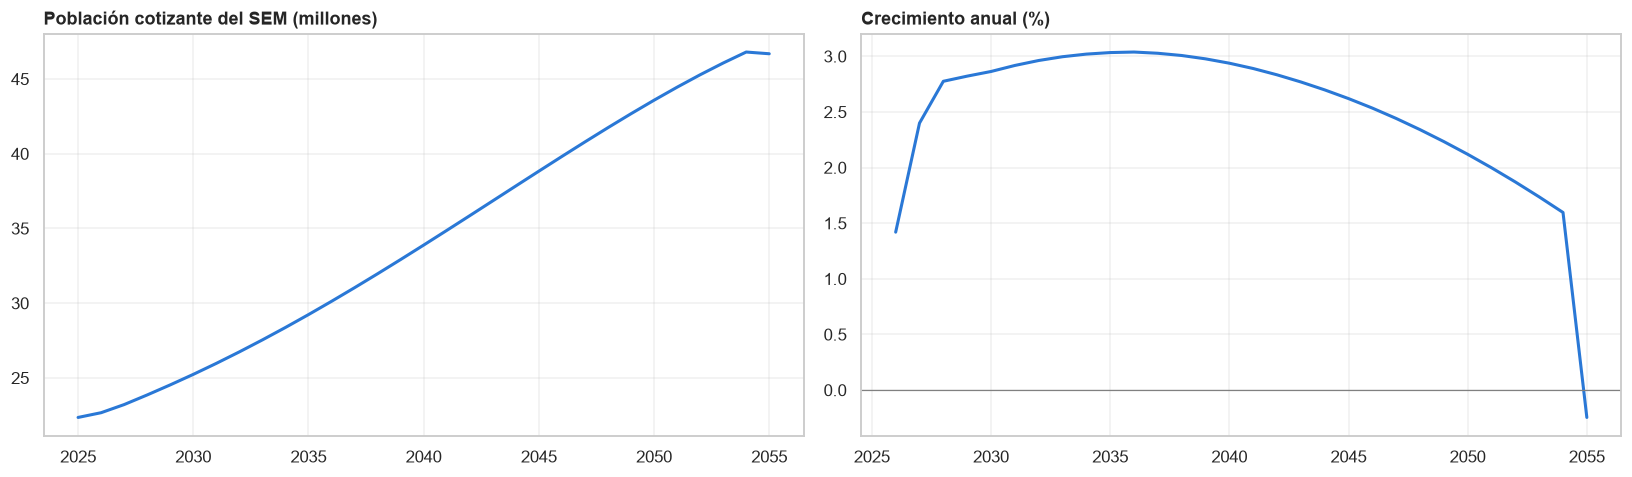

In [114]:
stock_sem = resultados_poblacion.groupby("anio")["personas"].sum()
crecimiento_sem = stock_sem.pct_change() * 100

fig, ejes = plt.subplots(1, 2, figsize=(15, 4.5))
ejes[0].plot(stock_sem.index, stock_sem / 1e6, color="#2a78d6", linewidth=2)
ejes[0].set_title("Población cotizante del SEM (millones)", loc="left", fontweight="bold")
ejes[1].plot(crecimiento_sem.index, crecimiento_sem, color="#2a78d6", linewidth=2)
ejes[1].axhline(0, color="gray", linewidth=0.8)
ejes[1].set_title("Crecimiento anual (%)", loc="left", fontweight="bold")
for eje in ejes:
    eje.grid(alpha=0.3)
plt.tight_layout()
guardar_grafica("14_4_poblacion_sem")
plt.show()

Gráfica guardada: graficas/reporte\14_4_edad_mediana_sem.png


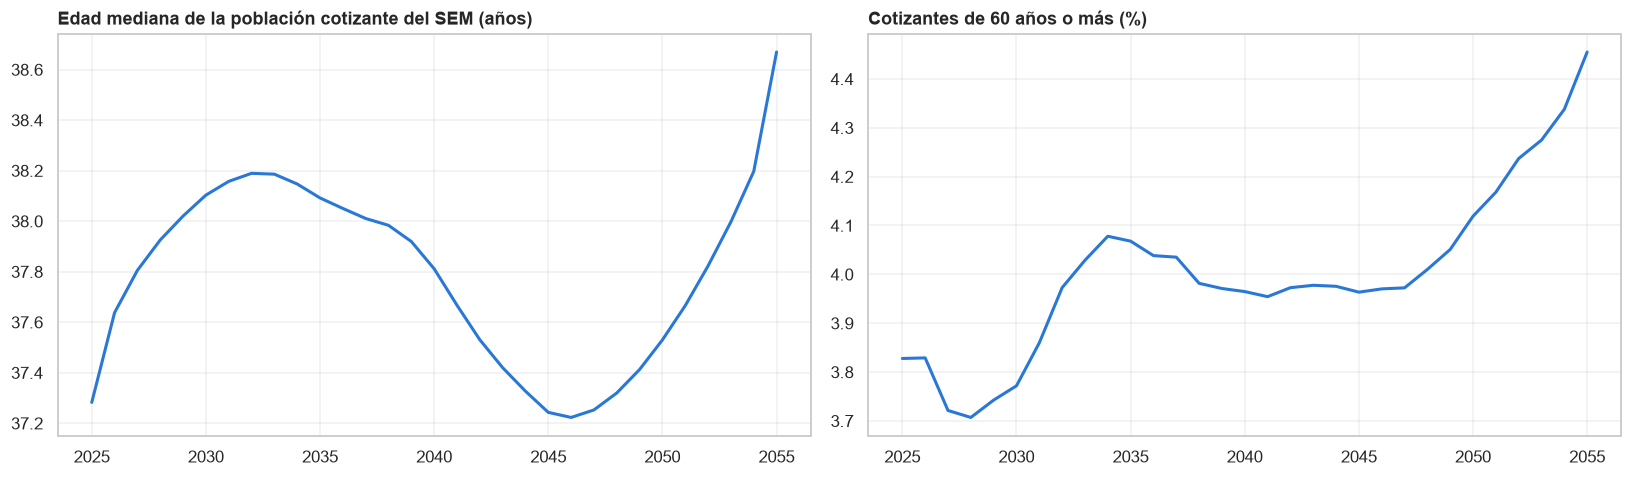

,edad_mediana,pct_60_mas
anio,,
2025,37.28,3.83
2030,38.10,3.77
2040,37.81,3.96
2050,37.53,4.12
2055,38.67,4.46


In [115]:
def edad_mediana(edades, personas):
    personas = np.array(personas, dtype=float)
    acumulado = np.cumsum(personas) / personas.sum()
    posicion = np.searchsorted(acumulado, 0.5)
    anterior = 0 if posicion == 0 else acumulado[posicion - 1]
    return edades[posicion] + (0.5 - anterior) / (acumulado[posicion] - anterior)


por_edad_sem = resultados_poblacion.groupby(["anio", "edad"])["personas"].sum().reset_index()
filas_edad = []
for anio in por_edad_sem["anio"].unique():
    tabla = por_edad_sem.loc[por_edad_sem["anio"] == anio]
    mediana = edad_mediana(tabla["edad"].values, tabla["personas"].values)
    pct_60 = tabla.loc[tabla["edad"] >= 60, "personas"].sum() / tabla["personas"].sum() * 100
    filas_edad.append([anio, mediana, pct_60])
edad_sem = pd.DataFrame(filas_edad, columns=["anio", "edad_mediana", "pct_60_mas"]).set_index("anio")

fig, ejes = plt.subplots(1, 2, figsize=(15, 4.5))
ejes[0].plot(edad_sem.index, edad_sem["edad_mediana"], color="#2a78d6", linewidth=2)
ejes[0].set_title("Edad mediana de la población cotizante del SEM (años)", loc="left", fontweight="bold")
ejes[1].plot(edad_sem.index, edad_sem["pct_60_mas"], color="#2a78d6", linewidth=2)
ejes[1].set_title("Cotizantes de 60 años o más (%)", loc="left", fontweight="bold")
for eje in ejes:
    eje.grid(alpha=0.3)
plt.tight_layout()
guardar_grafica("14_4_edad_mediana_sem")
plt.show()
edad_sem.loc[[ANIO_INICIO_COHORTES, 2030, 2040, 2050, ANIO_FINAL]].round(2)

Gráfica guardada: graficas/reporte\14_4_flujos_sem.png


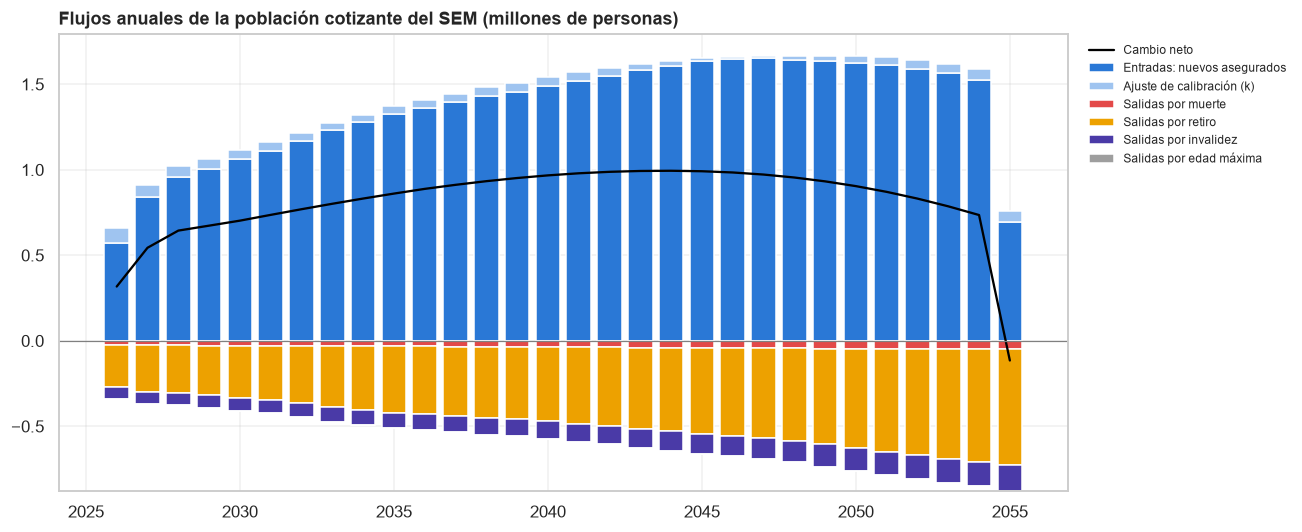

Flujos acumulados 2026-2055 (millones de personas):


entradas_nuevos        40.76
salidas_muerte          1.13
salidas_retiro         13.52
salidas_invalidez       3.18
salidas_edad_maxima     0.00
ajuste_k                1.41
cambio_neto            24.33
dtype: float64

In [116]:
columnas_salida = ["salidas_muerte", "salidas_retiro", "salidas_invalidez", "salidas_edad_maxima"]
flujos_total = resultados_flujos.groupby("anio")[["entradas_nuevos", "ajuste_k"] + columnas_salida + ["stock_inicial", "stock_final"]].sum()
flujos_total["cambio_neto"] = flujos_total["stock_final"] - flujos_total["stock_inicial"]

colores_salida = {"salidas_muerte": "#e34948", "salidas_retiro": "#eda100", "salidas_invalidez": "#4a3aa7", "salidas_edad_maxima": "#9e9e9e"}
nombres_salida = {"salidas_muerte": "Salidas por muerte", "salidas_retiro": "Salidas por retiro",
                  "salidas_invalidez": "Salidas por invalidez", "salidas_edad_maxima": "Salidas por edad máxima"}

plt.figure(figsize=(12, 5))
plt.bar(flujos_total.index, flujos_total["entradas_nuevos"] / 1e6, color="#2a78d6", label="Entradas: nuevos asegurados")
plt.bar(flujos_total.index, flujos_total["ajuste_k"] / 1e6, bottom=flujos_total["entradas_nuevos"] / 1e6, color="#9fc4f0",
        label="Ajuste de calibración (k)")
base_barra = np.zeros(len(flujos_total))
for columna in columnas_salida:
    plt.bar(flujos_total.index, -flujos_total[columna] / 1e6, bottom=-base_barra, color=colores_salida[columna], label=nombres_salida[columna])
    base_barra = base_barra + flujos_total[columna].values / 1e6
plt.plot(flujos_total.index, flujos_total["cambio_neto"] / 1e6, color="black", linewidth=1.5, label="Cambio neto")
plt.axhline(0, color="gray", linewidth=0.8)
plt.title("Flujos anuales de la población cotizante del SEM (millones de personas)", loc="left", fontweight="bold")
plt.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
guardar_grafica("14_4_flujos_sem")
plt.show()

print(f"Flujos acumulados {ANIO_INICIO_COHORTES + 1}-{ANIO_FINAL} (millones de personas):")
(flujos_total[["entradas_nuevos"] + columnas_salida + ["ajuste_k", "cambio_neto"]].sum() / 1e6).round(2)

## 14.5 Matrices de parámetros de los escenarios (aquí se capturan los valores)

**Matriz 1. `variantes_demograficas`** (una fila por variante):

* `desv_nacimientos_pct`: % de cambio en los derechohabientes **nacidos después de `ANIO_BASE`** (aproxima un cambio en la TGF). Entra poco a poco según el año de nacimiento y llega completo en `anio_pleno_nacimientos`. Ejemplo: si la TGF pasa de 1.6 a 1.3, los nacimientos bajan alrededor de 19 % (`-19`).
* `desv_mayores_pct`: % de cambio en los derechohabientes de `EDAD_MAYORES` años o más **al `ANIO_FINAL`**, en línea recta desde `ANIO_BASE` (aproxima menor o mayor mortalidad). `+5` = 5 % más adultos mayores en 2055.

**Matriz 2. `trayectorias_formalidad`** (una fila por trayectoria). Los cambios son **puntos porcentuales (pp) que se suman a la tasa de afiliación de la ENIGH** (sección 13.4):

* `desv_tasa_dh_pp`: pp que se suman en **todos** los rangos menores de `EDAD_MAYORES`. `5` = la tasa de cada rango sube 5 puntos (por ejemplo, de 45 % a 50 %).
* `anio_meta`: el cambio crece en línea recta desde `ANIO_BASE` hasta este año y después se mantiene.

**Matriz 2b. `pp_por_rango`**: pp adicionales **solo para los rangos que se escriban**, para experimentos heterogéneos (por ejemplo, afiliar solo a los jóvenes). Se suman a `desv_tasa_dh_pp` y aplican a cualquier edad. Los rangos que no aparecen quedan en 0. La tasa nunca pasa de 100 %.

**Referencia para elegir los pp:** la columna `subordinados_sin_imss_pp` de la sección 13.4 (se repite abajo) dice cuántos puntos de cada rango trabajan como subordinados sin IMSS.

**Matriz 3. `dimensiones`:** qué valores entran a la rejilla. `g_costo_unitario` es el crecimiento real anual del costo por caso.

In [117]:
EDAD_MAYORES = 60

# ======================= MATRIZ 1: VARIANTES DEMOGRÁFICAS (VALORES ILUSTRATIVOS) =======================
variantes_demograficas = pd.DataFrame(
    columns=["variante", "desv_nacimientos_pct", "anio_pleno_nacimientos", "desv_mayores_pct"],
    data=[
        ["Alta fecundidad",           10.0, 2030,  0.0],
        ["Envejecimiento lento",       0.0, 2030, -5.0],
        ["Envejecimiento acelerado", -20.0, 2030,  5.0],
    ],
)

# ======================= MATRIZ 2: TRAYECTORIAS DE AFILIACIÓN (VALORES ILUSTRATIVOS) =======================
# desv_tasa_dh_pp: puntos porcentuales que se suman a la tasa ENIGH de todos los rangos menores de EDAD_MAYORES
trayectorias_formalidad = pd.DataFrame(
    columns=["trayectoria", "desv_tasa_dh_pp", "anio_meta"],
    data=[
        ["Formalidad estable",       0.0, 2030],
        ["Afiliación +5 pp 2030",    5.0, 2030],
        ["Afiliación jóvenes 2035",  0.0, 2035],
    ],
)

# ======================= MATRIZ 2b: PUNTOS PORCENTUALES POR RANGO DE EDAD (VALORES ILUSTRATIVOS) =======================
# {trayectoria: {rango: pp}}. Se suman a desv_tasa_dh_pp; los rangos que no aparecen quedan en 0
pp_por_rango = {
    "Afiliación jóvenes 2035": {"20-29": 10.0, "30-39": 5.0},
}

# ======================= MATRIZ 3: DIMENSIONES DE LA REJILLA =======================
dimensiones = {
    "variante": ["Alta fecundidad", "Envejecimiento lento", "Envejecimiento acelerado"],
    "trayectoria": ["Formalidad estable", "Afiliación +5 pp 2030", "Afiliación jóvenes 2035"],
    "g_costo_unitario": [0.0],      # crecimiento real anual del costo por caso; puede agregar valores, p. ej. [0.0, 0.01]
}

display(variantes_demograficas)
display(trayectorias_formalidad)
print("pp por rango:", pp_por_rango)
print("Referencia (sección 13.4): tasa de afiliación y pp de subordinados sin IMSS por rango")
display(afiliacion_ingreso[["tasa_dh_imss_%", "subordinados_sin_imss_pp"]].round(1))

,variante,desv_nacimientos_pct,anio_pleno_nacimientos,desv_mayores_pct
0,Alta fecundidad,10.0,2030,0.0
1,Envejecimiento lento,0.0,2030,-5.0
2,Envejecimiento acelerado,-20.0,2030,5.0


,trayectoria,desv_tasa_dh_pp,anio_meta
0,Formalidad estable,0.0,2030
1,Afiliación +5 pp 2030,5.0,2030
2,Afiliación jóvenes 2035,0.0,2035


pp por rango: {'Afiliación jóvenes 2035': {'20-29': 10.0, '30-39': 5.0}}
Referencia (sección 13.4): tasa de afiliación y pp de subordinados sin IMSS por rango


,tasa_dh_imss_%,subordinados_sin_imss_pp
grupo_edad,,
0-9,34.2,0.9
10-19,40.4,11.2
20-29,42.2,28.5
30-39,42.8,30.1
40-49,41.2,29.0
50-59,40.9,25.0
60-69,45.3,14.4
70-79,48.6,5.1
80-89,42.9,1.3


## 14.6 La rejilla de escenarios

`itertools.product` arma todas las combinaciones de `dimensiones`. Se agrega al inicio el escenario **E0: Base**, con todas las desviaciones en cero. También se fijan los colores (uno por variante) y los estilos de línea (uno por trayectoria).

In [118]:
combinaciones = list(itertools.product(dimensiones["variante"], dimensiones["trayectoria"], dimensiones["g_costo_unitario"]))
grid_escenarios = pd.DataFrame(combinaciones, columns=["variante", "trayectoria", "g_costo_unitario"])
grid_escenarios = grid_escenarios.merge(variantes_demograficas, on="variante", how="left")
grid_escenarios = grid_escenarios.merge(trayectorias_formalidad, on="trayectoria", how="left")

# Escenario base: todo en cero (los años de "pleno" y "meta" solo evitan dividir entre cero)
fila_base = {"variante": "Base", "trayectoria": "Base", "g_costo_unitario": 0.0,
             "desv_nacimientos_pct": 0.0, "anio_pleno_nacimientos": ANIO_BASE + 1, "desv_mayores_pct": 0.0,
             "desv_tasa_dh_pp": 0.0, "anio_meta": ANIO_BASE + 1}
grid_escenarios = pd.concat([pd.DataFrame([fila_base]), grid_escenarios], ignore_index=True)

grid_escenarios.insert(0, "escenario", ["E" + str(i) for i in range(len(grid_escenarios))])
grid_escenarios["etiqueta"] = grid_escenarios["escenario"] + ": " + grid_escenarios["variante"] + " / " + grid_escenarios["trayectoria"]
grid_escenarios.loc[0, "etiqueta"] = "E0: Base"

# Colores por variante y estilos por trayectoria
COLORES_VARIANTE = {"Base": "black"}
colores = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
for i in range(len(dimensiones["variante"])):
    COLORES_VARIANTE[dimensiones["variante"][i]] = colores[i]
ESTILOS_TRAYECTORIA = {"Base": "-"}
estilos = ["-", "--", ":", "-."]
for i in range(len(dimensiones["trayectoria"])):
    ESTILOS_TRAYECTORIA[dimensiones["trayectoria"][i]] = estilos[i]

print("Escenarios:", len(grid_escenarios), "(incluye la base)")
grid_escenarios

Escenarios: 10 (incluye la base)


,escenario,variante,trayectoria,g_costo_unitario,desv_nacimientos_pct,anio_pleno_nacimientos,desv_mayores_pct,desv_tasa_dh_pp,anio_meta,etiqueta
0,E0,Base,Base,0.0,0.0,2026,0.0,0.0,2026,E0: Base
1,E1,Alta fecundidad,Formalidad estable,0.0,10.0,2030,0.0,0.0,2030,E1: Alta fecundidad / Formalidad estable
2,E2,Alta fecundidad,Afiliación +5 pp 2030,0.0,10.0,2030,0.0,5.0,2030,E2: Alta fecundidad / Afiliación +5 pp 2030
3,E3,Alta fecundidad,Afiliación jóvenes 2035,0.0,10.0,2030,0.0,0.0,2035,E3: Alta fecundidad / Afiliación jóvenes 2035
4,E4,Envejecimiento lento,Formalidad estable,0.0,0.0,2030,-5.0,0.0,2030,E4: Envejecimiento lento / Formalidad estable
5,E5,Envejecimiento lento,Afiliación +5 pp 2030,0.0,0.0,2030,-5.0,5.0,2030,E5: Envejecimiento lento / Afiliación +5 pp 2030
6,E6,Envejecimiento lento,Afiliación jóvenes 2035,0.0,0.0,2030,-5.0,0.0,2035,E6: Envejecimiento lento / Afiliación jóvenes ...
7,E7,Envejecimiento acelerado,Formalidad estable,0.0,-20.0,2030,5.0,0.0,2030,E7: Envejecimiento acelerado / Formalidad estable
8,E8,Envejecimiento acelerado,Afiliación +5 pp 2030,0.0,-20.0,2030,5.0,5.0,2030,E8: Envejecimiento acelerado / Afiliación +5 p...
9,E9,Envejecimiento acelerado,Afiliación jóvenes 2035,0.0,-20.0,2030,5.0,0.0,2035,E9: Envejecimiento acelerado / Afiliación jóve...


## 14.7 Derechohabientes por escenario

Para cada escenario se parte de los derechohabientes de la sección 13.4 (por año, edad simple y sexo) y se multiplican por tres factores:

| Factor | A quién afecta | Valor |
|---|---|---|
| Nacimientos | Nacidos después de `ANIO_BASE` (`año − edad > ANIO_BASE`) | `1 + desv_nacimientos_pct/100 × avance(año de nacimiento, ANIO_BASE, anio_pleno_nacimientos)` |
| Mayores | `EDAD_MAYORES` años o más | `1 + desv_mayores_pct/100 × avance(año, ANIO_BASE, ANIO_FINAL)` |
| Afiliación | Menores de `EDAD_MAYORES` años (`desv_tasa_dh_pp`) y los rangos de `pp_por_rango` | `tasa del escenario / tasa ENIGH`, con `tasa del escenario = mín(100 %, tasa ENIGH + pp/100 × avance(año, ANIO_BASE, anio_meta))` |

`avance(x, inicio, fin)` vale 0 antes de `inicio`, 1 desde `fin` y crece en línea recta entre ambos.

La afiliación se captura en puntos porcentuales, pero se aplica como **factor** (`factor_formalidad`), igual que los otros dos. Así la contabilidad de flujos de la sección 14.8 no cambia.

**Lectura:** al 2055, una TGF más baja solo afecta a los menores de 30 años (los nacidos después de 2025). Los adultos mayores de 2055 ya nacieron, así que en ellos solo influye la mortalidad (`desv_mayores_pct`).

Diferencia máxima E0 vs. sección 13.4: 0.0
Gráfica guardada: graficas/reporte\14_7_derechohabientes_por_escenario.png


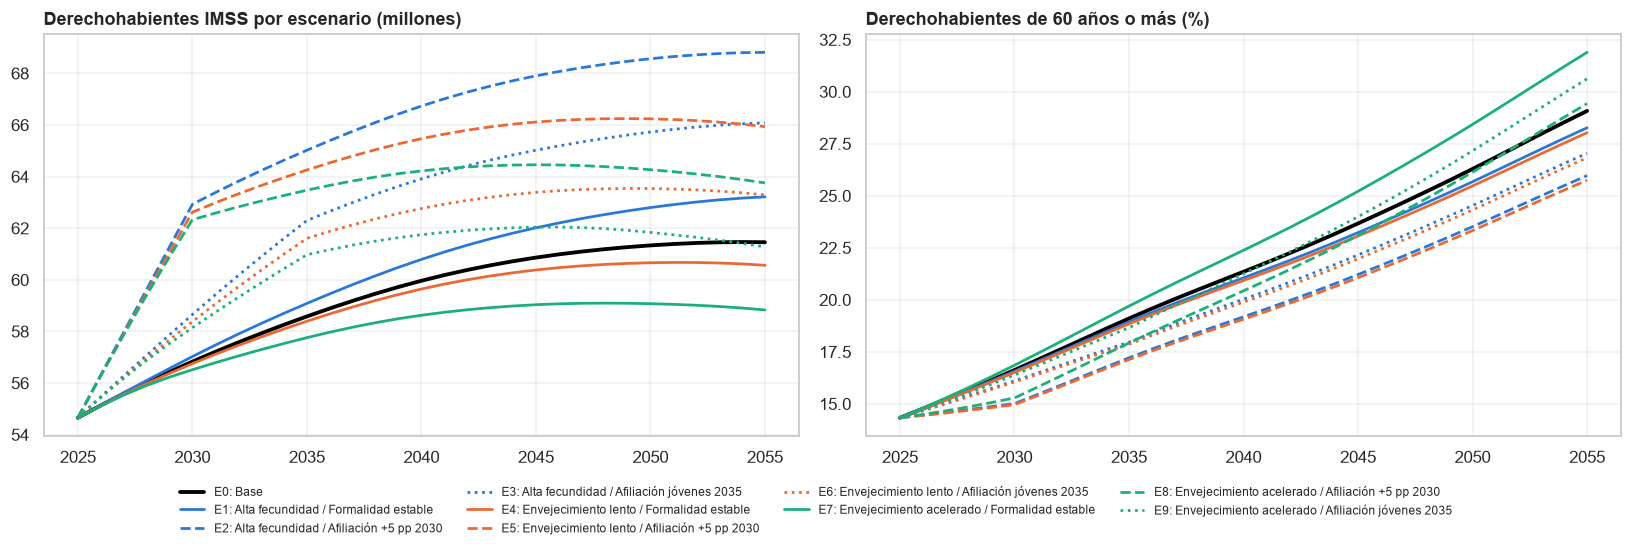

escenario,E0,E1,E2,E3,E4,E5,E6,E7,E8,E9
anio,,,,,,,,,,
2025,54.65,54.65,54.65,54.65,54.65,54.65,54.65,54.65,54.65,54.65
2030,56.83,57.03,62.92,58.65,56.75,62.62,58.38,56.52,62.33,58.14
2040,59.96,60.79,66.73,63.91,59.64,65.47,62.76,58.63,64.22,61.75
2055,61.46,63.21,68.81,66.08,60.56,65.93,63.29,58.83,63.75,61.28


In [119]:
def avance(valores, inicio, fin):
    # 0 antes de 'inicio', 1 desde 'fin' y en línea recta entre ambos (funciona con columnas completas)
    return np.clip((valores - inicio) / (fin - inicio), 0, 1)


lista_dh = []
for i in range(len(grid_escenarios)):
    fila = grid_escenarios.iloc[i]
    tabla = conapo[["anio", "edad", "sexo", "grupo_edad", "poblacion", "tasa_dh", "derechohabientes"]].copy()
    tabla["escenario"] = fila["escenario"]

    # (1) Nacimientos: solo cohortes nacidas después de ANIO_BASE
    anio_nacimiento = tabla["anio"] - tabla["edad"]
    factor_nacimientos = 1 + fila["desv_nacimientos_pct"] / 100 * avance(anio_nacimiento, ANIO_BASE, fila["anio_pleno_nacimientos"])
    factor_nacimientos = np.where(anio_nacimiento > ANIO_BASE, factor_nacimientos, 1.0)

    # (2) Mayores: más o menos personas de EDAD_MAYORES años o más conforme pasa el tiempo
    factor_mayores = 1 + fila["desv_mayores_pct"] / 100 * avance(tabla["anio"], ANIO_BASE, ANIO_FINAL)
    factor_mayores = np.where(tabla["edad"] >= EDAD_MAYORES, factor_mayores, 1.0)

    # (3) Afiliación: suma puntos porcentuales a la tasa ENIGH (general a menores de EDAD_MAYORES + por rango)
    pp_general = np.where(tabla["edad"] < EDAD_MAYORES, fila["desv_tasa_dh_pp"], 0.0)
    pp_rango = tabla["grupo_edad"].astype(str).map(pp_por_rango.get(fila["trayectoria"], {})).fillna(0.0).values
    pp_total = (pp_general + pp_rango) / 100 * avance(tabla["anio"], ANIO_BASE, fila["anio_meta"])
    tasa_enigh = tabla["tasa_dh"] * AJUSTE_TASA_DH
    tasa_escenario = np.clip(tasa_enigh + pp_total, 0, 1)
    factor_formalidad = np.where(tasa_enigh > 0, tasa_escenario / tasa_enigh, 1.0)

    tabla["factor_nacimientos"] = factor_nacimientos
    tabla["factor_mayores"] = factor_mayores
    tabla["factor_formalidad"] = factor_formalidad
    tabla["derechohabientes"] = tabla["derechohabientes"] * factor_nacimientos * factor_mayores * factor_formalidad
    lista_dh.append(tabla)

dh_edad_esc = pd.concat(lista_dh, ignore_index=True)

# Por rango de edad (para los costos) y totales por escenario
dh_esc = dh_edad_esc.groupby(["escenario", "anio", "grupo_edad", "sexo"], observed=False)["derechohabientes"].sum().reset_index()
dh_esc["grupo_edad"] = dh_esc["grupo_edad"].astype(str)
dh_total_esc = dh_edad_esc.groupby(["anio", "escenario"])["derechohabientes"].sum().unstack("escenario")
dh_mayores_esc = dh_edad_esc.loc[dh_edad_esc["edad"] >= EDAD_MAYORES].groupby(["anio", "escenario"])["derechohabientes"].sum().unstack("escenario")
pct_mayores_esc = dh_mayores_esc / dh_total_esc * 100
# Derechohabientes de 15 a 64 años: se usa en 16.4 para mover los ingresos de cada escenario
dh_trabajo_esc = dh_edad_esc.loc[(dh_edad_esc["edad"] >= 15) & (dh_edad_esc["edad"] < 65)].groupby(["anio", "escenario"])["derechohabientes"].sum().unstack("escenario")

# Verificación: E0 = derechohabientes de la sección 13.4
print("Diferencia máxima E0 vs. sección 13.4:", round((dh_total_esc["E0"] - poblacion_rango.sum(axis=1)).abs().max(), 4))

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
for i in range(len(grid_escenarios)):
    fila = grid_escenarios.iloc[i]
    estilo = dict(color=COLORES_VARIANTE[fila["variante"]], linestyle=ESTILOS_TRAYECTORIA[fila["trayectoria"]],
                  linewidth=2.5 if fila["escenario"] == "E0" else 1.8)
    ejes[0].plot(dh_total_esc.index, dh_total_esc[fila["escenario"]] / 1e6, label=fila["etiqueta"], **estilo)
    ejes[1].plot(pct_mayores_esc.index, pct_mayores_esc[fila["escenario"]], **estilo)
ejes[0].set_title("Derechohabientes IMSS por escenario (millones)", loc="left", fontweight="bold")
ejes[1].set_title(f"Derechohabientes de {EDAD_MAYORES} años o más (%)", loc="left", fontweight="bold")
for eje in ejes:
    eje.grid(alpha=0.3)
fig.legend(*ejes[0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False, fontsize=8)
plt.tight_layout(rect=[0, 0.1, 1, 1])
guardar_grafica("14_7_derechohabientes_por_escenario")
plt.show()

(dh_total_esc.loc[[ANIO_BASE, 2030, 2040, ANIO_FINAL]] / 1e6).round(2)

## 14.8 Stock y flujos de derechohabientes: ¿por dónde entra y sale la gente?

El modelo **no** se construye con stocks y flujos: los derechohabientes salen de multiplicar CONAPO × tasa × factores. Pero cada año se puede **contabilizar** de dónde viene el cambio, siguiendo a cada cohorte (las personas de edad *a* en el año *t* son las de edad *a − 1* en *t − 1*):

| Flujo | Cálculo para cada cohorte | Lectura |
|---|---|---|
| **Nacimientos (CONAPO)** | derechohabientes de edad 0 sin factores de escenario | Entradas por nacer |
| **Nacimientos: cambio por TGF** | edad 0 × (`factor_nacimientos` − 1) | Más o menos bebés que CONAPO |
| **Mortalidad y migración (CONAPO)** | (población_t − población_(t−1)) × tasa y factores del año anterior | Casi siempre negativa: muertes y migración neta |
| **Afiliación por edad (ENIGH)** | población_t × (tasa_t − tasa_(t−1)) | Al cambiar de rango cambia la tasa (por ejemplo, al entrar a la edad de trabajar) |
| **Formalidad (escenario)** | cambio de `factor_formalidad` (incluye a los bebés) | Entradas o salidas por más o menos formalidad |
| **Longevidad (escenario)** | cambio de `factor_mayores` | Más o menos adultos mayores que CONAPO |
| **Salidas por edad máxima** | quienes tenían 109 años | El archivo de CONAPO termina en 109 |

Se cumple: `stock_t = stock_(t−1) + suma de los flujos`. La celda lo verifica.

**Gráfica:** un panel por escenario. Entradas hacia arriba, salidas hacia abajo (millones de personas por año); la línea negra es el cambio neto.

In [120]:
columnas_valor = ["poblacion", "tasa_dh", "factor_nacimientos", "factor_mayores", "factor_formalidad", "derechohabientes"]

# Cada cohorte en el año t (actual) y en el año t-1 (anterior, un año más joven)
actual = dh_edad_esc[["escenario", "anio", "edad", "sexo"] + columnas_valor].copy()
anterior = actual.copy()
anterior["anio"] = anterior["anio"] + 1
anterior["edad"] = anterior["edad"] + 1
anterior = anterior.rename(columns={columna: columna + "_ant" for columna in columnas_valor})

cohortes = actual.merge(anterior, on=["escenario", "anio", "edad", "sexo"], how="inner")
tasa = cohortes["tasa_dh"] * AJUSTE_TASA_DH
tasa_ant = cohortes["tasa_dh_ant"] * AJUSTE_TASA_DH
factores_ant = cohortes["factor_nacimientos_ant"] * cohortes["factor_mayores_ant"] * cohortes["factor_formalidad_ant"]
cohortes["Mortalidad y migración (CONAPO)"] = (cohortes["poblacion"] - cohortes["poblacion_ant"]) * tasa_ant * factores_ant
cohortes["Afiliación por edad (ENIGH)"] = cohortes["poblacion"] * (tasa - tasa_ant) * factores_ant
cohortes["Formalidad (escenario)"] = (cohortes["poblacion"] * tasa * cohortes["factor_nacimientos"] * cohortes["factor_mayores"]
                                      * (cohortes["factor_formalidad"] - cohortes["factor_formalidad_ant"]))
cohortes["Longevidad (escenario)"] = (cohortes["poblacion"] * tasa * cohortes["factor_nacimientos"] * cohortes["factor_formalidad_ant"]
                                      * (cohortes["factor_mayores"] - cohortes["factor_mayores_ant"]))

# Nacimientos: edad 0 a partir del segundo año
bebes = actual.loc[(actual["edad"] == 0) & (actual["anio"] > ANIO_BASE)].copy()
tasa_bebes = bebes["tasa_dh"] * AJUSTE_TASA_DH
bebes["Nacimientos (CONAPO)"] = bebes["poblacion"] * tasa_bebes
bebes["Nacimientos: cambio por TGF"] = bebes["poblacion"] * tasa_bebes * (bebes["factor_nacimientos"] - 1)
bebes["Formalidad (escenario)"] = bebes["poblacion"] * tasa_bebes * bebes["factor_nacimientos"] * (bebes["factor_formalidad"] - 1)

# Salidas por edad máxima: quienes tenían la edad máxima el año anterior
edad_maxima = actual["edad"].max()
viejos = anterior.loc[(anterior["edad"] == edad_maxima + 1) & (anterior["anio"] <= ANIO_FINAL)].copy()
viejos["Salidas por edad máxima"] = -viejos["derechohabientes_ant"]

FLUJOS = ["Nacimientos (CONAPO)", "Nacimientos: cambio por TGF", "Formalidad (escenario)", "Afiliación por edad (ENIGH)",
          "Longevidad (escenario)", "Mortalidad y migración (CONAPO)", "Salidas por edad máxima"]
partes = [cohortes.groupby(["escenario", "anio"])[["Mortalidad y migración (CONAPO)", "Afiliación por edad (ENIGH)",
                                                    "Formalidad (escenario)", "Longevidad (escenario)"]].sum(),
          bebes.groupby(["escenario", "anio"])[["Nacimientos (CONAPO)", "Nacimientos: cambio por TGF", "Formalidad (escenario)"]].sum(),
          viejos.groupby(["escenario", "anio"])[["Salidas por edad máxima"]].sum()]
flujos_dh = pd.concat(partes).groupby(["escenario", "anio"]).sum()[FLUJOS].reset_index()

# Verificación: cambio del stock = suma de los flujos
stock = dh_edad_esc.groupby(["escenario", "anio"])["derechohabientes"].sum().rename("stock").reset_index()
stock["cambio_stock"] = stock.groupby("escenario")["stock"].diff()
flujos_dh = flujos_dh.merge(stock, on=["escenario", "anio"], how="left")
flujos_dh["cambio_neto"] = flujos_dh[FLUJOS].sum(axis=1)
print("Diferencia máxima entre el cambio del stock y la suma de los flujos:",
      round((flujos_dh["cambio_neto"] - flujos_dh["cambio_stock"]).abs().max(), 4))

Diferencia máxima entre el cambio del stock y la suma de los flujos: 0.0


Gráfica guardada: graficas/reporte\14_8_flujos_derechohabientes.png


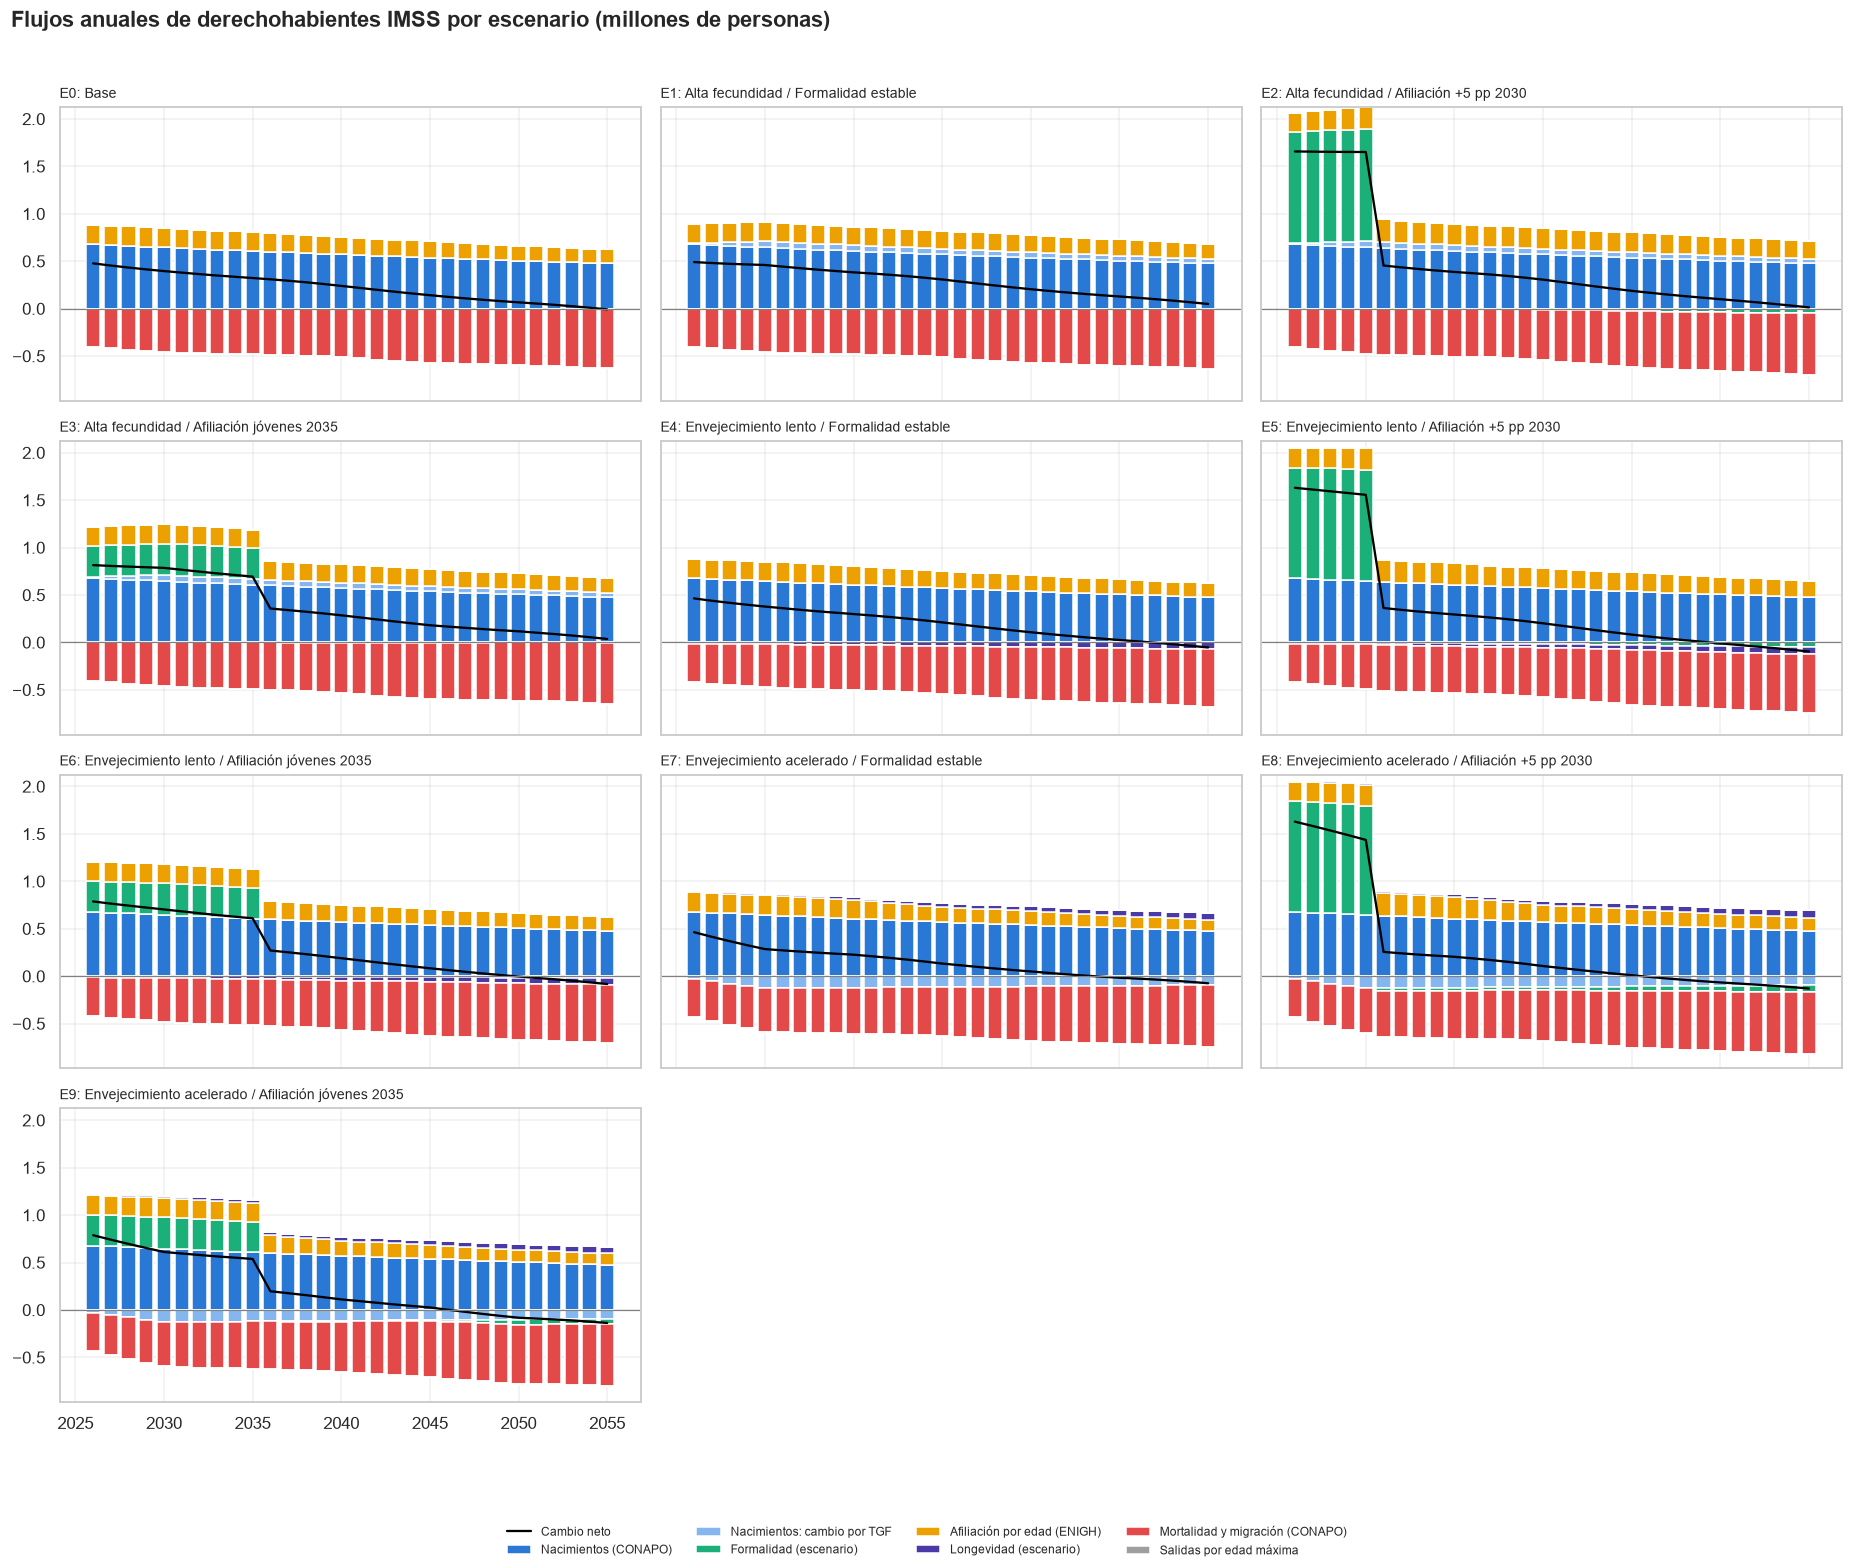

Flujos acumulados 2026-2055 (millones de personas):


,etiqueta,Nacimientos (CONAPO),Nacimientos: cambio por TGF,Formalidad (escenario),Afiliación por edad (ENIGH),Longevidad (escenario),Mortalidad y migración (CONAPO),Salidas por edad máxima,cambio_neto
escenario,,,,,,,,,
E0,E0: Base,17.16,0.00,0.00,5.41,0.00,-15.76,-0.0,6.80
E1,E1: Alta fecundidad / Formalidad estable,17.16,1.58,0.00,5.63,0.00,-15.81,-0.0,8.56
E2,E2: Alta fecundidad / Afiliación +5 pp 2030,17.16,1.58,5.37,6.39,0.00,-16.34,-0.0,14.16
E3,E3: Alta fecundidad / Afiliación jóvenes 2035,17.16,1.58,3.19,5.62,0.00,-16.13,-0.0,11.43
E4,E4: Envejecimiento lento / Formalidad estable,17.16,0.00,0.00,5.42,-1.21,-15.47,-0.0,5.91
E5,E5: Envejecimiento lento / Afiliación +5 pp 2030,17.16,0.00,5.24,6.16,-1.28,-16.00,-0.0,11.28
E6,E6: Envejecimiento lento / Afiliación jóvenes ...,17.16,0.00,3.05,5.42,-1.21,-15.79,-0.0,8.63
E7,E7: Envejecimiento acelerado / Formalidad estable,17.16,-3.16,0.00,4.95,1.21,-15.97,-0.0,4.18
E8,E8: Envejecimiento acelerado / Afiliación +5 p...,17.16,-3.16,4.70,5.62,1.28,-16.49,-0.0,9.10


In [121]:
COLORES_FLUJO = {"Nacimientos (CONAPO)": "#2a78d6", "Nacimientos: cambio por TGF": "#86b6ef", "Formalidad (escenario)": "#1baf7a",
                 "Afiliación por edad (ENIGH)": "#eda100", "Longevidad (escenario)": "#4a3aa7",
                 "Mortalidad y migración (CONAPO)": "#e34948", "Salidas por edad máxima": "#9e9e9e"}

numero = len(grid_escenarios)
columnas_graf = 3
filas_graf = int(np.ceil(numero / columnas_graf))
fig, ejes = plt.subplots(filas_graf, columnas_graf, figsize=(17, 3.6 * filas_graf), sharex=True, sharey=True)
ejes = np.array(ejes).reshape(-1)
for i in range(numero):
    fila = grid_escenarios.iloc[i]
    datos = flujos_dh.loc[flujos_dh["escenario"] == fila["escenario"]]
    eje = ejes[i]
    arriba = np.zeros(len(datos))      # las barras positivas se apilan hacia arriba
    abajo = np.zeros(len(datos))       # las negativas, hacia abajo
    for flujo in FLUJOS:
        valores = datos[flujo].values / 1e6
        positivos = np.where(valores > 0, valores, 0)
        negativos = np.where(valores < 0, valores, 0)
        eje.bar(datos["anio"], positivos, bottom=arriba, color=COLORES_FLUJO[flujo], label=flujo)
        eje.bar(datos["anio"], negativos, bottom=abajo, color=COLORES_FLUJO[flujo])
        arriba = arriba + positivos
        abajo = abajo + negativos
    eje.plot(datos["anio"], datos["cambio_neto"] / 1e6, color="black", linewidth=1.5, label="Cambio neto")
    eje.axhline(0, color="gray", linewidth=0.8)
    eje.set_title(fila["etiqueta"], fontsize=9, loc="left")
    eje.grid(alpha=0.3)
for j in range(numero, len(ejes)):
    ejes[j].axis("off")
fig.legend(*ejes[0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False, fontsize=8)
fig.suptitle("Flujos anuales de derechohabientes IMSS por escenario (millones de personas)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=[0, 0.07, 1, 0.97])
guardar_grafica("14_8_flujos_derechohabientes")
plt.show()

flujos_acumulados_dh = flujos_dh.groupby("escenario")[FLUJOS + ["cambio_neto"]].sum() / 1e6
flujos_acumulados_dh.insert(0, "etiqueta", grid_escenarios.set_index("escenario")["etiqueta"])
print(f"Flujos acumulados {ANIO_BASE + 1}-{ANIO_FINAL} (millones de personas):")
flujos_acumulados_dh.round(2)

## 14.9 Costos por escenario

Misma incidencia y mismo costo por caso de la sección 13.5 (por GRD, rango y sexo); cambia solo la población (`dh_esc`, por rango y sexo). Por eso **E0 da exactamente lo mismo que la sección 13** (se verifica en la siguiente celda).

Gráfica guardada: graficas/reporte\14_9_costo_por_escenario.png


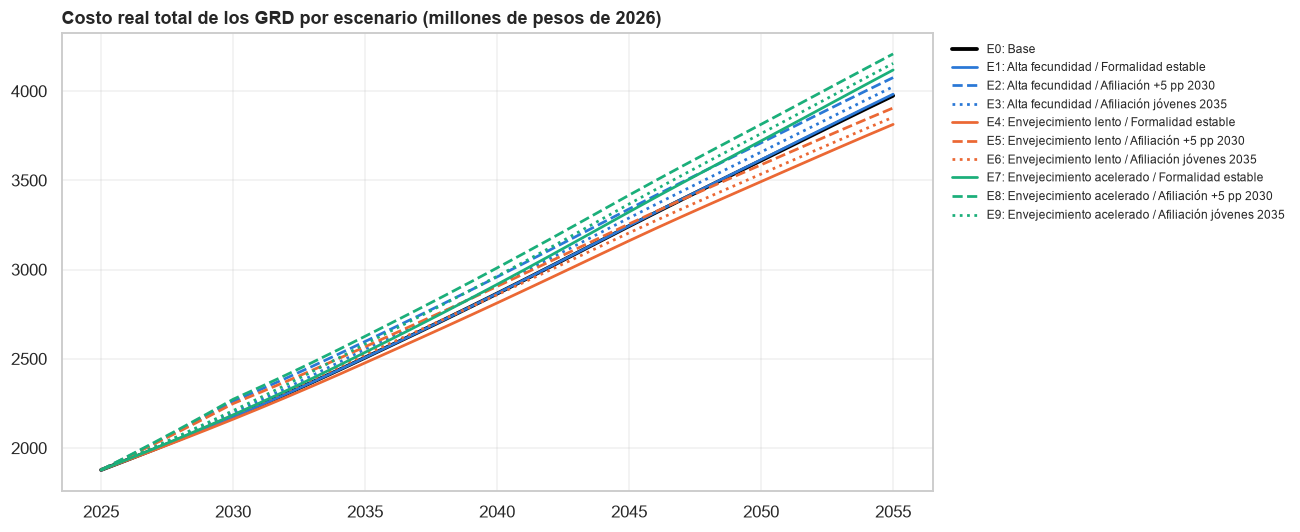

escenario,E0,E1,E2,E3,E4,E5,E6,E7,E8,E9
anio,,,,,,,,,,
2025,1877.0,1877.0,1877.0,1877.0,1877.0,1877.0,1877.0,1877.0,1877.0,1877.0
2030,2173.3,2173.4,2260.7,2197.2,2161.2,2248.6,2185.0,2185.4,2272.8,2209.2
2040,2865.2,2865.8,2958.6,2911.6,2812.6,2905.4,2858.4,2916.6,3009.2,2962.4
2055,3974.1,3982.5,4075.6,4024.4,3813.2,3905.3,3853.4,4118.3,4208.2,4155.0


In [122]:
base_grd_esc = incidencia[["grd", "grupo_edad", "sexo", "incidencia_100mil", "costo_promedio_caso"]].copy()
base_grd_esc["grupo_edad"] = base_grd_esc["grupo_edad"].astype(str)
base_grd_esc = base_grd_esc.loc[base_grd_esc["incidencia_100mil"] > 0]

costos_esc = base_grd_esc.merge(dh_esc, on=["grupo_edad", "sexo"], how="left")
costos_esc = costos_esc.merge(grid_escenarios[["escenario", "g_costo_unitario"]], on="escenario", how="left")
costos_esc["casos"] = costos_esc["incidencia_100mil"] * costos_esc["derechohabientes"] / 100000
costos_esc["costo_real"] = (costos_esc["casos"] * costos_esc["costo_promedio_caso"]
                            * (1 + costos_esc["g_costo_unitario"]) ** (costos_esc["anio"] - ANIO_BASE)
                            / costos_esc["anio"].map(deflactor))

costo_total = costos_esc.groupby(["anio", "escenario"])["costo_real"].sum().unstack("escenario") / 1e6

plt.figure(figsize=(12, 5))
for i in range(len(grid_escenarios)):
    fila = grid_escenarios.iloc[i]
    grosor = 2.5 if fila["escenario"] == "E0" else 1.8
    plt.plot(costo_total.index, costo_total[fila["escenario"]], color=COLORES_VARIANTE[fila["variante"]],
             linestyle=ESTILOS_TRAYECTORIA[fila["trayectoria"]], linewidth=grosor, label=fila["etiqueta"])
plt.title("Costo real total de los GRD por escenario (millones de pesos de 2026)", loc="left", fontweight="bold")
plt.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
guardar_grafica("14_9_costo_por_escenario")
plt.show()

costo_total.loc[[ANIO_BASE, 2030, 2040, ANIO_FINAL]].round(1)

In [123]:
# Verificación: el escenario base (E0) usa la misma población, incidencia y costos que la sección 13,
# así que su costo total debe ser igual al "Total GRD" de costo_grd (sección 13.6)
comparacion_13 = pd.DataFrame({"Sección 13 (Total GRD)": costo_grd.loc[anios_proyeccion, "Total GRD"],
                               "Sección 14 (E0)": costo_total.loc[anios_proyeccion, "E0"]})
comparacion_13["diferencia_%"] = (comparacion_13["Sección 14 (E0)"] / comparacion_13["Sección 13 (Total GRD)"] - 1) * 100
print("Diferencia máxima entre E0 y la sección 13 (%):", round(comparacion_13["diferencia_%"].abs().max(), 6))
comparacion_13.loc[[ANIO_BASE, 2030, 2040, ANIO_FINAL]].round(2)

Diferencia máxima entre E0 y la sección 13 (%): 0.0


,Sección 13 (Total GRD),Sección 14 (E0),diferencia_%
anio,,,
2025,1876.97,1876.97,0.0
2030,2173.34,2173.34,-0.0
2040,2865.17,2865.17,0.0
2055,3974.10,3974.10,0.0


In [124]:
costo_grd_final = costos_esc.loc[costos_esc["anio"] == ANIO_FINAL].pivot_table(index="grd", columns="escenario", values="costo_real", aggfunc="sum") / 1e6
costo_grd_final.loc["Total"] = costo_grd_final.sum()
print(f"Costo real por GRD en {ANIO_FINAL} (millones de pesos):")
costo_grd_final.round(1)

Costo real por GRD en 2055 (millones de pesos):


escenario,E0,E1,E2,E3,E4,E5,E6,E7,E8,E9
grd,,,,,,,,,,
"Colecistectomía laparoscópica, sin exploración de vías biliares con CC",1.5,1.5,1.7,1.6,1.5,1.6,1.6,1.5,1.6,1.6
"Colecistectomía laparoscópica, sin exploración de vías biliares con CCM",3.0,3.0,3.1,3.0,2.9,3.1,2.9,3.0,3.2,3.1
"Colecistectomía laparoscópica, sin exploración de vías biliares sin CC/CCM",985.2,992.6,1067.4,1031.6,966.2,1040.1,1003.6,989.3,1061.2,1023.4
Fijacion de fractura de cadera con tornillos canulados,1139.8,1140.6,1147.3,1142.6,1085.6,1092.2,1087.5,1192.5,1198.9,1194.2
Procedimientos intraoculares sin CC/CCM,988.7,988.8,995.8,989.0,942.2,949.3,942.4,1035.2,1042.3,1035.4
Prostatectomía sin CC/CCM,90.5,90.5,91.4,90.5,86.3,87.3,86.3,94.6,95.6,94.6
Sustitucion parcial de cadera,238.7,238.7,238.9,238.7,226.9,227.1,226.9,250.5,250.8,250.6
Sustitucion total de cadera,526.7,526.8,529.8,527.4,501.6,504.6,502.2,551.6,554.6,552.1
Total,3974.1,3982.5,4075.6,4024.4,3813.2,3905.3,3853.4,4118.3,4208.2,4155.0


# 15. Pirámides poblacionales y casos quirúrgicos

**Pregunta.** ¿Cómo se ve una transición demográfica acelerada, sobre todo por la caída de la tasa global de fecundidad (TGF), en la población derechohabiente del IMSS y en los casos quirúrgicos posibles, bajo distintas trayectorias de formalidad?

Esta sección **no cambia ningún cálculo**; solo usa resultados de las secciones 13 y 14:

| Objeto | Viene de | Para qué se usa aquí |
|---|---|---|
| `resultados_poblacion` | 14.3 | Cotizantes del SEM por año, sexo y edad (primera pirámide) |
| `dh_edad_esc` | 14.7 | Derechohabientes por escenario, año, sexo y edad (segunda pirámide y tabla) |
| `pob_conapo` | 13.4 | Derechohabientes por año, rango y sexo (tercera pirámide) |
| `dh_total_esc`, `costos_esc` | 14.7 y 14.9 | Derechohabientes totales y casos proyectados por escenario |
| `grid_escenarios`, `COLORES_VARIANTE`, `ESTILOS_TRAYECTORIA` | 14.6 | Etiquetas y estilo de cada escenario |

## 15.0 Parámetros de la sección

* `CORTES_PIRAMIDE`: cortes de **10 años** para la pirámide del SEM (empieza en 15 años, así que `10-19` solo tiene 15 a 19).
* `ANIOS_PIRAMIDE`: años de la pirámide del SEM.
* `ESCENARIO_COMPARAR`: escenario que se dibuja como contorno sobre E0 en la pirámide de derechohabientes de `ANIO_FINAL`. Por defecto *Envejecimiento acelerado / Formalidad estable*.
* `ESCENARIO_GRAFICA_CASOS`: escenario de la gráfica de población + casos (15.2).

In [125]:
CORTES_PIRAMIDE = list(range(10, 111, 10))                 # 10-19, 20-29, ..., 100-109
ETIQUETAS_PIRAMIDE = [f"{inicio}-{inicio + 9}" for inicio in CORTES_PIRAMIDE[:-1]]
ANIOS_PIRAMIDE = [ANIO_INICIO_COHORTES, 2040, ANIO_FINAL]
ESCENARIO_REFERENCIA = "E0"


def buscar_escenario(variante, trayectoria, por_defecto):
    # Regresa el código (E1, E2, ...) de una combinación; si no existe, regresa por_defecto
    filtro = (grid_escenarios["variante"] == variante) & (grid_escenarios["trayectoria"] == trayectoria)
    if filtro.any():
        return grid_escenarios.loc[filtro, "escenario"].iloc[0]
    return por_defecto


ESCENARIO_COMPARAR = buscar_escenario("Envejecimiento acelerado", "Formalidad estable", grid_escenarios["escenario"].iloc[-1])
ESCENARIO_GRAFICA_CASOS = ESCENARIO_REFERENCIA

ETIQUETA_ESC = grid_escenarios.set_index("escenario")["etiqueta"]
COLOR_SEXO = {"Hombres": "#2a78d6", "Mujeres": "#eb6834"}

# ---------------- Cotizantes del SEM por año, sexo y rango de 10 años ----------------
pob_piramide = resultados_poblacion[["anio", "sexo", "edad", "personas"]].copy()
pob_piramide["rango_10"] = pd.cut(pob_piramide["edad"], bins=CORTES_PIRAMIDE, labels=ETIQUETAS_PIRAMIDE, right=False)
piramide_sem = pob_piramide.groupby(["anio", "sexo", "rango_10"], observed=False)["personas"].sum().reset_index()

print("Comparación de escenarios:", ETIQUETA_ESC[ESCENARIO_REFERENCIA], "vs.", ETIQUETA_ESC[ESCENARIO_COMPARAR])

Comparación de escenarios: E0: Base vs. E7: Envejecimiento acelerado / Formalidad estable


## 15.1 Pirámides poblacionales (cortes de 10 años)

1. **Cotizantes del SEM** en tres años (millones de personas). Se ve el corte arriba de los 60 años.
2. **Derechohabientes en `ANIO_FINAL`**, en % del total: barras de E0 y contorno negro del escenario de comparación. Comparar en % aísla el envejecimiento del tamaño de la población.
3. **Derechohabientes en `ANIO_BASE` vs. `ANIO_FINAL`** (E0), en % del total.

La tabla final da los derechohabientes (millones) y el % de 60 años o más por escenario.

Gráfica guardada: graficas/reporte\15_1_piramide_sem.png


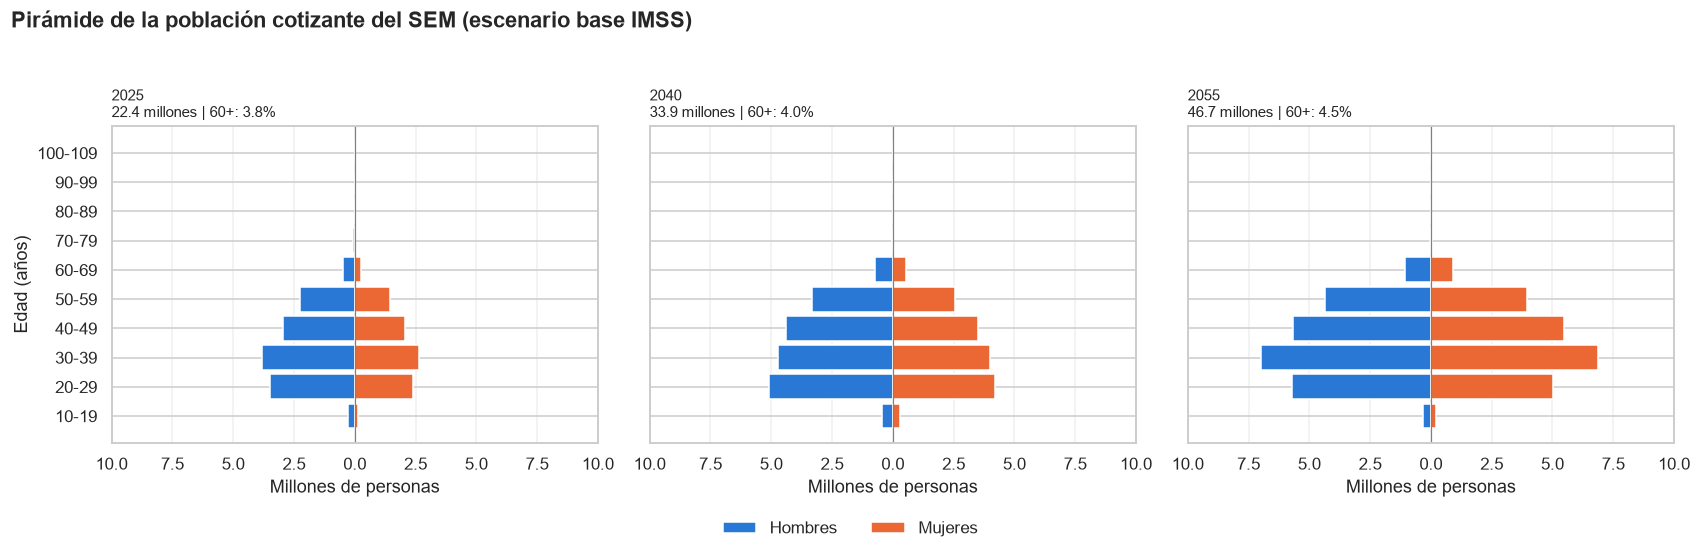

Gráfica guardada: graficas/reporte\15_1_piramide_dh_escenarios.png


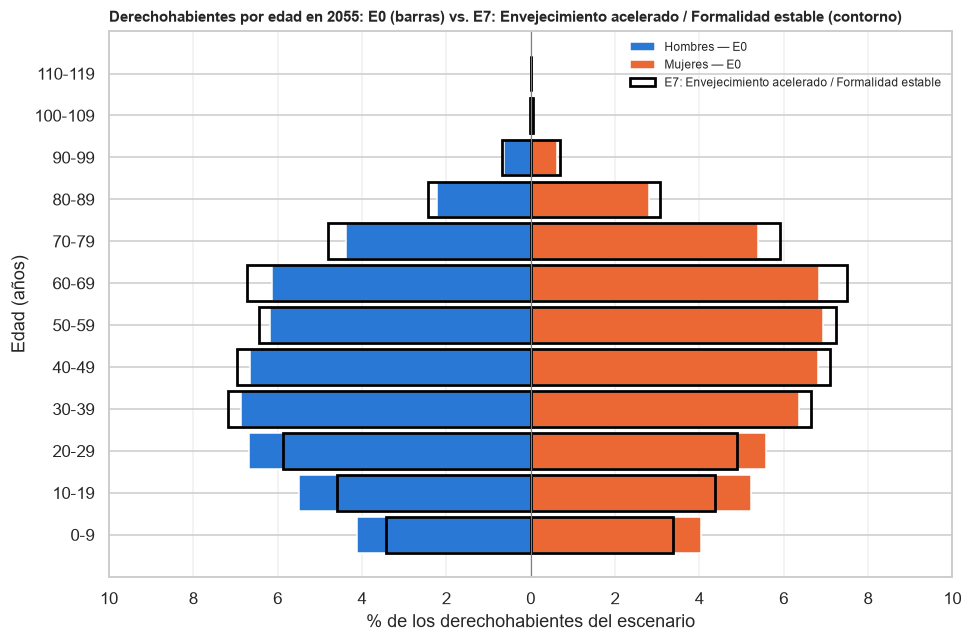

In [126]:
posiciones_pir = np.arange(len(ETIQUETAS_PIRAMIDE))

# ---------------- Figura 1: cotizantes del SEM en varios años (millones) ----------------
def datos_piramide_sem(anio):
    tabla = piramide_sem.loc[piramide_sem["anio"] == anio]
    return tabla.pivot(index="rango_10", columns="sexo", values="personas").reindex(ETIQUETAS_PIRAMIDE).fillna(0) / 1e6


maximo = max(datos_piramide_sem(anio).values.max() for anio in ANIOS_PIRAMIDE) * 1.1
fig, ejes = plt.subplots(1, len(ANIOS_PIRAMIDE), figsize=(5.2 * len(ANIOS_PIRAMIDE), 5), sharey=True)
for eje, anio in zip(np.atleast_1d(ejes), ANIOS_PIRAMIDE):
    tabla = datos_piramide_sem(anio)
    eje.barh(posiciones_pir, -tabla["Hombres"], height=0.85, color=COLOR_SEXO["Hombres"], label="Hombres")
    eje.barh(posiciones_pir, tabla["Mujeres"], height=0.85, color=COLOR_SEXO["Mujeres"], label="Mujeres")
    eje.axvline(0, color="gray", linewidth=0.8)
    eje.set_xlim(-maximo, maximo)
    marcas = eje.get_xticks()
    eje.set_xticks(marcas)
    eje.set_xticklabels([f"{abs(m):.1f}" for m in marcas])
    total = tabla.values.sum()
    pct_60 = tabla.loc[ETIQUETAS_PIRAMIDE[5:]].values.sum() / total * 100
    eje.set_title(f"{anio}\n{total:,.1f} millones | 60+: {pct_60:.1f}%", loc="left", fontsize=10)
    eje.set_xlabel("Millones de personas")
    eje.grid(alpha=0.3, axis="x")
np.atleast_1d(ejes)[0].set_yticks(posiciones_pir)
np.atleast_1d(ejes)[0].set_yticklabels(ETIQUETAS_PIRAMIDE)
np.atleast_1d(ejes)[0].set_ylabel("Edad (años)")
handles, labels = np.atleast_1d(ejes)[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=False)
fig.suptitle("Pirámide de la población cotizante del SEM (escenario base IMSS)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=[0, 0.06, 1, 0.95])
guardar_grafica("15_1_piramide_sem")
plt.show()

# ---------------- Figura 2: derechohabientes en ANIO_FINAL, E0 vs. escenario de comparación (%) ----------------
def datos_piramide_dh(escenario, anio):
    tabla = dh_edad_esc.loc[(dh_edad_esc["escenario"] == escenario) & (dh_edad_esc["anio"] == anio)]
    tabla = tabla.groupby(["grupo_edad", "sexo"], observed=False)["derechohabientes"].sum().unstack("sexo")
    tabla = tabla.reindex(etiquetas_rango).fillna(0)
    return tabla / tabla.values.sum() * 100


referencia = datos_piramide_dh(ESCENARIO_REFERENCIA, ANIO_FINAL)
comparacion = datos_piramide_dh(ESCENARIO_COMPARAR, ANIO_FINAL)
posiciones_dh_pir = np.arange(len(etiquetas_rango))
maximo_pct = max(referencia.values.max(), comparacion.values.max()) * 1.15

fig, eje = plt.subplots(figsize=(9, 6))
eje.barh(posiciones_dh_pir, -referencia["Hombres"], height=0.85, color=COLOR_SEXO["Hombres"], label=f"Hombres — {ESCENARIO_REFERENCIA}")
eje.barh(posiciones_dh_pir, referencia["Mujeres"], height=0.85, color=COLOR_SEXO["Mujeres"], label=f"Mujeres — {ESCENARIO_REFERENCIA}")
eje.barh(posiciones_dh_pir, -comparacion["Hombres"], height=0.85, fill=False, edgecolor="black", linewidth=1.8,
         label=ETIQUETA_ESC[ESCENARIO_COMPARAR])
eje.barh(posiciones_dh_pir, comparacion["Mujeres"], height=0.85, fill=False, edgecolor="black", linewidth=1.8)
eje.axvline(0, color="gray", linewidth=0.8)
eje.set_xlim(-maximo_pct, maximo_pct)
marcas = eje.get_xticks()
eje.set_xticks(marcas)
eje.set_xticklabels([f"{abs(m):.0f}" for m in marcas])
eje.set_yticks(posiciones_dh_pir)
eje.set_yticklabels(etiquetas_rango)
eje.set_xlabel("% de los derechohabientes del escenario")
eje.set_ylabel("Edad (años)")
eje.set_title(f"Derechohabientes por edad en {ANIO_FINAL}: E0 (barras) vs. {ETIQUETA_ESC[ESCENARIO_COMPARAR]} (contorno)",
              loc="left", fontweight="bold", fontsize=10)
eje.legend(frameon=False, fontsize=8, loc="upper right")
eje.grid(alpha=0.3, axis="x")
plt.tight_layout()
guardar_grafica("15_1_piramide_dh_escenarios")
plt.show()

In [127]:
# ---------------- Tabla: derechohabientes y % de 60 años o más por escenario ----------------
anios_tabla = [ANIO_BASE, 2030, 2040, 2050, ANIO_FINAL]
estructura_esc = pd.concat({"derechohabientes_mill": dh_total_esc.loc[anios_tabla] / 1e6,
                            f"pct_{EDAD_MAYORES}_mas": pct_mayores_esc.loc[anios_tabla]}, axis=1)
print(f"Derechohabientes (millones) y % de {EDAD_MAYORES} años o más, por escenario:")
estructura_esc.round(2)

Derechohabientes (millones) y % de 60 años o más, por escenario:


derechohabientes_mill                                            \
escenario                    E0     E1     E2     E3     E4     E5     E6   
anio                                                                        
2025                      54.65  54.65  54.65  54.65  54.65  54.65  54.65   
2030                      56.83  57.03  62.92  58.65  56.75  62.62  58.38   
2040                      59.96  60.79  66.73  63.91  59.64  65.47  62.76   
2050                      61.33  62.80  68.57  65.73  60.66  66.24  63.53   
2055                      61.46  63.21  68.81  66.08  60.56  65.93  63.29   

                               pct_60_mas                                     \
escenario     E7     E8     E9         E0     E1     E2     E3     E4     E5   
anio                                                                           
2025       54.65  54.65  54.65      14.33  14.33  14.33  14.33  14.33  14.33   
2030       56.52  62.33  58.14      16.62  16.57  15.01  16.11  16.51  14.96   
2040       58.63  64.22  61.75      21.35  21.06  19.18  20.03  20.92  19.06   
2050       59.07  64.27  61.84      26.29  25.67  23.51  24.53  25.47  23.33   
2055       58.83  63.75  61.28      29.08  28.27  25.97  27.04  28.03  25.74   

                                       
escenario     E6     E7     E8     E9  
anio                                   
2025       14.33  14.33  14.33  14.33  
2030       16.05  16.85  15.28  16.38  
2040       19.88  22.38  20.43  21.25  
2050       24.32  28.43  26.13  27.16  
2055       26.82  31.89  29.43  30.62

**Tercera figura: pirámide de derechohabientes IMSS** (CONAPO × ENIGH, la población que se usa para proyectar). Barras: `ANIO_BASE`. Contorno negro: `ANIO_FINAL`. En % del total de cada año. A diferencia de la pirámide del SEM, aquí sí aparecen los menores de 15 años y los adultos mayores.

Gráfica guardada: graficas/reporte\15_1_piramide_dh_2025_2055.png


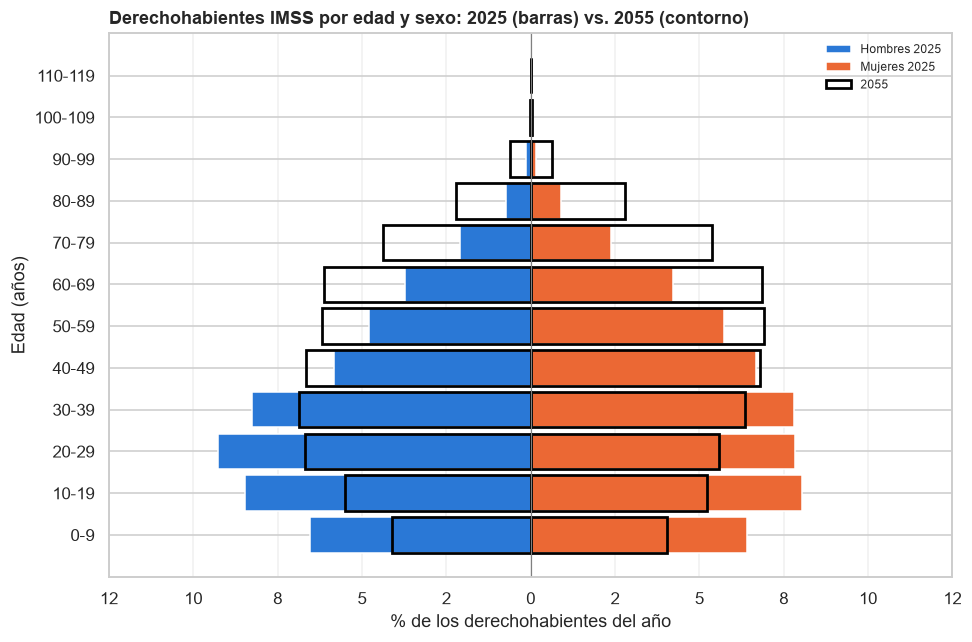

2025: derechohabientes de 60 años o más = 14.3%
2055: derechohabientes de 60 años o más = 29.1%


In [128]:
def piramide_dh(anio):
    tabla = pob_conapo.loc[pob_conapo["anio"] == anio].pivot(index="grupo_edad", columns="sexo", values="derechohabientes")
    tabla = tabla.reindex(etiquetas_rango).fillna(0)
    return tabla / tabla.values.sum() * 100


base_pir = piramide_dh(ANIO_BASE)
final_pir = piramide_dh(ANIO_FINAL)
posiciones_dh_pir = np.arange(len(etiquetas_rango))
maximo_dh = max(base_pir.values.max(), final_pir.values.max()) * 1.15

fig, eje = plt.subplots(figsize=(9, 6))
eje.barh(posiciones_dh_pir, -base_pir["Hombres"], height=0.85, color=COLOR_SEXO["Hombres"], label=f"Hombres {ANIO_BASE}")
eje.barh(posiciones_dh_pir, base_pir["Mujeres"], height=0.85, color=COLOR_SEXO["Mujeres"], label=f"Mujeres {ANIO_BASE}")
eje.barh(posiciones_dh_pir, -final_pir["Hombres"], height=0.85, fill=False, edgecolor="black", linewidth=1.8, label=str(ANIO_FINAL))
eje.barh(posiciones_dh_pir, final_pir["Mujeres"], height=0.85, fill=False, edgecolor="black", linewidth=1.8)
eje.axvline(0, color="gray", linewidth=0.8)
eje.set_xlim(-maximo_dh, maximo_dh)
marcas = eje.get_xticks()
eje.set_xticks(marcas)
eje.set_xticklabels([f"{abs(m):.0f}" for m in marcas])
eje.set_yticks(posiciones_dh_pir)
eje.set_yticklabels(etiquetas_rango)
eje.set_xlabel("% de los derechohabientes del año")
eje.set_ylabel("Edad (años)")
eje.set_title(f"Derechohabientes IMSS por edad y sexo: {ANIO_BASE} (barras) vs. {ANIO_FINAL} (contorno)", loc="left", fontweight="bold")
eje.legend(frameon=False, fontsize=8, loc="upper right")
eje.grid(alpha=0.3, axis="x")
plt.tight_layout()
guardar_grafica("15_1_piramide_dh_2025_2055")
plt.show()

for anio in [ANIO_BASE, ANIO_FINAL]:
    tabla = pob_conapo.loc[pob_conapo["anio"] == anio]
    mayores = tabla.loc[tabla["grupo_edad"].isin(etiquetas_rango[6:]), "derechohabientes"].sum()
    print(f"{anio}: derechohabientes de 60 años o más = {mayores / tabla['derechohabientes'].sum() * 100:.1f}%")

## 15.2 Población total por año: casos quirúrgicos posibles y resto de la población

Los **casos quirúrgicos posibles** de cada año son los casos proyectados en la sección 14.9 (`costos_esc["casos"]`) para los GRD del reporte: incidencia del año base × población del rango de edad. El **resto de la población** son los derechohabientes (`dh_total_esc`) menos esos casos.

* **Panel superior:** barras apiladas de la población total (millones): casos + resto.
* **Panel inferior:** los mismos casos **en miles y por GRD**. Hace falta porque los casos son alrededor del 0.2% de la población y en el panel superior casi no se ven. No es un segundo eje: es otra gráfica con su propia escala.

Los GRD con menos casos se agrupan en "Otros GRD" para no pasar de seis colores.

Gráfica guardada: graficas/reporte\15_2_poblacion_y_casos.png


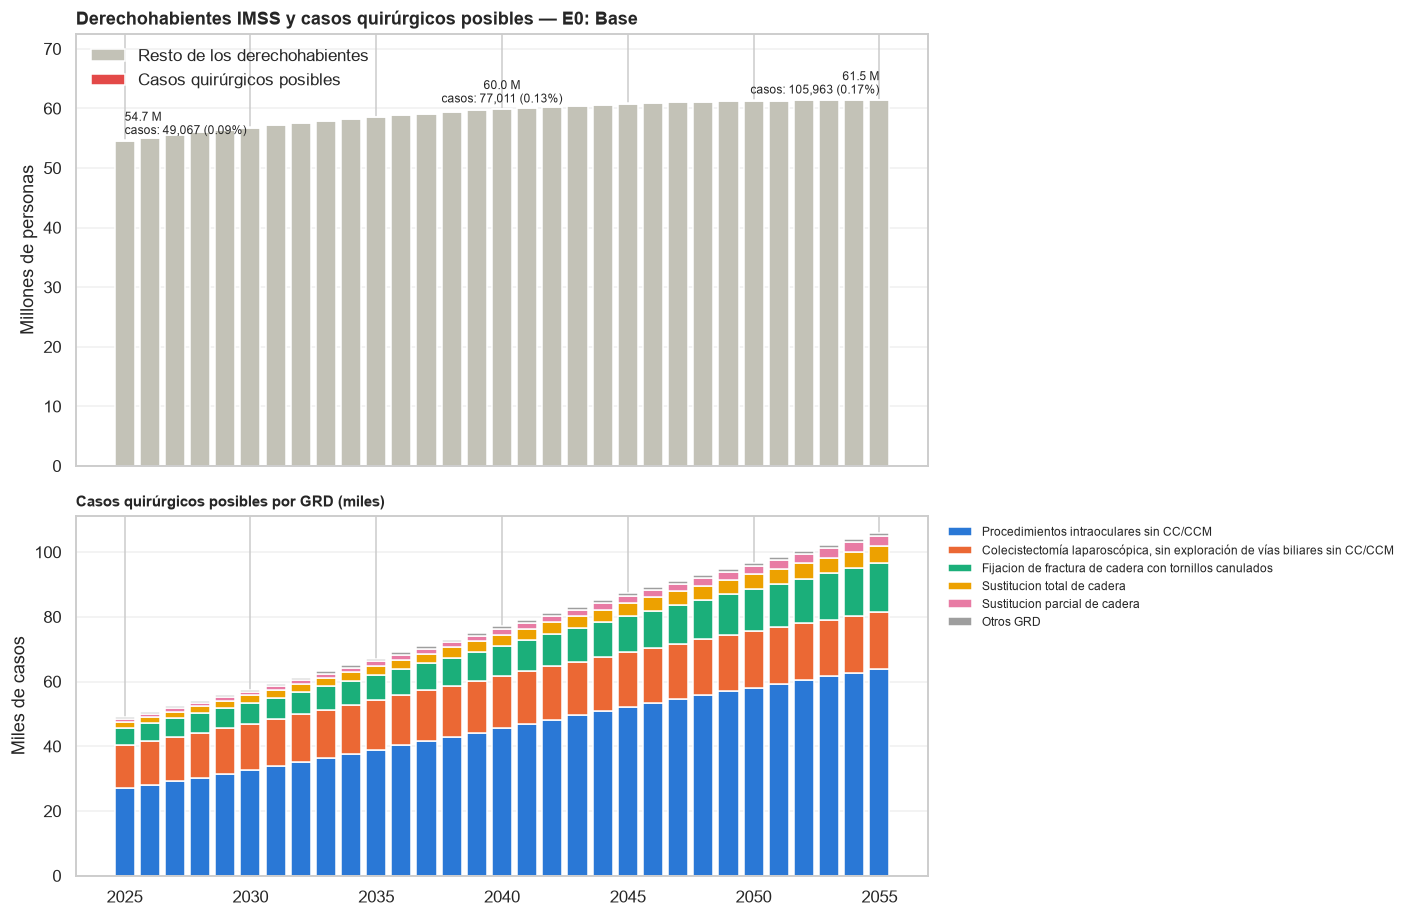

In [129]:
# ---------------- Casos y población por escenario y año ----------------
casos_anio = costos_esc.groupby(["anio", "escenario"])["casos"].sum().unstack("escenario")
poblacion_anio = dh_total_esc.loc[casos_anio.index, casos_anio.columns]
resto_anio = poblacion_anio - casos_anio

# Casos por GRD del escenario elegido; los GRD pequeños van a "Otros GRD"
NUM_GRD_VISIBLES = 5
casos_grd_esc = (costos_esc.loc[costos_esc["escenario"] == ESCENARIO_GRAFICA_CASOS]
                 .groupby(["anio", "grd"])["casos"].sum().unstack("grd").fillna(0))
orden_grd = casos_grd_esc.loc[ANIO_BASE].sort_values(ascending=False).index
grd_visibles = list(orden_grd[:NUM_GRD_VISIBLES])
casos_grd_graf = casos_grd_esc[grd_visibles].copy()
if len(orden_grd) > NUM_GRD_VISIBLES:
    casos_grd_graf["Otros GRD"] = casos_grd_esc[list(orden_grd[NUM_GRD_VISIBLES:])].sum(axis=1)
colores_grd = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#9e9e9e"]

anios_graf = casos_anio.index.values
fig, (eje_pob, eje_casos) = plt.subplots(2, 1, figsize=(13, 8.5), sharex=True, gridspec_kw={"height_ratios": [1.2, 1]})

# Panel superior: población total = casos + resto
eje_pob.bar(anios_graf, resto_anio[ESCENARIO_GRAFICA_CASOS] / 1e6, color="#c3c2b7", width=0.8, label="Resto de los derechohabientes")
eje_pob.bar(anios_graf, casos_anio[ESCENARIO_GRAFICA_CASOS] / 1e6, bottom=resto_anio[ESCENARIO_GRAFICA_CASOS] / 1e6,
            color="#e34948", width=0.8, label="Casos quirúrgicos posibles")
for anio, alineacion in [(ANIO_BASE, "left"), (2040, "center"), (ANIO_FINAL, "right")]:
    total = poblacion_anio.loc[anio, ESCENARIO_GRAFICA_CASOS]
    casos = casos_anio.loc[anio, ESCENARIO_GRAFICA_CASOS]
    eje_pob.annotate(f"{total / 1e6:,.1f} M\ncasos: {casos:,.0f} ({casos / total * 100:.2f}%)", (anio, total / 1e6),
                     textcoords="offset points", xytext=(0, 4), ha=alineacion, fontsize=8)
eje_pob.set_ylabel("Millones de personas")
eje_pob.set_ylim(0, poblacion_anio[ESCENARIO_GRAFICA_CASOS].max() / 1e6 * 1.18)
eje_pob.set_title(f"Derechohabientes IMSS y casos quirúrgicos posibles — {ETIQUETA_ESC[ESCENARIO_GRAFICA_CASOS]}",
                  loc="left", fontweight="bold")
eje_pob.legend(frameon=False, loc="upper left")
eje_pob.grid(alpha=0.3, axis="y")

# Panel inferior: los casos, por GRD (miles)
base_barra = np.zeros(len(anios_graf))
for color, grd in zip(colores_grd, casos_grd_graf.columns):
    valores = casos_grd_graf.loc[anios_graf, grd].values / 1e3
    eje_casos.bar(anios_graf, valores, bottom=base_barra, color=color, width=0.8, label=grd)
    base_barra = base_barra + valores
eje_casos.set_ylabel("Miles de casos")
eje_casos.set_title("Casos quirúrgicos posibles por GRD (miles)", loc="left", fontweight="bold", fontsize=10)
eje_casos.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
eje_casos.grid(alpha=0.3, axis="y")
plt.tight_layout()
guardar_grafica("15_2_poblacion_y_casos")
plt.show()

## 15.3 Casos posibles en todos los escenarios

Dos medidas, en dos gráficas separadas:

* **Casos posibles por año (miles):** combina el **tamaño** de la población y su **edad**.
* **Casos por cada 100 mil personas:** con incidencia por edad constante, esta tasa solo sube si la población **envejece**, es decir, si pesan más los rangos de edad con más cirugías. Es la medida que separa el efecto de la transición demográfica del simple crecimiento de la población.

Gráfica guardada: graficas/reporte\15_3_casos_por_escenario.png


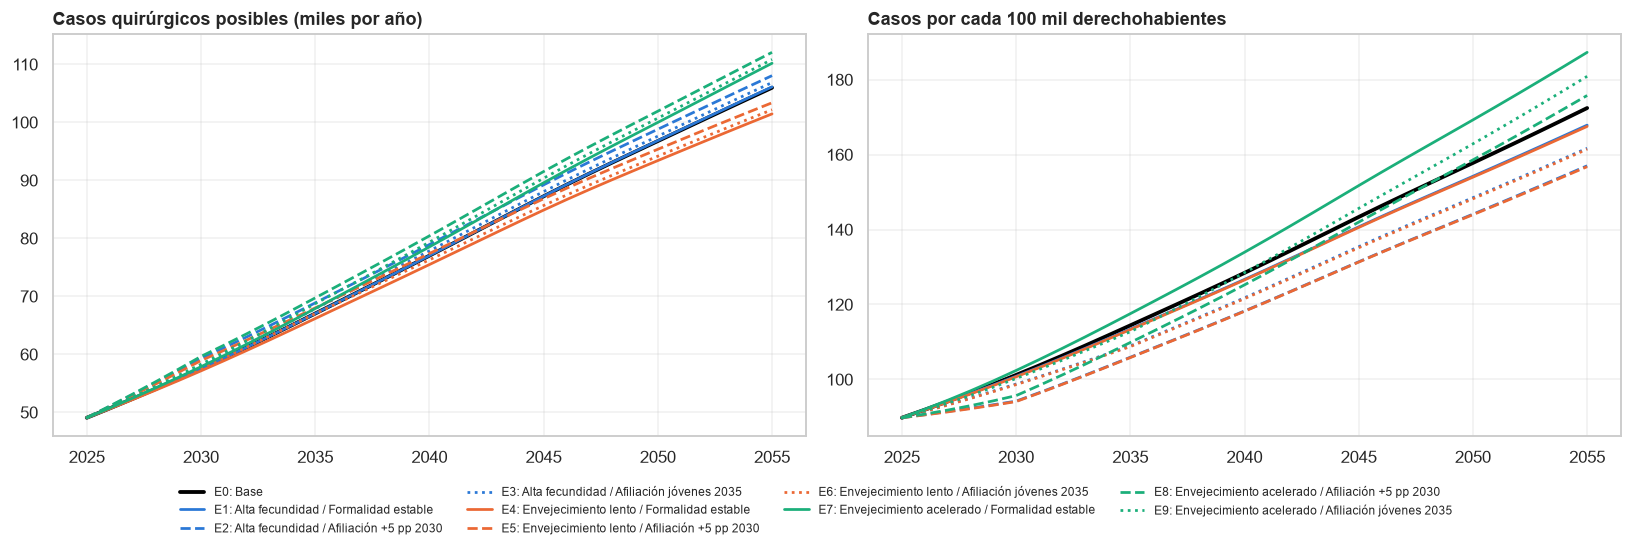

Población (millones), casos (miles) y casos por 100 mil, por escenario:


poblacion_mill                                                  \
escenario             E0    E1    E2    E3    E4    E5    E6    E7    E8   
anio                                                                       
2025                54.7  54.7  54.7  54.7  54.7  54.7  54.7  54.7  54.7   
2030                56.8  57.0  62.9  58.7  56.8  62.6  58.4  56.5  62.3   
2040                60.0  60.8  66.7  63.9  59.6  65.5  62.8  58.6  64.2   
2050                61.3  62.8  68.6  65.7  60.7  66.2  63.5  59.1  64.3   
2055                61.5  63.2  68.8  66.1  60.6  65.9  63.3  58.8  63.8   

                 ... casos_100mil                                            \
escenario    E9  ...           E0     E1     E2     E3     E4     E5     E6   
anio             ...                                                          
2025       54.7  ...         89.8   89.8   89.8   89.8   89.8   89.8   89.8   
2030       58.1  ...        101.2  100.8   94.2   98.8  100.7   94.1   98.6   
2040       61.7  ...        128.4  126.7  118.3  121.8  126.5  118.2  121.6   
2050       61.8  ...        157.8  154.2  144.1  148.5  154.0  144.0  148.2   
2055       61.3  ...        172.4  167.9  157.0  161.7  167.5  156.8  161.4   

                                
escenario     E7     E8     E9  
anio                            
2025        89.8   89.8   89.8  
2030       102.4   95.7  100.3  
2040       133.9  125.2  128.5  
2050       169.3  158.6  162.9  
2055       187.3  175.8  180.9  

[5 rows x 30 columns]

In [130]:
tasa_casos = casos_anio / poblacion_anio * 100000

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
for i in range(len(grid_escenarios)):
    fila = grid_escenarios.iloc[i]
    grosor = 2.5 if fila["escenario"] == "E0" else 1.8
    estilo = dict(color=COLORES_VARIANTE[fila["variante"]], linestyle=ESTILOS_TRAYECTORIA[fila["trayectoria"]], linewidth=grosor)
    ejes[0].plot(casos_anio.index, casos_anio[fila["escenario"]] / 1e3, label=fila["etiqueta"], **estilo)
    ejes[1].plot(tasa_casos.index, tasa_casos[fila["escenario"]], **estilo)
ejes[0].set_title("Casos quirúrgicos posibles (miles por año)", loc="left", fontweight="bold")
ejes[1].set_title("Casos por cada 100 mil derechohabientes", loc="left", fontweight="bold")
for eje in ejes:
    eje.grid(alpha=0.3)
fig.legend(*ejes[0].get_legend_handles_labels(), loc="lower center", ncol=4, frameon=False, fontsize=8)
plt.tight_layout(rect=[0, 0.1, 1, 1])
guardar_grafica("15_3_casos_por_escenario")
plt.show()

resumen_casos = pd.concat({"poblacion_mill": poblacion_anio / 1e6, "casos_miles": casos_anio / 1e3,
                           "casos_100mil": tasa_casos}, axis=1)
print("Población (millones), casos (miles) y casos por 100 mil, por escenario:")
resumen_casos.loc[[ANIO_BASE, 2030, 2040, 2050, ANIO_FINAL]].round(1)

# 16. Costo quirúrgico proyectado vs. ingresos y presupuesto

**Pregunta.** ¿Qué parte de los ingresos y del presupuesto del IMSS absorben los procedimientos de este reporte, y cómo cambia esa parte con el tiempo y entre escenarios?

**Pasos:**

1. **Costos en pesos de 2026.** Ya vienen así desde la sección 13.3 (INPC Salud).
2. **Ingresos y gasto observado.** Se leen del archivo de insumos que exporta el cuaderno de ingresos (`ingresos_niveles` y `gasto_observado`), ya en MDP de 2026.
3. **Presupuesto proyectado.** Para los años sin dato se supone que cada rubro de gasto mantiene **el mismo % de los ingresos** que en el promedio 2024-2026 (editable).
4. **Comparación** de los costos de la sección 13 (y de los escenarios de la sección 14) contra ingresos y presupuesto.

**Unidades: millones de pesos de 2026 (MDP 2026).**

## 16.0 Parámetros

* `ANIOS_PROMEDIO_PCT`: años con los que se calcula el % de los ingresos de cada rubro de gasto.
* `PCT_MANUAL`: si se quiere fijar un % a mano, se escribe aquí y reemplaza al promedio. Por ejemplo `{"gasto_quirofano": 0.035}` (en proporción, no en %).
* `BASE_PCT`: contra qué ingreso se calcula el % (`"ingresos_total"` o `"ingresos_SEM"`).
* `AJUSTAR_INGRESOS_POR_ESCENARIO`: si es `True`, en cada escenario de la sección 14 los ingresos se mueven en la misma proporción que los **derechohabientes de 15 a 64 años** (`dh_trabajo_esc`, sección 14.7). Así un escenario con más formalidad también trae más ingresos.

In [131]:
ANIOS_PROMEDIO_PCT = [2024, 2025, 2026]
PCT_MANUAL = {}                           # ejemplo: {"gasto_quirofano": 0.035}
BASE_PCT = "ingresos_total"
AJUSTAR_INGRESOS_POR_ESCENARIO = False
ANIO_CASCADA_REPORTE = 2030

# Los costos ya están en pesos de 2026 desde la sección 13.3; aquí solo se copian con el nombre que usa esta sección
costo_grd_2026 = costo_grd.copy()
costo_total_2026 = costo_total.copy()
costos_esc["costo_real_2026"] = costos_esc["costo_real"]

print("Costo total de los GRD (MDP de 2026):")
costo_grd_2026.loc[[ANIO_BASE, 2030, 2040, 2050, ANIO_FINAL], ["Total GRD"]].round(1)

Costo total de los GRD (MDP de 2026):


grd,Total GRD
anio,
2025,1877.0
2030,2173.3
2040,2865.2
2050,3611.1
2055,3974.1


## 16.2 Ingresos y presupuesto proyectado

* **2024 a 2026:** gasto observado (presupuesto modificado en 2026). El gasto corriente también trae **2027** y se usa tal cual.
* **Años sin dato:** `gasto_t = ingresos_t × % promedio de ANIOS_PROMEDIO_PCT`.

Con este supuesto, el presupuesto proyectado crece **igual que los ingresos**.

In [132]:
ingresos_niveles = pd.read_excel(ARCHIVO_INSUMOS, sheet_name="ingresos_niveles").set_index("anio")
gasto_observado = pd.read_excel(ARCHIVO_INSUMOS, sheet_name="gasto_observado").set_index("anio")

RUBROS_GASTO = ["gasto_corriente_salud", "gasto_quirofano", "gasto_quirofano_SEM"]

finanzas = ingresos_niveles.loc[ANIO_BASE - 1:ANIO_FINAL].copy()
finanzas = finanzas.join(gasto_observado[RUBROS_GASTO], how="left")

# % de los ingresos: promedio de los años elegidos (o el valor manual)
pct_gasto = {}
for rubro in RUBROS_GASTO:
    pct_por_anio = finanzas.loc[ANIOS_PROMEDIO_PCT, rubro] / finanzas.loc[ANIOS_PROMEDIO_PCT, BASE_PCT]
    pct_gasto[rubro] = pct_por_anio.mean()
    if rubro in PCT_MANUAL:
        pct_gasto[rubro] = PCT_MANUAL[rubro]

# Proyección: solo los años posteriores al promedio que NO tienen dato observado
# (por ejemplo, el gasto corriente sí trae 2027 y ese dato se respeta)
ultimo_observado = max(ANIOS_PROMEDIO_PCT)
finanzas["tipo"] = "Observado"
finanzas.loc[finanzas.index > ultimo_observado, "tipo"] = "Proyectado"
for rubro in RUBROS_GASTO:
    faltan = (finanzas.index > ultimo_observado) & finanzas[rubro].isna()
    finanzas.loc[faltan, rubro] = finanzas.loc[faltan, BASE_PCT] * pct_gasto[rubro]

print(f"% de {BASE_PCT} que se usa para proyectar (promedio {ANIOS_PROMEDIO_PCT}):")
for rubro in RUBROS_GASTO:
    print(f"  {rubro}: {pct_gasto[rubro] * 100:.2f}%")
finanzas.loc[[2024, 2025, 2026, 2027, 2030, 2040, ANIO_FINAL]].round(0)

% de ingresos_total que se usa para proyectar (promedio [2024, 2025, 2026]):
  gasto_corriente_salud: 63.55%
  gasto_quirofano: 3.96%
  gasto_quirofano_SEM: 2.73%


,ingresos_total,ingresos_SEM,gasto_corriente_salud,gasto_quirofano,gasto_quirofano_SEM,tipo
anio,,,,,,
2024,855594.0,541487.0,516680.0,31395.0,21662.0,Observado
2025,851311.0,541634.0,545271.0,35877.0,24755.0,Observado
2026,841414.0,552894.0,557232.0,33538.0,23141.0,Observado
2027,866006.0,561611.0,621907.0,34264.0,23642.0,Proyectado
2030,947049.0,611178.0,601897.0,37470.0,25854.0,Proyectado
2040,1306257.0,833059.0,830191.0,51682.0,35661.0,Proyectado
2055,1966292.0,1215262.0,1249676.0,77796.0,53679.0,Proyectado


## 16.3 Costo de los GRD frente a ingresos y presupuesto (escenario base)

**Tabla:** el costo total de los GRD del reporte como % de cada rubro.

**Gráfica 1:** crecimiento acumulado (índice, `ANIO_BASE` = 1) del costo de los GRD y de los ingresos del SEM. Como el presupuesto proyectado es un % fijo de los ingresos, crece igual que los ingresos.

**Gráfica 2:** costo de los GRD como % del gasto en quirófano del SEM. Si la línea sube, los procedimientos del reporte presionan cada vez más el gasto en quirófano.

Costo de los GRD (MDP de 2026) y su % de cada rubro:


,costo_GRD,pct_ingresos_SEM,pct_gasto_corriente,pct_quirofano,pct_quirofano_SEM
anio,,,,,
2025,1876.97,0.35,0.34,5.23,7.58
2030,2173.34,0.36,0.36,5.80,8.41
2035,2506.48,0.35,0.36,5.71,8.27
2040,2865.17,0.34,0.35,5.54,8.03
2045,3243.42,0.34,0.33,5.36,7.77
2050,3611.13,0.33,0.32,5.17,7.49
2055,3974.10,0.33,0.32,5.11,7.40


Gráfica guardada: graficas/reporte\16_3_indice_costo_vs_ingresos.png


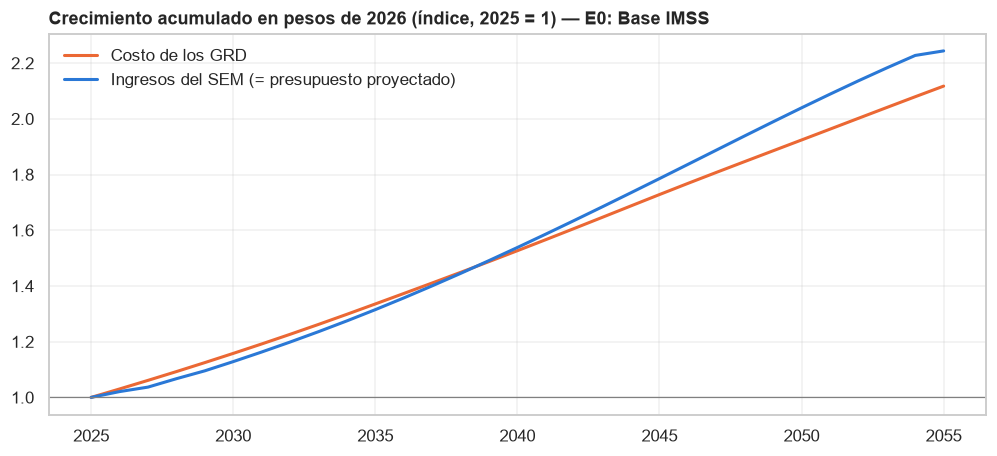

Gráfica guardada: graficas/reporte\16_3_costo_pct_quirofano_sem.png


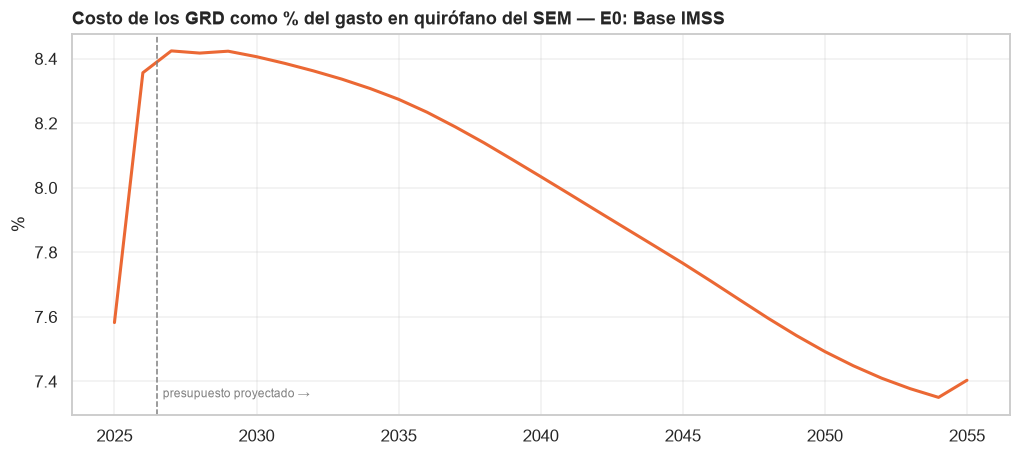

In [133]:
COLORES_COSTO_INGRESO = {"costo": "#eb6834", "ingreso": "#2a78d6"}

comparacion = pd.DataFrame(index=costo_grd_2026.index)
comparacion["costo_GRD"] = costo_grd_2026["Total GRD"]
comparacion = comparacion.join(finanzas)
comparacion["pct_ingresos_SEM"] = comparacion["costo_GRD"] / comparacion["ingresos_SEM"] * 100
comparacion["pct_gasto_corriente"] = comparacion["costo_GRD"] / comparacion["gasto_corriente_salud"] * 100
comparacion["pct_quirofano"] = comparacion["costo_GRD"] / comparacion["gasto_quirofano"] * 100
comparacion["pct_quirofano_SEM"] = comparacion["costo_GRD"] / comparacion["gasto_quirofano_SEM"] * 100

print("Costo de los GRD (MDP de 2026) y su % de cada rubro:")
display(comparacion.loc[[ANIO_BASE, 2030, 2035, 2040, 2045, 2050, ANIO_FINAL],
                        ["costo_GRD", "pct_ingresos_SEM", "pct_gasto_corriente", "pct_quirofano", "pct_quirofano_SEM"]].round(2))

# Gráfica 1: índices
indice = comparacion[["costo_GRD", "ingresos_SEM"]] / comparacion.loc[ANIO_BASE, ["costo_GRD", "ingresos_SEM"]]
plt.figure(figsize=(11, 4.5))
plt.plot(indice.index, indice["costo_GRD"], color=COLORES_COSTO_INGRESO["costo"], linewidth=2, label="Costo de los GRD")
plt.plot(indice.index, indice["ingresos_SEM"], color=COLORES_COSTO_INGRESO["ingreso"], linewidth=2,
         label="Ingresos del SEM (= presupuesto proyectado)")
plt.axhline(1, color="gray", linewidth=0.8)
plt.title(f"Crecimiento acumulado en pesos de 2026 (índice, {ANIO_BASE} = 1) — E0: Base IMSS", loc="left", fontweight="bold")
plt.legend(frameon=False)
plt.grid(alpha=0.3)
guardar_grafica("16_3_indice_costo_vs_ingresos")
plt.show()

# Gráfica 2: % del gasto en quirófano del SEM
plt.figure(figsize=(11, 4.5))
plt.plot(comparacion.index, comparacion["pct_quirofano_SEM"], color=COLORES_COSTO_INGRESO["costo"], linewidth=2)
plt.axvline(max(ANIOS_PROMEDIO_PCT) + 0.5, color="gray", linestyle="--", linewidth=1)
plt.text(max(ANIOS_PROMEDIO_PCT) + 0.7, comparacion["pct_quirofano_SEM"].min(), "presupuesto proyectado →", color="gray", fontsize=8)
plt.title("Costo de los GRD como % del gasto en quirófano del SEM — E0: Base IMSS", loc="left", fontweight="bold")
plt.ylabel("%")
plt.grid(alpha=0.3)
guardar_grafica("16_3_costo_pct_quirofano_sem")
plt.show()

## 16.4 Escenarios: costo de los GRD como % del gasto en quirófano del SEM

Cada escenario de la sección 14 tiene su propio costo. Si `AJUSTAR_INGRESOS_POR_ESCENARIO = True`, también tiene sus propios ingresos (y por lo tanto su propio presupuesto):

`ingresos_escenario_t = ingresos_base_t × derechohabientes de 15 a 64 años del escenario_t / los mismos en E0_t`

Supone el mismo ingreso por derechohabiente en edad de trabajar que en el base. Así se distingue entre un escenario que **cuesta más** y uno que **cuesta más en relación con lo que ingresa**.

Gráfica guardada: graficas/reporte\16_4_costo_pct_quirofano_por_escenario.png


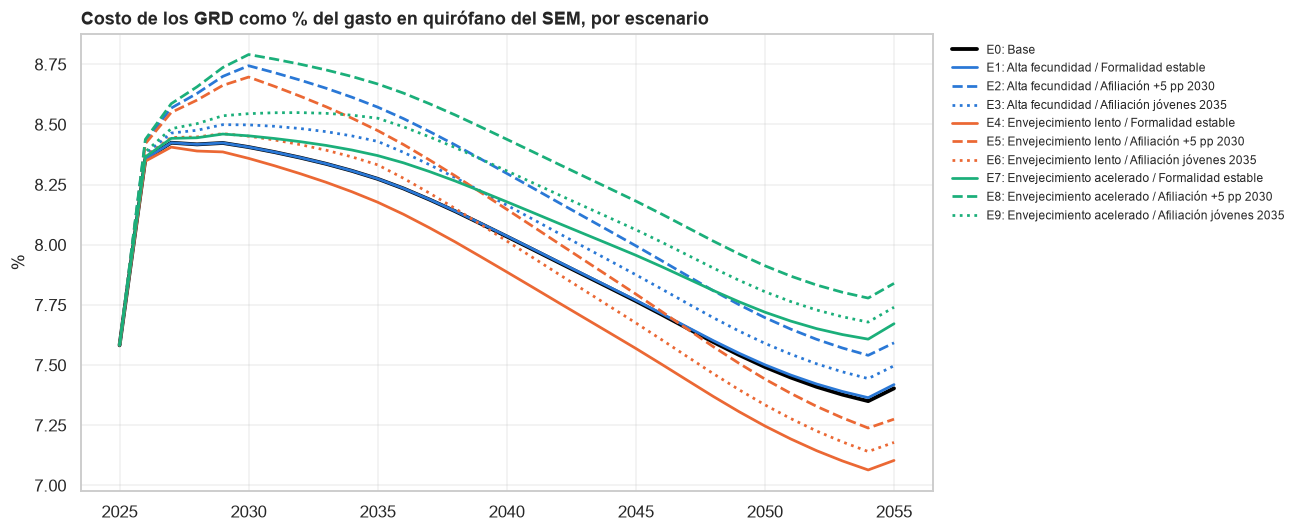

Costo de los GRD como % del gasto en quirófano del SEM:


,E0,E1,E2,E3,E4,E5,E6,E7,E8,E9
anio,,,,,,,,,,
2025,7.58,7.58,7.58,7.58,7.58,7.58,7.58,7.58,7.58,7.58
2030,8.41,8.41,8.74,8.50,8.36,8.70,8.45,8.45,8.79,8.54
2040,8.03,8.04,8.30,8.16,7.89,8.15,8.02,8.18,8.44,8.31
2050,7.49,7.50,7.70,7.59,7.25,7.44,7.33,7.72,7.91,7.80
2055,7.40,7.42,7.59,7.50,7.10,7.28,7.18,7.67,7.84,7.74


In [134]:
pct_quirofano_esc = pd.DataFrame(index=costo_total_2026.index)
for escenario in grid_escenarios["escenario"]:
    if AJUSTAR_INGRESOS_POR_ESCENARIO:
        ajuste = dh_trabajo_esc.loc[pct_quirofano_esc.index, escenario] / dh_trabajo_esc.loc[pct_quirofano_esc.index, "E0"]
    else:
        ajuste = 1
    quirofano_sem_esc = finanzas.loc[pct_quirofano_esc.index, "gasto_quirofano_SEM"] * ajuste
    pct_quirofano_esc[escenario] = costo_total_2026[escenario] / quirofano_sem_esc * 100

plt.figure(figsize=(12, 5))
for i in range(len(grid_escenarios)):
    fila = grid_escenarios.iloc[i]
    grosor = 2.5 if fila["escenario"] == "E0" else 1.8
    plt.plot(pct_quirofano_esc.index, pct_quirofano_esc[fila["escenario"]], color=COLORES_VARIANTE[fila["variante"]],
             linestyle=ESTILOS_TRAYECTORIA[fila["trayectoria"]], linewidth=grosor, label=fila["etiqueta"])
plt.title("Costo de los GRD como % del gasto en quirófano del SEM, por escenario", loc="left", fontweight="bold")
plt.ylabel("%")
plt.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.grid(alpha=0.3)
plt.tight_layout()
guardar_grafica("16_4_costo_pct_quirofano_por_escenario")
plt.show()

print("Costo de los GRD como % del gasto en quirófano del SEM:")
pct_quirofano_esc.loc[[ANIO_BASE, 2030, 2040, 2050, ANIO_FINAL]].round(2)

## 16.5 Cascada completa: de los ingresos al costo de los GRD

La misma cascada del cuaderno de ingresos, con un escalón más al final: el costo de los procedimientos de este reporte. Se dibuja para el año base y para `ANIO_CASCADA_REPORTE` (escenario base). Barras azules = monto; grises = lo que se queda en el camino; naranja = el escalón siguiente es mayor.

Gráfica guardada: graficas/reporte\16_5_cascada_ingresos_costo_grd.png


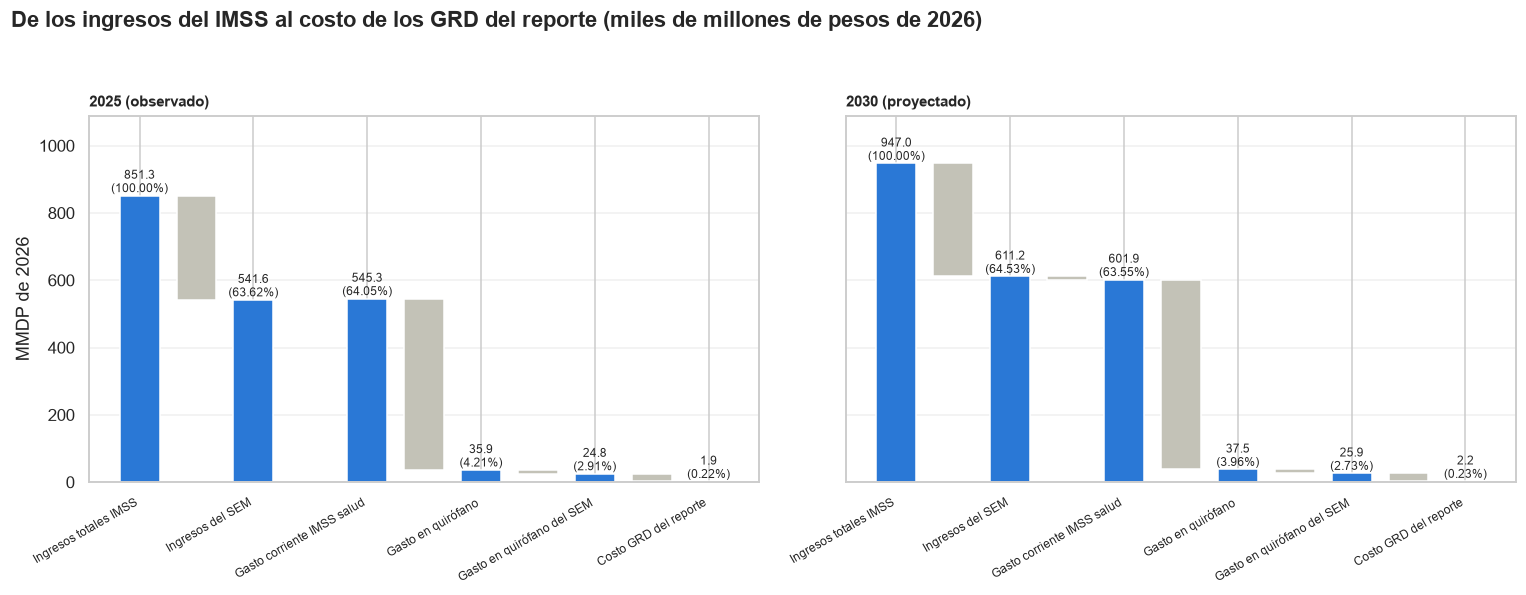

In [135]:
COLOR_NIVEL = "#2a78d6"
COLOR_SALE = "#c3c2b7"
COLOR_ENTRA = "#eb6834"


def grafica_cascada(eje, nombres, valores, titulo):
    # nombres y valores: un elemento por escalón (valores en MDP de 2026)
    posicion = 0
    posiciones_nivel = []
    for i in range(len(valores)):
        eje.bar(posicion, valores[i] / 1000, color=COLOR_NIVEL, width=0.7)
        eje.text(posicion, valores[i] / 1000, f"{valores[i] / 1000:,.1f}\n({valores[i] / valores[0] * 100:.2f}%)",
                 ha="center", va="bottom", fontsize=8)
        posiciones_nivel.append(posicion)
        posicion = posicion + 1
        if i < len(valores) - 1:
            diferencia = valores[i + 1] - valores[i]
            color = COLOR_SALE if diferencia < 0 else COLOR_ENTRA
            eje.bar(posicion, diferencia / 1000, bottom=valores[i] / 1000, color=color, width=0.7)
            posicion = posicion + 1
    eje.set_ylim(0, max(valores) / 1000 * 1.15)
    eje.set_xticks(posiciones_nivel)
    eje.set_xticklabels(nombres, rotation=30, ha="right", fontsize=8)
    eje.set_title(titulo, loc="left", fontweight="bold", fontsize=10)
    eje.grid(alpha=0.3, axis="y")


NOMBRES_ESCALONES = {"ingresos_total": "Ingresos totales IMSS", "ingresos_SEM": "Ingresos del SEM",
                     "gasto_corriente_salud": "Gasto corriente IMSS salud", "gasto_quirofano": "Gasto en quirófano",
                     "gasto_quirofano_SEM": "Gasto en quirófano del SEM", "costo_GRD": "Costo GRD del reporte"}

anios_cascada = [ANIO_BASE, ANIO_CASCADA_REPORTE]
fig, ejes = plt.subplots(1, len(anios_cascada), figsize=(7 * len(anios_cascada), 5.5), sharey=True)
for eje, anio in zip(np.atleast_1d(ejes), anios_cascada):
    fila = comparacion.loc[anio, list(NOMBRES_ESCALONES.keys())].dropna().astype(float)
    nombres = [NOMBRES_ESCALONES[columna] for columna in fila.index]
    grafica_cascada(eje, nombres, fila.values, f"{anio} ({finanzas.loc[anio, 'tipo'].lower()})")
np.atleast_1d(ejes)[0].set_ylabel("MMDP de 2026")
fig.suptitle("De los ingresos del IMSS al costo de los GRD del reporte (miles de millones de pesos de 2026)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
guardar_grafica("16_5_cascada_ingresos_costo_grd")
plt.show()

## 16.6 Balance financiero del SEM proyectado (escenario base)

**Balance financiero = ingresos del SEM − gasto corriente en salud**, en millones de pesos de 2026, cada 5 años.

* **Barra de ingresos** (hacia arriba): ingresos del SEM apilados por concepto (pestaña `ingresos_sem_concepto` del archivo de insumos).
* **Barra de gastos** (hacia abajo): gasto corriente en salud apilado en tres partes: **costo de los GRD del reporte**, resto del gasto en quirófano y resto del gasto corriente.
* **Barra roja:** balance.

**Cómo se proyecta el gasto** (`METODO_GASTO_BALANCE`):

* `"pct_ingresos"` (por defecto): el mismo supuesto de la sección 16.2, es decir, cada rubro es un % fijo de los ingresos. Con este supuesto el balance crece al mismo ritmo que los ingresos.
* `"demanda"`: desde el último año observado de cada rubro, el gasto crece al mismo ritmo que el costo de los GRD (13.6). Así el gasto refleja el envejecimiento de los derechohabientes.

> El costo de los GRD incluye hospitalización, no solo quirófano. Por eso su parte dentro del gasto en quirófano es una **cota superior**.

¿Ingresos del SEM por concepto iguales a finanzas (16.2)? True
Método de proyección del gasto: pct
Gráfica guardada: graficas/reporte\16_6_balance_financiero_sem_pct.png


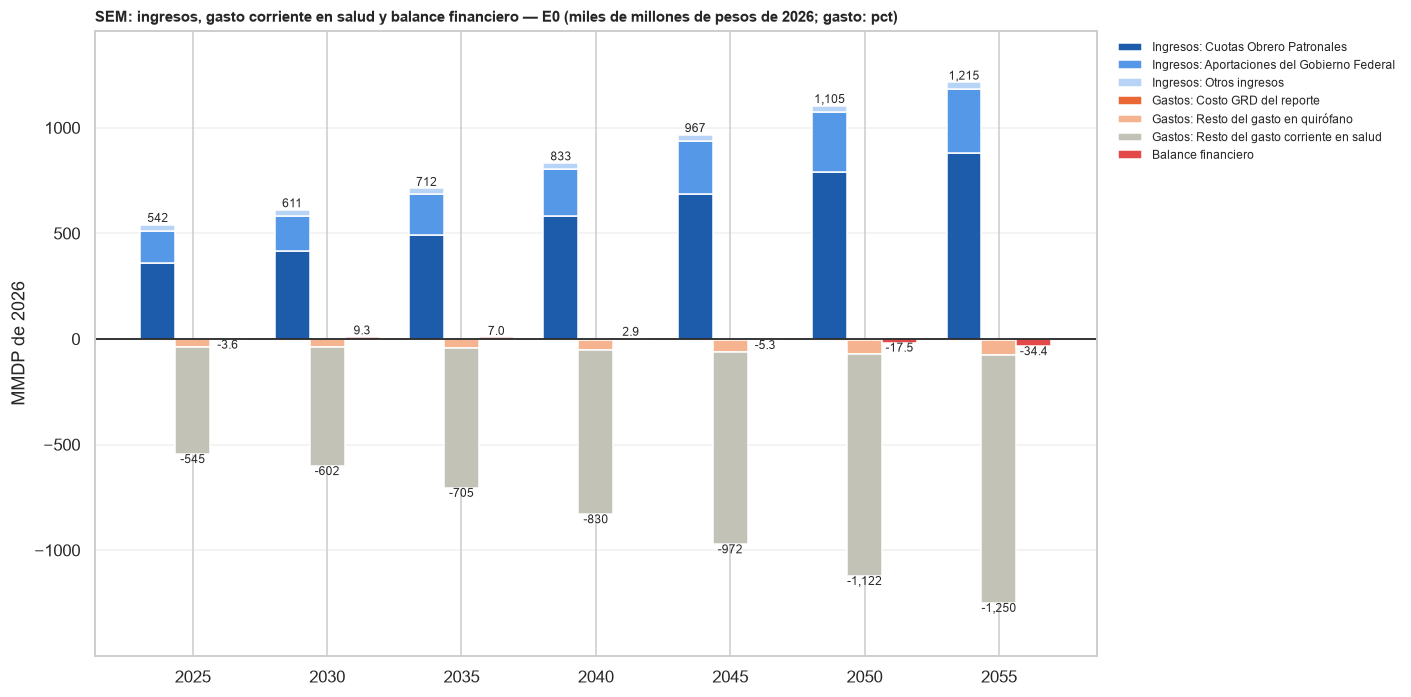

,ingresos_SEM,gasto_corriente_salud,balance,balance_pct_ingresos,costo_GRD_pct_gasto
2025,541634.1,545270.6,-3636.5,-0.7,0.3
2030,611177.6,601896.5,9281.1,1.5,0.4
2035,712194.7,705237.5,6957.2,1.0,0.4
2040,833059.3,830190.6,2868.6,0.3,0.3
2045,966984.0,972272.1,-5288.1,-0.5,0.3
2050,1104556.1,1122068.6,-17512.5,-1.6,0.3
2055,1215262.1,1249675.6,-34413.6,-2.8,0.3


In [136]:
METODO_GASTO_BALANCE = "pct"       # "pct_ingresos" o "demanda"
ANIOS_BALANCE = list(range(ANIO_BASE, ANIO_FINAL + 1, 5))
CONCEPTOS = ["Cuotas Obrero Patronales", "Aportaciones del Gobierno Federal", "Otros ingresos"]

# ---------------- Ingresos del SEM por concepto (MDP de 2026) ----------------
ingresos_sem_concepto = pd.read_excel(ARCHIVO_INSUMOS, sheet_name="ingresos_sem_concepto").set_index("anio")[CONCEPTOS]

# ---------------- Gasto corriente y gasto en quirófano según el método elegido ----------------
gasto_corriente_bal = comparacion["gasto_corriente_salud"].copy()
gasto_quirofano_bal = comparacion["gasto_quirofano"].copy()
if METODO_GASTO_BALANCE == "demanda":
    for rubro, serie in [("gasto_corriente_salud", gasto_corriente_bal), ("gasto_quirofano", gasto_quirofano_bal)]:
        ultimo = gasto_observado[rubro].dropna().index.max()                        # último año observado del rubro
        indice = comparacion["costo_GRD"] / comparacion.loc[ultimo, "costo_GRD"]    # crecimiento de la demanda
        proyectados = serie.index > ultimo
        serie.loc[proyectados] = gasto_observado.loc[ultimo, rubro] * indice.loc[proyectados]

# ---------------- Tabla del balance ----------------
gasto_balance = pd.DataFrame(index=ANIOS_BALANCE)
gasto_balance["Costo GRD del reporte"] = comparacion.loc[ANIOS_BALANCE, "costo_GRD"]
gasto_balance["Resto del gasto en quirófano"] = gasto_quirofano_bal.loc[ANIOS_BALANCE] - gasto_balance["Costo GRD del reporte"]
gasto_balance["Resto del gasto corriente en salud"] = gasto_corriente_bal.loc[ANIOS_BALANCE] - gasto_quirofano_bal.loc[ANIOS_BALANCE]

balance = pd.DataFrame(index=ANIOS_BALANCE)
balance["ingresos_SEM"] = ingresos_sem_concepto.loc[ANIOS_BALANCE].sum(axis=1)
balance["gasto_corriente_salud"] = gasto_balance.sum(axis=1)
balance["balance"] = balance["ingresos_SEM"] - balance["gasto_corriente_salud"]
balance["balance_pct_ingresos"] = balance["balance"] / balance["ingresos_SEM"] * 100
balance["costo_GRD_pct_gasto"] = gasto_balance["Costo GRD del reporte"] / balance["gasto_corriente_salud"] * 100

print("¿Ingresos del SEM por concepto iguales a finanzas (16.2)?",
      np.allclose(balance["ingresos_SEM"], finanzas.loc[ANIOS_BALANCE, "ingresos_SEM"]))
print("Método de proyección del gasto:", METODO_GASTO_BALANCE)

# ---------------- Gráfica: ingresos (arriba), gastos (abajo) y balance ----------------
COLORES_INGRESO = {"Cuotas Obrero Patronales": "#1c5cab", "Aportaciones del Gobierno Federal": "#5598e7", "Otros ingresos": "#b7d3f6"}
COLORES_GASTO = {"Costo GRD del reporte": "#eb6834", "Resto del gasto en quirófano": "#f5b38f",
                 "Resto del gasto corriente en salud": "#c3c2b7"}
COLOR_BALANCE = "#e34948"
ancho = 1.3                                   # los años van de 5 en 5
x = np.array(ANIOS_BALANCE)

plt.figure(figsize=(13, 6.5))
base = np.zeros(len(x))
for concepto in CONCEPTOS:
    valores = ingresos_sem_concepto.loc[ANIOS_BALANCE, concepto].values / 1000
    plt.bar(x - ancho, valores, width=ancho, bottom=base, color=COLORES_INGRESO[concepto], label=f"Ingresos: {concepto}")
    base = base + valores
base = np.zeros(len(x))
for rubro in gasto_balance.columns:
    valores = -gasto_balance[rubro].values / 1000
    plt.bar(x, valores, width=ancho, bottom=base, color=COLORES_GASTO[rubro], label=f"Gastos: {rubro}")
    base = base + valores
plt.bar(x + ancho, balance["balance"] / 1000, width=ancho, color=COLOR_BALANCE, label="Balance financiero")

for anio in ANIOS_BALANCE:
    ingreso = balance.loc[anio, "ingresos_SEM"] / 1000
    egreso = balance.loc[anio, "gasto_corriente_salud"] / 1000
    saldo = balance.loc[anio, "balance"] / 1000
    plt.text(anio - ancho, ingreso, f"{ingreso:,.0f}", ha="center", va="bottom", fontsize=8)
    plt.text(anio, -egreso, f"-{egreso:,.0f}", ha="center", va="top", fontsize=8)
    plt.text(anio + ancho, saldo, f"{saldo:,.1f}", ha="center", va="bottom" if saldo >= 0 else "top", fontsize=8)

plt.axhline(0, color="black", linewidth=1)
plt.xticks(x, [str(anio) for anio in ANIOS_BALANCE])
plt.ylim(-balance["gasto_corriente_salud"].max() / 1000 * 1.2, balance["ingresos_SEM"].max() / 1000 * 1.2)
plt.title(f"SEM: ingresos, gasto corriente en salud y balance financiero — E0 (miles de millones de pesos de 2026; gasto: {METODO_GASTO_BALANCE})",
          loc="left", fontweight="bold", fontsize=10)
plt.ylabel("MMDP de 2026")
plt.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.grid(alpha=0.3, axis="y")
plt.tight_layout()
guardar_grafica("16_6_balance_financiero_sem_" + METODO_GASTO_BALANCE)
plt.show()

balance.round(1)

# 17. Sensibilidad al denominador poblacional (población cotizante del SEM)

La tasa de utilización se calcula con la población **cotizante** del SEM (`poblacion_rango_sem`, sección 13.4) en lugar de la población derechohabiente, para medir cuánto depende el resultado del denominador. Los casos y el costo por caso del año base son los mismos (`demanda_base`, sección 13.3); **cambia el denominador** y, en este cálculo, la tasa no distingue sexo.

* **Tabla 1:** incidencia de sustitución total de cadera por rango de edad con cada denominador.
* **Gráfica:** costo total de los GRD (MDP de 2026) y su % del gasto en quirófano del SEM, con cada denominador.
* **Tabla 2:** costo por GRD en `ANIO_FINAL` con cada denominador.

Los casos de rangos sin cotizantes (menores de 15 años) no se pueden proyectar con este denominador.

In [137]:
# ---------------- Proyección con el denominador alternativo (cotizantes del SEM) ----------------
# Con este denominador la tasa no distingue sexo: casos y costo promedio por GRD y rango, directo de la demanda del año base
incidencia_sem = demanda_base.groupby(["grd", "grupo_edad"], observed=False).agg(
    casos_base=("costo_caso", "size"), costo_promedio_caso=("costo_caso", "mean")).reset_index()
incidencia_sem["poblacion_base"] = incidencia_sem["grupo_edad"].map(poblacion_rango_sem.loc[ANIO_BASE]).astype(float)
incidencia_sem["incidencia_100mil"] = np.nan
con_poblacion = incidencia_sem["poblacion_base"] > 0
incidencia_sem.loc[con_poblacion, "incidencia_100mil"] = (
    incidencia_sem.loc[con_poblacion, "casos_base"] / incidencia_sem.loc[con_poblacion, "poblacion_base"] * 100000)

lista_sem = []
for anio in anios_proyeccion:
    tabla_anio = incidencia_sem.copy()
    tabla_anio["anio"] = anio
    tabla_anio["poblacion"] = tabla_anio["grupo_edad"].map(poblacion_rango_sem.loc[anio]).astype(float)
    tabla_anio["casos"] = tabla_anio["incidencia_100mil"] * tabla_anio["poblacion"] / 100000
    tabla_anio["costo_2026"] = tabla_anio["casos"] * tabla_anio["costo_promedio_caso"]
    lista_sem.append(tabla_anio)
proyeccion_sem = pd.concat(lista_sem, ignore_index=True).fillna({"casos": 0, "costo_2026": 0})

costo_grd_sem = proyeccion_sem.groupby(["anio", "grd"])["costo_2026"].sum().unstack("grd") / 1e6
costo_grd_sem["Total GRD"] = costo_grd_sem.sum(axis=1)

# ---------------- Tabla 1: incidencia de cadera con cada denominador ----------------
grd_cadera = "Sustitucion total de cadera"
comparacion_inc = pd.DataFrame({
    "por 100 mil cotizantes SEM": incidencia_sem.loc[incidencia_sem["grd"] == grd_cadera].set_index("grupo_edad")["incidencia_100mil"],
    "por 100 mil derechohabientes": tabla_incidencia[grd_cadera],          # ambos sexos (13.5)
})
print(f"Incidencia de {grd_cadera} en {ANIO_BASE}:")
comparacion_inc.round(1)

Incidencia de Sustitucion total de cadera en 2025:


,por 100 mil cotizantes SEM,por 100 mil derechohabientes
grupo_edad,,
0-9,NaN,0.0
10-19,0.0,0.0
20-29,0.2,0.1
30-39,0.4,0.3
40-49,0.6,0.5
50-59,3.3,2.1
60-69,53.4,9.3
70-79,760.7,27.2
80-89,5028.9,60.6


Gráfica guardada: graficas/reporte\17_sensibilidad_denominador.png


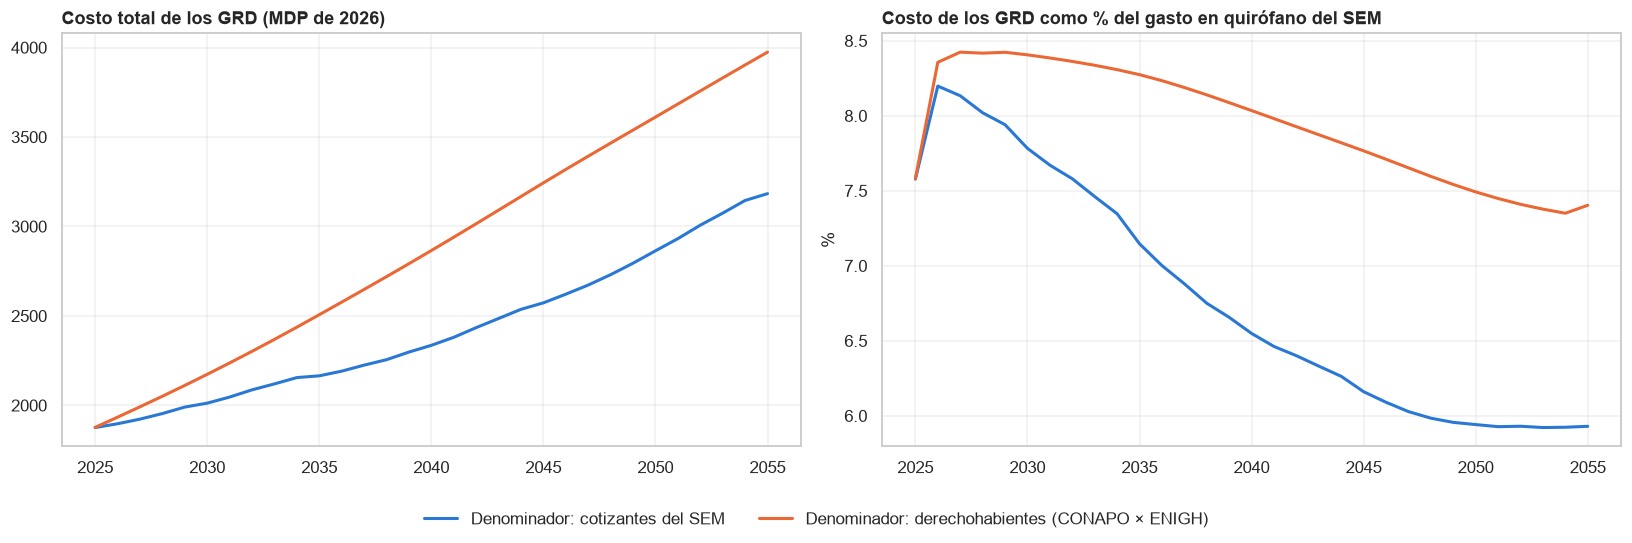

Costo por GRD en 2055 (MDP de 2026):


,Denominador: cotizantes del SEM,Denominador: derechohabientes,Diferencia %
grd,,,
"Colecistectomía laparoscópica, sin exploración de vías biliares con CC",2.8,1.5,-46.4
"Colecistectomía laparoscópica, sin exploración de vías biliares con CCM",3.2,3.0,-8.7
"Colecistectomía laparoscópica, sin exploración de vías biliares sin CC/CCM",1545.1,985.2,-36.2
Fijacion de fractura de cadera con tornillos canulados,518.5,1139.8,119.8
Procedimientos intraoculares sin CC/CCM,665.0,988.7,48.7
Prostatectomía sin CC/CCM,88.9,90.5,1.8
Sustitucion parcial de cadera,77.3,238.7,208.7
Sustitucion total de cadera,282.3,526.7,86.6
Total GRD,3183.1,3974.1,24.8


Crecimiento real anual promedio del costo total, por denominador (%):


Denominador: cotizantes del SEM                   1.78
Denominador: derechohabientes (CONAPO × ENIGH)    2.53
dtype: float64

In [138]:
metodos = pd.DataFrame({"Denominador: cotizantes del SEM": costo_grd_sem["Total GRD"],
                        "Denominador: derechohabientes (CONAPO × ENIGH)": costo_grd_2026["Total GRD"]})
pct_metodos = metodos.div(finanzas.loc[metodos.index, "gasto_quirofano_SEM"], axis=0) * 100
colores_metodo = ["#2a78d6", "#eb6834"]

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
for color, metodo in zip(colores_metodo, metodos.columns):
    ejes[0].plot(metodos.index, metodos[metodo], color=color, linewidth=2, label=metodo)
    ejes[1].plot(pct_metodos.index, pct_metodos[metodo], color=color, linewidth=2)
ejes[0].set_title("Costo total de los GRD (MDP de 2026)", loc="left", fontweight="bold")
ejes[1].set_title("Costo de los GRD como % del gasto en quirófano del SEM", loc="left", fontweight="bold")
ejes[1].set_ylabel("%")
for eje in ejes:
    eje.grid(alpha=0.3)
fig.legend(*ejes[0].get_legend_handles_labels(), loc="lower center", ncol=2, frameon=False)
plt.tight_layout(rect=[0, 0.08, 1, 1])
guardar_grafica("17_sensibilidad_denominador")
plt.show()

tabla_metodos = pd.DataFrame({"Denominador: cotizantes del SEM": costo_grd_sem.loc[ANIO_FINAL],
                              "Denominador: derechohabientes": costo_grd_2026.loc[ANIO_FINAL]})
tabla_metodos["Diferencia %"] = (tabla_metodos["Denominador: derechohabientes"] / tabla_metodos["Denominador: cotizantes del SEM"] - 1) * 100
print(f"Costo por GRD en {ANIO_FINAL} (MDP de 2026):")
display(tabla_metodos.round(1))
print("Crecimiento real anual promedio del costo total, por denominador (%):")
n_anios = ANIO_FINAL - ANIO_BASE
((metodos.loc[ANIO_FINAL] / metodos.loc[ANIO_BASE]) ** (1 / n_anios) - 1).mul(100).round(2)

# 18. Comentarios y propuestas de Héctor (sección 10 del documento)

Nota de Héctor del 18 de octubre de 2026 sobre el borrador de la sección 10, *Esquemas de financiamiento alternativos*:

* **10a, afiliación subsidiada:** hogares sin seguridad social que se afilian al SEM con una cuota proporcional al ingreso y un subsidio para los de menos ingreso.
* **10b, seguro solidario:** 2 de los 5 puntos de la aportación al Infonavit financian un seguro nuevo que paga primero el déficit de GMP y después cuidados en la vejez.

Aquí se resumen sus comentarios, sus propuestas y lo que este cuaderno ya responde.

In [139]:
# ===== VIZ 18.0 | Pegar como PRIMERA celda de código de la sección 18 (debajo del título "# 18. Comentarios...") =====
# ---------------- Estilo común de las figuras de las secciones 18 a 23 ----------------
# Paleta categórica en orden fijo (validada para daltonismo en pares adyacentes) y colores con significado fijo:
# azul = lo que entra al SEM supera al gasto; rojo = el gasto supera a lo que entra.
# Cada figura lleva título (qué se mide), subtítulo (unidades y definiciones) y fuente; la interpretación se imprime aparte.
import textwrap
import matplotlib.ticker as mticker

PAL = {"azul": "#2a78d6", "naranja": "#eb6834", "aqua": "#1baf7a", "amarillo": "#eda100",
       "magenta": "#e87ba4", "verde": "#008300", "violeta": "#6250d6", "rojo": "#e34948"}
TINTA, TINTA_2, TINTA_3, REJILLA, FONDO = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df", "#fcfcfb"
A_FAVOR, FALTANTE, NEUTRO = "#2a78d6", "#e34948", "#c3c2b7"
EJE_MDP = "Millones de pesos de 2026 (MDP)"
EJE_PESOS_PERSONA = "Pesos de 2026 por persona al año"

plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 10, "legend.frameon": False, "lines.linewidth": 2,
})


def ejes_limpios(eje, eje_valores="y"):
    # Rejilla tenue solo en el eje de valores
    eje.grid(axis=eje_valores, color=REJILLA, linewidth=0.8)
    eje.set_axisbelow(True)
    eje.tick_params(length=0)


def miles(eje, eje_valores="y"):
    # Separador de miles en el eje de valores
    formato = mticker.FuncFormatter(lambda v, _: f"{v:,.0f}")
    (eje.yaxis if eje_valores == "y" else eje.xaxis).set_major_formatter(formato)


def titulo(fig, texto_titulo, subtitulo):
    # Título (qué se mide) y subtítulo (unidades, periodo y definiciones). Devuelve el límite superior para tight_layout.
    alto, ancho = fig.get_figheight(), fig.get_figwidth()
    renglones_t = textwrap.wrap(texto_titulo, width=int(ancho * 8.6))
    renglones_s = textwrap.wrap(subtitulo, width=int(ancho * 13))
    fig.text(0.01, 1 - 0.12 / alto, "\n".join(renglones_t), ha="left", va="top", fontsize=13, fontweight="bold", color=TINTA)
    y_sub = 0.12 + 0.26 * len(renglones_t) + 0.06
    fig.text(0.01, 1 - y_sub / alto, "\n".join(renglones_s), ha="left", va="top", fontsize=10, color=TINTA_2)
    return 1 - (y_sub + 0.2 * len(renglones_s) + 0.25) / alto


def fuente(fig, texto):
    fig.text(0.01, 0.005, "\n".join(textwrap.wrap(texto, width=int(fig.get_figwidth() * 17))),
             ha="left", va="bottom", fontsize=8, color=TINTA_3)


def lectura(texto):
    # Interpretación de la figura: se imprime para copiarla al texto del documento
    print("Lectura:", "\n         ".join(textwrap.wrap(texto, width=110)))

print("Estilo de figuras listo.")

Estilo de figuras listo.


## 18.1 Conciliación de derechohabientes (prioridad alta)

Héctor tenía tres conteos para 2025 que no coincidían:

| Conteo | Cifra | Fuente |
|---|---|---|
| Tabulado preliminar de afiliación | 70.7 millones | CONAPO × `Afiliacion_2024.xlsx` (no representativo a nivel nacional) |
| Mismo cálculo con la variable de afiliación de la ENIGH | 54.6 millones | ENIGH 2024 |
| Informe del IMSS 2025-2026 | 79.2 millones | IMSS |

**Por qué importa:** en 10a, el costo por persona del SEM es su gasto dividido entre los derechohabientes. Con 79.2 millones el saldo de 2030 es de unos 81,000 MDP; con 70.7, de unos 105,000 MDP; con 54.6, de unos 170,000 MDP.

**Sus propuestas:**

* Usar **un solo conteo**, el mismo del documento, para la cobertura y para el costo (hoy 10a mide la cobertura con la ENIGH y el costo con el Informe).
* Su lectura: el Informe **sobrestima** (aplicado a la población de 65 años o más da 112 % de la población nacional de esa edad) y la ENIGH probablemente **subestima**, porque registra lo que declaran los hogares.
* En 10b, las personas de 65 años o más con IMSS se estiman con la proporción por edad y sexo que la ENIGH registra como afiliada, aplicada a CONAPO. **Es el mismo método de la sección 13.4**, que ahora usa los microdatos.

**Lo que responde este cuaderno:**

* **Método:** secciones 13.2 (variables y claves) y 13.4 (tasa fija por rango y sexo × CONAPO).
* **Por qué el tabulado preliminar daba 70.7:** el archivo de afiliación no era nacional (8.7 millones de personas, 53.8 % con IMSS). Con los microdatos ponderados el conteo de 2025 queda en unos 54.7 millones, prácticamente los 54.6 millones de Héctor.
* **Pendiente:** cuál conteo recomendar para el costo por persona. Depende de qué denominador usa la Dirección de Finanzas del IMSS (pregunta de la visita, 18.3).

La siguiente celda arma la tabla de conteos y repite la prueba de los 65 años o más.

In [140]:
# Conteos de derechohabientes en ANIO_BASE: este cuaderno frente a los de la nota de Héctor (millones)
base = conapo.loc[conapo["anio"] == ANIO_BASE]
mayores_65 = base.loc[base["edad"] >= 65]
dh_total_base = base["derechohabientes"].sum() / 1e6
dh_65_base = mayores_65["derechohabientes"].sum() / 1e6
pob_65_base = mayores_65["poblacion"].sum() / 1e6

conteos = pd.DataFrame({
    "millones": [dh_total_base, 70.7, 54.6, 79.2],
    "fuente": ["Este cuaderno: CONAPO × tasa ENIGH (microdatos)", "Tabulado preliminar: CONAPO × Afiliacion_2024.xlsx",
               "Héctor: variable de afiliación de la ENIGH", "Informe del IMSS 2025-2026"],
}, index=["Este cuaderno", "Tabulado preliminar", "ENIGH (Héctor)", "Informe IMSS"])
conteos["% de la población CONAPO"] = conteos["millones"] / (base["poblacion"].sum() / 1e6) * 100
display(conteos.round(1))

print(f"Derechohabientes de 65 años o más en {ANIO_BASE}: {dh_65_base:,.2f} millones "
      f"= {dh_65_base / pob_65_base * 100:.1f} % de la población CONAPO de esa edad ({pob_65_base:,.2f} millones)")

,millones,fuente,% de la población CONAPO
Este cuaderno,54.7,Este cuaderno: CONAPO × tasa ENIGH (microdatos),41.0
Tabulado preliminar,70.7,Tabulado preliminar: CONAPO × Afiliacion_2024....,53.0
ENIGH (Héctor),54.6,Héctor: variable de afiliación de la ENIGH,40.9
Informe IMSS,79.2,Informe del IMSS 2025-2026,59.4


Derechohabientes de 65 años o más en 2025: 5.38 millones = 46.0 % de la población CONAPO de esa edad (11.70 millones)


In [141]:
# ---------------- 18.1a ¿El conteo de derechohabientes cambia los resultados del Núcleo 13? ----------------
# Se multiplica la población derechohabiente por un factor uniforme para que el total de ANIO_BASE
# coincida con cada conteo y se repite la proyección de 13.5-13.6 (misma demanda y mismo costo por caso).
dh_total_base = conapo.loc[conapo["anio"] == ANIO_BASE, "derechohabientes"].sum() / 1e6

CONTEOS_DH = {
    "Este cuaderno (CONAPO × ENIGH, microdatos)": dh_total_base,
    "Tabulado preliminar (Afiliacion_2024.xlsx)": 70.7,
    "Informe del IMSS 2025-2026": 79.2,
}   # millones de derechohabientes en ANIO_BASE


def proyectar_con_factor(factor):
    # Misma lógica que 13.5 y 13.6, con los derechohabientes de cada rango y sexo multiplicados por 'factor'
    pob = pob_conapo[["anio", "grupo_edad", "sexo", "derechohabientes"]].copy()
    pob["derechohabientes"] = pob["derechohabientes"] * factor

    pob_base = pob.loc[pob["anio"] == ANIO_BASE, ["grupo_edad", "sexo", "derechohabientes"]]
    pob_base = pob_base.rename(columns={"derechohabientes": "poblacion_base"})

    tasa = incidencia[["grd", "grupo_edad", "sexo", "casos_base", "costo_promedio_caso"]].merge(
        pob_base, on=["grupo_edad", "sexo"], how="left")
    tasa = tasa.loc[tasa["poblacion_base"] > 0].copy()
    tasa["incidencia_100mil"] = tasa["casos_base"] / tasa["poblacion_base"] * 100000

    proy = tasa.merge(pob, on=["grupo_edad", "sexo"], how="left")
    proy = proy.loc[proy["anio"].isin(anios_proyeccion)]
    proy["casos"] = proy["incidencia_100mil"] * proy["derechohabientes"] / 100000
    proy["costo_real"] = proy["casos"] * proy["costo_promedio_caso"].fillna(0) / proy["anio"].map(deflactor)

    por_anio = proy.groupby("anio")[["casos", "costo_real"]].sum()
    por_anio["derechohabientes"] = pob.loc[pob["anio"].isin(anios_proyeccion)].groupby("anio")["derechohabientes"].sum()
    return por_anio


filas = []
for nombre, millones in CONTEOS_DH.items():
    resultado = proyectar_con_factor(millones / dh_total_base)
    filas.append({
        "conteo": nombre,
        f"derechohabientes {ANIO_BASE} (millones)": resultado.loc[ANIO_BASE, "derechohabientes"] / 1e6,
        f"casos por 100 mil {ANIO_BASE}": resultado.loc[ANIO_BASE, "casos"] / resultado.loc[ANIO_BASE, "derechohabientes"] * 1e5,
        f"casos por 100 mil {ANIO_FINAL}": resultado.loc[ANIO_FINAL, "casos"] / resultado.loc[ANIO_FINAL, "derechohabientes"] * 1e5,
        f"casos {ANIO_FINAL} (miles)": resultado.loc[ANIO_FINAL, "casos"] / 1e3,
        f"gasto {ANIO_BASE} (MDP de 2026)": resultado.loc[ANIO_BASE, "costo_real"] / 1e6,
        f"gasto {ANIO_FINAL} (MDP de 2026)": resultado.loc[ANIO_FINAL, "costo_real"] / 1e6,
    })
prueba_conteo = pd.DataFrame(filas).set_index("conteo")
display(prueba_conteo.round(1))

columna_gasto = f"gasto {ANIO_FINAL} (MDP de 2026)"
print("¿El gasto proyectado es el mismo con los tres conteos?",
      np.allclose(prueba_conteo[columna_gasto], prueba_conteo[columna_gasto].iloc[0]))
print("¿Coincide con la sección 13.6 (Total GRD)?",
      np.isclose(prueba_conteo[columna_gasto].iloc[0], costo_grd.loc[ANIO_FINAL, "Total GRD"]))

,derechohabientes 2025 (millones),casos por 100 mil 2025,casos por 100 mil 2055,casos 2055 (miles),gasto 2025 (MDP de 2026),gasto 2055 (MDP de 2026)
conteo,,,,,,
"Este cuaderno (CONAPO × ENIGH, microdatos)",54.7,89.8,172.4,106.0,1877.0,3974.1
Tabulado preliminar (Afiliacion_2024.xlsx),70.7,69.4,133.3,106.0,1877.0,3974.1
Informe del IMSS 2025-2026,79.2,62.0,119.0,106.0,1877.0,3974.1


¿El gasto proyectado es el mismo con los tres conteos? True
¿Coincide con la sección 13.6 (Total GRD)? True


In [142]:
# ---------------- 18.1b Gasto por derechohabiente con cada conteo (insumo para 10a) ----------------
# Gasto del SEM = PCT_GASTO_SEM × gasto corriente en salud de 16.2 (MDP de 2026). Lo usan las secciones 19 a 23.
# Base: 100 %. Es la misma definición del balance de la sección 16.6 (gasto corriente en salud frente a ingresos del SEM),
# así que los saldos de las secciones 19 a 23 son comparables con la Tabla 5 del documento.
# El 69 % es el supuesto de la parte del QUIRÓFANO atribuible al SEM (cuaderno de ingresos, 5.3); aplicarlo a todo el
# gasto en salud no tiene sustento. PCT_GASTO_SEM = 0.69 se deja como sensibilidad.
PCT_GASTO_SEM = 1.0
# Los derechohabientes de cada conteo siguen la trayectoria de CONAPO × ENIGH (13.4), reescalada al total de cada conteo.
ANIOS_GASTO_PERSONA = [ANIO_BASE, 2030]

filas = []
for nombre, millones in CONTEOS_DH.items():
    dh_conteo = poblacion_rango.sum(axis=1) * millones / dh_total_base        # personas
    for anio in ANIOS_GASTO_PERSONA:
        gasto = finanzas.loc[anio, "gasto_corriente_salud"] * PCT_GASTO_SEM    # gasto del SEM, MDP de 2026
        filas.append({
            "conteo": nombre,
            "anio": anio,
            "derechohabientes (millones)": dh_conteo.loc[anio] / 1e6,
            "gasto del SEM (MDP de 2026)": gasto,
            "gasto por derechohabiente (pesos de 2026)": gasto * 1e6 / dh_conteo.loc[anio],
        })
gasto_por_dh = pd.DataFrame(filas).set_index(["conteo", "anio"])
display(gasto_por_dh.round(1))

derechohabientes (millones)  \
conteo                                     anio                                
Este cuaderno (CONAPO × ENIGH, microdatos) 2025                         54.7   
                                           2030                         56.8   
Tabulado preliminar (Afiliacion_2024.xlsx) 2025                         70.7   
                                           2030                         73.5   
Informe del IMSS 2025-2026                 2025                         79.2   
                                           2030                         82.4   

                                                 gasto del SEM (MDP de 2026)  \
conteo                                     anio                                
Este cuaderno (CONAPO × ENIGH, microdatos) 2025                     545270.6   
                                           2030                     601896.5   
Tabulado preliminar (Afiliacion_2024.xlsx) 2025                     545270.6   
                                           2030                     601896.5   
Informe del IMSS 2025-2026                 2025                     545270.6   
                                           2030                     601896.5   

                                                 gasto por derechohabiente (pesos de 2026)  
conteo                                     anio                                             
Este cuaderno (CONAPO × ENIGH, microdatos) 2025                                     9976.6  
                                           2030                                    10591.2  
Tabulado preliminar (Afiliacion_2024.xlsx) 2025                                     7712.5  
                                           2030                                     8187.6  
Informe del IMSS 2025-2026                 2025                                     6884.7  
                                           2030                                     7308.9

In [143]:
# ---------------- 18.1c Derechohabientes por cotizante con cada conteo ----------------
cotizantes_base = poblacion_rango_sem.loc[ANIO_BASE].sum() / 1e6

dh_por_cotizante = pd.DataFrame({"derechohabientes (millones)": pd.Series(CONTEOS_DH)})
dh_por_cotizante["cotizantes del SEM (millones)"] = cotizantes_base
dh_por_cotizante["derechohabientes por cotizante"] = (dh_por_cotizante["derechohabientes (millones)"]
                                                      / dh_por_cotizante["cotizantes del SEM (millones)"])
print(f"Año {ANIO_BASE}:")
display(dh_por_cotizante.round(2))

Año 2025:


,derechohabientes (millones),cotizantes del SEM (millones),derechohabientes por cotizante
"Este cuaderno (CONAPO × ENIGH, microdatos)",54.65,22.35,2.45
Tabulado preliminar (Afiliacion_2024.xlsx),70.70,22.35,3.16
Informe del IMSS 2025-2026,79.20,22.35,3.54


Gráfica guardada: graficas/reporte\18_1_conteos_derechohabientes.png


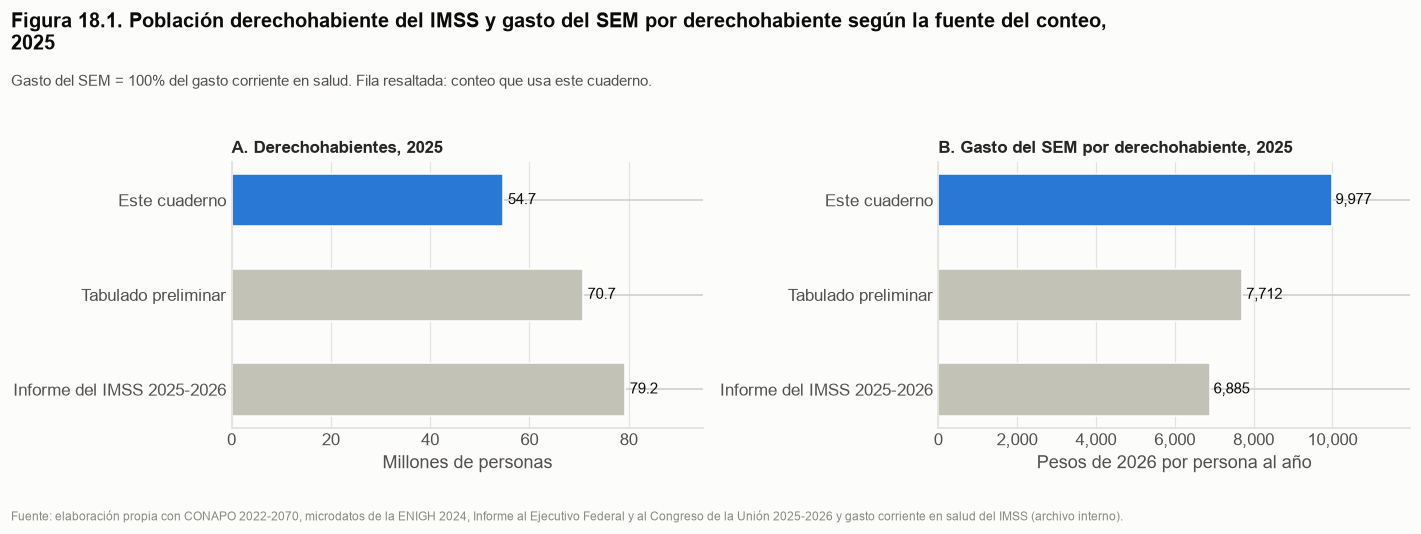

Lectura: El conteo de derechohabientes no cambia el gasto proyectado en procedimientos trazadores (3,974 MDP en 2055
         con los tres conteos), pero sí el gasto del SEM por derechohabiente: un conteo mayor reparte el mismo gasto
         entre más personas.


In [144]:
# ===== VIZ 18.1 | Pegar debajo de la celda 18.1c (derechohabientes por cotizante) =====
# ---------------- Figura 18.1 Derechohabientes y gasto por derechohabiente según la fuente del conteo ----------------
conteos_fig = gasto_por_dh.xs(ANIO_BASE, level="anio")
nombres_cortos = {nombre: nombre.split(" (")[0] for nombre in conteos_fig.index}
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.8))
y = np.arange(len(conteos_fig))
colores_conteo = [PAL["azul"], NEUTRO, NEUTRO]
ejes[0].barh(y, conteos_fig["derechohabientes (millones)"], color=colores_conteo, height=0.55)
for i, v in enumerate(conteos_fig["derechohabientes (millones)"]):
    ejes[0].text(v + 1, i, f"{v:,.1f}", va="center", color=TINTA)
ejes[0].set_title("A. Derechohabientes, 2025")
ejes[0].set_xlabel("Millones de personas")
ejes[1].barh(y, conteos_fig["gasto por derechohabiente (pesos de 2026)"], color=colores_conteo, height=0.55)
for i, v in enumerate(conteos_fig["gasto por derechohabiente (pesos de 2026)"]):
    ejes[1].text(v + 100, i, f"{v:,.0f}", va="center", color=TINTA)
ejes[1].set_title("B. Gasto del SEM por derechohabiente, 2025")
ejes[1].set_xlabel(EJE_PESOS_PERSONA)
for eje in ejes:
    eje.set_yticks(y, [nombres_cortos[n] for n in conteos_fig.index])
    eje.invert_yaxis()
    ejes_limpios(eje, "x"); miles(eje, "x")
ejes[0].set_xlim(0, conteos_fig["derechohabientes (millones)"].max() * 1.2)
ejes[1].set_xlim(0, conteos_fig["gasto por derechohabiente (pesos de 2026)"].max() * 1.2)
tope = titulo(fig, "Figura 18.1. Población derechohabiente del IMSS y gasto del SEM por derechohabiente según la fuente del conteo, 2025",
              f"Gasto del SEM = {PCT_GASTO_SEM:.0%} del gasto corriente en salud. Fila resaltada: conteo que usa este cuaderno.")
fuente(fig, "Fuente: elaboración propia con CONAPO 2022-2070, microdatos de la ENIGH 2024, Informe al Ejecutivo Federal y al Congreso "
            "de la Unión 2025-2026 y gasto corriente en salud del IMSS (archivo interno).")
plt.tight_layout(rect=[0, 0.07, 1, tope])
guardar_grafica("18_1_conteos_derechohabientes")
plt.show()
gasto_2055 = prueba_conteo[f"gasto {ANIO_FINAL} (MDP de 2026)"].iloc[0]
lectura(f"El conteo de derechohabientes no cambia el gasto proyectado en procedimientos trazadores ({gasto_2055:,.0f} MDP en "
        f"{ANIO_FINAL} con los tres conteos), pero sí el gasto del SEM por derechohabiente: un conteo mayor reparte el mismo gasto "
        "entre más personas.")

**Lectura de 18.1a-c**

* **Para el Núcleo 13 el conteo no cambia el gasto ni los casos.** Con la tasa de utilización fija por rango y sexo, `casos_t = casos_base × derechohabientes_t / derechohabientes_base`: un factor uniforme se cancela. Lo que cambia es la tasa por 100 mil derechohabientes y la descomposición entre efecto tamaño y efecto envejecimiento.
* **Excepción:** los escenarios de afiliación suman puntos porcentuales a la tasa (14.5), así que su efecto relativo sí depende del nivel de la tasa de partida.
* **Para la sección 10 el conteo sí importa:** el gasto por derechohabiente cambia en proporción inversa al conteo (18.1b).

**Recomendación (atiende a Héctor: un solo conteo para cobertura y costo).** Las secciones 19 a 23 usan CONAPO × tasa ENIGH (microdatos) para la cobertura y para el costo. El gasto del SEM es el gasto corriente en salud completo (`PCT_GASTO_SEM = 1.0`, 18.1b), la misma definición del balance de la sección 16.6. Los conteos de 70.7 y 79.2 millones se presentan como sensibilidad (20.5).

## 18.2 Ingresos del SEM: Tabla 5 del documento frente al Cuadro V.13 del Informe

Para expresar el saldo de 10a como % de los ingresos del SEM, Héctor usa el Cuadro V.13 del Informe. En 2030 esos ingresos son **2.5 % más altos** que los de la Tabla 5 del documento: el texto da 12.9 %, y con la Tabla 5 serían 13.2 % (así quedó en una nota al pie).

**Lo que pide:** la fuente de la Tabla 5 y qué incluye o excluye frente al V.13 (aportación del Gobierno Federal, otros ingresos o GMP). Si la diferencia es de definición, se anota en la nota al pie.

**Lo que se sabe:** la Tabla 5 sale del cuaderno de ingresos (`ingresos_SEM` = SEM-A + SEM-GMP, con cuotas obrero-patronales, aportaciones del Gobierno Federal y otros ingresos, en MDP de 2026; en este reporte está en la tabla `finanzas` de la sección 16.2). **Pendiente:** compararla renglón por renglón con el V.13 y revisar en qué pesos viene cada fuente.

In [145]:
# ---------------- 18.2 Ingresos del SEM por ramo y concepto, frente al Cuadro V.13 ----------------
# `engine` se reasigna en la sección 11 (DRGEngine); aquí se abre otra conexión con el mismo `url` de la sección 1.
try:
    engine_pg = create_engine(url)
    ingresos_imss = pd.read_sql("SELECT * FROM db_nucleo_13.hec_ingreso_imss", engine_pg)
    ingresos_imss["des_concepto"] = ingresos_imss["des_concepto"].str.strip()
    ingresos_imss["ramo"] = None
    ingresos_imss.loc[ingresos_imss["des_seguro"].str.contains("(SEM-A)", regex=False), "ramo"] = "SEM-A"
    ingresos_imss.loc[ingresos_imss["des_seguro"].str.contains("(SEM-GMP)", regex=False), "ramo"] = "SEM-GMP"
    sem_componentes = ingresos_imss.loc[ingresos_imss["ramo"].notna()].pivot_table(
        index="num_anio", columns=["ramo", "des_concepto"], values="val_valor", aggfunc="sum")
    print("Fuente: db_nucleo_13.hec_ingreso_imss (por ramo y concepto)")
except Exception as error:
    # Sin conexión: solo por concepto (SEM-A + SEM-GMP juntos), del archivo de insumos de la sección 16.6
    print("No se pudo leer la base; se usa ingresos_sem_concepto (sin separar ramos). Error:", error)
    sem_componentes = ingresos_sem_concepto.copy()

# Verificación: la suma de los componentes es la Tabla 5 (ingresos_SEM de la sección 16.2)
anios_comunes = sem_componentes.index.intersection(finanzas.index)
print("¿La suma de los componentes es igual a la Tabla 5?",
      np.allclose(sem_componentes.sum(axis=1).loc[anios_comunes], finanzas.loc[anios_comunes, "ingresos_SEM"]))

ANIOS_ANCLA = [2025, 2030, 2035, 2040, 2045, 2050, 2055]
composicion_sem = sem_componentes.loc[ANIOS_ANCLA].div(sem_componentes.loc[ANIOS_ANCLA].sum(axis=1), axis=0) * 100
print("Ingresos del SEM por componente (MDP de 2026):")
display(sem_componentes.loc[ANIOS_ANCLA].round(0))
print("Composición (% del total de la Tabla 5):")
display(composicion_sem.round(1))

Fuente: db_nucleo_13.hec_ingreso_imss (por ramo y concepto)
¿La suma de los componentes es igual a la Tabla 5? True
Ingresos del SEM por componente (MDP de 2026):


ramo                                     SEM-A                           \
des_concepto Aportaciones del Gobierno Federal Cuotas Obrero Patronales   
num_anio                                                                  
2025                                  146457.0                 281777.0   
2030                                  161314.0                 328762.0   
2035                                  185754.0                 386442.0   
2040                                  214378.0                 455697.0   
2045                                  244674.0                 532814.0   
2050                                  274071.0                 612576.0   
2055                                  294795.0                 677688.0   

ramo                                                  SEM-GMP  \
des_concepto Otros ingresos Aportaciones del Gobierno Federal   
num_anio                                                        
2025                24720.0                            4047.0   
2030                24287.0                            4692.0   
2035                24726.0                            5601.0   
2040                25149.0                            6715.0   
2045                25592.0                            8005.0   
2050                25897.0                            9399.0   
2055                25834.0                           10640.0   

ramo                                                  
des_concepto Cuotas Obrero Patronales Otros ingresos  
num_anio                                              
2025                          76842.0         7790.0  
2030                          89146.0         2977.0  
2035                         106411.0         3260.0  
2040                         127587.0         3534.0  
2045                         152090.0         3809.0  
2050                         178578.0         4036.0  
2055                         202161.0         4144.0

Composición (% del total de la Tabla 5):


ramo                                     SEM-A                           \
des_concepto Aportaciones del Gobierno Federal Cuotas Obrero Patronales   
num_anio                                                                  
2025                                      27.0                     52.0   
2030                                      26.4                     53.8   
2035                                      26.1                     54.3   
2040                                      25.7                     54.7   
2045                                      25.3                     55.1   
2050                                      24.8                     55.5   
2055                                      24.3                     55.8   

ramo                                                  SEM-GMP  \
des_concepto Otros ingresos Aportaciones del Gobierno Federal   
num_anio                                                        
2025                    4.6                               0.7   
2030                    4.0                               0.8   
2035                    3.5                               0.8   
2040                    3.0                               0.8   
2045                    2.6                               0.8   
2050                    2.3                               0.9   
2055                    2.1                               0.9   

ramo                                                  
des_concepto Cuotas Obrero Patronales Otros ingresos  
num_anio                                              
2025                             14.2            1.4  
2030                             14.6            0.5  
2035                             14.9            0.5  
2040                             15.3            0.4  
2045                             15.7            0.4  
2050                             16.2            0.4  
2055                             16.6            0.3

Gráfica guardada: graficas/reporte\18_2_ingresos_sem_por_concepto.png


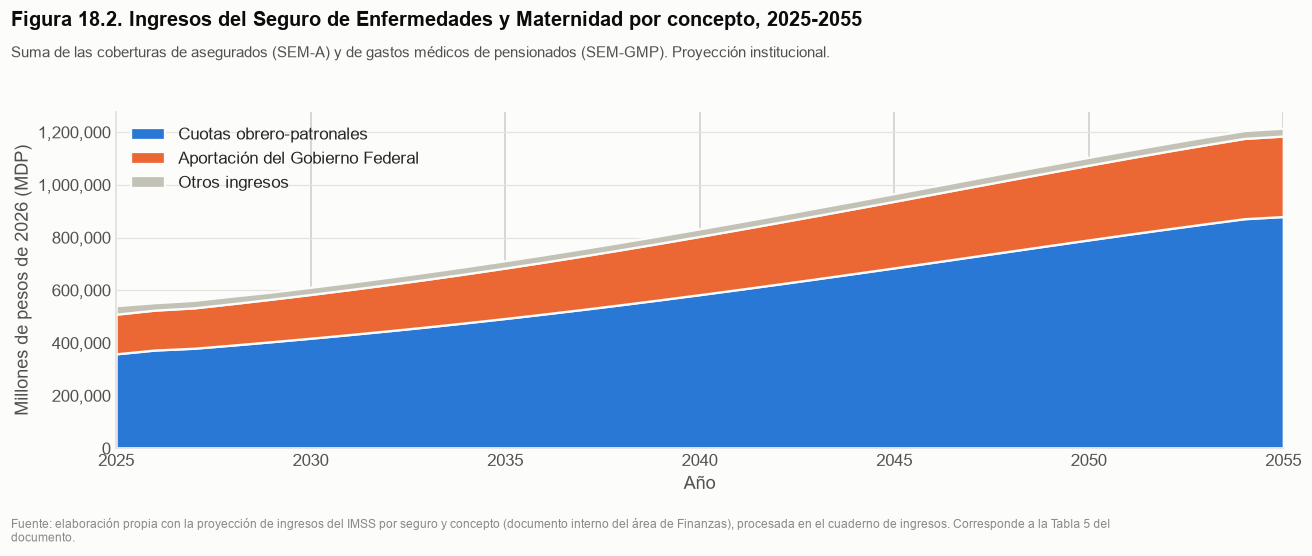

Lectura: Los ingresos del SEM pasan de 541,634 a 1,215,262 MDP. Las cuotas obrero-patronales aportan 66 % en 2025 y 72
         % en 2055; la aportación federal, 28 % y 25 %.


In [146]:
# ===== VIZ 18.2 | Pegar debajo de la celda 18.2 (ingresos del SEM por ramo y concepto) =====
# ---------------- Figura 18.2 Ingresos del SEM por concepto ----------------
if isinstance(sem_componentes.columns, pd.MultiIndex):
    por_concepto = sem_componentes.T.groupby(level="des_concepto").sum().T
else:
    por_concepto = sem_componentes.copy()
orden_conceptos = ["Cuotas Obrero Patronales", "Aportaciones del Gobierno Federal", "Otros ingresos"]
etiquetas_conceptos = {"Cuotas Obrero Patronales": "Cuotas obrero-patronales",
                       "Aportaciones del Gobierno Federal": "Aportación del Gobierno Federal", "Otros ingresos": "Otros ingresos"}
colores_conceptos = [PAL["azul"], PAL["naranja"], NEUTRO]
por_concepto = por_concepto.loc[ANIO_BASE:ANIO_FINAL, orden_conceptos]
fig, eje = plt.subplots(figsize=(12, 5))
eje.stackplot(por_concepto.index, [por_concepto[c] for c in orden_conceptos], colors=colores_conceptos,
              edgecolor=FONDO, linewidth=1.5, labels=[etiquetas_conceptos[c] for c in orden_conceptos])
eje.set_xlim(ANIO_BASE, ANIO_FINAL)
eje.set_ylabel(EJE_MDP)
eje.set_xlabel("Año")
ejes_limpios(eje); miles(eje)
eje.legend(loc="upper left")
tope = titulo(fig, f"Figura 18.2. Ingresos del Seguro de Enfermedades y Maternidad por concepto, {ANIO_BASE}-{ANIO_FINAL}",
              "Suma de las coberturas de asegurados (SEM-A) y de gastos médicos de pensionados (SEM-GMP). Proyección institucional.")
fuente(fig, "Fuente: elaboración propia con la proyección de ingresos del IMSS por seguro y concepto (documento interno del área de "
            "Finanzas), procesada en el cuaderno de ingresos. Corresponde a la Tabla 5 del documento.")
plt.tight_layout(rect=[0, 0.07, 1, tope])
guardar_grafica("18_2_ingresos_sem_por_concepto")
plt.show()
total = por_concepto.sum(axis=1)
participacion = por_concepto.div(total, axis=0) * 100
lectura(f"Los ingresos del SEM pasan de {total.loc[ANIO_BASE]:,.0f} a {total.loc[ANIO_FINAL]:,.0f} MDP. Las cuotas obrero-patronales "
        f"aportan {participacion.loc[ANIO_BASE, orden_conceptos[0]]:.0f} % en {ANIO_BASE} y {participacion.loc[ANIO_FINAL, orden_conceptos[0]]:.0f} % "
        f"en {ANIO_FINAL}; la aportación federal, {participacion.loc[ANIO_BASE, orden_conceptos[1]]:.0f} % y "
        f"{participacion.loc[ANIO_FINAL, orden_conceptos[1]]:.0f} %.")

## 18.3 Preguntas para la visita al IMSS

Pedir la fuente por escrito (guía, oficio, criterio normativo o cuadro):

1. **El escalón arriba del salario mínimo.** El primer tramo de cesantía y vejez a cargo del patrón es «1.01 SM a 1.50 UMA» y está vacío desde 2023, porque el salario mínimo ya supera 1.5 UMA. ¿Qué tasa aplica el SUA a un salario de 1.01 salarios mínimos: la del tramo que le toca por su valor en UMA o la del primer tramo después del mínimo? Con la primera, en 2030 el total a cargo del patrón sube 4.4 puntos; con la segunda, baja 1.4.
2. **El denominador del costo por persona.** ¿Qué población usa la Dirección de Finanzas: derechohabientes, población adscrita a médico familiar u otra? Esto resuelve buena parte de 18.1.
3. **Gastos de administración de GMP.** Según la nota 3 del Cuadro V.19, incluyen la parte de GMP de los pasivos laborales del IMSS como patrón (cerca de un billón de pesos en valor presente). ¿Se puede separar cuánto es pensiones del personal y cuánto es administración?
4. **Cuadros V.19 y V.24.** Tienen diferencias pequeñas en los años ancla (por ejemplo, el déficit de GMP de 2036: −135,137 frente a −134,117 millones). ¿Cuál es la referencia? Héctor usa el V.24.
5. **Infonavit.** ¿El IMSS tiene la recaudación efectiva de la aportación de 5 % (2024 o 2025)? En 10b solo se usa la recaudación teórica.

## 18.4 Revisión general que pide

1. **Términos:** que la sección 10 use los mismos términos y definiciones del documento (derechohabientes, cotizantes, SEM, GMP, ingresos y déficit).
2. **Referencias cruzadas** a las secciones 3.2, 4.2, 5.6 y 7 del documento. En particular:
   * *«El gasto en salud ya iguala los ingresos del SEM»*: el balance de la sección 16.6 (y 5.6 del cuaderno de ingresos) da alrededor de −0.7 % de los ingresos en 2025. Se sostiene, con la salvedad de que el gasto corriente es de todo el IMSS.
   * *«El modelo no traslada a las cuotas los cambios en la formalidad»*: en la sección 16.0, `AJUSTAR_INGRESOS_POR_ESCENARIO = False`, así que los ingresos no cambian entre escenarios. Se sostiene.
3. **Ubicación:** la sección 10 quedó después de «9. Anexos». Propuesta: moverla antes de los anexos y renumerar (se decide en conjunto).
4. **Claridad:** la sección está escrita para un lector no técnico; marcar lo que no se entienda a la primera.

## 18.5 Qué necesita de vuelta

| # | Tema | Estado |
|---|---|---|
| 1 | Conciliación de derechohabientes | Prueba de conteos, gasto por derechohabiente y recomendación en 18.1a-c; un solo conteo en las secciones 19 a 23 |
| 2 | Fuente de la Tabla 5 | Componentes en 18.2. La comparación renglón por renglón con el Cuadro V.13 queda pendiente: no se tiene el cuadro |
| 3 | Respuestas de la visita al IMSS (criterio del SUA y denominador del costo por persona) | Pendiente |
| 4 | Comentarios generales | Dos referencias cruzadas revisadas (18.4) |
| 5 | Secciones 10a y 10b conciliadas con este cuaderno | Secciones 20 y 21; escenarios en 22; resumen en 23 |


# 19. Afiliación voluntaria a cuota fija por grupo de edad (tipo Seguro de Salud para la Familia)

**Pregunta.** ¿Cuánto ingreso y cuánto costo trae al SEM afiliar con una cuota fija por persona a quienes hoy no tienen IMSS, y cómo cambia si se afilia a jóvenes o a personas mayores?

| Pieza | De dónde sale |
|---|---|
| Población sin IMSS | Población del escenario − derechohabientes del escenario (13.4 y 14.7): el mismo conteo para cobertura y costo |
| Gasto del SEM | Gasto corriente en salud (`PCT_GASTO_SEM`, 18.1b; base 100 %) |
| Costo por edad | Perfil de Héctor: 65 años o más cuesta el triple que 20 a 64 |
| Crecimiento del costo | Crece con el salario real, como los ingresos (`COSTO_CRECE_CON_SALARIO`); `False` = supuesto de Héctor (constante) |
| Afiliación, cobro y sobrecosto | 50 %, 75 % y 10 % (Tabla 10.1) |
| Aportación federal | En el SSFAM es por familia (6,125 pesos al año en 2025-2026). Base: **solo la cuota de la persona**; la aportación federal va como sensibilidad (19.4) |
| Ingresos del SEM | Tabla 5 (`finanzas`, 16.2) |

Esquemas: **cuota única** (misma para todas las edades, saldo cero en 2030 para toda la población sin IMSS) y **cuota por edad del SSFAM** con las tarifas 2026 del IMSS.

**Insumos clave**

* **Ingreso:** tarifas anuales del Seguro de Salud para la Familia 2026 por edad (IMSS, trámite IMSS-02-014) × afiliados × 75 % de cobro; sin aportación federal en la base (sensibilidad en 19.4 con 6,125 pesos por familia, Informe IMSS 2024-2025, cuadro VII.1). Para expresar el saldo: proyección institucional de ingresos del IMSS por seguro y concepto, 2024-2055 (documento interno del área de Finanzas; base `db_nucleo_13.hec_ingreso_imss`), procesada en el cuaderno de ingresos; ingresos del SEM = SEM-A + SEM-GMP (cuotas obrero-patronales, aportación del Gobierno Federal y otros ingresos), `finanzas["ingresos_SEM"]` (Tabla 5 del documento), MDP de 2026.
* **Gasto:** costo de atención por persona = gasto corriente en salud del IMSS (archivo interno `CENTRO DE COSTOS DE QUIROFANO 2020-2026 021026.xlsx`, pestaña `gasto_corrientes_saludIMSS`), deflactado a pesos de 2026 con el Simulador Fiscal del CIEP (`deflator2027.xlsx`); 2025 × `PCT_GASTO_SEM` (18.1b, base 100 %). Se reparte entre los derechohabientes de 2025 con el perfil por edad de la Tabla 10.1 (65 años o más = triple de 20 a 64) y crece con el salario real (`g_SBC_real`, hoja Resumen_tasas del cuaderno de ingresos, que viene de `db_nucleo_13.hec_crecimiento_sbc`); × afiliados × 1.10 de sobrecosto.
* **Población:** personas sin IMSS = población del escenario − derechohabientes del escenario; CONAPO 2022-2070 (`00_Pob_Mitad_1950_2070.csv`, total nacional por edad simple y sexo) × tasa de afiliación al IMSS por rango de edad y sexo de los microdatos ponderados de la ENIGH 2024 (`poblacion.csv`, `inst_1`), sección 13.4; escenarios de la sección 14.7. Se afilia 50 % de las personas sin IMSS del grupo de edad, de forma gradual entre 2026 y 2030.

In [147]:
# =====================================================================================================
# 19. Afiliación voluntaria a cuota fija por grupo de edad (tipo Seguro de Salud para la Familia)
# =====================================================================================================
# Quién se afilia: personas SIN IMSS de un grupo de edad = población del escenario − derechohabientes del escenario
# (secciones 13.4 y 14.7). Cuánto pagan: una cuota fija anual por persona (no depende del ingreso).
# Supuestos de comportamiento y gasto: los mismos de la sección 10a de Héctor (Tabla 10.1).

# ---------------- Supuestos de la sección 10a (Tabla 10.1) ----------------
AFILIACION = 0.50                    # proporción de las personas elegibles que se afilia (al año meta)
COBRO = 0.75                         # proporción de las cuotas que efectivamente se cobra
SOBRECOSTO = 0.10                    # sobrecosto de atención de quienes se afilian primero
G_COSTO_REAL = 0.0                   # crecimiento real anual ADICIONAL del costo por persona (sensibilidad: 0.02)
# Crecimiento del costo de atención por persona. Base: crece con el salario real, igual que los ingresos del SEM, para que
# los saldos no mejoren solo porque el costo se queda fijo mientras los ingresos crecen (comentario de Mónica: Finanzas
# proyecta crecimiento real del gasto en salud). False = supuesto de Héctor (costo constante en términos reales).
COSTO_CRECE_CON_SALARIO = True
PESOS_COSTO_EDAD = [(0, 20, 1.0), (20, 65, 1.0), (65, 200, 3.0)]   # 65 o más = triple de 20 a 64; 0 a 19 = 1 (por confirmar)

# Parámetros de la sección 10a que también usa la sección 20
PCT_UMA_GF = 0.1483                  # aportación fija del GF por titular en 10a: 14.83 % de la UMA diaria
UMA_DIARIA_2026 = 117.31             # reproduce el ejemplo de 10a.2 (8,736 = 20.40 % × UMA × 365). Confirmar con el DOF

# Aportación federal del SSFAM: es por FAMILIA, no por persona (LSS art. 242: cuota diaria de 13.9 % del salario mínimo
# del D.F. de julio de 1997, actualizada con el INPC). Último monto verificado: 6,125 pesos al año por familia,
# marzo 2025-febrero 2026 (Informe IMSS 2024-2025, cuadro VII.1). El de marzo 2026-febrero 2027 no está publicado.
# Base: solo la cuota de la persona. La aportación federal se muestra como sensibilidad en 19.4.
INCLUIR_APORTACION_GF = False
APORTACION_GF_FAMILIA = 6125.0       # pesos al año por familia (vigencia marzo 2025-febrero 2026)
PERSONAS_POR_FAMILIA = 2.9           # mismo valor que 10a.4 (derechohabientes por titular)
APORTACION_GF_POR_AFILIADO = APORTACION_GF_FAMILIA / PERSONAS_POR_FAMILIA if INCLUIR_APORTACION_GF else 0.0

# ---------------- Gasto del SEM ----------------
# PCT_GASTO_SEM se define en 18.1b (base: 100 %)
GASTO_SEM_BASE = finanzas.loc[ANIO_BASE, "gasto_corriente_salud"] * PCT_GASTO_SEM          # MDP de 2026

# ---------------- Experimentos: grupo de edad que puede afiliarse ----------------
EXPERIMENTOS_EDAD = {                # nombre: (edad mínima, edad máxima + 1)
    "Jóvenes de 18 a 34": (18, 35),
    "Adultos de 35 a 59": (35, 60),
    "Mayores de 60 y más": (60, 200),
    "Toda la población sin IMSS": (0, 200),
}

# ---------------- Esquemas de cuota (pesos de 2026 por persona al año, constante en términos reales) ----------------
# 1) "Cuota única": la misma cuota para todas las edades, calibrada para que el esquema de "Toda la población sin IMSS"
#    tenga saldo cero en ANIO_META_AFILIACION (se calcula en 19.2).
# 2) "Cuota por edad (SSFAM)": cuotas anuales por persona del Seguro de Salud para la Familia, según edad cumplida.
#    Vigencia marzo 2026-febrero 2027 (pesos de 2026). Fuente: IMSS, trámite IMSS-02-014 y preguntas frecuentes
#    (https://www.imss.gob.mx/faq/seguro-familia). Pago anual anticipado por persona.
#    El SSFAM excluye ciertos padecimientos preexistentes y tiene periodos de espera (RACERF, arts. 82 a 84).
CUOTA_SSFAM_POR_EDAD = {
    (0, 20): 9300.0,
    (20, 30): 11550.0,
    (30, 40): 12350.0,
    (40, 50): 14350.0,
    (50, 60): 14850.0,
    (60, 70): 20600.0,
    (70, 80): 21500.0,
    (80, 200): 22150.0,
}

ANIO_INICIO_AFILIACION = 2026        # la afiliación crece en línea recta desde este año
ANIO_META_AFILIACION = 2030          # hasta llegar a AFILIACION en este año
ESCENARIO_19 = "E0"                  # escenario de población de la sección 14
ANIOS_19 = list(range(ANIO_INICIO_AFILIACION, ANIO_FINAL + 1))
ANIOS_TABLA_19 = [2030, 2040, ANIO_FINAL]

# ---------------- Insumos del cuaderno de ingresos ----------------
# Crecimiento real del salario (SBC de personas aseguradas), hoja Resumen_tasas
ARCHIVO_RESULTADOS_IMSS = "datos/procesada/IMSS_tasas_crecimiento_resultados.xlsx"
resumen_ingresos = pd.read_excel(ARCHIVO_RESULTADOS_IMSS, sheet_name="Resumen_tasas").set_index("anio")
g_salario_real = resumen_ingresos["g_SBC_real"].fillna(0.0)

# Índice de salario real, 2026 = 1 (año de precios de los ejercicios)
ANIO_INICIO_10A = 2026
indice_salario = pd.Series(1.0, index=range(ANIO_BASE, ANIO_FINAL + 1))
for anio in range(ANIO_INICIO_10A + 1, ANIO_FINAL + 1):
    indice_salario.loc[anio] = indice_salario.loc[anio - 1] * (1 + g_salario_real.loc[anio])
indice_salario.loc[ANIO_BASE] = 1 / (1 + g_salario_real.loc[ANIO_INICIO_10A])


def factor_costo(anios, g_extra=G_COSTO_REAL):
    # Costo por persona del año t frente a ANIO_BASE: salario real (si COSTO_CRECE_CON_SALARIO) × (1 + g_extra)^(t − base)
    escalar = np.isscalar(anios)
    anios = np.atleast_1d(np.asarray(anios))
    salario = (indice_salario.reindex(anios).values / indice_salario.loc[ANIO_BASE]) if COSTO_CRECE_CON_SALARIO \
        else np.ones(len(anios))
    factor = salario * (1 + g_extra) ** (anios - ANIO_BASE)
    return float(factor[0]) if escalar else factor


# Deflactor del cuaderno de ingresos (Simulador Fiscal CIEP, 2026 = 1) para pasar el ingreso de la ENIGH a pesos de 2026
ARCHIVO_DEFLACTOR_GENERAL = "datos/deflator2027.xlsx"
deflactor_general = pd.read_excel(ARCHIVO_DEFLACTOR_GENERAL).set_index("anio")["deflator_2026"]
factor_ingreso_2026 = 1 / deflactor_general.loc[2024]

print(f"Gasto del SEM en {ANIO_BASE}: {GASTO_SEM_BASE:,.0f} MDP de 2026 ({PCT_GASTO_SEM:.0%} del gasto corriente en salud)")
print("Costo por persona frente a 2025 (crece con el salario real):",
      {a: round(factor_costo(a), 3) for a in [2030, 2040, ANIO_FINAL]})
print(f"Aportación federal por afiliado: {APORTACION_GF_POR_AFILIADO:,.0f} pesos al año")

Gasto del SEM en 2025: 545,271 MDP de 2026 (100% del gasto corriente en salud)
Costo por persona frente a 2025 (crece con el salario real): {2030: 1.078, 2040: 1.172, 2055: 1.33}
Aportación federal por afiliado: 0 pesos al año


## 19.0b Variables de la ENIGH 2024 (definiciones y filtros)

Las secciones 19, 20 y 22 usan estas variables. Cada una se construye en un paso de la celda siguiente, que imprime cuántas personas la cumplen.

| Variable | Archivo | Regla | Para qué se usa |
|---|---|---|---|
| `dh_imss` | poblacion.csv | `inst_1 = 1`: declara afiliación o acceso al IMSS (sección 13.2) | Quién ya tiene IMSS |
| `subsistema` | poblacion.csv | `inst_1` IMSS, `inst_2` ISSSTE, `inst_3` Pemex/Defensa/Marina, `inst_4` ISSSTE estatal. Si declara dos, cuenta el primero de esa lista | Cobertura por subsistema (22.1) |
| `es_subordinado` | trabajos.csv | Algún trabajo con `subor = 1` (trabaja para un patrón) | Condición laboral |
| `es_independiente` | trabajos.csv | Algún trabajo con `indep = 1` (trabaja por su cuenta o tiene un negocio) | Universo de 10a |
| `subordinado_formal` | trabajos.csv | Trabajo subordinado con `contrato = 1` o alguna prestación de `pres_1` a `pres_19` (incluye SAR/AFORE, `pres_8`) | Cotizante |
| `cotizante` | ambos | `subordinado_formal` y afiliado a un subsistema | Ingresos por escenario (22) |
| `trabaja_sin_imss` | ambos | Trabaja (subordinado o independiente) y `dh_imss = 0` | Hogares elegibles en 10a |
| `ing_sub_mensual` | ingresos.csv | Ingreso por trabajo subordinado (claves de 13.2) | Ingreso del titular |
| `ing_negocio_mensual` | ingresos.csv | Claves P068 a P081: ingreso por negocios propios | Ingreso del titular independiente |
| `ingreso_hogar_pc_2026` | ingresos.csv | Ingreso monetario del hogar (todas las claves menos P101 a P108, que son percepciones financieras y de capital) entre sus integrantes, anual, pesos de 2026 | Asequibilidad (19.5) |

> Conviene confirmar en el descriptor de archivos de la ENIGH 2024 el significado de `pres_20` y de las claves P068 a P081 y P101 a P108.

In [148]:
# ---------------- 19.0b Variables de la ENIGH 2024 para las secciones 19, 20 y 22 ----------------
# Una fila por persona. Cada paso construye UNA variable e imprime cuántas personas la cumplen (con factor de expansión),
# para revisarla contra los tabulados del INEGI. La tabla de definiciones está en el texto de arriba.
LLAVE_HOGAR = ["folioviv", "foliohog"]
ARCHIVO_ENIGH_TRABAJOS = "datos/trabajos.csv"
SUBSISTEMAS = {"IMSS": "inst_1", "ISSSTE": "inst_2", "Pemex, Defensa o Marina": "inst_3", "ISSSTE estatal": "inst_4"}
SIN_SS = "Sin seguridad social contributiva"
PRESTACIONES = [f"pres_{i}" for i in range(1, 20)]          # pres_1 a pres_19 (pres_20 no se cuenta)
CLAVES_NEGOCIO = [f"P0{n}" for n in range(68, 82)]          # P068 a P081: ingreso por negocios propios
CLAVES_CAPITAL = [f"P{n}" for n in range(101, 109)]         # P101 a P108: percepciones financieras y de capital


def millones(columna):
    # Personas que cumplen la condición, con factor de expansión (millones)
    return (personas_enigh["factor"] * personas_enigh[columna]).sum() / 1e6


# Paso 0. Punto de partida: las personas de la sección 13.2 (ya traen edad, sexo, factor, dh_imss e ingreso subordinado)
personas_enigh = enigh[LLAVE_PERSONA + ["sexo", "edad", "grupo_edad", "factor", "dh_imss", "ing_sub_mensual"]].copy()
print(f"Paso 0. Personas en la ENIGH 2024: {personas_enigh['factor'].sum() / 1e6:,.1f} millones")
print(f"        con IMSS (inst_1 = 1): {millones('dh_imss'):,.1f} millones")

# Paso 1. Subsistema de seguridad social (poblacion.csv). Si declara dos, cuenta el de mayor prioridad (orden del diccionario)
inst = pd.read_csv(ARCHIVO_ENIGH_POBLACION, dtype=str, usecols=LLAVE_PERSONA + list(SUBSISTEMAS.values()))
personas_enigh = personas_enigh.merge(inst, on=LLAVE_PERSONA, how="left")
personas_enigh["subsistema"] = SIN_SS
for nombre in reversed(list(SUBSISTEMAS)):            # al revés: el último que se asigna es el de mayor prioridad
    tiene = pd.to_numeric(personas_enigh[SUBSISTEMAS[nombre]], errors="coerce").fillna(0) > 0
    personas_enigh.loc[tiene, "subsistema"] = nombre
personas_enigh = personas_enigh.drop(columns=list(SUBSISTEMAS.values()))
print("Paso 1. Personas por subsistema (millones):",
      (personas_enigh.groupby("subsistema")["factor"].sum() / 1e6).round(1).to_dict())

# Paso 2. Condición laboral (trabajos.csv: un renglón por trabajo; una persona puede tener dos trabajos)
trabajos = pd.read_csv(ARCHIVO_ENIGH_TRABAJOS, dtype=str, usecols=LLAVE_PERSONA + ["subor", "indep", "contrato"] + PRESTACIONES)
for columna in ["subor", "indep", "contrato"] + PRESTACIONES:
    trabajos[columna] = pd.to_numeric(trabajos[columna], errors="coerce").fillna(0)
trabajos["es_subordinado"] = trabajos["subor"] == 1                 # trabaja para un patrón
trabajos["es_independiente"] = trabajos["indep"] == 1               # trabaja por su cuenta o tiene un negocio
trabajos["con_contrato_o_prestacion"] = (trabajos["contrato"] == 1) | (trabajos[PRESTACIONES] > 0).any(axis=1)
trabajos["subordinado_formal"] = trabajos["es_subordinado"] & trabajos["con_contrato_o_prestacion"]
por_persona = trabajos.groupby(LLAVE_PERSONA)[["es_subordinado", "es_independiente", "subordinado_formal"]].max()
personas_enigh = personas_enigh.merge(por_persona.astype(int).reset_index(), on=LLAVE_PERSONA, how="left")
personas_enigh[["es_subordinado", "es_independiente", "subordinado_formal"]] = (
    personas_enigh[["es_subordinado", "es_independiente", "subordinado_formal"]].fillna(0).astype(int))
personas_enigh["trabaja"] = ((personas_enigh["es_subordinado"] + personas_enigh["es_independiente"]) > 0).astype(int)
print(f"Paso 2. Trabajan: {millones('trabaja'):,.1f} millones | subordinados: {millones('es_subordinado'):,.1f} | "
      f"independientes: {millones('es_independiente'):,.1f} | subordinados con contrato o prestación: {millones('subordinado_formal'):,.1f}")

# Paso 3. Cotizante: subordinado con contrato o prestación Y afiliado a un subsistema (regla del cuaderno NTA)
personas_enigh["cotizante"] = ((personas_enigh["subordinado_formal"] == 1) & (personas_enigh["subsistema"] != SIN_SS)).astype(int)
personas_enigh["cotizante_imss"] = ((personas_enigh["cotizante"] == 1) & (personas_enigh["subsistema"] == "IMSS")).astype(int)
print(f"Paso 3. Cotizantes: {millones('cotizante'):,.1f} millones, de ellos al IMSS: {millones('cotizante_imss'):,.1f} "
      f"(referencia: 22.35 millones de cotizantes del SEM en dic-2025)")

# Paso 4. Trabajador sin IMSS (el universo de la afiliación subsidiada, sección 20)
personas_enigh["trabaja_sin_imss"] = ((personas_enigh["trabaja"] == 1) & (personas_enigh["dh_imss"] == 0)).astype(int)
print(f"Paso 4. Trabajan y no tienen IMSS: {millones('trabaja_sin_imss'):,.1f} millones")

# Paso 5. Ingresos (ingresos.csv, ya cargado en 13.2 como ingresos_enigh; ing_tri es el ingreso del trimestre)
negocio = (ingresos_enigh.loc[ingresos_enigh["clave"].isin(CLAVES_NEGOCIO)]
           .groupby(LLAVE_PERSONA)["ing_tri"].sum().div(3).rename("ing_negocio_mensual").reset_index())
personas_enigh = personas_enigh.merge(negocio, on=LLAVE_PERSONA, how="left")
personas_enigh["ing_negocio_mensual"] = personas_enigh["ing_negocio_mensual"].fillna(0.0)
personas_enigh["ing_laboral_mensual"] = personas_enigh["ing_sub_mensual"] + personas_enigh["ing_negocio_mensual"]

monetario = ingresos_enigh.loc[~ingresos_enigh["clave"].isin(CLAVES_CAPITAL)]
ingreso_hogar = monetario.groupby(LLAVE_HOGAR)["ing_tri"].sum().mul(4).rename("ingreso_hogar_anual").reset_index()
tamano_hogar = personas_enigh.groupby(LLAVE_HOGAR).size().rename("integrantes").reset_index()
hogar = tamano_hogar.merge(ingreso_hogar, on=LLAVE_HOGAR, how="left").fillna({"ingreso_hogar_anual": 0.0})
hogar["ingreso_hogar_pc_2026"] = hogar["ingreso_hogar_anual"] / hogar["integrantes"] * factor_ingreso_2026
personas_enigh = personas_enigh.merge(hogar[LLAVE_HOGAR + ["integrantes", "ingreso_hogar_pc_2026"]], on=LLAVE_HOGAR, how="left")
mediana_pc = np.average(personas_enigh["ingreso_hogar_pc_2026"], weights=personas_enigh["factor"])
print(f"Paso 5. Ingreso monetario del hogar por persona (pesos de 2026 al año), promedio: {mediana_pc:,.0f}")


Paso 0. Personas en la ENIGH 2024: 130.3 millones
        con IMSS (inst_1 = 1): 53.6 millones
Paso 1. Personas por subsistema (millones): {'IMSS': 53.6, 'ISSSTE': 6.4, 'ISSSTE estatal': 1.1, 'Pemex, Defensa o Marina': 1.9, 'Sin seguridad social contributiva': 67.4}
Paso 2. Trabajan: 63.9 millones | subordinados: 50.9 | independientes: 15.4 | subordinados con contrato o prestación: 29.7
Paso 3. Cotizantes: 25.1 millones, de ellos al IMSS: 21.5 (referencia: 22.35 millones de cotizantes del SEM en dic-2025)
Paso 4. Trabajan y no tienen IMSS: 36.8 millones
Paso 5. Ingreso monetario del hogar por persona (pesos de 2026 al año), promedio: 83,032


## 19.1 Costo por persona, población elegible y función del ejercicio

In [149]:
# ---------------- 19.1 Costo por persona y población elegible ----------------
def peso_costo(edades):
    pesos = np.zeros(len(edades))
    for inicio, fin, peso in PESOS_COSTO_EDAD:
        pesos[(edades >= inicio) & (edades < fin)] = peso
    return pesos


# Costo de referencia: el gasto del SEM de ANIO_BASE repartido entre los derechohabientes (13.4) con el perfil por edad
dh_base = conapo.loc[conapo["anio"] == ANIO_BASE]
COSTO_REFERENCIA = GASTO_SEM_BASE * 1e6 / (dh_base["derechohabientes"] * peso_costo(dh_base["edad"].values)).sum()
COSTO_PROMEDIO_DH = GASTO_SEM_BASE * 1e6 / dh_base["derechohabientes"].sum()
print(f"Costo por derechohabiente: promedio {COSTO_PROMEDIO_DH:,.0f} pesos de 2026; "
      f"20 a 64 años {COSTO_REFERENCIA:,.0f}; 65 o más {3 * COSTO_REFERENCIA:,.0f}")

# Población sin IMSS por escenario, año y edad simple (sección 14.7)
elegibles_19 = dh_edad_esc[["escenario", "anio", "edad", "sexo", "poblacion", "factor_nacimientos",
                            "factor_mayores", "derechohabientes"]].copy()
elegibles_19["poblacion_escenario"] = (elegibles_19["poblacion"] * elegibles_19["factor_nacimientos"]
                                       * elegibles_19["factor_mayores"])
elegibles_19["sin_imss"] = (elegibles_19["poblacion_escenario"] - elegibles_19["derechohabientes"]).clip(lower=0)
elegibles_19["costo_persona"] = COSTO_REFERENCIA * peso_costo(elegibles_19["edad"].values)


def cuota_por_edad(edades, esquema, cuota_unica=None):
    if esquema == "Cuota única":
        return np.full(len(edades), cuota_unica)
    cuotas = np.full(len(edades), np.nan)
    for (inicio, fin), cuota in CUOTA_SSFAM_POR_EDAD.items():
        cuotas[(edades >= inicio) & (edades < fin)] = cuota
    return cuotas


def simular_cuota_fija(experimento, esquema, cuota_unica=None, escenario=ESCENARIO_19, afiliacion=AFILIACION,
                       cobro=COBRO, sobrecosto=SOBRECOSTO, g_costo=G_COSTO_REAL, aportacion_gf=None):
    edad_min, edad_max = EXPERIMENTOS_EDAD[experimento]
    tabla = elegibles_19.loc[(elegibles_19["escenario"] == escenario) & elegibles_19["anio"].isin(ANIOS_19)
                             & (elegibles_19["edad"] >= edad_min) & (elegibles_19["edad"] < edad_max)].copy()
    avance_afiliacion = np.clip((tabla["anio"] - ANIO_INICIO_AFILIACION + 1)
                                / (ANIO_META_AFILIACION - ANIO_INICIO_AFILIACION + 1), 0, 1)
    tabla["afiliados"] = tabla["sin_imss"] * afiliacion * avance_afiliacion
    tabla["cuota"] = tabla["afiliados"] * cuota_por_edad(tabla["edad"].values, esquema, cuota_unica) * cobro
    aportacion_gf = APORTACION_GF_POR_AFILIADO if aportacion_gf is None else aportacion_gf
    tabla["aportacion_gf"] = tabla["afiliados"] * aportacion_gf
    tabla["costo"] = (tabla["afiliados"] * tabla["costo_persona"] * (1 + sobrecosto)
                      * factor_costo(tabla["anio"].values, g_costo))
    r = tabla.groupby("anio")[["afiliados", "cuota", "aportacion_gf", "costo"]].sum()
    r["afiliados"] = r["afiliados"] / 1e6
    r[["cuota", "aportacion_gf", "costo"]] = r[["cuota", "aportacion_gf", "costo"]] / 1e6
    r["saldo"] = r["costo"] - r["cuota"] - r["aportacion_gf"]
    r["saldo % ingresos del SEM"] = r["saldo"] / finanzas.loc[r.index, "ingresos_SEM"] * 100
    r["saldo por afiliado (pesos)"] = r["saldo"] / r["afiliados"]
    r["ingresos del SEM con el esquema"] = finanzas.loc[r.index, "ingresos_SEM"] + r["cuota"] + r["aportacion_gf"]
    r = r.rename(columns={"afiliados": "afiliados (millones)", "cuota": "cuotas cobradas",
                          "aportacion_gf": "aportación del GF", "costo": "costo de atención"})
    return r


def percentil_ponderado_19(valores, pesos, p):
    valores, pesos = np.asarray(valores, dtype=float), np.asarray(pesos, dtype=float)
    orden = np.argsort(valores)
    acumulado = np.cumsum(pesos[orden]) / pesos.sum()
    return float(np.interp(p / 100, acumulado, valores[orden]))

Costo por derechohabiente: promedio 9,977 pesos de 2026; 20 a 64 años 8,337; 65 o más 25,010


## 19.2 Cuota única y resultados por grupo de edad

In [150]:
# ---------------- 19.2 Cuota única calibrada y resultados por experimento ----------------
# Cuota única: saldo cero en ANIO_META_AFILIACION para toda la población sin IMSS
r_cero = simular_cuota_fija("Toda la población sin IMSS", "Cuota única", cuota_unica=0.0)
fila = r_cero.loc[ANIO_META_AFILIACION]
CUOTA_UNICA = (fila["costo de atención"] - fila["aportación del GF"]) * 1e6 / (fila["afiliados (millones)"] * 1e6 * COBRO)
print(f"Cuota única de equilibrio: {CUOTA_UNICA:,.0f} pesos de 2026 por persona al año "
      f"({CUOTA_UNICA / 12:,.0f} al mes; {CUOTA_UNICA / 365 / UMA_DIARIA_2026:.1%} de la UMA diaria × 365)")

ESQUEMAS_19 = ["Cuota única"] + (["Cuota por edad (SSFAM)"] if len(CUOTA_SSFAM_POR_EDAD) > 0 else [])
if len(CUOTA_SSFAM_POR_EDAD) == 0:
    print("Sin cuotas del SSFAM capturadas: solo se corre la cuota única.")

resultados_19 = {}
for esquema in ESQUEMAS_19:
    for experimento in EXPERIMENTOS_EDAD:
        resultados_19[(esquema, experimento)] = simular_cuota_fija(experimento, esquema, cuota_unica=CUOTA_UNICA)

columnas_19 = ["afiliados (millones)", "cuotas cobradas", "aportación del GF", "costo de atención", "saldo",
               "saldo % ingresos del SEM", "saldo por afiliado (pesos)"]
for anio in ANIOS_TABLA_19:
    tabla = pd.DataFrame({clave: r.loc[anio, columnas_19] for clave, r in resultados_19.items()}).T
    tabla.index.names = ["esquema", "experimento"]
    print(f"\n{anio}: MDP de 2026 (saldo positivo = el costo supera a lo que entra)")
    display(tabla.round(1))

# ¿Cubre la tarifa del SSFAM el costo esperado de cada grupo de edad? (por persona al año, pesos de 2026)
if len(CUOTA_SSFAM_POR_EDAD) > 0:
    filas = []
    for (inicio, fin), cuota in CUOTA_SSFAM_POR_EDAD.items():
        edades = np.arange(inicio, min(fin, 110))
        dh_grupo = dh_base.loc[dh_base["edad"].isin(edades)]
        costo = (dh_grupo["derechohabientes"] * dh_grupo["edad"].map(lambda e: peso_costo(np.array([e]))[0])).sum() \
                / dh_grupo["derechohabientes"].sum() * COSTO_REFERENCIA * (1 + SOBRECOSTO) * factor_costo(2026)
        filas.append({"grupo de edad": f"{inicio}-{fin - 1}" if fin < 200 else f"{inicio} y más",
                      "cuota SSFAM": cuota, "cuota cobrada (× cobro)": cuota * COBRO,
                      "costo esperado 2026 (con sobrecosto)": costo,
                      "cuota cobrada / costo (%)": cuota * COBRO / costo * 100})
    cobertura_ssfam = pd.DataFrame(filas).set_index("grupo de edad")
    print("Tarifa del SSFAM frente al costo de atención por edad:")
    display(cobertura_ssfam.round(0))

Cuota única de equilibrio: 15,709 pesos de 2026 por persona al año (1,309 al mes; 36.7% de la UMA diaria × 365)

2030: MDP de 2026 (saldo positivo = el costo supera a lo que entra)


afiliados (millones)  \
esquema                experimento                                        
Cuota única            Jóvenes de 18 a 34                          10.7   
                       Adultos de 35 a 59                          12.7   
                       Mayores de 60 y más                          5.6   
                       Toda la población sin IMSS                  40.6   
Cuota por edad (SSFAM) Jóvenes de 18 a 34                          10.7   
                       Adultos de 35 a 59                          12.7   
                       Mayores de 60 y más                          5.6   
                       Toda la población sin IMSS                  40.6   

                                                   cuotas cobradas  \
esquema                experimento                                   
Cuota única            Jóvenes de 18 a 34                 126127.7   
                       Adultos de 35 a 59                 150190.1   
                       Mayores de 60 y más                 65989.0   
                       Toda la población sin IMSS         478359.0   
Cuota por edad (SSFAM) Jóvenes de 18 a 34                  92336.0   
                       Adultos de 35 a 59                 134383.9   
                       Mayores de 60 y más                 88672.2   
                       Toda la población sin IMSS         395938.3   

                                                   aportación del GF  \
esquema                experimento                                     
Cuota única            Jóvenes de 18 a 34                        0.0   
                       Adultos de 35 a 59                        0.0   
                       Mayores de 60 y más                       0.0   
                       Toda la población sin IMSS                0.0   
Cuota por edad (SSFAM) Jóvenes de 18 a 34                        0.0   
                       Adultos de 35 a 59                        0.0   
                       Mayores de 60 y más                       0.0   
                       Toda la población sin IMSS                0.0   

                                                   costo de atención    saldo  \
esquema                experimento                                              
Cuota única            Jóvenes de 18 a 34                   105834.6 -20293.1   
                       Adultos de 35 a 59                   126025.5 -24164.6   
                       Mayores de 60 y más                  132336.6  66347.6   
                       Toda la población sin IMSS           478359.0      0.0   
Cuota por edad (SSFAM) Jóvenes de 18 a 34                   105834.6  13498.6   
                       Adultos de 35 a 59                   126025.5  -8358.4   
                       Mayores de 60 y más                  132336.6  43664.4   
                       Toda la población sin IMSS           478359.0  82420.7   

                                                   saldo % ingresos del SEM  \
esquema                experimento                                            
Cuota única            Jóvenes de 18 a 34                              -3.3   
                       Adultos de 35 a 59                              -4.0   
                       Mayores de 60 y más                             10.9   
                       Toda la población sin IMSS                       0.0   
Cuota por edad (SSFAM) Jóvenes de 18 a 34                               2.2   
                       Adultos de 35 a 59                              -1.4   
                       Mayores de 60 y más                              7.1   
                       Toda la población sin IMSS                      13.5   

                                                   saldo por afiliado (pesos)  
esquema                experimento                                             
Cuota única            Jóvenes de 18 a 34                             -1895.6  
                       Adultos de 35


2040: MDP de 2026 (saldo positivo = el costo supera a lo que entra)


afiliados (millones)  \
esquema                experimento                                        
Cuota única            Jóvenes de 18 a 34                          10.2   
                       Adultos de 35 a 59                          14.1   
                       Mayores de 60 y más                          7.6   
                       Toda la población sin IMSS                  42.3   
Cuota por edad (SSFAM) Jóvenes de 18 a 34                          10.2   
                       Adultos de 35 a 59                          14.1   
                       Mayores de 60 y más                          7.6   
                       Toda la población sin IMSS                  42.3   

                                                   cuotas cobradas  \
esquema                experimento                                   
Cuota única            Jóvenes de 18 a 34                 120024.6   
                       Adultos de 35 a 59                 166176.2   
                       Mayores de 60 y más                 89476.4   
                       Toda la población sin IMSS         497855.6   
Cuota por edad (SSFAM) Jóvenes de 18 a 34                  88030.2   
                       Adultos de 35 a 59                 149250.2   
                       Mayores de 60 y más                120624.3   
                       Toda la población sin IMSS         430237.4   

                                                   aportación del GF  \
esquema                experimento                                     
Cuota única            Jóvenes de 18 a 34                        0.0   
                       Adultos de 35 a 59                        0.0   
                       Mayores de 60 y más                       0.0   
                       Toda la población sin IMSS                0.0   
Cuota por edad (SSFAM) Jóvenes de 18 a 34                        0.0   
                       Adultos de 35 a 59                        0.0   
                       Mayores de 60 y más                       0.0   
                       Toda la población sin IMSS                0.0   

                                                   costo de atención  \
esquema                experimento                                     
Cuota única            Jóvenes de 18 a 34                   109527.7   
                       Adultos de 35 a 59                   151643.1   
                       Mayores de 60 y más                  202527.7   
                       Toda la población sin IMSS           575191.7   
Cuota por edad (SSFAM) Jóvenes de 18 a 34                   109527.7   
                       Adultos de 35 a 59                   151643.1   
                       Mayores de 60 y más                  202527.7   
                       Toda la población sin IMSS           575191.7   

                                                      saldo  \
esquema                experimento                            
Cuota única            Jóvenes de 18 a 34          -10496.9   
                       Adultos de 35 a 59          -14533.1   
                       Mayores de 60 y más         113051.3   
                       Toda la población sin IMSS   77336.1   
Cuota por edad (SSFAM) Jóvenes de 18 a 34           21497.5   
                       Adultos de 35 a 59            2392.8   
                       Mayores de 60 y más          81903.3   
                       Toda la población sin IMSS  144954.3   

                                                   saldo % ingresos del SEM  \
esquema                experimento                                            
Cuota única            Jóvenes de 18 a 34                              -1.3   
                       Adultos de 35 a 59                              -1.7   
                       Mayores de 60 y más                             13.6   
                       Toda la población sin IMSS                       9.3   
Cuota por edad (SSFAM) Jóvenes de 18 a 34           


2055: MDP de 2026 (saldo positivo = el costo supera a lo que entra)


afiliados (millones)  \
esquema                experimento                                        
Cuota única            Jóvenes de 18 a 34                           8.8   
                       Adultos de 35 a 59                          14.4   
                       Mayores de 60 y más                         10.8   
                       Toda la población sin IMSS                  42.7   
Cuota por edad (SSFAM) Jóvenes de 18 a 34                           8.8   
                       Adultos de 35 a 59                          14.4   
                       Mayores de 60 y más                         10.8   
                       Toda la población sin IMSS                  42.7   

                                                   cuotas cobradas  \
esquema                experimento                                   
Cuota única            Jóvenes de 18 a 34                 103863.7   
                       Adultos de 35 a 59                 170237.4   
                       Mayores de 60 y más                126962.3   
                       Toda la población sin IMSS         503171.5   
Cuota por edad (SSFAM) Jóvenes de 18 a 34                  76263.6   
                       Adultos de 35 a 59                 153604.4   
                       Mayores de 60 y más                171877.6   
                       Toda la población sin IMSS         462196.0   

                                                   aportación del GF  \
esquema                experimento                                     
Cuota única            Jóvenes de 18 a 34                        0.0   
                       Adultos de 35 a 59                        0.0   
                       Mayores de 60 y más                       0.0   
                       Toda la población sin IMSS                0.0   
Cuota por edad (SSFAM) Jóvenes de 18 a 34                        0.0   
                       Adultos de 35 a 59                        0.0   
                       Mayores de 60 y más                       0.0   
                       Toda la población sin IMSS                0.0   

                                                   costo de atención  \
esquema                experimento                                     
Cuota única            Jóvenes de 18 a 34                   107513.9   
                       Adultos de 35 a 59                   176220.3   
                       Mayores de 60 y más                  331835.6   
                       Toda la población sin IMSS           721266.3   
Cuota por edad (SSFAM) Jóvenes de 18 a 34                   107513.9   
                       Adultos de 35 a 59                   176220.3   
                       Mayores de 60 y más                  331835.6   
                       Toda la población sin IMSS           721266.3   

                                                      saldo  \
esquema                experimento                            
Cuota única            Jóvenes de 18 a 34            3650.2   
                       Adultos de 35 a 59            5982.9   
                       Mayores de 60 y más         204873.3   
                       Toda la población sin IMSS  218094.9   
Cuota por edad (SSFAM) Jóvenes de 18 a 34           31250.3   
                       Adultos de 35 a 59           22615.9   
                       Mayores de 60 y más         159958.0   
                       Toda la población sin IMSS  259070.3   

                                                   saldo % ingresos del SEM  \
esquema                experimento                                            
Cuota única            Jóvenes de 18 a 34                               0.3   
                       Adultos de 35 a 59                               0.5   
                       Mayores de 60 y más                             16.9   
                       Toda la población sin IMSS                      17.9   
Cuota por edad (SSFAM) Jóvenes de 18 a 34           

Tarifa del SSFAM frente al costo de atención por edad:


,cuota SSFAM,cuota cobrada (× cobro),costo esperado 2026 (con sobrecosto),cuota cobrada / costo (%)
grupo de edad,,,,
0-19,9300.0,6975.0,9561.0,73.0
20-29,11550.0,8662.0,9561.0,91.0
30-39,12350.0,9262.0,9561.0,97.0
40-49,14350.0,10762.0,9561.0,113.0
50-59,14850.0,11138.0,9561.0,116.0
60-69,20600.0,15450.0,17861.0,87.0
70-79,21500.0,16125.0,28683.0,56.0
80 y más,22150.0,16612.0,28683.0,58.0


Gráfica guardada: graficas/reporte\19_1_tarifa_vs_costo_por_edad.png


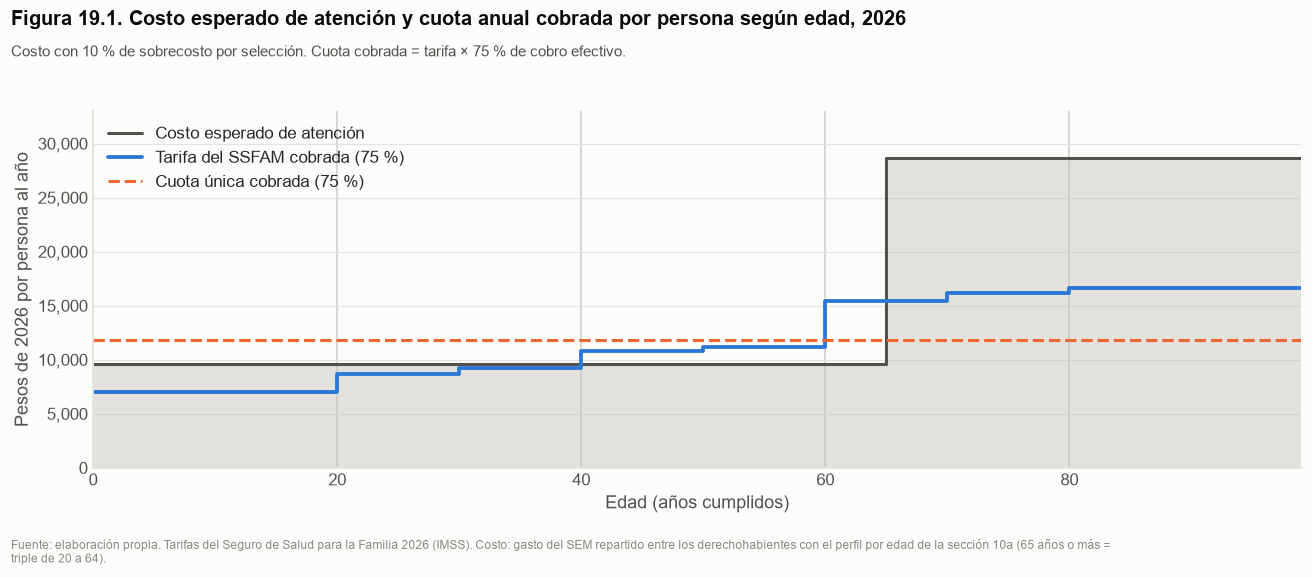

Lectura: La tarifa del SSFAM cobrada no cubre el costo esperado de atención desde la primera edad. La cuota única
         cobrada es de 11,782 pesos por persona al año.


In [151]:
# ===== VIZ 19.2a | Pegar debajo de la celda 19.2 (cuota única y resultados por experimento) =====
# ---------------- Figura 19.1 Costo esperado de atención y cuota cobrada por edad ----------------
edades_fig = np.arange(0, 100)
costo_edad = COSTO_REFERENCIA * peso_costo(edades_fig) * (1 + SOBRECOSTO) * factor_costo(2026)
cuota_ssfam_cobrada = cuota_por_edad(edades_fig, "Cuota por edad (SSFAM)") * COBRO
cuota_unica_cobrada = np.full(len(edades_fig), CUOTA_UNICA * COBRO)
fig, eje = plt.subplots(figsize=(12, 5.2))
eje.fill_between(edades_fig, 0, costo_edad, step="post", color=NEUTRO, alpha=0.45, linewidth=0)
eje.step(edades_fig, costo_edad, where="post", color=TINTA_2, linewidth=2, label="Costo esperado de atención")
eje.step(edades_fig, cuota_ssfam_cobrada, where="post", color=PAL["azul"], linewidth=2.5, label="Tarifa del SSFAM cobrada (75 %)")
eje.step(edades_fig, cuota_unica_cobrada, where="post", color=PAL["naranja"], linewidth=2, linestyle="--", label="Cuota única cobrada (75 %)")
eje.set_xlabel("Edad (años cumplidos)")
eje.set_ylabel(EJE_PESOS_PERSONA)
eje.set_xlim(0, 99)
eje.set_ylim(0, max(costo_edad.max(), np.nanmax(cuota_ssfam_cobrada)) * 1.15)
ejes_limpios(eje); miles(eje)
eje.legend(loc="upper left")
tope = titulo(fig, "Figura 19.1. Costo esperado de atención y cuota anual cobrada por persona según edad, 2026",
              "Costo con 10 % de sobrecosto por selección. Cuota cobrada = tarifa × 75 % de cobro efectivo.")
fuente(fig, "Fuente: elaboración propia. Tarifas del Seguro de Salud para la Familia 2026 (IMSS). Costo: gasto del SEM repartido entre "
            "los derechohabientes con el perfil por edad de la sección 10a (65 años o más = triple de 20 a 64).")
plt.tight_layout(rect=[0, 0.07, 1, tope])
guardar_grafica("19_1_tarifa_vs_costo_por_edad")
plt.show()
no_cubre = edades_fig[cuota_ssfam_cobrada < costo_edad]
lectura((f"La tarifa del SSFAM cobrada cubre el costo esperado de atención hasta los {no_cubre.min() - 1} años; a partir de los "
         f"{no_cubre.min()} años el costo la supera." if len(no_cubre) > 0 and no_cubre.min() > 0 else
         "La tarifa del SSFAM cobrada no cubre el costo esperado de atención desde la primera edad." if len(no_cubre) > 0 else
         "La tarifa del SSFAM cobrada cubre el costo esperado de atención en todas las edades.") +
        f" La cuota única cobrada es de {CUOTA_UNICA * COBRO:,.0f} pesos por persona al año.")

Gráfica guardada: graficas/reporte\19_2_flujos_cuota_fija.png


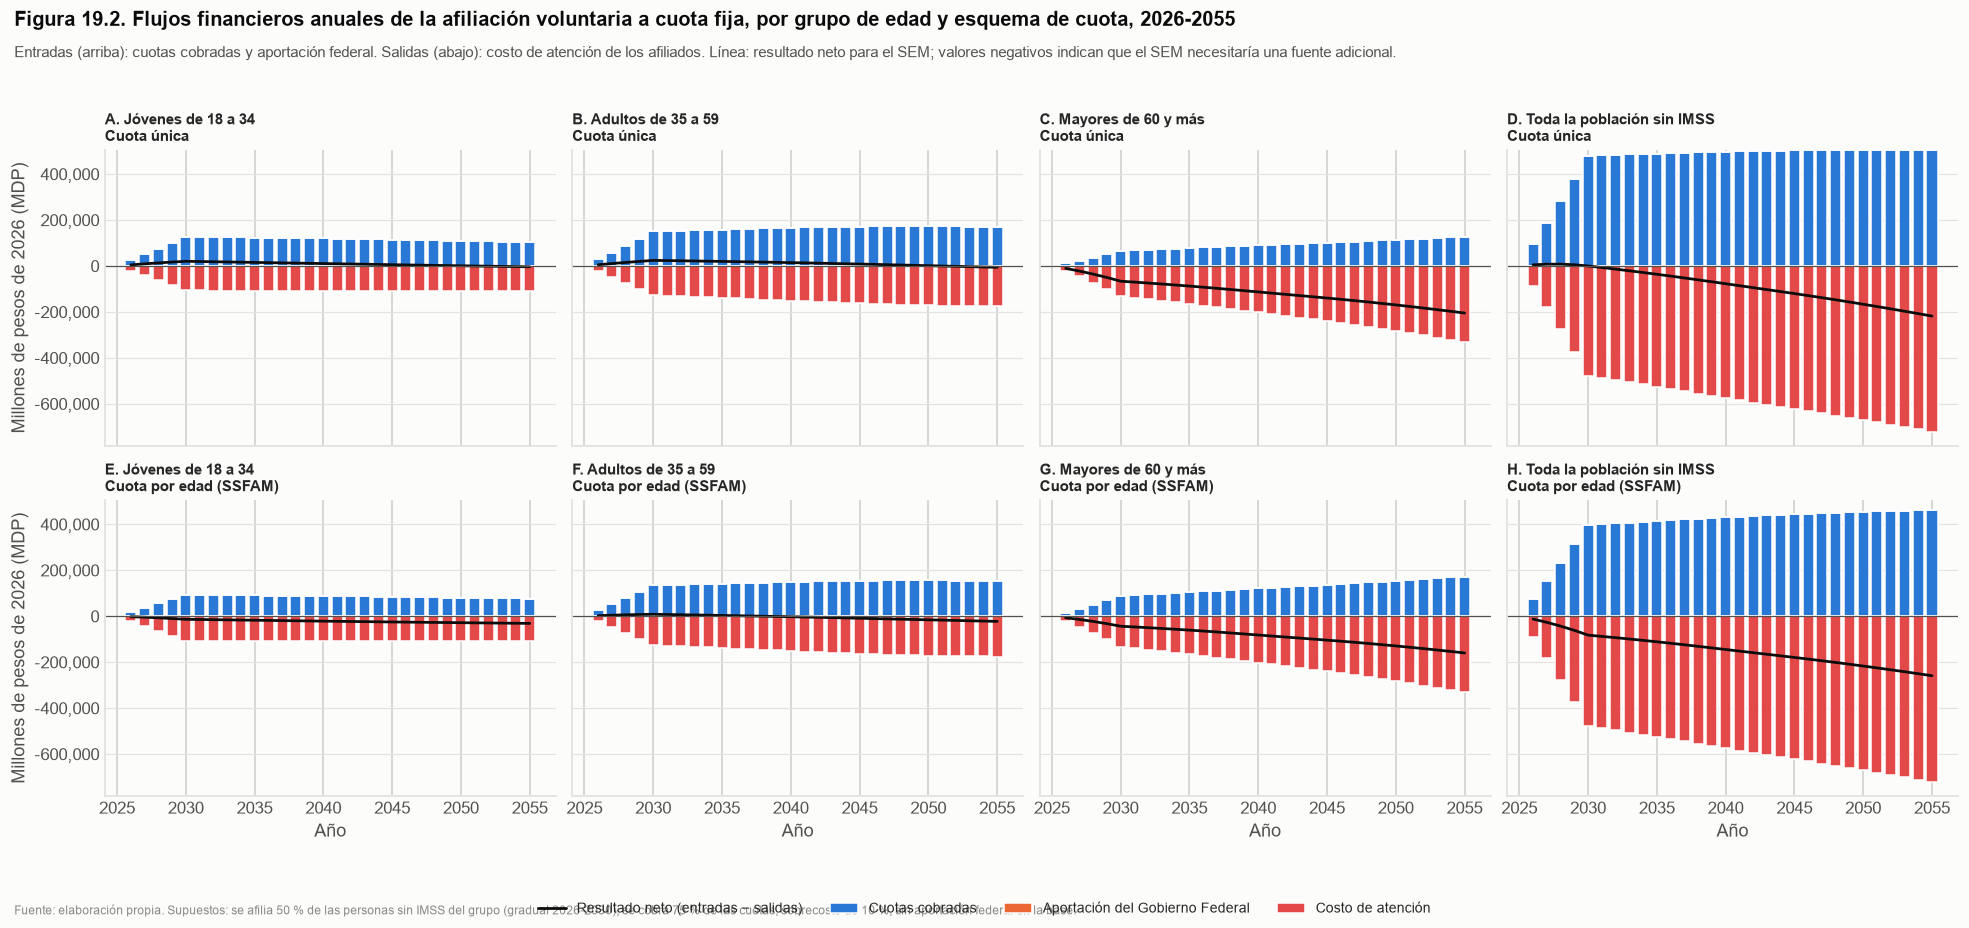

Lectura: Cuota única, 2030: resultado neto para el SEM de jóvenes de 18 a 34: +20,293 MDP; adultos de 35 a 59: +24,165
         MDP; mayores de 60 y más: -66,348 MDP; toda la población sin imss: -0 MDP. Negativo: el costo de atención
         supera lo que se cobra.
Lectura: Cuota por edad (SSFAM), 2030: resultado neto para el SEM de jóvenes de 18 a 34: -13,499 MDP; adultos de 35 a
         59: +8,358 MDP; mayores de 60 y más: -43,664 MDP; toda la población sin imss: -82,421 MDP. Negativo: el costo
         de atención supera lo que se cobra.


In [152]:
# ===== VIZ 19.2b | Pegar debajo de la VIZ 19.2a =====
# ---------------- Figura 19.2 Flujos financieros de la afiliación a cuota fija por grupo de edad ----------------
# Misma lectura que la figura de stock y flujos de la sección 14.8: entradas hacia arriba, salidas hacia abajo y la línea
# negra es el resultado neto para el SEM (entradas − salidas; positivo = el esquema deja recursos).
ENTRADAS_19 = {"cuotas cobradas": ("Cuotas cobradas", PAL["azul"]), "aportación del GF": ("Aportación del Gobierno Federal", PAL["naranja"])}
SALIDAS_19 = {"costo de atención": ("Costo de atención", FALTANTE)}


def panel_flujos(eje, datos, entradas, salidas, neto, ancho=0.8, etiqueta_neto="Resultado neto (entradas − salidas)"):
    # Barras apiladas: entradas positivas y salidas negativas; línea: resultado neto
    arriba = np.zeros(len(datos))
    for columna, (etiqueta, color) in entradas.items():
        eje.bar(datos.index, datos[columna], bottom=arriba, color=color, width=ancho, label=etiqueta)
        arriba = arriba + datos[columna].values
    abajo = np.zeros(len(datos))
    for columna, (etiqueta, color) in salidas.items():
        eje.bar(datos.index, -datos[columna], bottom=abajo, color=color, width=ancho, label=etiqueta)
        abajo = abajo - datos[columna].values
    eje.plot(datos.index, neto, color=TINTA, linewidth=1.8, label=etiqueta_neto)
    eje.axhline(0, color=TINTA_2, linewidth=0.8)
    ejes_limpios(eje); miles(eje)


experimentos_fig = list(EXPERIMENTOS_EDAD)
fig, ejes = plt.subplots(len(ESQUEMAS_19), len(experimentos_fig), figsize=(18, 4.2 * len(ESQUEMAS_19)),
                         sharex=True, sharey=True, squeeze=False)
for i, esquema in enumerate(ESQUEMAS_19):
    for j, experimento in enumerate(experimentos_fig):
        datos = resultados_19[(esquema, experimento)]
        neto = datos["cuotas cobradas"] + datos["aportación del GF"] - datos["costo de atención"]
        panel_flujos(ejes[i][j], datos, ENTRADAS_19, SALIDAS_19, neto)
        ejes[i][j].set_title(f"{'ABCDEFGH'[i * len(experimentos_fig) + j]}. {experimento}\n{esquema}", fontsize=10)
        if j == 0:
            ejes[i][j].set_ylabel(EJE_MDP)
        if i == len(ESQUEMAS_19) - 1:
            ejes[i][j].set_xlabel("Año")
fig.legend(*ejes[0][0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=9)
tope = titulo(fig, "Figura 19.2. Flujos financieros anuales de la afiliación voluntaria a cuota fija, por grupo de edad y esquema de cuota, "
                   f"{ANIOS_19[0]}-{ANIOS_19[-1]}",
              "Entradas (arriba): cuotas cobradas y aportación federal. Salidas (abajo): costo de atención de los afiliados. "
              "Línea: resultado neto para el SEM; valores negativos indican que el SEM necesitaría una fuente adicional.")
fuente(fig, "Fuente: elaboración propia. Supuestos: se afilia 50 % de las personas sin IMSS del grupo (gradual 2026-2030), se cobra 75 % "
            "de las cuotas, sobrecosto de 10 %, sin aportación federal en la base.")
plt.tight_layout(rect=[0, 0.07, 1, tope])
guardar_grafica("19_2_flujos_cuota_fija")
plt.show()
for esquema in ESQUEMAS_19:
    netos = {x: (resultados_19[(esquema, x)]["cuotas cobradas"] + resultados_19[(esquema, x)]["aportación del GF"]
                 - resultados_19[(esquema, x)]["costo de atención"]).loc[2030] for x in experimentos_fig}
    lectura(f"{esquema}, 2030: resultado neto para el SEM de " + "; ".join(f"{x.lower()}: {v:+,.0f} MDP" for x, v in netos.items()) +
            ". Negativo: el costo de atención supera lo que se cobra.")

## 19.4 Robustez y escenarios de población

In [153]:
# ---------------- 19.4 Robustez (como en 10a.5) y escenarios de población ----------------
EXPERIMENTOS_ROBUSTEZ = ["Jóvenes de 18 a 34", "Mayores de 60 y más"]
ANIO_ROBUSTEZ_19 = 2030
filas = []
for esquema, experimento in [(e, x) for e in ESQUEMAS_19 for x in EXPERIMENTOS_ROBUSTEZ]:
    casos = {
        "Supuestos base": {},
        "Afiliación 30 %": {"afiliacion": 0.30},
        "Afiliación 70 %": {"afiliacion": 0.70},
        "Cobro 50 %": {"cobro": 0.50},
        "Sin sobrecosto": {"sobrecosto": 0.0},
        "Costo +2 % real adicional": {"g_costo": 0.02},
        "Con aportación federal por familia (monto 2025)": {"aportacion_gf": APORTACION_GF_FAMILIA / PERSONAS_POR_FAMILIA},
    }
    for caso, cambios in casos.items():
        r = simular_cuota_fija(experimento, esquema, cuota_unica=CUOTA_UNICA, **cambios)
        filas.append({"esquema": esquema, "experimento": experimento, "caso": caso,
                      f"saldo {ANIO_ROBUSTEZ_19}": r.loc[ANIO_ROBUSTEZ_19, "saldo"],
                      f"saldo {ANIO_FINAL}": r.loc[ANIO_FINAL, "saldo"]})
print("Robustez (MDP de 2026; saldo positivo = el costo supera a lo que entra):")
display(pd.DataFrame(filas).set_index(["esquema", "experimento", "caso"]).round(1))

# Escenarios de la sección 14: cambia la población sin IMSS (fecundidad, longevidad y afiliación)
filas = []
for escenario in grid_escenarios["escenario"]:
    for experimento in EXPERIMENTOS_ROBUSTEZ:
        r = simular_cuota_fija(experimento, ESQUEMAS_19[-1], cuota_unica=CUOTA_UNICA, escenario=escenario)
        filas.append({"escenario": escenario, "experimento": experimento, f"saldo {ANIO_FINAL}": r.loc[ANIO_FINAL, "saldo"],
                      f"afiliados {ANIO_FINAL} (millones)": r.loc[ANIO_FINAL, "afiliados (millones)"]})
print(f"{ESQUEMAS_19[-1]} por escenario de población, {ANIO_FINAL} (MDP de 2026):")
display(pd.DataFrame(filas).pivot(index="escenario", columns="experimento").round(1))

Robustez (MDP de 2026; saldo positivo = el costo supera a lo que entra):


saldo 2030  \
esquema                experimento         caso                                                          
Cuota única            Jóvenes de 18 a 34  Supuestos base                                     -20293.1   
                                           Afiliación 30 %                                    -12175.9   
                                           Afiliación 70 %                                    -28410.3   
                                           Cobro 50 %                                          21749.5   
                                           Sin sobrecosto                                     -29914.4   
                                           Costo +2 % real adicional                           -9277.8   
                                           Con aportación federal por familia (monto 2025)    -42903.8   
                       Mayores de 60 y más Supuestos base                                      66347.6   
                                           Afiliación 30 %                                     39808.6   
                                           Afiliación 70 %                                     92886.6   
                                           Cobro 50 %                                          88343.9   
                                           Sin sobrecosto                                      54317.0   
                                           Costo +2 % real adicional                           80121.3   
                                           Con aportación federal por familia (monto 2025)     54517.9   
Cuota por edad (SSFAM) Jóvenes de 18 a 34  Supuestos base                                      13498.6   
                                           Afiliación 30 %                                      8099.2   
                                           Afiliación 70 %                                     18898.1   
                                           Cobro 50 %                                          44277.3   
                                           Sin sobrecosto                                       3877.3   
                                           Costo +2 % real adicional                           24514.0   
                                           Con aportación federal por familia (monto 2025)     -9112.1   
                       Mayores de 60 y más Supuestos base                                      43664.4   
                                           Afiliación 30 %                                     26198.6   
                                           Afiliación 70 %                                     61130.2   
                                           Cobro 50 %                                          73221.8   
                                           Sin sobrecosto                                      31633.8   
                                           Costo +2 % real adicional                           57438.1   
                                           Con aportación federal por familia (monto 2025)     31834.7   

                                                                                            saldo 2055  
esquema                experimento         caso                                                         
Cuota única            Jóvenes de 18 a 34  Supuestos base                                       3650.2  
                                           Afiliación 30 %                                      2190.1  
                                           Afiliación 70 %                                      5110.3  
                                           Cobro 50 %                                          38271.4  
                                           Sin sobrecosto                                      -6123.8  
                                           Costo +2 % real adicional                           90882.8  
                                           Con aportación federal por f

Cuota por edad (SSFAM) por escenario de población, 2055 (MDP de 2026):


saldo 2055                     afiliados 2055 (millones)  \
experimento Jóvenes de 18 a 34 Mayores de 60 y más        Jóvenes de 18 a 34   
escenario                                                                      
E0                     31250.3            159958.0                       8.8   
E1                     33218.9            159958.0                       9.3   
E2                     30347.1            159958.0                       8.5   
E3                     29137.8            159958.0                       8.1   
E4                     31250.3            151960.1                       8.8   
E5                     28547.7            151960.1                       8.1   
E6                     27419.0            151960.1                       7.7   
E7                     27313.0            167955.9                       7.8   
E8                     24949.0            167955.9                       7.1   
E9                     23981.6            167955.9                       6.8   

                                 
experimento Mayores de 60 y más  
escenario                        
E0                         10.8  
E1                         10.8  
E2                         10.8  
E3                         10.8  
E4                         10.2  
E5                         10.2  
E6                         10.2  
E7                         11.3  
E8                         11.3  
E9                         11.3

Gráfica guardada: graficas/reporte\19_3_sensibilidad_cuota_fija.png


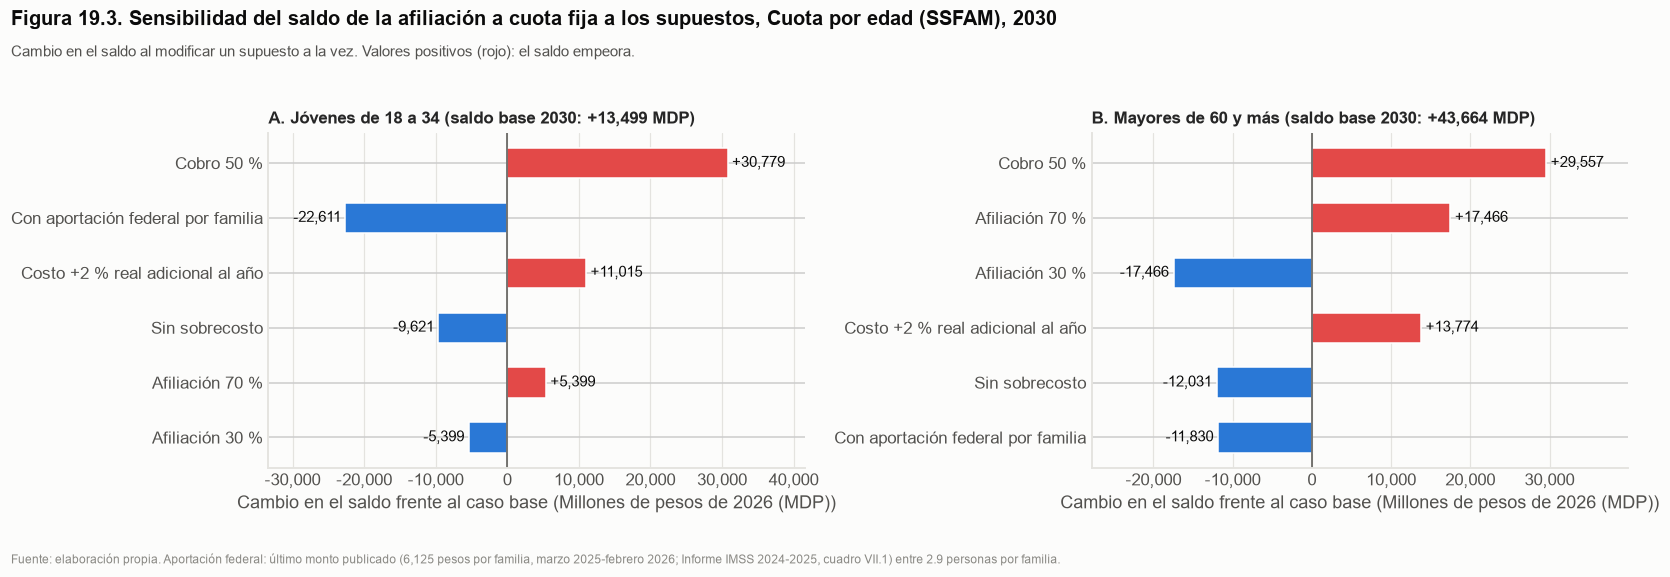

Lectura: El supuesto que más mueve el saldo es «Cobro 50 %» para jóvenes de 18 a 34; «Cobro 50 %» para mayores de 60 y
         más.


In [154]:
# ===== VIZ 19.4 | Pegar debajo de la celda 19.4 (robustez y escenarios) =====
# ---------------- Figura 19.3 Sensibilidad del saldo a los supuestos ----------------
CASOS_FIG = {"Afiliación 30 %": {"afiliacion": 0.30}, "Afiliación 70 %": {"afiliacion": 0.70},
             "Cobro 50 %": {"cobro": 0.50}, "Sin sobrecosto": {"sobrecosto": 0.0},
             "Costo +2 % real adicional al año": {"g_costo": 0.02},
             "Con aportación federal por familia": {"aportacion_gf": APORTACION_GF_FAMILIA / PERSONAS_POR_FAMILIA}}
ESQUEMA_FIG = ESQUEMAS_19[-1]
ANIO_FIG = 2030
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.2))
mayor_cambio = {}
for k, (eje, experimento) in enumerate(zip(ejes, ["Jóvenes de 18 a 34", "Mayores de 60 y más"])):
    base = simular_cuota_fija(experimento, ESQUEMA_FIG, cuota_unica=CUOTA_UNICA).loc[ANIO_FIG, "saldo"]
    cambios = pd.Series({caso: simular_cuota_fija(experimento, ESQUEMA_FIG, cuota_unica=CUOTA_UNICA, **kw).loc[ANIO_FIG, "saldo"] - base
                         for caso, kw in CASOS_FIG.items()}).sort_values(key=abs)
    mayor_cambio[experimento] = cambios.index[-1]
    eje.barh(cambios.index, cambios.values, color=[FALTANTE if v > 0 else A_FAVOR for v in cambios], height=0.55)
    for i, v in enumerate(cambios.values):
        eje.text(v + (abs(cambios).max() * 0.02 if v >= 0 else -abs(cambios).max() * 0.02), i, f"{v:+,.0f}", va="center",
                 ha="left" if v >= 0 else "right", color=TINTA)
    eje.axvline(0, color=TINTA_2, linewidth=1)
    margen = max(abs(cambios.values).max(), 1) * 0.35
    eje.set_xlim(min(cambios.min(), 0) - margen, max(cambios.max(), 0) + margen)
    eje.set_title(f"{'AB'[k]}. {experimento} (saldo base {ANIO_FIG}: {base:+,.0f} MDP)")
    eje.set_xlabel(f"Cambio en el saldo frente al caso base ({EJE_MDP})")
    ejes_limpios(eje, "x"); miles(eje, "x")
tope = titulo(fig, f"Figura 19.3. Sensibilidad del saldo de la afiliación a cuota fija a los supuestos, {ESQUEMA_FIG}, {ANIO_FIG}",
              "Cambio en el saldo al modificar un supuesto a la vez. Valores positivos (rojo): el saldo empeora.")
fuente(fig, "Fuente: elaboración propia. Aportación federal: último monto publicado (6,125 pesos por familia, marzo 2025-febrero 2026; "
            "Informe IMSS 2024-2025, cuadro VII.1) entre 2.9 personas por familia.")
plt.tight_layout(rect=[0, 0.07, 1, tope])
guardar_grafica("19_3_sensibilidad_cuota_fija")
plt.show()
lectura("El supuesto que más mueve el saldo es " + "; ".join(f"«{c}» para {e.lower()}" for e, c in mayor_cambio.items()) + ".")

## 19.5 Asequibilidad de la tarifa del SSFAM

In [155]:
# ---------------- 19.5 ¿Pueden pagar la tarifa del SSFAM las personas sin IMSS? ----------------
# Tarifa anual por persona / ingreso monetario del hogar por persona (19.0b), para las personas sin IMSS de cada grupo.
# Referencia: la meta 3.8.2 de los ODS considera excesivo un gasto en salud mayor a 10 % del gasto o ingreso del hogar.
UMBRALES_ASEQUIBILIDAD = [0.10, 0.25]
sin_imss = personas_enigh.loc[personas_enigh["dh_imss"] == 0].copy()
sin_imss["tarifa_ssfam"] = cuota_por_edad(sin_imss["edad"].values, "Cuota por edad (SSFAM)")
sin_imss["tarifa_pct_ingreso"] = np.where(sin_imss["ingreso_hogar_pc_2026"] > 0,
                                          sin_imss["tarifa_ssfam"] / sin_imss["ingreso_hogar_pc_2026"], 10.0)   # sin ingreso: 1,000 %
filas = []
for (inicio, fin), tarifa in CUOTA_SSFAM_POR_EDAD.items():
    grupo = sin_imss.loc[(sin_imss["edad"] >= inicio) & (sin_imss["edad"] < fin)]
    fila = {"grupo de edad": f"{inicio}-{fin - 1}" if fin < 200 else f"{inicio} y más",
            "personas sin IMSS (millones)": grupo["factor"].sum() / 1e6, "tarifa anual": tarifa,
            "tarifa / ingreso por persona, mediana (%)": percentil_ponderado_19(grupo["tarifa_pct_ingreso"], grupo["factor"], 50) * 100}
    for umbral in UMBRALES_ASEQUIBILIDAD:
        fila[f"% para quienes la tarifa supera {umbral:.0%} de su ingreso"] = (
            grupo.loc[grupo["tarifa_pct_ingreso"] > umbral, "factor"].sum() / grupo["factor"].sum() * 100)
    filas.append(fila)
asequibilidad_ssfam = pd.DataFrame(filas).set_index("grupo de edad")
print("Asequibilidad de la tarifa del SSFAM 2026 para las personas sin IMSS (ingreso monetario del hogar por persona):")
display(asequibilidad_ssfam.round(1))


Asequibilidad de la tarifa del SSFAM 2026 para las personas sin IMSS (ingreso monetario del hogar por persona):


,personas sin IMSS (millones),tarifa anual,"tarifa / ingreso por persona, mediana (%)",% para quienes la tarifa supera 10% de su ingreso,% para quienes la tarifa supera 25% de su ingreso
grupo de edad,,,,,
0-19,25.2,9300.0,24.0,89.1,47.6
20-29,11.2,11550.0,22.1,85.1,42.8
30-39,10.7,12350.0,25.7,86.4,51.4
40-49,10.1,14350.0,27.9,90.6,56.3
50-59,9.0,14850.0,25.8,88.5,51.7
60-69,6.0,20600.0,38.7,92.6,68.6
70-79,3.0,21500.0,51.8,94.1,76.8
80 y más,1.6,22150.0,61.3,96.4,82.1


Gráfica guardada: graficas/reporte\19_4_asequibilidad_ssfam.png


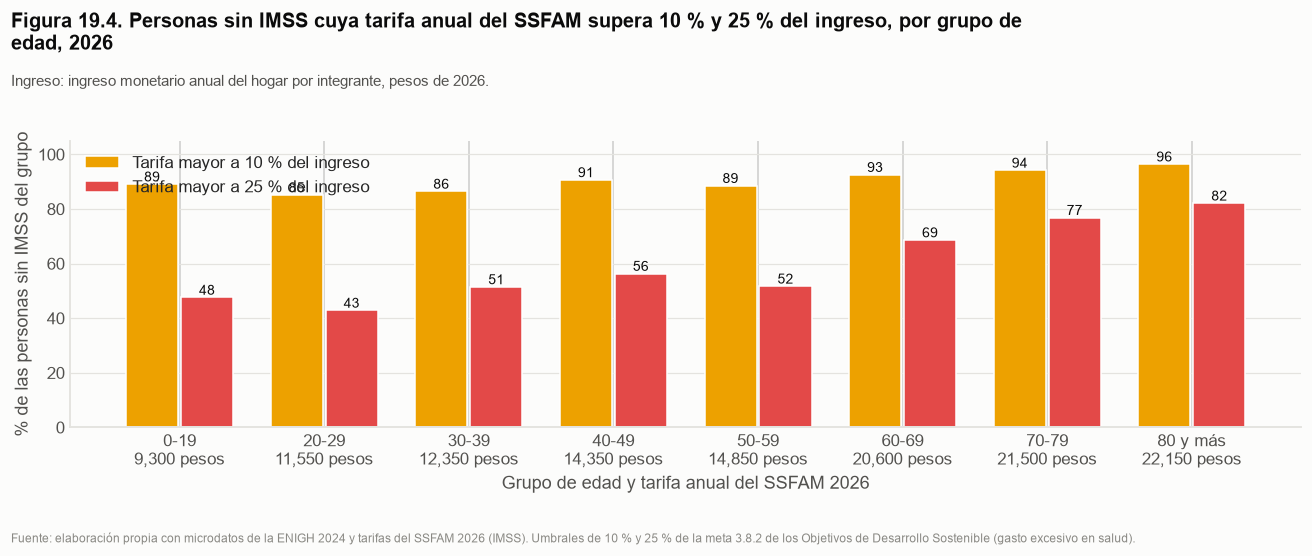

Lectura: Para las personas sin IMSS de 60 años o más, la tarifa supera 25 % de su ingreso en promedio en 76 % de los
         casos; para las de 20 a 39 años, en 47 %.


In [156]:
# ===== VIZ 19.5 | Pegar debajo de la celda 19.5 (asequibilidad de la tarifa del SSFAM) =====
# ---------------- Figura 19.4 Asequibilidad de la tarifa del SSFAM ----------------
col10 = [c for c in asequibilidad_ssfam.columns if "10%" in c][0]
col25 = [c for c in asequibilidad_ssfam.columns if "25%" in c][0]
fig, eje = plt.subplots(figsize=(12, 5))
x = np.arange(len(asequibilidad_ssfam))
eje.bar(x - 0.19, asequibilidad_ssfam[col10], 0.36, color=PAL["amarillo"], label="Tarifa mayor a 10 % del ingreso")
eje.bar(x + 0.19, asequibilidad_ssfam[col25], 0.36, color=FALTANTE, label="Tarifa mayor a 25 % del ingreso")
for i, (a, b) in enumerate(zip(asequibilidad_ssfam[col10], asequibilidad_ssfam[col25])):
    eje.text(i - 0.19, a + 1, f"{a:.0f}", ha="center", fontsize=9, color=TINTA)
    eje.text(i + 0.19, b + 1, f"{b:.0f}", ha="center", fontsize=9, color=TINTA)
eje.set_xticks(x, [f"{g}\n{t:,.0f} pesos" for g, t in zip(asequibilidad_ssfam.index, asequibilidad_ssfam["tarifa anual"])])
eje.set_ylabel("% de las personas sin IMSS del grupo")
eje.set_xlabel("Grupo de edad y tarifa anual del SSFAM 2026")
eje.set_ylim(0, 105)
ejes_limpios(eje)
eje.legend(loc="upper left")
tope = titulo(fig, "Figura 19.4. Personas sin IMSS cuya tarifa anual del SSFAM supera 10 % y 25 % del ingreso, por grupo de edad, 2026",
              "Ingreso: ingreso monetario anual del hogar por integrante, pesos de 2026.")
fuente(fig, "Fuente: elaboración propia con microdatos de la ENIGH 2024 y tarifas del SSFAM 2026 (IMSS). Umbrales de 10 % y 25 % de "
            "la meta 3.8.2 de los Objetivos de Desarrollo Sostenible (gasto excesivo en salud).")
plt.tight_layout(rect=[0, 0.07, 1, tope])
guardar_grafica("19_4_asequibilidad_ssfam")
plt.show()
grupos_mayores = [g for g in asequibilidad_ssfam.index if g.startswith(("60", "70", "80"))]
grupos_jovenes = [g for g in asequibilidad_ssfam.index if g.startswith(("20", "30"))]
lectura(f"Para las personas sin IMSS de 60 años o más, la tarifa supera 25 % de su ingreso en promedio en "
        f"{asequibilidad_ssfam.loc[grupos_mayores, col25].mean():.0f} % de los casos; para las de 20 a 39 años, en "
        f"{asequibilidad_ssfam.loc[grupos_jovenes, col25].mean():.0f} %.")

**Lectura.** Con una cuota igual para todos, afiliar jóvenes deja saldo a favor del SEM y afiliar personas mayores deja un faltante, porque cuestan el triple. Una cuota por edad, como la del SSFAM, acerca la cuota al costo de cada grupo, pero traslada el problema a la asequibilidad (19.5). El saldo de toda la población crece con los años aunque la cuota esté calibrada en 2030, porque la población sin IMSS envejece. No incluye capacidad de atención ni efectos sobre la formalidad (mismas salvedades que 10a.6).

# 20. Sección 10a del documento: afiliación subsidiada, conciliada con este cuaderno

Reproduce el ejercicio de Héctor con los objetos de este cuaderno: **hogares e ingresos** de la ENIGH (19.0b: ingreso laboral = subordinado + negocios propios), **derechohabientes** CONAPO × ENIGH (13.4), **gasto del SEM y costo por edad** de la sección 19 y **salario real** del cuaderno de ingresos. Mismo juego de supuestos que la sección 19 (Tabla 10.1).

**Insumos clave**

* **Ingreso:** pago del hogar = 3.467 % del ingreso laboral anual del titular (microdatos de la ENIGH 2024, `ingresos.csv`: claves de trabajo subordinado de 13.2 + negocios propios P068-P081; 19.0b), en pesos de 2026 y creciendo con el salario real, × 75 % de cobro; aportación fija del Gobierno Federal = 14.83 % de la UMA diaria × 365 por titular; subsidio del Gobierno Federal (100 % del pago hasta el percentil 20 del ingreso del titular, cero desde el percentil 50). Para expresar el saldo: proyección institucional de ingresos del IMSS por seguro y concepto, 2024-2055 (documento interno del área de Finanzas; base `db_nucleo_13.hec_ingreso_imss`), procesada en el cuaderno de ingresos; ingresos del SEM = SEM-A + SEM-GMP (cuotas obrero-patronales, aportación del Gobierno Federal y otros ingresos), `finanzas["ingresos_SEM"]` (Tabla 5 del documento), MDP de 2026; y masa salarial = ingresos de GMP / 1.5 % (LSS art. 25).
* **Gasto:** costo de atención por persona (el mismo de la sección 19) = gasto corriente en salud del IMSS (archivo interno `CENTRO DE COSTOS DE QUIROFANO 2020-2026 021026.xlsx`, pestaña `gasto_corrientes_saludIMSS`), deflactado a pesos de 2026 con el Simulador Fiscal del CIEP (`deflator2027.xlsx`); 2025 × `PCT_GASTO_SEM` (18.1b, base 100 %). Se reparte entre los derechohabientes de 2025 con el perfil por edad de la Tabla 10.1 (65 años o más = triple de 20 a 64) y crece con el salario real (`g_SBC_real`, hoja Resumen_tasas del cuaderno de ingresos, que viene de `db_nucleo_13.hec_crecimiento_sbc`); × personas cubiertas × 1.10 de sobrecosto.
* **Población:** hogares de la ENIGH 2024 con al menos un integrante que trabaja y no tiene IMSS (`poblacion.csv`, `trabajos.csv`; 19.0b), reponderados para reproducir CONAPO por rango de edad y sexo (los derechohabientes reponderados son los de 13.4). Se afilia 50 % de los hogares elegibles.

In [157]:
# =====================================================================================================
# 20. Sección 10a del documento: afiliación subsidiada, conciliada con este cuaderno
# =====================================================================================================
# ---------------- Parámetros de la Tabla 10.1 y del texto de la sección 10a ----------------
TASA_PROPORCIONAL = 0.03467          # cuota proporcional al ingreso (10a.2)
PCT_UMA_PATRON = 0.2040              # cuota fija patronal vigente: 20.40 % de la UMA diaria (10a.1)
SALARIO_MINIMO_2026 = 315.04         # reproduce 10a.1: la cuota fija es 7.6 % del salario mínimo. Confirmar con la CONASAMI
DIAS_HOGAR = 365                     # días al año para el pago del hogar (reproduce el ejemplo de 10a.2)
DIAS_COTIZADOS = 337                 # días cotizados (Informe del IMSS, Cuadro II.18), para formales y masa salarial

# AFILIACION (50 %), COBRO (75 %), SOBRECOSTO (10 %), G_COSTO_REAL, PESOS_COSTO_EDAD, PCT_UMA_GF y UMA_DIARIA_2026
# son los mismos de la Tabla 10.1 y ya están en 19.0: un solo juego de supuestos para las secciones 19 a 22.
PERCENTIL_SUBSIDIO_TOTAL = 20        # el subsidio cubre todo el pago hasta este percentil del ingreso del titular
PERCENTIL_SUBSIDIO_CERO = 50         # y baja en línea recta hasta desaparecer en este percentil

# Costo de atención: el gasto del SEM de 19.0 repartido entre los derechohabientes de 13.4 con el perfil por edad.
# Es el mismo costo por persona de la sección 19 (COSTO_REFERENCIA, 19.1) y crece igual (factor_costo, 19.0).
# Ingreso del titular: ingreso laboral = subordinado + negocios propios (INCLUIR_CUENTA_PROPIA = False: solo subordinado).
INCLUIR_CUENTA_PROPIA = True
GASTO_ATENCION_BASE = GASTO_SEM_BASE


ANIOS_10A = [2026, 2030, 2040, 2054]
dh_total_base = conapo.loc[conapo["anio"] == ANIO_BASE, "derechohabientes"].sum() / 1e6

# Índice de salario real (indice_salario), deflactor y factor_ingreso_2026: vienen de 19.0

# ---------------- Masa salarial de los cotizantes (SBC con tope de 25 UMA), MDP de 2026 ----------------
# Es la suma de los salarios sobre los que se pagan cuotas. Se obtiene de la proyección institucional de ingresos
# (cuaderno de ingresos, hoja Ingresos_niveles): las cuotas de GMP (cuotas obrero-patronales + aportación federal del
# SEM-GMP) son 1.5 % del SBC (LSS art. 25: 1.05 % patrón, 0.375 % trabajador y 0.075 % Gobierno Federal).
# Masa salarial = cuotas de GMP / 1.5 %. Así la masa sigue la misma proyección que los ingresos de la Tabla 5.
TASA_GMP_LEGAL = 0.015
niveles_ingreso = pd.read_excel(ARCHIVO_RESULTADOS_IMSS, sheet_name="Ingresos_niveles")
niveles_ingreso = niveles_ingreso.set_index(niveles_ingreso.columns[0])
masa_salarial = niveles_ingreso["SEM-GMP"] / TASA_GMP_LEGAL
MASA_SALARIAL_2026 = masa_salarial.loc[2026]
print(f"Masa salarial 2026: {MASA_SALARIAL_2026:,.0f} MDP de 2026")

print(f"Factor para pasar el ingreso de la ENIGH 2024 a pesos de 2026: {factor_ingreso_2026:.4f}")
print("Índice de salario real (2026 = 1):", indice_salario.loc[ANIOS_10A].round(3).to_dict())

Masa salarial 2026: 5,515,041 MDP de 2026
Factor para pasar el ingreso de la ENIGH 2024 a pesos de 2026: 1.0775
Índice de salario real (2026 = 1): {2026: 1.0, 2030: 1.034, 2040: 1.124, 2054: 1.265}


## 20.1 Hogares elegibles y titulares

In [158]:
# ---------------- 20.1 Hogares elegibles y titulares (variables de la ENIGH de 19.0b) ----------------
# Elegible: hogar con al menos un integrante que trabaja y no tiene IMSS (subordinado o, si INCLUIR_CUENTA_PROPIA,
# también por su cuenta). Personas cubiertas: los integrantes del hogar sin IMSS (los que tienen IMSS ya están cubiertos).
# Titular: el integrante que trabaja sin IMSS con el mayor ingreso laboral.
# Columna de ingreso que se usa: laboral (subordinado + negocios propios) o solo subordinado
COLUMNA_INGRESO_10A = "ing_laboral_mensual" if INCLUIR_CUENTA_PROPIA else "ing_sub_mensual"
TRABAJA_SIN_IMSS = "trabaja_sin_imss" if INCLUIR_CUENTA_PROPIA else "subordinado_sin_imss"

personas = personas_enigh.copy()
personas["subordinado_sin_imss"] = ((personas["es_subordinado"] == 1) & (personas["dh_imss"] == 0)).astype(int)
personas["ingreso_titular_candidato"] = personas[COLUMNA_INGRESO_10A].where(personas[TRABAJA_SIN_IMSS] == 1, 0.0)

# Un renglón por hogar: elegible si al menos un integrante trabaja sin IMSS; titular = el de mayor ingreso laboral
hogares = personas.groupby(LLAVE_HOGAR).agg(
    factor=("factor", "first"),
    elegible=(TRABAJA_SIN_IMSS, "max"),
    ingreso_titular_mensual=("ingreso_titular_candidato", "max"),
    ingreso_laboral_hogar_mensual=(COLUMNA_INGRESO_10A, "sum"),
).reset_index()

personas = personas.merge(hogares[LLAVE_HOGAR + ["elegible"]], on=LLAVE_HOGAR, how="left")
personas["cubierta"] = ((personas["elegible"] == 1) & (personas["dh_imss"] == 0)).astype(int)

# Ingreso anual del titular en pesos de 2026 (año ANIO_INICIO_10A)
hogares["ingreso_titular_2026"] = hogares["ingreso_titular_mensual"] * 12 * factor_ingreso_2026
hogares["ingreso_hogar_2026"] = hogares["ingreso_laboral_hogar_mensual"] * 12 * factor_ingreso_2026

# Reponderación a CONAPO: factor × CONAPO(año, rango, sexo) / población ENIGH(rango, sexo).
# Así los derechohabientes de la ENIGH reponderada son exactamente los de la sección 13.4.
poblacion_enigh = personas.groupby(["grupo_edad", "sexo"], observed=False)["factor"].sum().rename("pob_enigh")


def pesos_conapo(anio):
    pob_anio = pob_conapo.loc[pob_conapo["anio"] == anio].set_index(["grupo_edad", "sexo"])["poblacion"]
    razon = (pob_anio / poblacion_enigh).replace([np.inf, -np.inf], np.nan).rename("razon")   # rangos sin ENIGH: 0
    tabla = personas[["grupo_edad", "sexo"]].merge(razon.reset_index(), on=["grupo_edad", "sexo"], how="left")
    return personas["factor"].values * tabla["razon"].fillna(0).values


# Verificación: derechohabientes reponderados = derechohabientes de 13.4 en ANIO_BASE
dh_reponderados = (pesos_conapo(ANIO_BASE) * personas["dh_imss"].values).sum() / 1e6
print(f"Derechohabientes {ANIO_BASE}: reponderados {dh_reponderados:,.2f} millones | sección 13.4 "
      f"{conapo.loc[conapo['anio'] == ANIO_BASE, 'derechohabientes'].sum() / 1e6:,.2f} millones")

elegibles = hogares["elegible"] == 1
print(f"ENIGH 2024 (factor de expansión): {hogares.loc[elegibles, 'factor'].sum() / 1e6:,.1f} millones de hogares elegibles; "
      f"{(personas['factor'] * personas['cubierta']).sum() / 1e6:,.1f} millones de personas sin IMSS en ellos; "
      f"{(personas['factor'] * (personas['elegible'] == 1)).sum() / 1e6:,.1f} millones de personas en total en esos hogares")

# Umbrales del subsidio: percentiles del ingreso del titular entre los hogares elegibles (ponderados), en 2026
def percentil_ponderado(valores, pesos, p):
    orden = np.argsort(valores)
    valores, pesos = np.asarray(valores)[orden], np.asarray(pesos)[orden]
    acumulado = np.cumsum(pesos) / pesos.sum()
    return np.interp(p / 100, acumulado, valores)


ingreso_elegibles = hogares.loc[elegibles, "ingreso_titular_2026"]
factor_elegibles = hogares.loc[elegibles, "factor"]
UMBRAL_SUBSIDIO_TOTAL = percentil_ponderado(ingreso_elegibles, factor_elegibles, PERCENTIL_SUBSIDIO_TOTAL)
UMBRAL_SUBSIDIO_CERO = percentil_ponderado(ingreso_elegibles, factor_elegibles, PERCENTIL_SUBSIDIO_CERO)
mediana_uma = UMBRAL_SUBSIDIO_CERO / DIAS_HOGAR / UMA_DIARIA_2026 if PERCENTIL_SUBSIDIO_CERO == 50 else np.nan
print(f"Umbrales del subsidio (pesos de 2026 al año): P{PERCENTIL_SUBSIDIO_TOTAL} = {UMBRAL_SUBSIDIO_TOTAL:,.0f}; "
      f"P{PERCENTIL_SUBSIDIO_CERO} = {UMBRAL_SUBSIDIO_CERO:,.0f} ({mediana_uma:.2f} UMA al día)")

Derechohabientes 2025: reponderados 54.65 millones | sección 13.4 54.65 millones
ENIGH 2024 (factor de expansión): 22.3 millones de hogares elegibles; 67.8 millones de personas sin IMSS en ellos; 82.8 millones de personas en total en esos hogares
Umbrales del subsidio (pesos de 2026 al año): P20 = 43,851; P50 = 101,195 (2.36 UMA al día)


## 20.2 Función del ejercicio

In [159]:
# ---------------- 20.2 Costo de atención por persona y función del ejercicio ----------------
# peso_costo, COSTO_REFERENCIA y COSTO_PROMEDIO_DH vienen de 19.1 (gasto del SEM con el perfil por edad de Héctor)
print(f"Costo por derechohabiente (promedio): {COSTO_PROMEDIO_DH:,.0f} pesos de 2026 | tramo de peso 1: {COSTO_REFERENCIA:,.0f}")


def fraccion_subsidio(ingreso, indice):
    # 1 hasta el umbral bajo, 0 desde el umbral alto, en línea recta entre ambos (umbrales crecen con el salario real)
    bajo, alto = UMBRAL_SUBSIDIO_TOTAL * indice, UMBRAL_SUBSIDIO_CERO * indice
    return np.clip((alto - ingreso) / (alto - bajo), 0, 1)


def simular_10a(anio, afiliacion=AFILIACION, cobro=COBRO, sobrecosto=SOBRECOSTO, g_costo=G_COSTO_REAL,
                costo_referencia=None):
    costo_referencia = COSTO_REFERENCIA if costo_referencia is None else costo_referencia
    indice = indice_salario.loc[anio]
    peso_persona = pesos_conapo(anio)
    # Peso del hogar: factor × razón promedio de sus integrantes
    pesos_integrantes = personas[LLAVE_HOGAR].assign(peso=peso_persona, factor=personas["factor"].values)
    razon_hogar = pesos_integrantes.groupby(LLAVE_HOGAR)[["peso", "factor"]].sum()
    razon_hogar = (razon_hogar["peso"] / razon_hogar["factor"]).rename("razon").reset_index()
    hog = hogares.loc[elegibles].merge(razon_hogar, on=LLAVE_HOGAR, how="left")
    hog["peso"] = hog["factor"] * hog["razon"] * afiliacion

    ingreso = hog["ingreso_titular_2026"] * indice
    cuota = TASA_PROPORCIONAL * ingreso
    subsidio = cuota * fraccion_subsidio(ingreso, indice)
    pago_hogar = cuota - subsidio
    aportacion_gf = PCT_UMA_GF * UMA_DIARIA_2026 * DIAS_HOGAR

    cubiertas = personas["cubierta"].values == 1
    costo_persona = costo_referencia * peso_costo(personas["edad"].values) * factor_costo(anio, g_costo)
    costo = (peso_persona * cubiertas * costo_persona).sum() * afiliacion * (1 + sobrecosto)

    r = {
        "personas cubiertas (millones)": (peso_persona * cubiertas).sum() * afiliacion / 1e6,
        "titulares (millones)": hog["peso"].sum() / 1e6,
        "pago debido de los hogares": (pago_hogar * hog["peso"]).sum() / 1e6,
        "pago cobrado de los hogares": (pago_hogar * hog["peso"]).sum() * cobro / 1e6,
        "aportación fija del GF": aportacion_gf * hog["peso"].sum() / 1e6,
        "subsidio del GF": (subsidio * hog["peso"]).sum() / 1e6,
        "costo de atención": costo / 1e6,
    }
    r["saldo sin fuente asignada"] = (r["costo de atención"] - r["pago cobrado de los hogares"]
                                      - r["aportación fija del GF"] - r["subsidio del GF"])
    if anio in finanzas.index:
        r["saldo como % de los ingresos del SEM"] = r["saldo sin fuente asignada"] / finanzas.loc[anio, "ingresos_SEM"] * 100
    if MASA_SALARIAL_2026 is not None:
        masa = masa_salarial.loc[anio]
        r["saldo en puntos del salario"] = r["saldo sin fuente asignada"] / masa * 100
    dh_anio = conapo.loc[conapo["anio"] == anio]
    r["población con IMSS sin el esquema (%)"] = dh_anio["derechohabientes"].sum() / dh_anio["poblacion"].sum() * 100
    r["población con IMSS con el esquema (%)"] = ((dh_anio["derechohabientes"].sum() + r["personas cubiertas (millones)"] * 1e6)
                                                  / dh_anio["poblacion"].sum() * 100)
    return r


# Índice de la masa salarial (cotizantes del SEM × salario real, 2026 = 1), para "puntos del salario" y 10b
cotizantes_sem = poblacion_rango_sem.sum(axis=1)
indice_masa = (cotizantes_sem / cotizantes_sem.loc[ANIO_INICIO_10A]) * indice_salario.reindex(cotizantes_sem.index)

Costo por derechohabiente (promedio): 9,977 pesos de 2026 | tramo de peso 1: 8,337


## 20.3 Resultados con los supuestos base

In [160]:
# ---------------- 20.3 Resultados con los supuestos base (MDP de 2026) ----------------
resultados_10a = pd.DataFrame({anio: simular_10a(anio) for anio in ANIOS_10A})
display(resultados_10a.round(1))

,2026,2030,2040,2054
personas cubiertas (millones),35.2,35.9,37.0,36.8
titulares (millones),11.5,11.8,12.5,12.8
pago debido de los hogares,47189.7,50102.2,56757.3,63895.5
pago cobrado de los hogares,35392.3,37576.6,42568.0,47921.7
aportación fija del GF,72763.8,75071.3,79342.9,81399.2
subsidio del GF,4886.9,5228.2,6061.3,7104.6
costo de atención,378507.4,406135.7,475908.8,569397.4
saldo sin fuente asignada,265464.4,288259.6,347936.6,432972.0
saldo como % de los ingresos del SEM,48.0,47.2,41.8,35.9
saldo en puntos del salario,4.8,4.6,3.9,3.1


Gráfica guardada: graficas/reporte\20_1_flujos_afiliacion_subsidiada.png


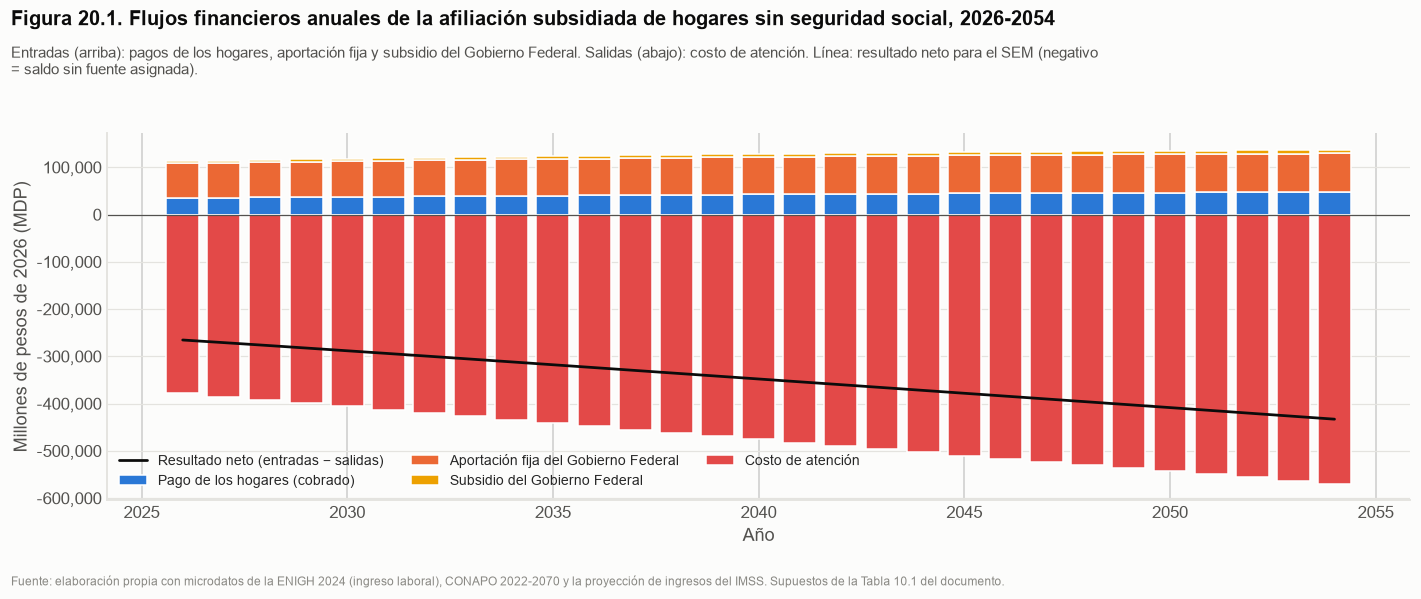

Lectura: El resultado neto para el SEM es de -288,260 MDP en 2030 y de -432,972 MDP en 2054. Las entradas cubren 29 %
         del costo de atención en 2030.


In [161]:
# ===== VIZ 20.3 | Pegar debajo de la celda 20.3 (resultados con los supuestos base) =====
# ---------------- Figura 20.1 Flujos financieros anuales de la afiliación subsidiada ----------------
ANIOS_FLUJOS_10A = list(range(ANIO_INICIO_10A, 2055))
flujos_10a = pd.DataFrame({anio: simular_10a(anio) for anio in ANIOS_FLUJOS_10A}).T
ENTRADAS_10A = {"pago cobrado de los hogares": ("Pago de los hogares (cobrado)", PAL["azul"]),
                "aportación fija del GF": ("Aportación fija del Gobierno Federal", PAL["naranja"]),
                "subsidio del GF": ("Subsidio del Gobierno Federal", PAL["amarillo"])}
SALIDAS_10A = {"costo de atención": ("Costo de atención", FALTANTE)}
neto_10a = flujos_10a[list(ENTRADAS_10A)].sum(axis=1) - flujos_10a["costo de atención"]
fig, eje = plt.subplots(figsize=(13, 5.4))
panel_flujos(eje, flujos_10a, ENTRADAS_10A, SALIDAS_10A, neto_10a)
eje.set_ylabel(EJE_MDP)
eje.set_xlabel("Año")
eje.legend(loc="lower left", ncol=3, fontsize=9)
tope = titulo(fig, f"Figura 20.1. Flujos financieros anuales de la afiliación subsidiada de hogares sin seguridad social, "
                   f"{ANIOS_FLUJOS_10A[0]}-{ANIOS_FLUJOS_10A[-1]}",
              "Entradas (arriba): pagos de los hogares, aportación fija y subsidio del Gobierno Federal. Salidas (abajo): costo de atención. "
              "Línea: resultado neto para el SEM (negativo = saldo sin fuente asignada).")
fuente(fig, "Fuente: elaboración propia con microdatos de la ENIGH 2024 (ingreso laboral), CONAPO 2022-2070 y la proyección de ingresos "
            "del IMSS. Supuestos de la Tabla 10.1 del documento.")
plt.tight_layout(rect=[0, 0.05, 1, tope])
guardar_grafica("20_1_flujos_afiliacion_subsidiada")
plt.show()
lectura(f"El resultado neto para el SEM es de {neto_10a.loc[2030]:+,.0f} MDP en 2030 y de {neto_10a.iloc[-1]:+,.0f} MDP en "
        f"{neto_10a.index[-1]}. Las entradas cubren {flujos_10a[list(ENTRADAS_10A)].sum(axis=1).loc[2030] / flujos_10a.loc[2030, 'costo de atención'] * 100:.0f} % "
        "del costo de atención en 2030.")

## 20.4 Asequibilidad (Figura 10.2)

In [162]:
# ---------------- 20.4 Asequibilidad en 2026: pago anual como % del ingreso laboral del titular ----------------
PERCENTILES = [10, 20, 30, 40, 50, 60, 70, 80, 90]
filas = []
for p in PERCENTILES:
    ingreso = percentil_ponderado(ingreso_elegibles, factor_elegibles, p)
    fraccion = fraccion_subsidio(ingreso, 1.0)
    pago_proporcional = TASA_PROPORCIONAL * ingreso * (1 - fraccion)
    pago_fija = PCT_UMA_PATRON * UMA_DIARIA_2026 * DIAS_HOGAR * (1 - fraccion)
    filas.append({
        "percentil": p,
        "ingreso laboral del titular (pesos de 2026)": ingreso,
        "ingreso en UMA al día": ingreso / DIAS_HOGAR / UMA_DIARIA_2026,
        "subsidio (%)": fraccion * 100,
        "pago con cuota proporcional": pago_proporcional,
        "% del ingreso (cuota proporcional)": pago_proporcional / ingreso * 100 if ingreso > 0 else np.nan,
        "pago con cuota fija patronal": pago_fija,
        "% del ingreso (cuota fija)": pago_fija / ingreso * 100 if ingreso > 0 else np.nan,
    })
asequibilidad_10a = pd.DataFrame(filas).set_index("percentil")
display(asequibilidad_10a.round(1))

,ingreso laboral del titular (pesos de 2026),ingreso en UMA al día,subsidio (%),pago con cuota proporcional,% del ingreso (cuota proporcional),pago con cuota fija patronal,% del ingreso (cuota fija)
percentil,,,,,,,
10,15859.6,0.4,100.0,0.0,0.0,0.0,0.0
20,43851.3,1.0,100.0,0.0,0.0,0.0,0.0
30,66116.1,1.5,61.2,890.0,1.3,3391.5,5.1
40,83942.4,2.0,30.1,2034.7,2.4,6106.8,7.3
50,101195.4,2.4,0.0,3508.4,3.5,8734.9,8.6
60,119537.0,2.8,0.0,4144.3,3.5,8734.9,7.3
70,145035.1,3.4,0.0,5028.4,3.5,8734.9,6.0
80,182151.6,4.3,0.0,6315.2,3.5,8734.9,4.8
90,252988.4,5.9,0.0,8771.1,3.5,8734.9,3.5


Gráfica guardada: graficas/reporte\20_2_asequibilidad.png


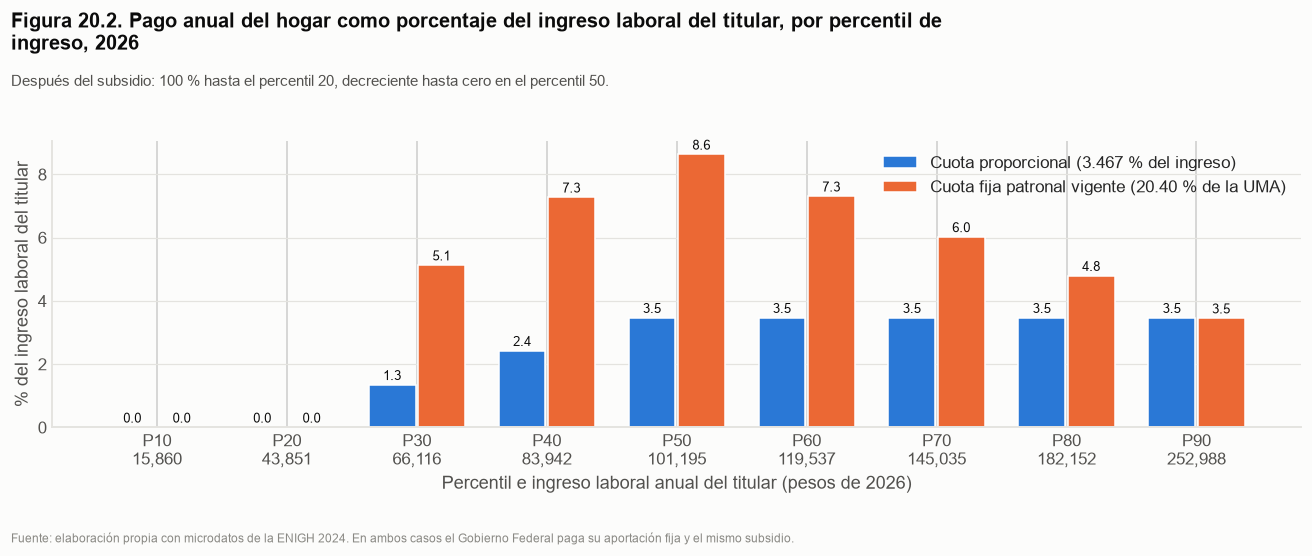

Lectura: En la mediana del ingreso, el hogar pagaría 3.5 % de su ingreso laboral con la cuota proporcional y 8.6 % con
         la cuota fija vigente. La cuota fija pesa más en los ingresos bajos y medios porque es la misma cantidad para
         todos.


In [163]:
# ===== VIZ 20.4 | Pegar debajo de la celda 20.4 (asequibilidad) =====
# ---------------- Figura 20.2 Pago anual del hogar como porcentaje del ingreso laboral ----------------
fig, eje = plt.subplots(figsize=(12, 5))
x = np.arange(len(asequibilidad_10a))
prop = asequibilidad_10a["% del ingreso (cuota proporcional)"]
fija = asequibilidad_10a["% del ingreso (cuota fija)"]
eje.bar(x - 0.19, prop, 0.36, color=PAL["azul"], label="Cuota proporcional (3.467 % del ingreso)")
eje.bar(x + 0.19, fija, 0.36, color=PAL["naranja"], label="Cuota fija patronal vigente (20.40 % de la UMA)")
for i, (a, b) in enumerate(zip(prop, fija)):
    eje.text(i - 0.19, a + 0.15, f"{a:.1f}", ha="center", fontsize=8.5, color=TINTA)
    eje.text(i + 0.19, b + 0.15, f"{b:.1f}", ha="center", fontsize=8.5, color=TINTA)
eje.set_xticks(x, [f"P{p}\n{v:,.0f}" for p, v in zip(asequibilidad_10a.index,
                                                    asequibilidad_10a["ingreso laboral del titular (pesos de 2026)"])])
eje.set_ylabel("% del ingreso laboral del titular")
eje.set_xlabel("Percentil e ingreso laboral anual del titular (pesos de 2026)")
ejes_limpios(eje)
eje.legend(loc="upper right")
tope = titulo(fig, "Figura 20.2. Pago anual del hogar como porcentaje del ingreso laboral del titular, por percentil de ingreso, 2026",
              "Después del subsidio: 100 % hasta el percentil 20, decreciente hasta cero en el percentil 50.")
fuente(fig, "Fuente: elaboración propia con microdatos de la ENIGH 2024. En ambos casos el Gobierno Federal paga su aportación fija y el mismo subsidio.")
plt.tight_layout(rect=[0, 0.07, 1, tope])
guardar_grafica("20_2_asequibilidad")
plt.show()
lectura(f"En la mediana del ingreso, el hogar pagaría {prop.loc[50]:.1f} % de su ingreso laboral con la cuota proporcional y "
        f"{fija.loc[50]:.1f} % con la cuota fija vigente. La cuota fija pesa más en los ingresos bajos y medios porque es la misma "
        "cantidad para todos.")

## 20.5 Qué tan robusto es (10a.5)

In [164]:
# ---------------- 20.5 Qué tan robusto es (sección 10a.5), saldo de 2030 en MDP de 2026 ----------------
ANIO_ROBUSTEZ = 2030
filas = [{"caso": "Supuestos base", "saldo": simular_10a(ANIO_ROBUSTEZ)["saldo sin fuente asignada"]}]
for afiliacion in [0.30, 0.70]:
    filas.append({"caso": f"Afiliación {afiliacion:.0%}",
                  "saldo": simular_10a(ANIO_ROBUSTEZ, afiliacion=afiliacion)["saldo sin fuente asignada"]})
filas.append({"caso": "Cobro 50 %", "saldo": simular_10a(ANIO_ROBUSTEZ, cobro=0.50)["saldo sin fuente asignada"]})
filas.append({"caso": "Costo por persona +2 % real adicional (2054)",
              "saldo": simular_10a(2054, g_costo=0.02)["saldo sin fuente asignada"]})

# Conteo de derechohabientes: el mismo gasto repartido entre otro número de derechohabientes (como en 10a.5)
for nombre, millones in {"Conteo del Informe (79.2 millones)": 79.2, "Conteo con el tabulado preliminar (70.7 millones)": 70.7}.items():
    factor_conteo = dh_total_base / millones
    filas.append({"caso": nombre, "saldo": simular_10a(ANIO_ROBUSTEZ, costo_referencia=COSTO_REFERENCIA * factor_conteo)[
        "saldo sin fuente asignada"]})
robustez_10a = pd.DataFrame(filas).set_index("caso")
robustez_10a["% de los ingresos del SEM"] = robustez_10a["saldo"] / finanzas.loc[ANIO_ROBUSTEZ, "ingresos_SEM"] * 100
robustez_10a.loc["Costo por persona +2 % real adicional (2054)", "% de los ingresos del SEM"] = (
    robustez_10a.loc["Costo por persona +2 % real adicional (2054)", "saldo"] / finanzas.loc[2054, "ingresos_SEM"] * 100)
display(robustez_10a.round(1))

,saldo,% de los ingresos del SEM
caso,,
Supuestos base,288259.6,47.2
Afiliación 30%,172955.8,28.3
Afiliación 70%,403563.5,66.0
Cobro 50 %,300785.2,49.2
Costo por persona +2 % real adicional (2054),874736.0,72.5
Conteo del Informe (79.2 millones),162393.0,26.6
Conteo con el tabulado preliminar (70.7 millones),196088.7,32.1


Gráfica guardada: graficas/reporte\20_3_robustez_afiliacion_subsidiada.png


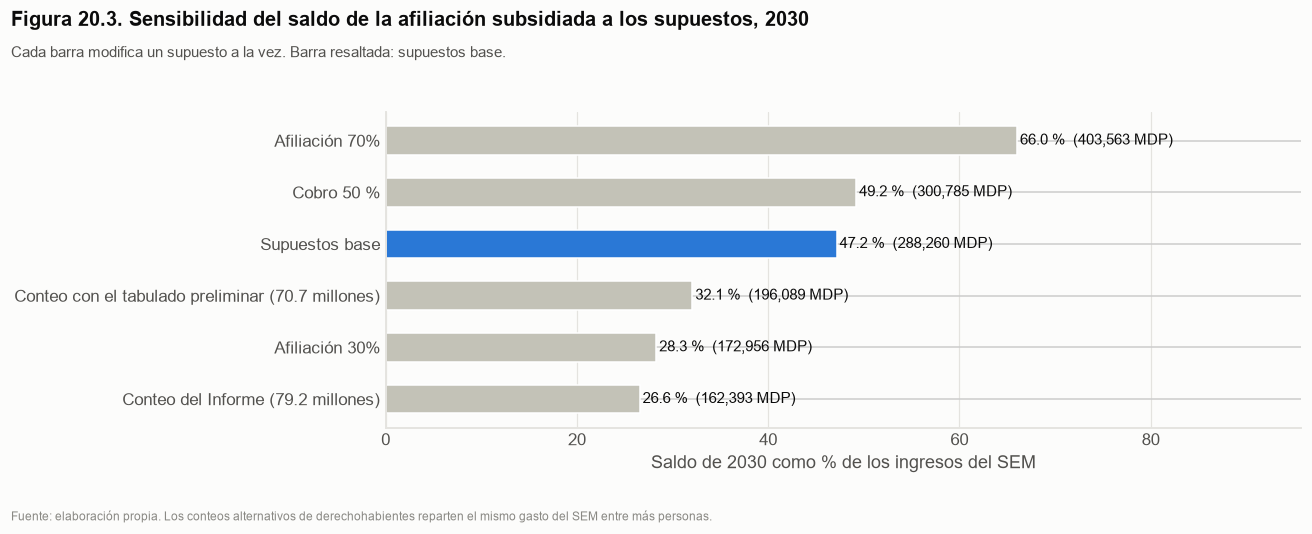

Lectura: Los supuestos que más mueven el saldo de 2030 son «Conteo del Informe (79.2 millones)» y «Afiliación 30%».


In [165]:
# ===== VIZ 20.5 | Pegar debajo de la celda 20.5 (qué tan robusto es) =====
# ---------------- Figura 20.3 Sensibilidad del saldo de la afiliación subsidiada ----------------
robustez_fig = robustez_10a.drop(index=[i for i in robustez_10a.index if "2054" in i], errors="ignore")
robustez_fig = robustez_fig.sort_values("% de los ingresos del SEM")
fig, eje = plt.subplots(figsize=(12, 4.8))
eje.barh(robustez_fig.index, robustez_fig["% de los ingresos del SEM"],
         color=[PAL["azul"] if c == "Supuestos base" else NEUTRO for c in robustez_fig.index], height=0.55)
for i, (p, mdp) in enumerate(zip(robustez_fig["% de los ingresos del SEM"], robustez_fig["saldo"])):
    eje.text(p + 0.3, i, f"{p:.1f} %  ({mdp:,.0f} MDP)", va="center", color=TINTA)
eje.set_xlabel("Saldo de 2030 como % de los ingresos del SEM")
eje.set_xlim(0, robustez_fig["% de los ingresos del SEM"].max() * 1.45)
ejes_limpios(eje, "x")
tope = titulo(fig, "Figura 20.3. Sensibilidad del saldo de la afiliación subsidiada a los supuestos, 2030",
              "Cada barra modifica un supuesto a la vez. Barra resaltada: supuestos base.")
fuente(fig, "Fuente: elaboración propia. Los conteos alternativos de derechohabientes reparten el mismo gasto del SEM entre más personas.")
plt.tight_layout(rect=[0, 0.07, 1, tope])
guardar_grafica("20_3_robustez_afiliacion_subsidiada")
plt.show()
desvio = (robustez_fig["% de los ingresos del SEM"] - robustez_fig.loc["Supuestos base", "% de los ingresos del SEM"]).abs()
principales = desvio.drop("Supuestos base").sort_values(ascending=False).index[:2]
lectura(f"Los supuestos que más mueven el saldo de 2030 son «{principales[0]}» y «{principales[1]}».")

## 20.6 Más formalidad: 3 millones de cotizantes más en 2030

In [166]:
# ---------------- 20.6 Más formalidad: 3 millones de cotizantes más en 2030 (sección 10a.4) ----------------
NUEVOS_COTIZANTES = 3_000_000
DH_POR_COTIZANTE = 2.9               # incluido el cotizante (10a.4)
SALARIO_NUEVOS = SALARIO_MINIMO_2026  # "cerca del salario mínimo"

aporte_cuota_fija = PCT_UMA_PATRON * UMA_DIARIA_2026 * DIAS_COTIZADOS
aporte_cuota_prop = TASA_PROPORCIONAL * SALARIO_NUEVOS * DIAS_COTIZADOS      # salario mínimo constante en términos reales
aporte_gf = PCT_UMA_GF * UMA_DIARIA_2026 * DIAS_COTIZADOS
costo_nuevos = DH_POR_COTIZANTE * COSTO_PROMEDIO_DH * factor_costo(2030)

formalidad_10a = pd.DataFrame({
    "cuota fija vigente": [aporte_cuota_fija, aporte_gf, costo_nuevos],
    "cuota proporcional": [aporte_cuota_prop, aporte_gf, costo_nuevos],
}, index=["cuota por cotizante", "aportación del GF por cotizante", "costo de atención por cotizante"])
formalidad_10a.loc["efecto neto por cotizante"] = (formalidad_10a.loc["cuota por cotizante"]
                                                   + formalidad_10a.loc["aportación del GF por cotizante"]
                                                   - formalidad_10a.loc["costo de atención por cotizante"])
formalidad_10a.loc["efecto neto total (MDP de 2026)"] = formalidad_10a.loc["efecto neto por cotizante"] * NUEVOS_COTIZANTES / 1e6
formalidad_10a.loc["aportación del GF total (MDP de 2026)"] = aporte_gf * NUEVOS_COTIZANTES / 1e6
print("Pesos de 2026 por cotizante al año, salvo los totales:")
display(formalidad_10a.round(0))

Pesos de 2026 por cotizante al año, salvo los totales:


,cuota fija vigente,cuota proporcional
cuota por cotizante,8065.0,3681.0
aportación del GF por cotizante,5863.0,5863.0
costo de atención por cotizante,31190.0,31190.0
efecto neto por cotizante,-17262.0,-21646.0
efecto neto total (MDP de 2026),-51787.0,-64939.0
aportación del GF total (MDP de 2026),17588.0,17588.0


Gráfica guardada: graficas/reporte\20_4_nuevos_cotizantes.png


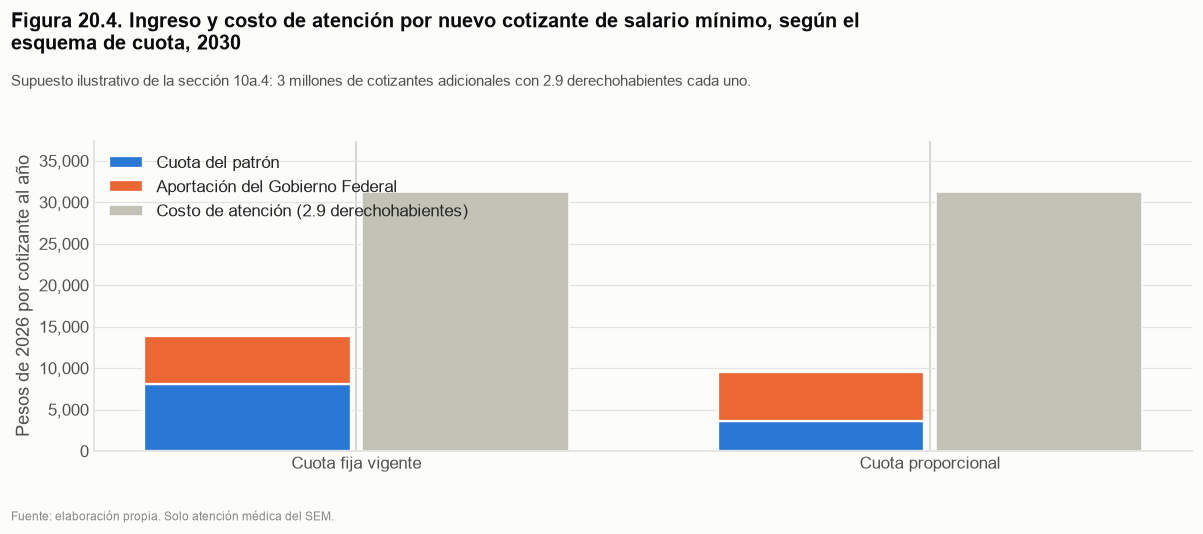

Lectura: El efecto neto de 3 millones de cotizantes adicionales de salario mínimo es de -51,787 MDP con la cuota fija
         vigente y de -64,939 MDP con la cuota proporcional (negativo: cuestan más de lo que aportan).


In [167]:
# ===== VIZ 20.6 | Pegar debajo de la celda 20.6 (3 millones de cotizantes más) =====
# ---------------- Figura 20.4 Ingreso y costo por nuevo cotizante de salario mínimo ----------------
fig, eje = plt.subplots(figsize=(11, 4.8))
x = np.arange(2)
esquemas_f = list(formalidad_10a.columns)
cuota = formalidad_10a.loc["cuota por cotizante", esquemas_f].values
gf = formalidad_10a.loc["aportación del GF por cotizante", esquemas_f].values
costo = formalidad_10a.loc["costo de atención por cotizante", esquemas_f].values
eje.bar(x - 0.19, cuota, 0.36, color=PAL["azul"], label="Cuota del patrón", edgecolor=FONDO, linewidth=1.5)
eje.bar(x - 0.19, gf, 0.36, bottom=cuota, color=PAL["naranja"], label="Aportación del Gobierno Federal", edgecolor=FONDO, linewidth=1.5)
eje.bar(x + 0.19, costo, 0.36, color=NEUTRO, label="Costo de atención (2.9 derechohabientes)")
eje.set_xticks(x, [e.capitalize() for e in esquemas_f])
eje.set_ylabel(EJE_PESOS_PERSONA.replace("por persona", "por cotizante"))
eje.set_ylim(0, costo.max() * 1.2)
ejes_limpios(eje); miles(eje)
eje.legend(loc="upper left")
tope = titulo(fig, "Figura 20.4. Ingreso y costo de atención por nuevo cotizante de salario mínimo, según el esquema de cuota, 2030",
              "Supuesto ilustrativo de la sección 10a.4: 3 millones de cotizantes adicionales con 2.9 derechohabientes cada uno.")
fuente(fig, "Fuente: elaboración propia. Solo atención médica del SEM.")
plt.tight_layout(rect=[0, 0.07, 1, tope])
guardar_grafica("20_4_nuevos_cotizantes")
plt.show()
neto_total = formalidad_10a.loc["efecto neto total (MDP de 2026)", esquemas_f].values
lectura(f"El efecto neto de 3 millones de cotizantes adicionales de salario mínimo es de {neto_total[0]:+,.0f} MDP con la cuota fija "
        f"vigente y de {neto_total[1]:+,.0f} MDP con la cuota proporcional (negativo: cuestan más de lo que aportan).")

## 20.7 Efecto de la cuota proporcional sobre los formales

In [168]:
# ---------------- 20.7 Efecto de la cuota proporcional sobre los formales (va aparte del saldo, 10a.4) ----------------
if MASA_SALARIAL_2026 is None:
    print("Capture MASA_SALARIAL_2026 (20.0) para calcular este efecto.")
else:
    filas = []
    for anio in ANIOS_10A:
        cuota_prop = TASA_PROPORCIONAL * masa_salarial.loc[anio]
        cuota_fija = PCT_UMA_PATRON * UMA_DIARIA_2026 * DIAS_COTIZADOS * cotizantes_sem.loc[anio] / 1e6
        filas.append({"anio": anio, "cuota proporcional (MDP de 2026)": cuota_prop, "cuota fija (MDP de 2026)": cuota_fija,
                      "diferencia (MDP de 2026)": cuota_prop - cuota_fija,
                      "diferencia en puntos del salario": (cuota_prop - cuota_fija) / (masa_salarial.loc[anio]) * 100})
    efecto_formales = pd.DataFrame(filas).set_index("anio")
    # En 2026 la diferencia debe ser cercana a 0: así se calibró la tasa de 3.467 % (10a.2)
    print(f"Verificación 2026: diferencia de {efecto_formales.loc[2026, 'diferencia (MDP de 2026)']:,.0f} MDP "
          "(si no es cercana a 0, la masa salarial capturada no es la que usó Héctor para calibrar la tasa)")
    display(efecto_formales.round(1))

Verificación 2026: diferencia de 8,378 MDP (si no es cercana a 0, la masa salarial capturada no es la que usó Héctor para calibrar la tasa)


,cuota proporcional (MDP de 2026),cuota fija (MDP de 2026),diferencia (MDP de 2026),diferencia en puntos del salario
anio,,,,
2026,191206.5,182828.6,8377.9,0.2
2030,216890.3,203506.0,13384.3,0.2
2040,310417.5,273275.9,37141.7,0.4
2054,485078.0,377449.8,107628.2,0.8


# 21. Sección 10b del documento: seguro solidario con 2 % del salario, conciliado con este cuaderno

**Todo sale del cuaderno; no hace falta capturar nada.**

* **Masa salarial** (20.0): cuotas de GMP de la proyección institucional / 1.5 % (LSS art. 25). Los escenarios de formalización la mueven con su razón de cotizantes.
* **Déficit de GMP** (21.0): costo de atención de los derechohabientes de 60 años o más, con el costo por edad de la sección 19, menos los ingresos de GMP de la proyección institucional. Es solo atención médica: a diferencia del Cuadro V.24 que usa Héctor, no incluye administración, pensiones del personal del IMSS ni provisiones. Si se captura el V.24 en `DEFICIT_GMP_V24`, se usa ese.

**Insumos clave**

* **Ingreso:** 2 % de la masa salarial; masa salarial = ingresos de GMP de la proyección institucional / 1.5 % (LSS art. 25), con proyección institucional de ingresos del IMSS por seguro y concepto, 2024-2055 (documento interno del área de Finanzas. En los escenarios de menor formalización la masa se mueve con la razón de cotizantes.
* **Gasto:** déficit de GMP = costo de atención de los derechohabientes de 60 años o más (costo por persona de la sección 19 = gasto corriente en salud del IMSS (archivo interno `CENTRO DE COSTOS DE QUIROFANO 2020-2026 021026.xlsx`, pestaña `gasto_corrientes_saludIMSS`), deflactado a pesos de 2026 con el Simulador Fiscal del CIEP (`deflator2027.xlsx`)) − ingresos de GMP de la proyección institucional. Solo atención médica; si se captura el Cuadro V.24 del Informe (`DEFICIT_GMP_V24`) se usa ese.
* **Población:** cotizantes del SEM proyectados por el IMSS (`db_nucleo_13.hec_poblacion_sem` y `poblacion_imss.xlsx`, sección 14); población de 15 a 64 años de CONAPO para el escenario de formalidad constante; derechohabientes de 60, 65 y 80 años o más: CONAPO 2022-2070 (`00_Pob_Mitad_1950_2070.csv`, total nacional por edad simple y sexo) × tasa de afiliación al IMSS por rango de edad y sexo de los microdatos ponderados de la ENIGH 2024 (`poblacion.csv`, `inst_1`), sección 13.4; escenarios de la sección 14.7.

In [169]:
# =====================================================================================================
# 21. Sección 10b del documento: seguro solidario con 2 % del salario, conciliado con este cuaderno
# =====================================================================================================
TASA_SEGURO = 0.02
RENDIMIENTO_RESERVA = 0.03
ANIO_INICIO_10B, ANIO_FIN_10B = 2027, 2054
ANIO_FIN_ACUMULACION = 2034          # hasta este año el excedente va a la reserva
RETIRO_FIJO_CUIDADOS = None          # MDP al año desde 2035 en años sin faltante; None = anualidad de la reserva a 2054

# ---------------- Opcional: déficit de GMP del Informe del IMSS 2025-2026 (MDP de 2026; un valor por año 2027-2054) ----------------
# Vacío = se usa el déficit calculado con este cuaderno (al final de esta celda).
DEFICIT_GMP_V24 = {
    # 2027: 74000.0,
}
PROVISIONES_GMP_V19 = {
    # años con provisiones para la operación (Cuadro V.19), para el caso "sin provisiones"
}

# ---------------- Masa salarial por escenario de formalización ----------------
# Proyección del IMSS: masa salarial de 20.0 (proyección institucional).
# Formalidad constante: los cotizantes crecen como la población de 15 a 64 años de CONAPO desde 2026.
# Mitad: a medio camino entre las dos trayectorias de cotizantes.
pet = conapo.loc[(conapo["edad"] >= 15) & (conapo["edad"] <= 64)].groupby("anio")["poblacion"].sum()
cot_imss = cotizantes_sem.loc[ANIO_INICIO_10A:ANIO_FIN_10B]
cot_constante = cotizantes_sem.loc[ANIO_INICIO_10A] * pet.loc[ANIO_INICIO_10A:ANIO_FIN_10B] / pet.loc[ANIO_INICIO_10A]
cotizantes_esc = pd.DataFrame({
    "Formalización de la proyección del IMSS": cot_imss,
    "Mitad de esa formalización": cot_constante + 0.5 * (cot_imss - cot_constante),
    "Formalidad constante": cot_constante,
})
# Los demás escenarios mueven esa masa con su razón de cotizantes frente a la proyección del IMSS
masa_esc_base = cotizantes_esc.div(cot_imss, axis=0).mul(masa_salarial.loc[ANIO_INICIO_10A:ANIO_FIN_10B], axis=0)
print("Cotizantes del SEM por escenario (millones):")
display((cotizantes_esc.loc[[2027, 2030, 2040, 2054]] / 1e6).round(2))

# ---------------- Déficit de GMP calculado con este cuaderno ----------------
# Gasto de GMP: costo de atención de los derechohabientes de EDAD_GMP años o más (aproximación a pensionados y sus
# familiares), con el costo por edad de la sección 19 (gasto del SEM de 19.0). Ingreso de GMP: proyección institucional
# (SEM-GMP). A diferencia del Cuadro V.24, no incluye gastos de administración, pensiones del personal ni provisiones.
EDAD_GMP = 60
dh_gmp = conapo.loc[conapo["edad"] >= EDAD_GMP]
gasto_gmp = ((dh_gmp["derechohabientes"] * peso_costo(dh_gmp["edad"].values)).groupby(dh_gmp["anio"]).sum()
             * COSTO_REFERENCIA / 1e6)
gasto_gmp = gasto_gmp * factor_costo(gasto_gmp.index.values)
if isinstance(sem_componentes.columns, pd.MultiIndex):
    ingreso_gmp = sem_componentes["SEM-GMP"].sum(axis=1)            # cuotas, aportación federal y otros ingresos
else:
    ingreso_gmp = niveles_ingreso["SEM-GMP"]                         # cuotas y aportación federal
ingreso_gmp = ingreso_gmp.reindex(gasto_gmp.index)
deficit_gmp_cuaderno = gasto_gmp - ingreso_gmp
FUENTE_DEFICIT_GMP = "Cuadro V.24" if len(DEFICIT_GMP_V24) > 0 else "calculado en este cuaderno (solo atención médica)"
print("Déficit de GMP que se usa:", FUENTE_DEFICIT_GMP)
display(pd.DataFrame({"gasto de GMP": gasto_gmp, "ingreso de GMP": ingreso_gmp, "déficit de GMP": deficit_gmp_cuaderno,
                      "masa salarial": masa_salarial.reindex(gasto_gmp.index)}).loc[[2025, 2027, 2030, 2040, 2054]].round(0))

Cotizantes del SEM por escenario (millones):


,Formalización de la proyección del IMSS,Mitad de esa formalización,Formalidad constante
anio,,,
2027,23.21,23.04,22.86
2030,25.23,24.28,23.34
2040,33.88,29.01,24.14
2054,46.80,35.23,23.65


Déficit de GMP que se usa: calculado en este cuaderno (solo atención médica)


,gasto de GMP,ingreso de GMP,déficit de GMP,masa salarial
anio,,,,
2025,154921.0,88679.0,66242.0,5392582.0
2027,176555.0,87774.0,88781.0,5636980.0
2030,203853.0,96814.0,107038.0,6255849.0
2040,311427.0,137836.0,173591.0,8953490.0
2054,485950.0,214019.0,271931.0,13991290.0


## 21.1 Simulación del seguro y de la reserva (Tabla 10.3)

In [170]:
# ---------------- 21.1 Simulación del seguro y de la reserva ----------------
if True:          # masa salarial (20.0) y déficit de GMP (21.0) ya vienen del cuaderno
    anios_10b = list(range(ANIO_INICIO_10B, ANIO_FIN_10B + 1))
    if len(DEFICIT_GMP_V24) > 0:
        deficit_imss = pd.Series(DEFICIT_GMP_V24, dtype=float).reindex(anios_10b)
    else:
        deficit_imss = deficit_gmp_cuaderno.reindex(anios_10b)
    provisiones = pd.Series(PROVISIONES_GMP_V19, dtype=float).reindex(anios_10b).fillna(0)
    masa_esc = masa_esc_base.loc[anios_10b].copy()

    # Con menos formalización GMP cobra menos: sus cuotas (1.5 % del SBC) bajan con la masa salarial
    cop_gmp = niveles_ingreso["SEM-GMP"].reindex(anios_10b)

    def simular_10b(escenario, con_reserva=True, sin_provisiones=False):
        ingreso = TASA_SEGURO * masa_esc[escenario]
        deficit = deficit_imss - (provisiones if sin_provisiones else 0)
        if cop_gmp is not None:
            deficit = deficit + cop_gmp * (1 - masa_esc[escenario] / masa_esc["Formalización de la proyección del IMSS"])
        reserva, retiro, filas = 0.0, RETIRO_FIJO_CUIDADOS, []
        for anio in anios_10b:
            reserva_inicial = reserva * (1 + RENDIMIENTO_RESERVA)
            if con_reserva and anio == ANIO_FIN_ACUMULACION + 1 and retiro is None:
                # Monto fijo: anualidad que agota la reserva en ANIO_FIN_10B
                n = ANIO_FIN_10B - anio + 1
                retiro = reserva_inicial * RENDIMIENTO_RESERVA / (1 - (1 + RENDIMIENTO_RESERVA) ** -n)
            saldo = ingreso.loc[anio] - deficit.loc[anio]
            cuidados, faltante = 0.0, 0.0
            if not con_reserva:
                cuidados, faltante, reserva = max(saldo, 0.0), max(-saldo, 0.0), 0.0
            elif saldo >= 0 and anio <= ANIO_FIN_ACUMULACION:
                reserva = reserva_inicial + saldo
            elif saldo >= 0:
                sacar = min(retiro, reserva_inicial)
                cuidados, reserva = saldo + sacar, reserva_inicial - sacar
            else:
                pagado = min(-saldo, reserva_inicial)
                reserva, faltante = reserva_inicial - pagado, -saldo - pagado
            filas.append({"anio": anio, "ingreso": ingreso.loc[anio], "deficit_GMP": deficit.loc[anio],
                          "cuidados": cuidados, "reserva_cierre": reserva, "faltante_sin_pagar": faltante})
        return pd.DataFrame(filas).set_index("anio")

    # Tabla 10.3: último año en que el seguro paga completo el déficit de GMP
    tabla_10_3 = pd.DataFrame(index=masa_esc.columns)
    for etiqueta, con_reserva, sin_prov in [("Con reserva", True, False), ("Con reserva, sin provisiones", True, True),
                                            ("Sin reserva", False, False), ("Sin reserva, sin provisiones", False, True)]:
        for escenario in masa_esc.columns:
            r = simular_10b(escenario, con_reserva, sin_prov)
            faltan = r.index[r["faltante_sin_pagar"] > 1e-6]
            tabla_10_3.loc[escenario, etiqueta] = ANIO_FIN_10B if len(faltan) == 0 else faltan[0] - 1
    print(f"Último año en que el seguro paga completo el déficit de GMP (2054 = todo el periodo; 2026 = no alcanza desde 2027). Déficit: {FUENTE_DEFICIT_GMP}")
    display(tabla_10_3.astype(int))

    # Recursos para cuidados por persona de 65 y de 80 años o más con IMSS (derechohabientes de la sección 13.4)
    base_10b = simular_10b("Formalización de la proyección del IMSS")
    dh_65 = conapo.loc[conapo["edad"] >= 65].groupby("anio")["derechohabientes"].sum()
    dh_80 = conapo.loc[conapo["edad"] >= 80].groupby("anio")["derechohabientes"].sum()
    cuidados_persona = pd.DataFrame({
        "cuidados (MDP de 2026)": base_10b["cuidados"],
        "pesos por persona de 65 o más con IMSS": base_10b["cuidados"] * 1e6 / dh_65.reindex(base_10b.index),
        "pesos por persona de 80 o más con IMSS": base_10b["cuidados"] * 1e6 / dh_80.reindex(base_10b.index),
    })
    display(base_10b.loc[[2027, 2030, 2034, 2035, 2040, 2054]].round(0))

    # Valor presente (3 % real, a 2027): cuidados + reserva final − faltantes, con reserva y sin ella (10b.4)
    def valor_presente(serie):
        return (serie / (1 + RENDIMIENTO_RESERVA) ** (serie.index - ANIO_INICIO_10B)).sum()

    for etiqueta, con_reserva in [("con reserva", True), ("sin reserva", False)]:
        r = simular_10b("Formalización de la proyección del IMSS", con_reserva)
        vp = (valor_presente(r["cuidados"]) - valor_presente(r["faltante_sin_pagar"])
              + r["reserva_cierre"].iloc[-1] / (1 + RENDIMIENTO_RESERVA) ** (ANIO_FIN_10B - ANIO_INICIO_10B))
        print(f"Cuidados + reserva - faltantes, valor presente {etiqueta}: {vp:,.0f} MDP de 2026")
    display(cuidados_persona.loc[[2035, 2040, 2054]].round(0))

Último año en que el seguro paga completo el déficit de GMP (2054 = todo el periodo; 2026 = no alcanza desde 2027). Déficit: calculado en este cuaderno (solo atención médica)


,Con reserva,"Con reserva, sin provisiones",Sin reserva,"Sin reserva, sin provisiones"
Formalización de la proyección del IMSS,2054,2054,2054,2054
Mitad de esa formalización,2037,2037,2032,2032
Formalidad constante,2033,2033,2030,2030


,ingreso,deficit_GMP,cuidados,reserva_cierre,faltante_sin_pagar
anio,,,,,
2027,112740.0,88781.0,0.0,23959.0,0.0
2030,125117.0,107038.0,0.0,88414.0,0.0
2034,144083.0,133262.0,0.0,156172.0,0.0
2035,149349.0,140071.0,20091.0,150045.0,0.0
2040,179070.0,173591.0,16291.0,116540.0,0.0
2054,279826.0,271931.0,10245.0,0.0,0.0


Cuidados + reserva - faltantes, valor presente con reserva: 228,862 MDP de 2026
Cuidados + reserva - faltantes, valor presente sin reserva: 228,862 MDP de 2026


,cuidados (MDP de 2026),pesos por persona de 65 o más con IMSS,pesos por persona de 80 o más con IMSS
anio,,,
2035,20091.0,2503.0,12558.0
2040,16291.0,1709.0,7950.0
2054,10245.0,768.0,2721.0


Verificación: cambio de la reserva = ingreso + rendimientos - pago de GMP - cuidados, en los tres escenarios.
Gráfica guardada: graficas/reporte\21_1_stock_flujos_reserva.png


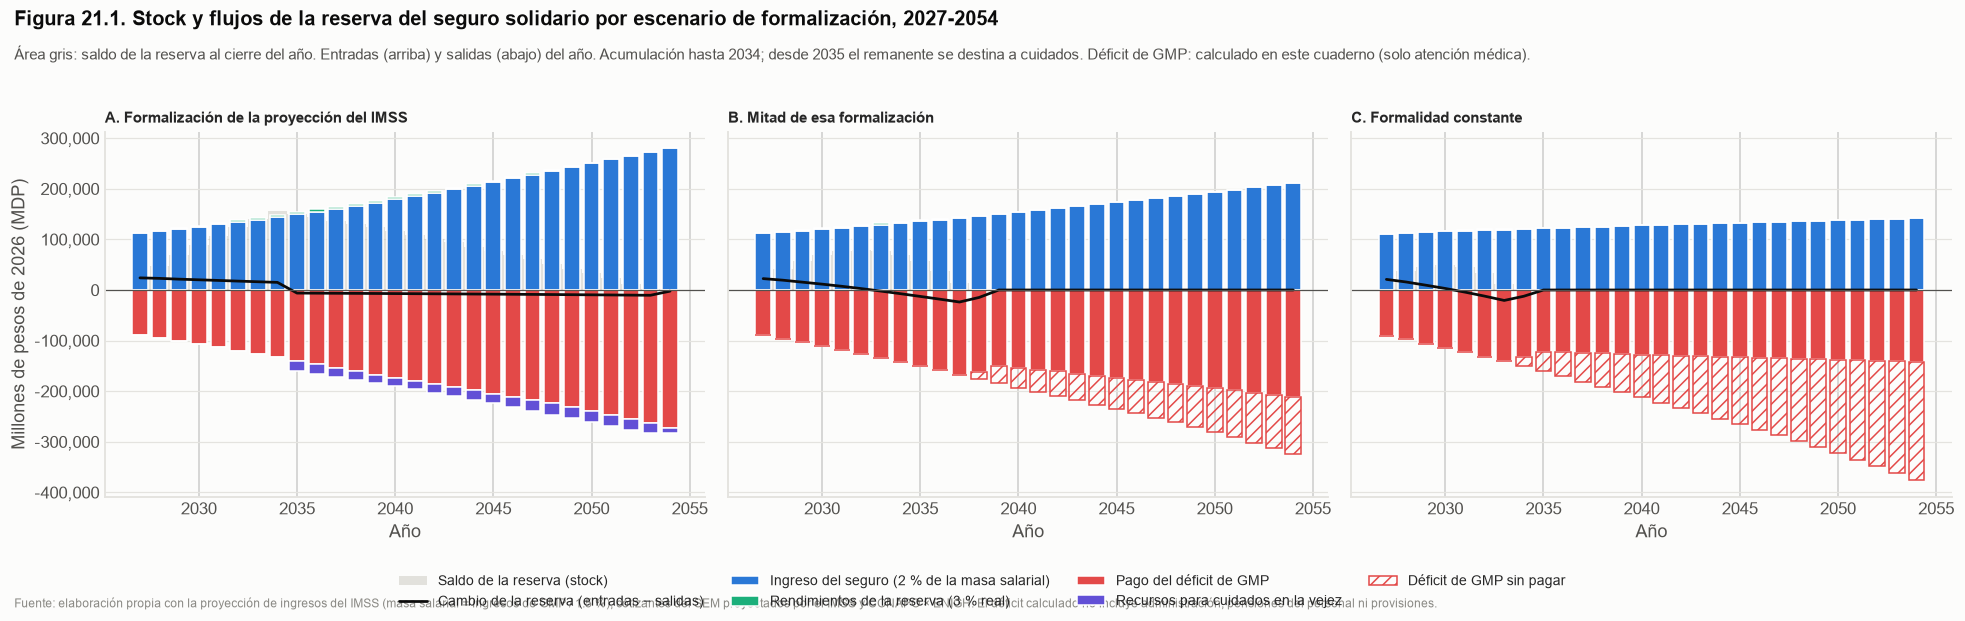

Lectura: Último año en que el seguro paga completo el déficit de GMP: Formalización de la proyección del IMSS: 2054;
         Mitad de esa formalización: 2037; Formalidad constante: 2033 (2054 = todo el periodo). Saldo máximo de la
         reserva: Formalización de la proyección del IMSS: 156,172 MDP; Mitad de esa formalización: 78,923 MDP;
         Formalidad constante: 49,325 MDP.


In [171]:
# ===== VIZ 21.1 | Pegar debajo de la celda 21.1 (simulación del seguro y de la reserva) =====
# ---------------- Figura 21.1 Stock y flujos de la reserva del seguro solidario ----------------
# Stock: saldo de la reserva. Entradas: 2 % de la masa salarial y rendimientos. Salidas: pago del déficit de GMP y cuidados.
# Identidad que se verifica: cambio de la reserva = ingreso + rendimientos − pago de GMP − cuidados.
COLOR_ESC_10B = {"Formalización de la proyección del IMSS": PAL["azul"], "Mitad de esa formalización": PAL["naranja"],
                 "Formalidad constante": PAL["aqua"]}
sim_10b = {escenario: simular_10b(escenario) for escenario in COLOR_ESC_10B}
flujos_10b = {}
for escenario, r in sim_10b.items():
    f = pd.DataFrame(index=r.index)
    reserva_previa = r["reserva_cierre"].shift(1).fillna(0.0)
    f["ingreso"] = r["ingreso"]
    f["rendimientos"] = reserva_previa * RENDIMIENTO_RESERVA
    f["pago_gmp"] = r["deficit_GMP"] - r["faltante_sin_pagar"]
    f["cuidados"] = r["cuidados"]
    f["reserva"] = r["reserva_cierre"]
    f["cambio_reserva"] = r["reserva_cierre"] - reserva_previa
    f["faltante"] = r["faltante_sin_pagar"]
    error = (f["ingreso"] + f["rendimientos"] - f["pago_gmp"] - f["cuidados"] - f["cambio_reserva"]).abs().max()
    assert error < 1e-3, f"La identidad de la reserva no cierra en {escenario}: {error}"
    flujos_10b[escenario] = f
print("Verificación: cambio de la reserva = ingreso + rendimientos - pago de GMP - cuidados, en los tres escenarios.")

ENTRADAS_10B = {"ingreso": ("Ingreso del seguro (2 % de la masa salarial)", PAL["azul"]),
                "rendimientos": ("Rendimientos de la reserva (3 % real)", PAL["aqua"])}
SALIDAS_10B = {"pago_gmp": ("Pago del déficit de GMP", FALTANTE), "cuidados": ("Recursos para cuidados en la vejez", PAL["violeta"])}
fig, ejes = plt.subplots(1, len(flujos_10b), figsize=(18, 5.6), sharey=True)
for k, (eje, (escenario, f)) in enumerate(zip(ejes, flujos_10b.items())):
    eje.fill_between(f.index, 0, f["reserva"], color=NEUTRO, alpha=0.45, linewidth=0, step="mid", label="Saldo de la reserva (stock)")
    panel_flujos(eje, f, ENTRADAS_10B, SALIDAS_10B, f["cambio_reserva"], etiqueta_neto="Cambio de la reserva (entradas − salidas)")
    if f["faltante"].sum() > 0:
        eje.bar(f.index, -f["faltante"], bottom=-(f["pago_gmp"] + f["cuidados"]), color="none", edgecolor=FALTANTE,
                hatch="///", width=0.8, label="Déficit de GMP sin pagar")
    eje.set_title(f"{'ABC'[k]}. {escenario}", fontsize=10)
    eje.set_xlabel("Año")
ejes[0].set_ylabel(EJE_MDP)
manejadores, etiquetas = [], []
for eje in ejes:
    for m, e in zip(*eje.get_legend_handles_labels()):
        if e not in etiquetas:
            manejadores.append(m); etiquetas.append(e)
fig.legend(manejadores, etiquetas, loc="lower center", ncol=4, fontsize=9)
tope = titulo(fig, f"Figura 21.1. Stock y flujos de la reserva del seguro solidario por escenario de formalización, "
                   f"{ANIO_INICIO_10B}-{ANIO_FIN_10B}",
              f"Área gris: saldo de la reserva al cierre del año. Entradas (arriba) y salidas (abajo) del año. Acumulación hasta "
              f"{ANIO_FIN_ACUMULACION}; desde {ANIO_FIN_ACUMULACION + 1} el remanente se destina a cuidados. Déficit de GMP: {FUENTE_DEFICIT_GMP}.")
fuente(fig, "Fuente: elaboración propia con la proyección de ingresos del IMSS (masa salarial = ingresos de GMP / 1.5 %), cotizantes del "
            "SEM proyectados por el IMSS y CONAPO × ENIGH. El déficit calculado no incluye administración, pensiones del personal ni provisiones.")
plt.tight_layout(rect=[0, 0.09, 1, tope])
guardar_grafica("21_1_stock_flujos_reserva")
plt.show()
ultimo = {e: (ANIO_FIN_10B if (f["faltante"] <= 1e-6).all() else f.index[f["faltante"] > 1e-6][0] - 1) for e, f in flujos_10b.items()}
reserva_max = {e: f["reserva"].max() for e, f in flujos_10b.items()}
lectura("Último año en que el seguro paga completo el déficit de GMP: " +
        "; ".join(f"{e}: {a if a >= ANIO_INICIO_10B else 'ningún año'}" for e, a in ultimo.items()) +
        f" ({ANIO_FIN_10B} = todo el periodo). Saldo máximo de la reserva: " +
        "; ".join(f"{e}: {v:,.0f} MDP" for e, v in reserva_max.items()) + ".")

Gráfica guardada: graficas/reporte\21_2_cuidados_por_persona.png


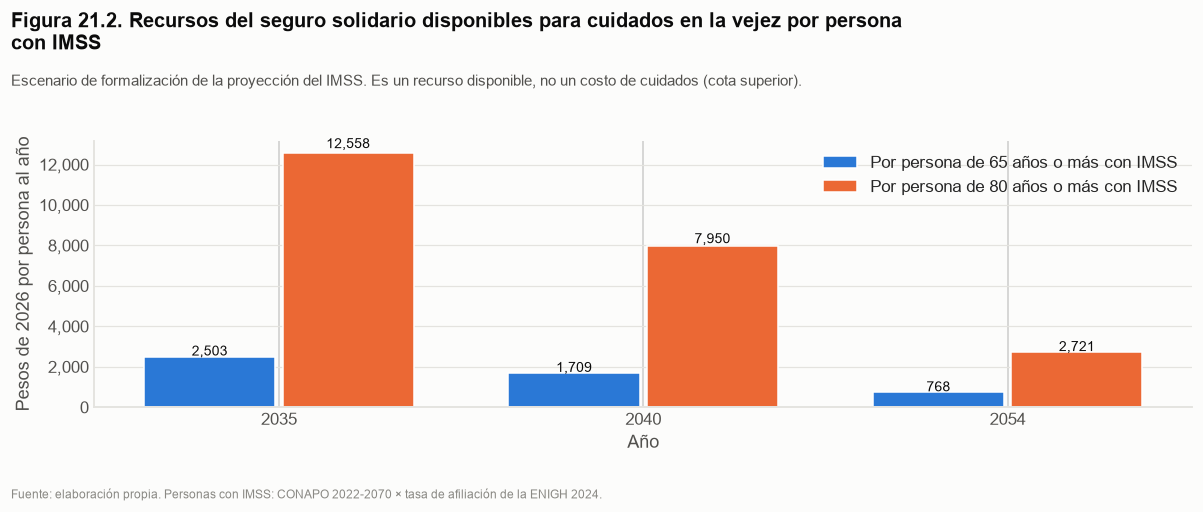

Lectura: Después de pagar el déficit de GMP, el seguro dejaría para cuidados 1,709 pesos al año por persona de 65 años
         o más con IMSS en 2040 y 768 en 2054.


In [172]:
# ===== VIZ 21.1b | Pegar debajo de la VIZ 21.1 =====
# ---------------- Figura 21.2 Recursos disponibles para cuidados por persona ----------------
cuidados_fig = cuidados_persona.loc[[2035, 2040, ANIO_FIN_10B]]
fig, eje = plt.subplots(figsize=(11, 4.6))
x = np.arange(len(cuidados_fig))
c65 = cuidados_fig["pesos por persona de 65 o más con IMSS"]
c80 = cuidados_fig["pesos por persona de 80 o más con IMSS"]
eje.bar(x - 0.19, c65, 0.36, color=PAL["azul"], label="Por persona de 65 años o más con IMSS")
eje.bar(x + 0.19, c80, 0.36, color=PAL["naranja"], label="Por persona de 80 años o más con IMSS")
for i, (a, b) in enumerate(zip(c65, c80)):
    eje.text(i - 0.19, a * 1.02, f"{a:,.0f}", ha="center", fontsize=9, color=TINTA)
    eje.text(i + 0.19, b * 1.02, f"{b:,.0f}", ha="center", fontsize=9, color=TINTA)
eje.set_xticks(x, [str(a) for a in cuidados_fig.index])
eje.set_xlabel("Año")
eje.set_ylabel(EJE_PESOS_PERSONA)
ejes_limpios(eje); miles(eje)
eje.legend(loc="upper right")
tope = titulo(fig, "Figura 21.2. Recursos del seguro solidario disponibles para cuidados en la vejez por persona con IMSS",
              "Escenario de formalización de la proyección del IMSS. Es un recurso disponible, no un costo de cuidados (cota superior).")
fuente(fig, "Fuente: elaboración propia. Personas con IMSS: CONAPO 2022-2070 × tasa de afiliación de la ENIGH 2024.")
plt.tight_layout(rect=[0, 0.07, 1, tope])
guardar_grafica("21_2_cuidados_por_persona")
plt.show()
lectura(f"Después de pagar el déficit de GMP, el seguro dejaría para cuidados {c65.loc[2040]:,.0f} pesos al año por persona de 65 años "
        f"o más con IMSS en 2040 y {c65.loc[ANIO_FIN_10B]:,.0f} en {ANIO_FIN_10B}.")

# 22. Escenarios de población × experimentos de Héctor

Une los **escenarios E0–E9** (sección 14) con las **ideas de gasto e ingreso de Héctor** (secciones 20 y 21). La ENIGH se repondera para reproducir la población de cada escenario. Del ISSSTE y los demás subsistemas no hay datos de gasto ni de ingresos: solo se describen (22.1).

**Insumos clave**

* **Ingreso:** en el escenario base, proyección institucional de ingresos del IMSS por seguro y concepto, 2024-2055 (documento interno del área de Finanzas; base `db_nucleo_13.hec_ingreso_imss`), procesada en el cuaderno de ingresos; ingresos del SEM = SEM-A + SEM-GMP (cuotas obrero-patronales, aportación del Gobierno Federal y otros ingresos), `finanzas["ingresos_SEM"]` (Tabla 5 del documento), MDP de 2026. En los demás escenarios se mueve con la razón de cuotas de salud de los cotizantes del IMSS de la ENIGH reponderada (tasas de la LSS art. 106 e Informe al Ejecutivo 2021-2022, cuadro A.4, tomadas del cuaderno NTA).
* **Gasto:** derechohabientes de cada edad del escenario × costo por persona de la sección 19 = gasto corriente en salud del IMSS (archivo interno `CENTRO DE COSTOS DE QUIROFANO 2020-2026 021026.xlsx`, pestaña `gasto_corrientes_saludIMSS`), deflactado a pesos de 2026 con el Simulador Fiscal del CIEP (`deflator2027.xlsx`); 2025 × `PCT_GASTO_SEM` (18.1b, base 100 %). Se reparte entre los derechohabientes de 2025 con el perfil por edad de la Tabla 10.1 (65 años o más = triple de 20 a 64) y crece con el salario real (`g_SBC_real`, hoja Resumen_tasas del cuaderno de ingresos, que viene de `db_nucleo_13.hec_crecimiento_sbc`).
* **Población:** escenarios E0 a E9 de la sección 14 (factores de nacimientos, mayores y afiliación sobre CONAPO × ENIGH, 14.5-14.7), aplicados a la ENIGH 2024 reponderada (22.3); subsistemas y cotizantes de 19.0b.

In [173]:
# =====================================================================================================
# 22. Escenarios de población (sección 14) × experimentos de Héctor (secciones 20 y 21)
# =====================================================================================================
# Subsistemas, cotizantes e ingresos de la ENIGH: variables de 19.0b. Solo el IMSS tiene balance gasto-ingreso;
# del ISSSTE y los demás no hay datos de gasto ni de ingresos, así que solo se describen (22.1).
ESCENARIOS_21 = list(grid_escenarios["escenario"])        # E0 a E9 de la sección 14.6
ANIOS_21 = [2025, 2030, 2035, 2040, 2045, 2050, 2054]

# Cuotas de salud del IMSS (cuaderno NTA, parametros_fiscales.json; LSS art. 106 e Informe al Ejecutivo 2021-2022, A.4).
# % del SBC: enfermedades y maternidad de asegurados + gastos médicos de pensionados. Solo sirven para mover los ingresos
# entre escenarios (22.4); el nivel lo da la Tabla 5.
CUOTA_SALUD_IMSS_PCT_SBC = (5.42 + 1.05) + (0.44 + 0.37) + (3.21 + 0.08)     # patrón + trabajador + gobierno
# Gasto e ingreso de ANIO_BASE para calibrar (MDP de 2026). El ingreso del IMSS lo da la Tabla 5 en 22.4.
GASTO_SALUD_BASE = {"IMSS": GASTO_SEM_BASE}
INGRESO_SALUD_BASE = {"IMSS": None}
SBC_TOPE_UMAS_IMSS = 25.0
DIAS_SBC = 360                           # como en NTA: SBC anual = piso(ingreso / 360 / UMA) × UMA × 360

## 22.1 Cobertura por subsistema

In [174]:
# ---------------- 22.1 Cobertura por subsistema (variables de 19.0b) ----------------
resumen_subsistemas = personas.assign(
    personas_w=personas["factor"], cotizantes_w=personas["factor"] * personas["cotizante"]
).groupby("subsistema")[["personas_w", "cotizantes_w"]].sum() / 1e6
resumen_subsistemas.columns = ["personas (millones, ENIGH)", "cotizantes (millones, ENIGH)"]
display(resumen_subsistemas.round(2))

,"personas (millones, ENIGH)","cotizantes (millones, ENIGH)"
subsistema,,
IMSS,53.63,21.47
ISSSTE,6.37,2.55
ISSSTE estatal,1.09,0.27
"Pemex, Defensa o Marina",1.86,0.80
Sin seguridad social contributiva,67.39,0.00


Gráfica guardada: graficas/reporte\22_1_subsistemas.png


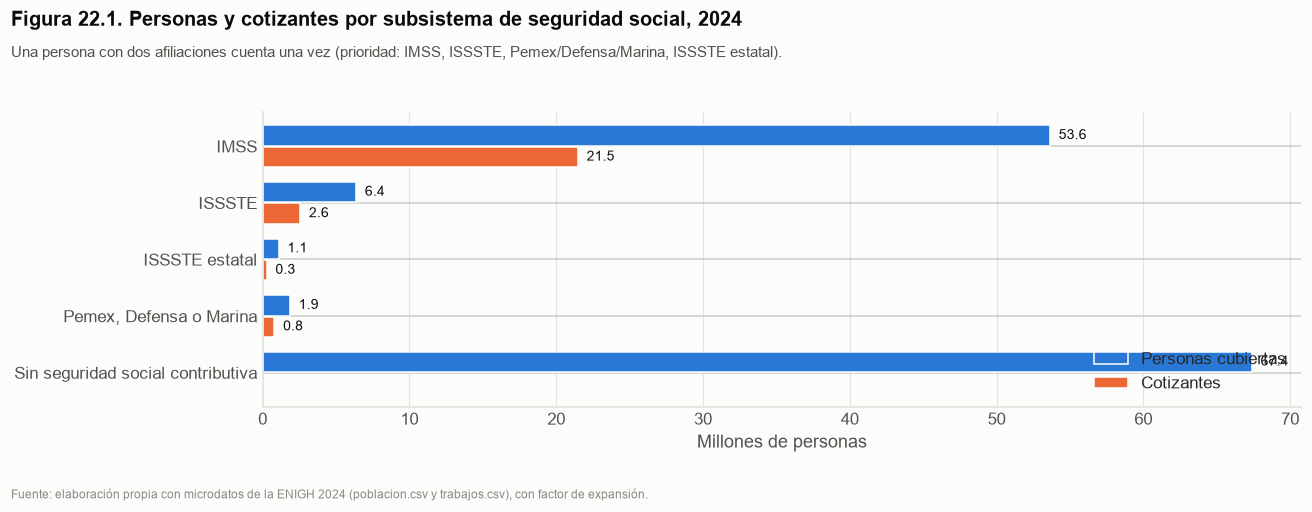

Lectura: 52 % de la población no tiene seguridad social contributiva. Solo el IMSS tiene balance de gasto e ingreso en
         este cuaderno, porque no hay datos de gasto ni de ingresos de los demás subsistemas.


In [175]:
# ===== VIZ 22.1 | Pegar debajo de la celda 22.1 (cobertura por subsistema) =====
# ---------------- Figura 22.1 Personas y cotizantes por subsistema de seguridad social ----------------
orden_sub = ["IMSS", "ISSSTE", "ISSSTE estatal", "Pemex, Defensa o Marina", SIN_SS]
sub_fig = resumen_subsistemas.reindex([s for s in orden_sub if s in resumen_subsistemas.index])
fig, eje = plt.subplots(figsize=(12, 4.6))
y = np.arange(len(sub_fig))
eje.barh(y - 0.19, sub_fig["personas (millones, ENIGH)"], 0.36, color=PAL["azul"], label="Personas cubiertas")
eje.barh(y + 0.19, sub_fig["cotizantes (millones, ENIGH)"], 0.36, color=PAL["naranja"], label="Cotizantes")
for i, (a, b) in enumerate(zip(sub_fig["personas (millones, ENIGH)"], sub_fig["cotizantes (millones, ENIGH)"])):
    eje.text(a + 0.6, i - 0.19, f"{a:,.1f}", va="center", fontsize=9, color=TINTA)
    if b > 0:
        eje.text(b + 0.6, i + 0.19, f"{b:,.1f}", va="center", fontsize=9, color=TINTA)
eje.set_yticks(y, sub_fig.index)
eje.invert_yaxis()
eje.set_xlabel("Millones de personas")
ejes_limpios(eje, "x")
eje.legend(loc="lower right")
tope = titulo(fig, "Figura 22.1. Personas y cotizantes por subsistema de seguridad social, 2024",
              "Una persona con dos afiliaciones cuenta una vez (prioridad: IMSS, ISSSTE, Pemex/Defensa/Marina, ISSSTE estatal).")
fuente(fig, "Fuente: elaboración propia con microdatos de la ENIGH 2024 (poblacion.csv y trabajos.csv), con factor de expansión.")
plt.tight_layout(rect=[0, 0.07, 1, tope])
guardar_grafica("22_1_subsistemas")
plt.show()
pct_sin = (sub_fig.loc[SIN_SS, "personas (millones, ENIGH)"] / sub_fig["personas (millones, ENIGH)"].sum() * 100
           if SIN_SS in sub_fig.index else np.nan)
lectura(f"{pct_sin:.0f} % de la población no tiene seguridad social contributiva. Solo el IMSS tiene balance de gasto e ingreso en este "
        "cuaderno, porque no hay datos de gasto ni de ingresos de los demás subsistemas.")

## 22.2 Cuota de salud de los cotizantes del IMSS (fórmula del cuaderno NTA)

In [176]:
# ---------------- 22.2 Cuota de salud de cada cotizante del IMSS (fórmula del cuaderno NTA) ----------------
ingreso_anual_2026 = personas["ing_sub_mensual"].values * 12 * factor_ingreso_2026


def cuota_salud_imss(ingreso_anual, uma_diaria=UMA_DIARIA_2026):
    sbc_umas = np.where(ingreso_anual > 0, ingreso_anual / DIAS_SBC / uma_diaria, 0.0)
    sbc_umas = np.where((sbc_umas > 0) & (sbc_umas < 1), 1.0, sbc_umas)            # piso de 1 UMA
    sbc_umas = np.minimum(sbc_umas, SBC_TOPE_UMAS_IMSS)                            # tope de 25 UMA
    return np.floor(sbc_umas) * uma_diaria * DIAS_SBC * CUOTA_SALUD_IMSS_PCT_SBC / 100


personas["cuota_salud_2026"] = np.where(personas["cotizante_imss"] == 1, cuota_salud_imss(ingreso_anual_2026), 0.0)

## 22.3 Pesos de la ENIGH por escenario

In [177]:
# ---------------- 22.3 Pesos de la ENIGH por escenario: reproducen la población y los derechohabientes de 14.7 ----------------
# peso = factor × población del escenario / población ENIGH × tasa del subsistema en el escenario / tasa ENIGH.
# El escenario solo mueve la tasa IMSS (afiliación en pp); las tasas de los demás subsistemas se quedan en las de la
# ENIGH y "Sin seguridad social" es el resto.
claves_rs = ["grupo_edad", "sexo"]
tasa_sub_enigh = (personas.assign(w=personas["factor"]).pivot_table(index=claves_rs, columns="subsistema", values="w",
                                                                    aggfunc="sum", observed=False).fillna(0))
tasa_sub_enigh = tasa_sub_enigh.div(tasa_sub_enigh.sum(axis=1), axis=0)

dh_edad_esc["poblacion_escenario"] = dh_edad_esc["poblacion"] * dh_edad_esc["factor_nacimientos"] * dh_edad_esc["factor_mayores"]
agregado_esc = dh_edad_esc.groupby(["escenario", "anio"] + claves_rs, observed=False)[
    ["poblacion_escenario", "derechohabientes"]].sum()


def pesos_escenario(anio, escenario):
    agregado = agregado_esc.loc[(escenario, anio)]
    tasas = tasa_sub_enigh.copy()
    tasa_imss_esc = (agregado["derechohabientes"] / agregado["poblacion_escenario"]).reindex(tasas.index).fillna(0)
    otros = [c for c in tasas.columns if c not in ["IMSS", SIN_SS]]
    tasas_esc = tasas.copy()
    tasas_esc["IMSS"] = tasa_imss_esc
    tasas_esc[SIN_SS] = (1 - tasas_esc["IMSS"] - tasas_esc[otros].sum(axis=1)).clip(lower=0)
    razon_tasa = (tasas_esc / tasas).replace([np.inf, -np.inf], np.nan).fillna(0)
    razon_pob = (agregado["poblacion_escenario"].reindex(tasas.index) / poblacion_enigh.reindex(tasas.index)).replace(
        [np.inf, -np.inf], np.nan).fillna(0)
    razon = razon_tasa.mul(razon_pob, axis=0).stack().rename("razon").reset_index()
    tabla = personas[claves_rs + ["subsistema"]].merge(razon, on=claves_rs + ["subsistema"], how="left")
    return personas["factor"].values * tabla["razon"].fillna(0).values


# Verificación: con los pesos de cada escenario, los derechohabientes IMSS son los de 14.7
verificacion = {}
for escenario in ESCENARIOS_21:
    w = pesos_escenario(2040, escenario)
    verificacion[escenario] = (w * (personas["subsistema"] == "IMSS")).sum() / dh_total_esc.loc[2040, escenario]
print("Derechohabientes IMSS reponderados / sección 14.7, año 2040 (debe ser ~1):",
      {k: round(v, 4) for k, v in verificacion.items()})

Derechohabientes IMSS reponderados / sección 14.7, año 2040 (debe ser ~1): {'E0': np.float64(1.0), 'E1': np.float64(1.0), 'E2': np.float64(1.0), 'E3': np.float64(1.0), 'E4': np.float64(1.0), 'E5': np.float64(1.0), 'E6': np.float64(1.0), 'E7': np.float64(1.0), 'E8': np.float64(1.0), 'E9': np.float64(1.0)}


## 22.4 Brecha del SEM con gasto ligado a la demanda (método «demanda» de la sección 5.6)

In [178]:
# ---------------- 22.4 Balance gasto-ingreso por escenario y subsistema ----------------
# Es la brecha Δ(t) de la sección 5.6 del documento con un gasto ligado a la demanda (método «demanda»):
# Gasto: derechohabientes de cada edad × costo por persona con el perfil de edad de 19.0, calibrado al gasto de
#        ANIO_BASE y creciendo con factor_costo. Ingreso: la Tabla 5 completa (ingresos del SEM); en cada escenario se
#        mueve con la razón de cuotas de salud de los cotizantes IMSS de la ENIGH reponderada frente a E0.
# En ANIO_BASE la brecha es la misma de la sección 16.6.
peso_edad_personas = peso_costo(personas["edad"].values)
w_base = pesos_escenario(ANIO_BASE, "E0")

SUBSISTEMAS_BALANCE = ["IMSS"]
calibracion = {}
for nombre in SUBSISTEMAS_BALANCE:
    es_sub = (personas["subsistema"] == nombre).values
    gasto_base = GASTO_SALUD_BASE.get(nombre)
    ingreso_base = INGRESO_SALUD_BASE.get(nombre)
    calibracion[nombre] = {
        "costo_referencia": (gasto_base * 1e6 / (w_base * es_sub * peso_edad_personas).sum()) if gasto_base else np.nan,
        "factor_ingreso": (ingreso_base * 1e6 / (w_base * personas["cuota_salud_2026"].values * es_sub).sum())
                          if ingreso_base else 1.0,
    }
display(pd.DataFrame(calibracion).T.round(3))

ingreso_tabla5 = finanzas["ingresos_SEM"]                 # Tabla 5: cuotas, aportación federal y otros ingresos

filas = []
for escenario in ESCENARIOS_21:
    for anio in ANIOS_21:
        w = pesos_escenario(anio, escenario)
        w_e0 = pesos_escenario(anio, "E0")
        for nombre in SUBSISTEMAS_BALANCE:
            es_sub = (personas["subsistema"] == nombre).values
            c = calibracion[nombre]
            gasto = (w * es_sub * peso_edad_personas).sum() * c["costo_referencia"] * factor_costo(anio) / 1e6
            cuotas = (w * es_sub * personas["cuota_salud_2026"].values).sum() * c["factor_ingreso"] * indice_salario.get(anio, 1.0) / 1e6
            if nombre == "IMSS" and ingreso_tabla5 is not None:
                cuotas_e0 = (w_e0 * es_sub * personas["cuota_salud_2026"].values).sum()
                cuotas_esc = (w * es_sub * personas["cuota_salud_2026"].values).sum()
                cuotas = ingreso_tabla5.loc[anio] * cuotas_esc / cuotas_e0
            filas.append({"escenario": escenario, "anio": anio, "subsistema": nombre,
                          "derechohabientes (millones)": (w * es_sub).sum() / 1e6,
                          "cotizantes (millones)": (w * es_sub * personas["cotizante"].values).sum() / 1e6,
                          "gasto (MDP de 2026)": gasto, "ingreso (MDP de 2026)": cuotas,
                          "brecha gasto - ingreso (MDP de 2026)": gasto - cuotas})
balance_21 = pd.DataFrame(filas)

print("IMSS: brecha gasto - ingreso por escenario (MDP de 2026). Gasto ligado a la demanda por edad:")
display(balance_21.loc[balance_21["subsistema"] == "IMSS"].pivot(
    index="anio", columns="escenario", values="brecha gasto - ingreso (MDP de 2026)").round(0))
brecha_imss = balance_21.loc[balance_21["subsistema"] == "IMSS"].pivot(
    index="anio", columns="escenario", values="brecha gasto - ingreso (MDP de 2026)")
brecha_imss_pct = brecha_imss.div(ingreso_tabla5.loc[brecha_imss.index], axis=0) * 100
print("Brecha como % de los ingresos del SEM:")
display(brecha_imss_pct.round(1))

,costo_referencia,factor_ingreso
IMSS,8307.751,1.0


IMSS: brecha gasto - ingreso por escenario (MDP de 2026). Gasto ligado a la demanda por edad:


escenario,E0,E1,E2,E3,E4,E5,E6,E7,E8,E9
anio,,,,,,,,,,
2025,3637.0,3637.0,3637.0,3637.0,3637.0,3637.0,3637.0,3637.0,3637.0,3637.0
2030,17525.0,19283.0,2600.0,7210.0,16020.0,-921.0,3947.0,15516.0,-1938.0,3443.0
2035,-14631.0,-9919.0,-35238.0,-39388.0,-18375.0,-44382.0,-47844.0,-20311.0,-47696.0,-49780.0
2040,-65348.0,-57499.0,-93997.0,-93575.0,-72123.0,-109723.0,-108199.0,-74270.0,-114076.0,-110346.0
2045,-128711.0,-117645.0,-167215.0,-161281.0,-139387.0,-190456.0,-183023.0,-140170.0,-194238.0,-183806.0
2050,-196433.0,-187445.0,-251292.0,-239478.0,-211845.0,-276960.0,-263153.0,-198998.0,-266651.0,-248857.0
2054,-241767.0,-238181.0,-313070.0,-296956.0,-261661.0,-337195.0,-318525.0,-229046.0,-305870.0,-282087.0


Brecha como % de los ingresos del SEM:


escenario,E0,E1,E2,E3,E4,E5,E6,E7,E8,E9
anio,,,,,,,,,,
2025,0.7,0.7,0.7,0.7,0.7,0.7,0.7,0.7,0.7,0.7
2030,2.9,3.2,0.4,1.2,2.6,-0.2,0.6,2.5,-0.3,0.6
2035,-2.1,-1.4,-4.9,-5.5,-2.6,-6.2,-6.7,-2.9,-6.7,-7.0
2040,-7.8,-6.9,-11.3,-11.2,-8.7,-13.2,-13.0,-8.9,-13.7,-13.2
2045,-13.3,-12.2,-17.3,-16.7,-14.4,-19.7,-18.9,-14.5,-20.1,-19.0
2050,-17.8,-17.0,-22.8,-21.7,-19.2,-25.1,-23.8,-18.0,-24.1,-22.5
2054,-20.0,-19.7,-26.0,-24.6,-21.7,-28.0,-26.4,-19.0,-25.4,-23.4


Gráfica guardada: graficas/reporte\22_2_brecha_trayectoria_y_descomposicion.png


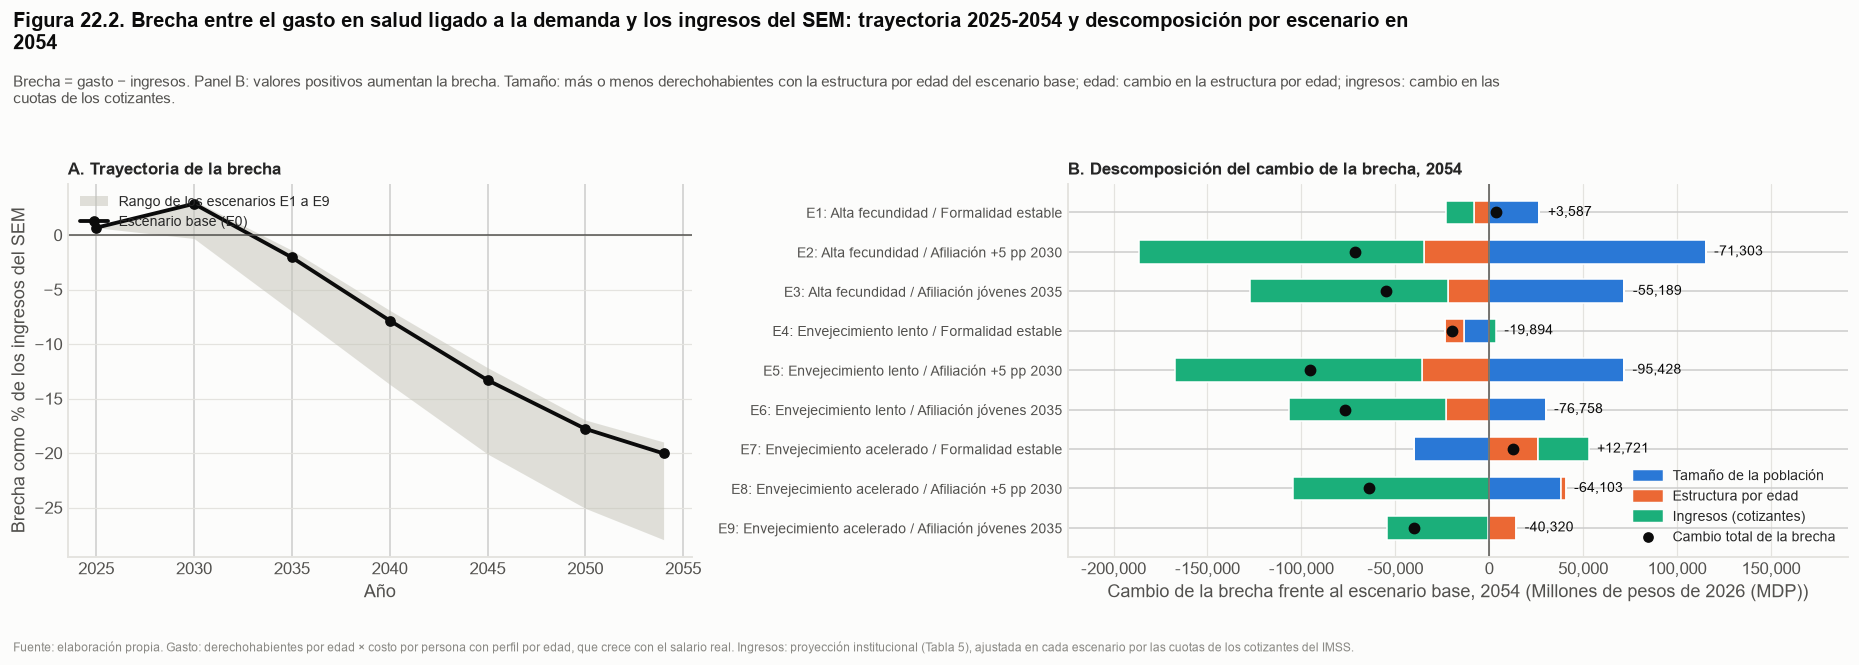

Lectura: La brecha del escenario base pasa de +0.7 % de los ingresos del SEM en 2025 a -20.0 % en 2054. En 2054, el
         escenario que más aumenta la brecha frente a la base es E7: Envejecimiento acelerado / Formalidad estable
         (+12,721 MDP) y el que más la reduce, E5: Envejecimiento lento / Afiliación +5 pp 2030 (-95,428 MDP).


In [179]:
# ===== VIZ 22.4 | Pegar debajo de la celda 22.4 (brecha del SEM con gasto ligado a la demanda) =====
# ---------------- Figura 22.2 Brecha del SEM: trayectoria y descomposición por escenario ----------------
# Panel B: cambio de la brecha de 2054 frente a E0, separado en tres efectos que suman el cambio total:
#   tamaño     = gasto de E0 × (derechohabientes del escenario / derechohabientes de E0) − gasto de E0
#   edad       = gasto del escenario − gasto de E0 reescalado al tamaño del escenario (estructura por edad)
#   ingresos   = −(ingreso del escenario − ingreso de E0)  (más ingresos reducen la brecha)
anio_cascada = max(ANIOS_21)
b = balance_21.loc[(balance_21["subsistema"] == "IMSS") & (balance_21["anio"] == anio_cascada)].set_index("escenario")
base_e0 = b.loc["E0"]
cascada = pd.DataFrame(index=[e for e in b.index if e != "E0"])
gasto_reescalado = base_e0["gasto (MDP de 2026)"] * b["derechohabientes (millones)"] / base_e0["derechohabientes (millones)"]
cascada["Tamaño de la población"] = (gasto_reescalado - base_e0["gasto (MDP de 2026)"]).reindex(cascada.index)
cascada["Estructura por edad"] = (b["gasto (MDP de 2026)"] - gasto_reescalado).reindex(cascada.index)
cascada["Ingresos (cotizantes)"] = -(b["ingreso (MDP de 2026)"] - base_e0["ingreso (MDP de 2026)"]).reindex(cascada.index)
cascada["Cambio total de la brecha"] = (b["brecha gasto - ingreso (MDP de 2026)"] - base_e0["brecha gasto - ingreso (MDP de 2026)"]).reindex(cascada.index)
assert (cascada[["Tamaño de la población", "Estructura por edad", "Ingresos (cotizantes)"]].sum(axis=1)
        - cascada["Cambio total de la brecha"]).abs().max() < 1e-6, "La descomposición no suma el cambio total"

COLOR_EFECTO = {"Tamaño de la población": PAL["azul"], "Estructura por edad": PAL["naranja"], "Ingresos (cotizantes)": PAL["aqua"]}
etiquetas_esc = grid_escenarios.set_index("escenario")["etiqueta"] if "etiqueta" in grid_escenarios.columns else pd.Series(dtype=str)
fig, ejes = plt.subplots(1, 2, figsize=(17, 6), gridspec_kw={"width_ratios": [1, 1.25]})
eje = ejes[0]
eje.fill_between(brecha_imss_pct.index, brecha_imss_pct.min(axis=1), brecha_imss_pct.max(axis=1), color=NEUTRO, alpha=0.5,
                 linewidth=0, label="Rango de los escenarios E1 a E9")
eje.plot(brecha_imss_pct.index, brecha_imss_pct["E0"], color=TINTA, linewidth=2.5, marker="o", markersize=6, label="Escenario base (E0)")
eje.axhline(0, color=TINTA_2, linewidth=1)
eje.set_ylabel("Brecha como % de los ingresos del SEM")
eje.set_xlabel("Año")
eje.set_title("A. Trayectoria de la brecha")
ejes_limpios(eje)
eje.legend(loc="upper left", fontsize=9)

eje = ejes[1]
y = np.arange(len(cascada))
derecha, izquierda = np.zeros(len(cascada)), np.zeros(len(cascada))
for efecto, color in COLOR_EFECTO.items():
    valores = cascada[efecto].values
    pos, neg = np.where(valores > 0, valores, 0), np.where(valores < 0, valores, 0)
    eje.barh(y, pos, left=derecha, color=color, height=0.6, label=efecto)
    eje.barh(y, neg, left=izquierda, color=color, height=0.6)
    derecha, izquierda = derecha + pos, izquierda + neg
eje.scatter(cascada["Cambio total de la brecha"], y, color=TINTA, s=45, zorder=3, label="Cambio total de la brecha")
for i, v in enumerate(cascada["Cambio total de la brecha"]):
    eje.text(max(derecha[i], 0) + abs(cascada.values).max() * 0.03, i, f"{v:+,.0f}", va="center", fontsize=9, color=TINTA)
eje.axvline(0, color=TINTA_2, linewidth=1)
eje.set_yticks(y, [etiquetas_esc.get(e, e) for e in cascada.index], fontsize=9)
eje.invert_yaxis()
eje.set_xlabel(f"Cambio de la brecha frente al escenario base, {anio_cascada} ({EJE_MDP})")
eje.set_title(f"B. Descomposición del cambio de la brecha, {anio_cascada}")
margen = abs(cascada.values).max() * 0.25
eje.set_xlim(min(izquierda.min(), 0) - margen, max(derecha.max(), 0) + margen * 2)
ejes_limpios(eje, "x"); miles(eje, "x")
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
eje.legend(handles=[Patch(color=c, label=e) for e, c in COLOR_EFECTO.items()] +
           [Line2D([], [], marker="o", color=TINTA, linestyle="", label="Cambio total de la brecha")], loc="lower right", fontsize=9)
tope = titulo(fig, f"Figura 22.2. Brecha entre el gasto en salud ligado a la demanda y los ingresos del SEM: trayectoria "
                   f"{brecha_imss_pct.index[0]}-{brecha_imss_pct.index[-1]} y descomposición por escenario en {anio_cascada}",
              "Brecha = gasto − ingresos. Panel B: valores positivos aumentan la brecha. Tamaño: más o menos derechohabientes con la "
              "estructura por edad del escenario base; edad: cambio en la estructura por edad; ingresos: cambio en las cuotas de los cotizantes.")
fuente(fig, "Fuente: elaboración propia. Gasto: derechohabientes por edad × costo por persona con perfil por edad, que crece con el salario "
            "real. Ingresos: proyección institucional (Tabla 5), ajustada en cada escenario por las cuotas de los cotizantes del IMSS.")
plt.tight_layout(rect=[0, 0.06, 1, tope])
guardar_grafica("22_2_brecha_trayectoria_y_descomposicion")
plt.show()
e0 = brecha_imss_pct["E0"]
mayor_aumento = cascada["Cambio total de la brecha"].idxmax()
mayor_reduccion = cascada["Cambio total de la brecha"].idxmin()
lectura(f"La brecha del escenario base pasa de {e0.iloc[0]:+.1f} % de los ingresos del SEM en {e0.index[0]} a {e0.iloc[-1]:+.1f} % en "
        f"{e0.index[-1]}. En {anio_cascada}, el escenario que más aumenta la brecha frente a la base es {etiquetas_esc.get(mayor_aumento, mayor_aumento)} "
        f"({cascada.loc[mayor_aumento, 'Cambio total de la brecha']:+,.0f} MDP) y el que más la reduce, "
        f"{etiquetas_esc.get(mayor_reduccion, mayor_reduccion)} ({cascada.loc[mayor_reduccion, 'Cambio total de la brecha']:+,.0f} MDP).")

## 22.5 Sección 10a en cada escenario

In [180]:
# ---------------- 22.5 Sección 10a en cada escenario de población ----------------
# simular_10a (20.2) toma los pesos de pesos_conapo; aquí se sustituye por los pesos de cada escenario.
ANIO_10A_ESC = 2030
pesos_conapo_19 = pesos_conapo
filas = []
for escenario in ESCENARIOS_21:
    pesos_conapo = lambda anio, e=escenario: pesos_escenario(anio, e)
    r = simular_10a(ANIO_10A_ESC)
    r["escenario"] = escenario
    filas.append(r)
pesos_conapo = pesos_conapo_19          # se regresa la función original
columnas_10a = ["personas cubiertas (millones)", "costo de atención", "pago cobrado de los hogares",
                "aportación fija del GF", "subsidio del GF", "saldo sin fuente asignada"]
resultados_10a_esc = pd.DataFrame(filas).set_index("escenario")[columnas_10a]
resultados_10a_esc["saldo como % de los ingresos del SEM"] = (resultados_10a_esc["saldo sin fuente asignada"]
                                                              / finanzas.loc[ANIO_10A_ESC, "ingresos_SEM"] * 100)
print(f"Sección 10a por escenario, {ANIO_10A_ESC} (MDP de 2026). Con más afiliación IMSS hay menos hogares elegibles:")
display(resultados_10a_esc.round(1))

Sección 10a por escenario, 2030 (MDP de 2026). Con más afiliación IMSS hay menos hogares elegibles:


,personas cubiertas (millones),costo de atención,pago cobrado de los hogares,aportación fija del GF,subsidio del GF,saldo sin fuente asignada,saldo como % de los ingresos del SEM
escenario,,,,,,,
E0,35.9,406135.7,37576.6,75071.3,5228.2,288259.6,47.2
E1,36.1,407796.1,37703.6,75327.3,5246.4,289518.7,47.4
E2,33.4,381362.8,36258.5,72089.9,4989.1,268025.3,43.9
E3,35.3,400507.3,37291.2,74477.4,5183.8,283555.0,46.4
E4,35.9,405375.9,37540.6,74972.5,5220.1,287642.6,47.1
E5,33.2,379067.9,36100.9,71748.0,4963.8,266255.2,43.6
E6,35.1,398087.1,37128.2,74122.5,5157.5,281678.8,46.1
E7,35.6,403574.9,37358.8,74657.9,5200.0,286358.4,46.9
E8,33.0,377517.6,35929.9,71459.0,4945.8,265182.9,43.4


Gráfica guardada: graficas/reporte\22_3_flujos_afiliacion_subsidiada_por_escenario.png


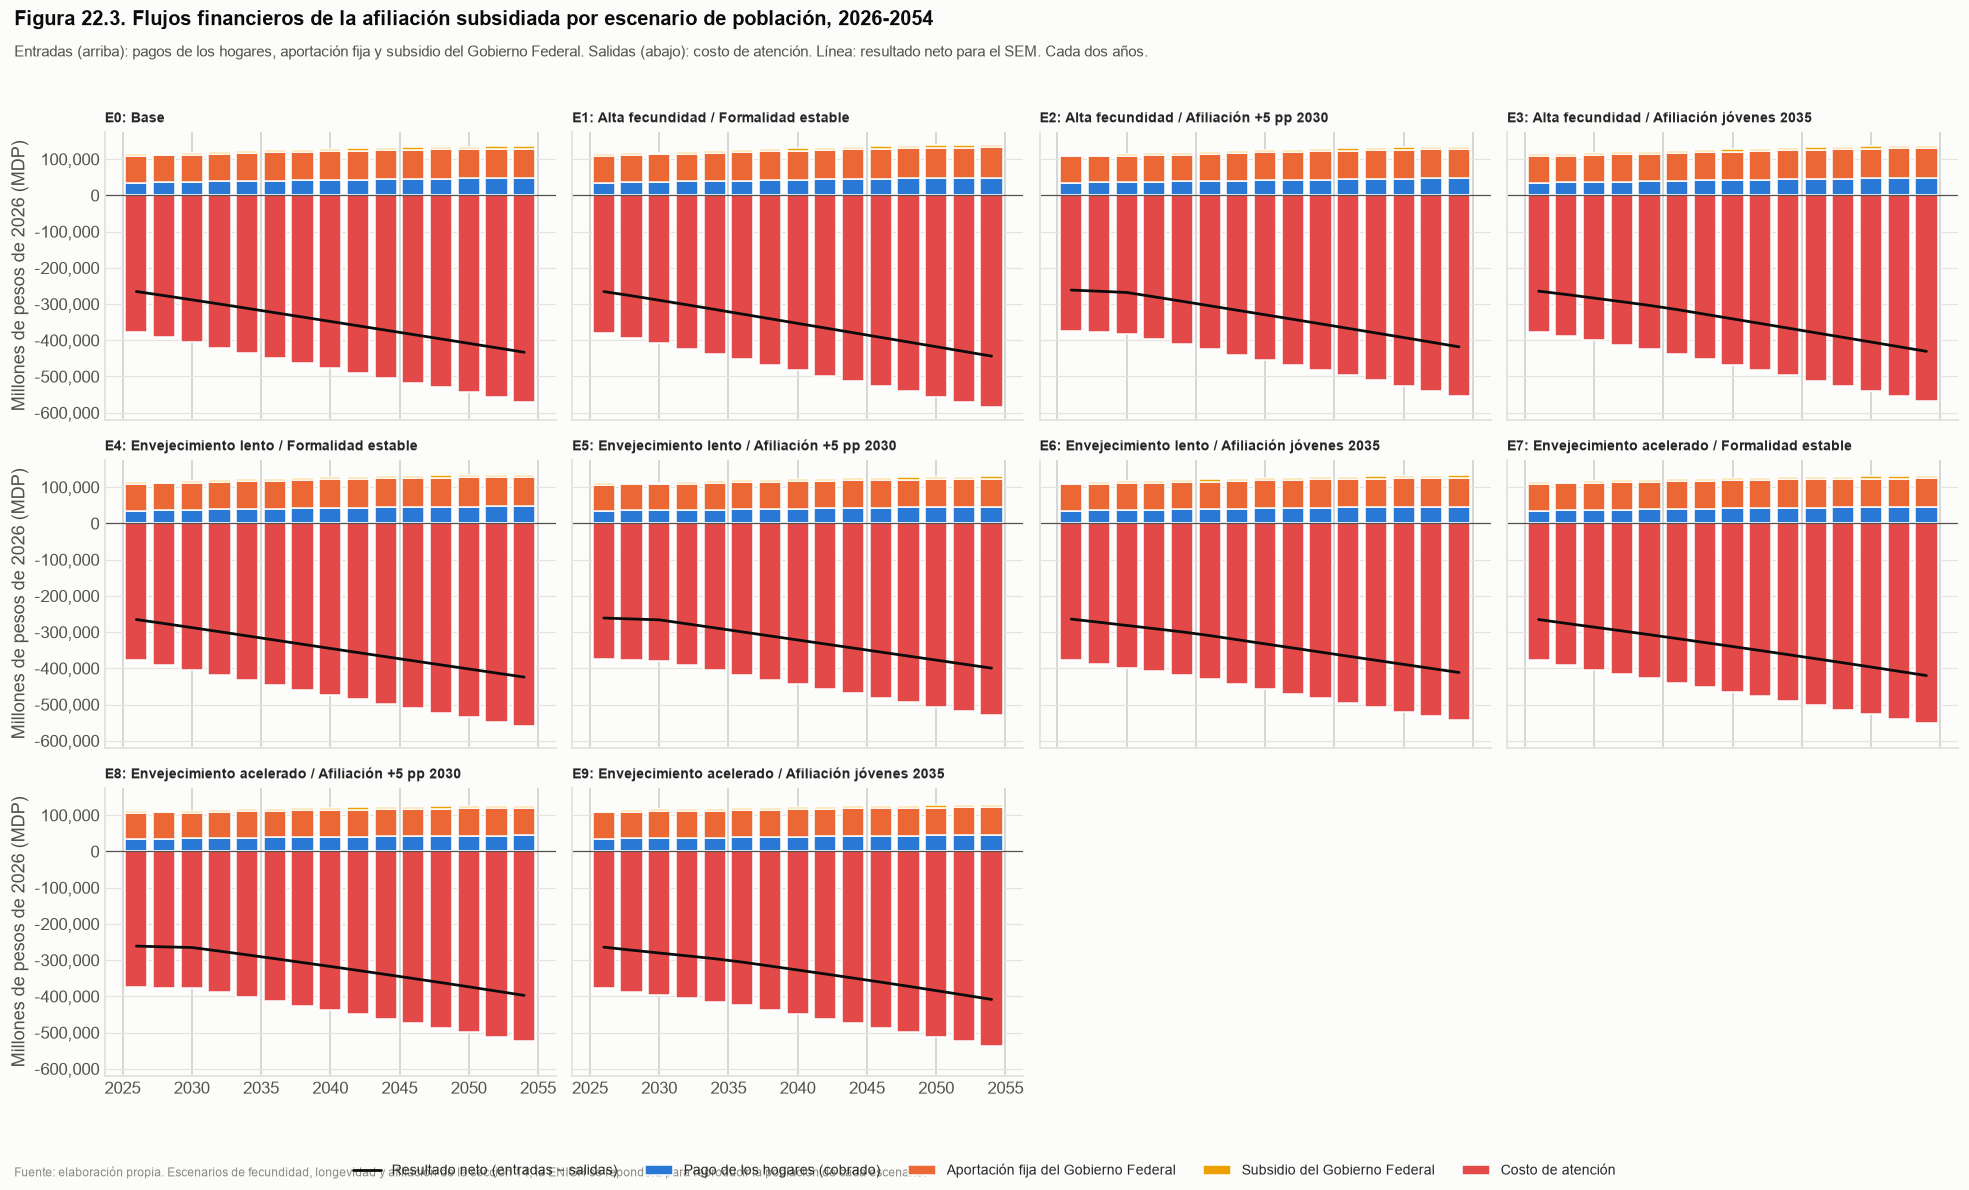

Lectura: En 2030 el resultado neto de la afiliación subsidiada va de -289,519 a -265,183 MDP según el escenario (base:
         -288,260 MDP). Los escenarios de mayor afiliación dejan menos hogares sin IMSS que puedan entrar al esquema.


In [181]:
# ===== VIZ 22.5 | Pegar debajo de la celda 22.5 (sección 10a en cada escenario) =====
# ---------------- Figura 22.3 Flujos financieros de la afiliación subsidiada por escenario de población ----------------
# Se corre simular_10a cada dos años en cada escenario (tarda un par de minutos).
ANIOS_FLUJOS_ESC = list(range(ANIO_INICIO_10A, 2055, 2))
pesos_conapo_original = pesos_conapo
flujos_10a_esc = {}
for escenario in ESCENARIOS_21:
    pesos_conapo = lambda anio, e=escenario: pesos_escenario(anio, e)
    flujos_10a_esc[escenario] = pd.DataFrame({anio: simular_10a(anio) for anio in ANIOS_FLUJOS_ESC}).T
pesos_conapo = pesos_conapo_original          # se regresa la función original

n_esc = len(flujos_10a_esc)
columnas_graf = 4
filas_graf = int(np.ceil(n_esc / columnas_graf))
fig, ejes = plt.subplots(filas_graf, columnas_graf, figsize=(18, 3.6 * filas_graf), sharex=True, sharey=True)
ejes = np.array(ejes).reshape(-1)
for i, (escenario, f) in enumerate(flujos_10a_esc.items()):
    neto = f[list(ENTRADAS_10A)].sum(axis=1) - f["costo de atención"]
    panel_flujos(ejes[i], f, ENTRADAS_10A, SALIDAS_10A, neto, ancho=1.6)
    ejes[i].set_title(etiquetas_esc.get(escenario, escenario), fontsize=9)
for j in range(n_esc, len(ejes)):
    ejes[j].axis("off")
for k in range(0, len(ejes), columnas_graf):
    ejes[k].set_ylabel(EJE_MDP)
fig.legend(*ejes[0].get_legend_handles_labels(), loc="lower center", ncol=5, fontsize=9)
tope = titulo(fig, f"Figura 22.3. Flujos financieros de la afiliación subsidiada por escenario de población, "
                   f"{ANIOS_FLUJOS_ESC[0]}-{ANIOS_FLUJOS_ESC[-1]}",
              "Entradas (arriba): pagos de los hogares, aportación fija y subsidio del Gobierno Federal. Salidas (abajo): costo de atención. "
              "Línea: resultado neto para el SEM. Cada dos años.")
fuente(fig, "Fuente: elaboración propia. Escenarios de fecundidad, longevidad y afiliación de la sección 14; la ENIGH se repondera para "
            "reproducir la población de cada escenario.")
plt.tight_layout(rect=[0, 0.06, 1, tope])
guardar_grafica("22_3_flujos_afiliacion_subsidiada_por_escenario")
plt.show()
neto_2030 = pd.Series({e: (f[list(ENTRADAS_10A)].sum(axis=1) - f["costo de atención"]).loc[2030] for e, f in flujos_10a_esc.items()})
lectura(f"En 2030 el resultado neto de la afiliación subsidiada va de {neto_2030.min():+,.0f} a {neto_2030.max():+,.0f} MDP según el "
        f"escenario (base: {neto_2030.loc['E0']:+,.0f} MDP). Los escenarios de mayor afiliación dejan menos hogares sin IMSS que "
        "puedan entrar al esquema.")

## 22.6 Sección 10b en cada escenario

In [182]:
# ---------------- 22.6 Sección 10b en cada escenario de población ----------------
# La masa salarial de cada escenario mueve la de la proyección del IMSS con la razón de cotizantes IMSS × salario
# de la ENIGH reponderada frente a E0 (misma idea que AJUSTAR_INGRESOS_POR_ESCENARIO de 16.0, con cotizantes).
if True:          # masa salarial (20.0) y déficit de GMP (21.0) ya vienen del cuaderno
    anios_10b = list(range(ANIO_INICIO_10B, ANIO_FIN_10B + 1))
    es_imss = (personas["subsistema"] == "IMSS").values
    salario_cotizante = personas["cotizante"].values * ingreso_anual_2026
    masa_por_escenario = pd.DataFrame(index=anios_10b)
    for escenario in ESCENARIOS_21:
        razon = [(pesos_escenario(a, escenario) * es_imss * salario_cotizante).sum()
                 / (pesos_escenario(a, "E0") * es_imss * salario_cotizante).sum() for a in anios_10b]
        masa_por_escenario[escenario] = (masa_esc_base.loc[anios_10b, "Formalización de la proyección del IMSS"]
                                         * np.array(razon))

    masa_esc_original = masa_esc
    masa_esc = masa_por_escenario.copy()
    masa_esc["Formalización de la proyección del IMSS"] = masa_por_escenario["E0"]   # referencia del déficit de GMP
    tabla_10b_esc = pd.DataFrame(index=ESCENARIOS_21)
    for etiqueta, con_reserva in [("Con reserva", True), ("Sin reserva", False)]:
        for escenario in ESCENARIOS_21:
            r = simular_10b(escenario, con_reserva)
            faltan = r.index[r["faltante_sin_pagar"] > 1e-6]
            tabla_10b_esc.loc[escenario, etiqueta] = ANIO_FIN_10B if len(faltan) == 0 else faltan[0] - 1
        tabla_10b_esc[f"cuidados 2040 ({etiqueta.lower()}, MDP)"] = [simular_10b(e, con_reserva).loc[2040, "cuidados"]
                                                                     for e in ESCENARIOS_21]
    masa_esc = masa_esc_original          # se regresa la masa de la sección 20
    print("Sección 10b por escenario: último año en que se paga completo el déficit de GMP (2054 = todo el periodo; 2026 = no alcanza desde 2027)")
    display(tabla_10b_esc.round(0))

Sección 10b por escenario: último año en que se paga completo el déficit de GMP (2054 = todo el periodo; 2026 = no alcanza desde 2027)


,Con reserva,"cuidados 2040 (con reserva, MDP)",Sin reserva,"cuidados 2040 (sin reserva, MDP)"
E0,2054.0,16291.0,2054.0,5478.0
E1,2054.0,16374.0,2054.0,5562.0
E2,2054.0,65073.0,2054.0,41012.0
E3,2054.0,47928.0,2054.0,30591.0
E4,2054.0,15876.0,2054.0,5116.0
E5,2054.0,64565.0,2054.0,40556.0
E6,2054.0,47430.0,2054.0,30145.0
E7,2053.0,16538.0,2053.0,5674.0
E8,2054.0,65206.0,2054.0,41093.0
E9,2054.0,48092.0,2054.0,30703.0


# 23. Resumen para decisión

Los esquemas de las secciones 19 a 21 lado a lado, con los mismos supuestos de población, costo por persona e ingresos. El saldo positivo es lo que el SEM necesitaría de una fuente adicional.

**Insumos clave**

* **Ingreso:** los de cada esquema (secciones 19, 20 y 21). Denominadores comunes: proyección institucional de ingresos del IMSS por seguro y concepto, 2024-2055 (documento interno del área de Finanzas; base `db_nucleo_13.hec_ingreso_imss`), procesada en el cuaderno de ingresos; ingresos del SEM = SEM-A + SEM-GMP (cuotas obrero-patronales, aportación del Gobierno Federal y otros ingresos), `finanzas["ingresos_SEM"]` (Tabla 5 del documento), MDP de 2026; y masa salarial de 20.0.
* **Gasto:** costo de atención por persona de la sección 19, el mismo en todos los esquemas.
* **Población:** CONAPO × ENIGH 2024 (13.4), escenario base (E0).

In [183]:
# ---------------- 23.1 Resumen para decisión: los esquemas lado a lado ----------------
# Mismos supuestos de población, costo e ingresos en todos. Saldo positivo = el SEM necesita una fuente adicional.
ANIOS_RESUMEN = [2030, 2054]


def fila_resumen(nombre, quien_paga, anio, personas_mill, ingreso, costo):
    saldo = costo - ingreso
    return {"esquema": nombre, "año": anio, "quién paga": quien_paga, "personas nuevas cubiertas (millones)": personas_mill,
            "ingreso nuevo para el SEM (MDP)": ingreso, "costo nuevo de atención (MDP)": costo, "saldo (MDP)": saldo,
            "saldo % ingresos del SEM": saldo / finanzas.loc[anio, "ingresos_SEM"] * 100,
            "saldo en puntos del salario": saldo / masa_salarial.loc[anio] * 100}


filas = []
for anio in ANIOS_RESUMEN:
    for esquema, experimento, nombre in [("Cuota por edad (SSFAM)", "Jóvenes de 18 a 34", "SSFAM: solo jóvenes 18-34"),
                                         ("Cuota por edad (SSFAM)", "Mayores de 60 y más", "SSFAM: solo mayores 60+"),
                                         ("Cuota por edad (SSFAM)", "Toda la población sin IMSS", "SSFAM: toda la población sin IMSS"),
                                         ("Cuota única", "Toda la población sin IMSS", "Cuota única: toda la población sin IMSS")]:
        r = resultados_19[(esquema, experimento)].loc[anio]
        filas.append(fila_resumen(nombre, "Cada afiliado", anio, r["afiliados (millones)"],
                                  r["cuotas cobradas"] + r["aportación del GF"], r["costo de atención"]))
    r10a = simular_10a(anio)
    filas.append(fila_resumen("10a: afiliación subsidiada de hogares", "Hogares y Gobierno Federal", anio,
                              r10a["personas cubiertas (millones)"],
                              r10a["pago cobrado de los hogares"] + r10a["aportación fija del GF"] + r10a["subsidio del GF"],
                              r10a["costo de atención"]))
    r10b = simular_10b("Formalización de la proyección del IMSS").loc[anio]
    filas.append(fila_resumen("10b: 2 % de la nómina para GMP", "Patrones (sustituye 2 de 5 puntos de Infonavit)", anio,
                              0.0, r10b["ingreso"], r10b["deficit_GMP"]))
resumen_decision = pd.DataFrame(filas).set_index(["esquema", "año"])
print("Resumen para decisión (MDP de 2026):")
display(resumen_decision.round(1))

Resumen para decisión (MDP de 2026):


,,quién paga,personas nuevas cubiertas (millones),ingreso nuevo para el SEM (MDP),costo nuevo de atención (MDP),saldo (MDP),saldo % ingresos del SEM,saldo en puntos del salario
esquema,año,,,,,,,
SSFAM: solo jóvenes 18-34,2030,Cada afiliado,10.7,92336.0,105834.6,13498.6,2.2,0.2
SSFAM: solo mayores 60+,2030,Cada afiliado,5.6,88672.2,132336.6,43664.4,7.1,0.7
SSFAM: toda la población sin IMSS,2030,Cada afiliado,40.6,395938.3,478359.0,82420.7,13.5,1.3
Cuota única: toda la población sin IMSS,2030,Cada afiliado,40.6,478359.0,478359.0,0.0,0.0,0.0
10a: afiliación subsidiada de hogares,2030,Hogares y Gobierno Federal,35.9,117876.1,406135.7,288259.6,47.2,4.6
10b: 2 % de la nómina para GMP,2030,Patrones (sustituye 2 de 5 puntos de Infonavit),0.0,125117.0,107038.5,-18078.5,-3.0,-0.3
SSFAM: solo jóvenes 18-34,2054,Cada afiliado,8.9,77095.6,107786.0,30690.4,2.5,0.2
SSFAM: solo mayores 60+,2054,Cada afiliado,10.6,168443.8,321865.0,153421.3,12.7,1.1
SSFAM: toda la población sin IMSS,2054,Cada afiliado,42.7,460856.2,711117.1,250260.9,20.7,1.8


Gráfica guardada: graficas/reporte\23_1_resumen_esquemas.png


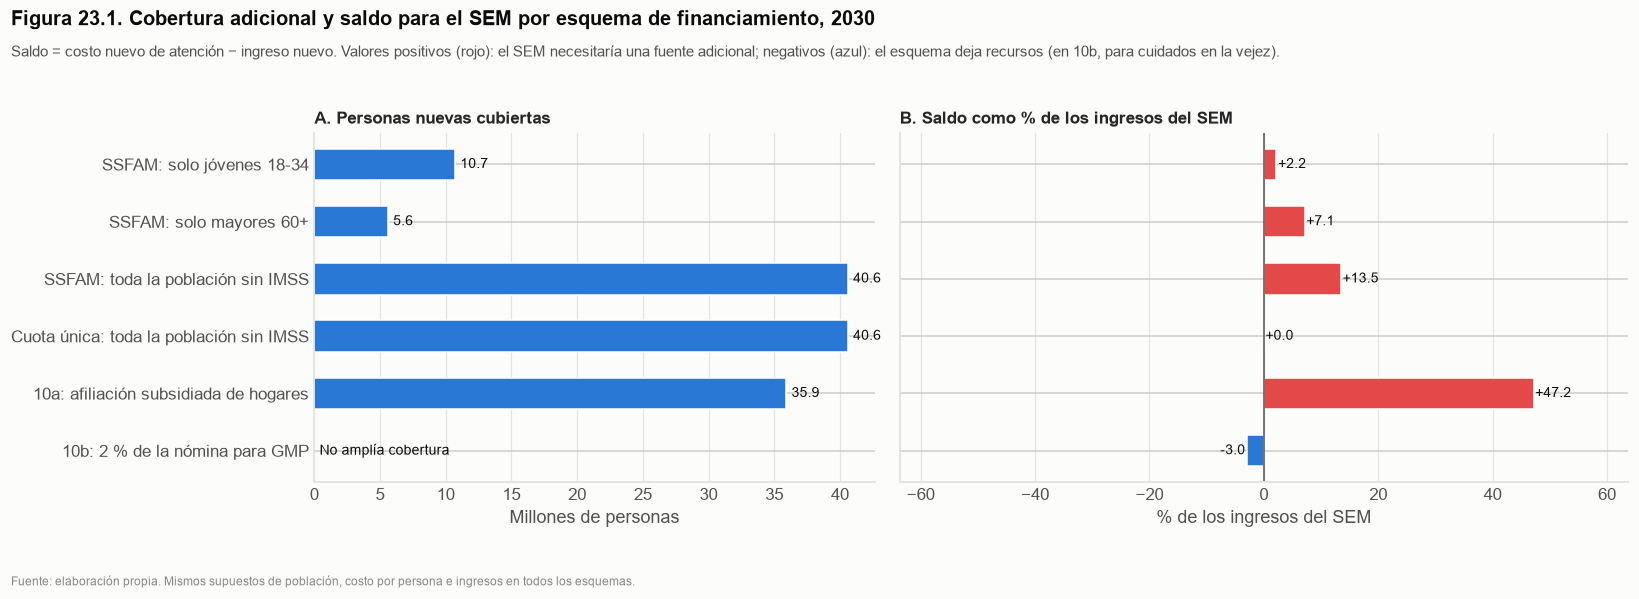

Lectura: En 2030, el esquema que más cobertura agrega es «SSFAM: toda la población sin IMSS» (40.6 millones de
         personas), con un saldo de +13.5 % de los ingresos del SEM.


In [184]:
# ===== VIZ 23.1 | Pegar debajo de la celda 23.1 (resumen para decisión) =====
# ---------------- Figura 23.1 Cobertura adicional y saldo por esquema ----------------
anio_r = ANIOS_RESUMEN[0]
r = resumen_decision.xs(anio_r, level="año")
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1, 1.3]})
y = np.arange(len(r))
ejes[0].barh(y, r["personas nuevas cubiertas (millones)"], color=PAL["azul"], height=0.55)
for i, v in enumerate(r["personas nuevas cubiertas (millones)"]):
    ejes[0].text(v + 0.4, i, f"{v:,.1f}" if v > 0 else "No amplía cobertura", va="center", color=TINTA, fontsize=9)
ejes[0].set_title("A. Personas nuevas cubiertas")
ejes[0].set_xlabel("Millones de personas")
saldo = r["saldo % ingresos del SEM"]
ejes[1].barh(y, saldo, color=[FALTANTE if v > 0 else A_FAVOR for v in saldo], height=0.55)
for i, v in enumerate(saldo):
    ejes[1].text(v + (0.3 if v >= 0 else -0.3), i, f"{v:+.1f}", va="center", ha="left" if v >= 0 else "right", color=TINTA, fontsize=9)
ejes[1].axvline(0, color=TINTA_2, linewidth=1)
ejes[1].set_title("B. Saldo como % de los ingresos del SEM")
ejes[1].set_xlabel("% de los ingresos del SEM")
lim = abs(saldo).max() * 1.35
ejes[1].set_xlim(-lim, lim)
for eje in ejes:
    eje.set_yticks(y, r.index)
    eje.invert_yaxis()
    ejes_limpios(eje, "x")
ejes[1].set_yticklabels([])
tope = titulo(fig, f"Figura 23.1. Cobertura adicional y saldo para el SEM por esquema de financiamiento, {anio_r}",
              "Saldo = costo nuevo de atención − ingreso nuevo. Valores positivos (rojo): el SEM necesitaría una fuente adicional; "
              "negativos (azul): el esquema deja recursos (en 10b, para cuidados en la vejez).")
fuente(fig, "Fuente: elaboración propia. Mismos supuestos de población, costo por persona e ingresos en todos los esquemas.")
plt.tight_layout(rect=[0, 0.08, 1, tope])
guardar_grafica("23_1_resumen_esquemas")
plt.show()
mayor = r["personas nuevas cubiertas (millones)"].idxmax()
lectura(f"En {anio_r}, el esquema que más cobertura agrega es «{mayor}» ({r.loc[mayor, 'personas nuevas cubiertas (millones)']:,.1f} "
        f"millones de personas), con un saldo de {r.loc[mayor, 'saldo % ingresos del SEM']:+.1f} % de los ingresos del SEM.")